
**Topic:** *Evaluating AI-Based Streamflow Forecasts for Improving Electricity Supply Reliability During Droughts in Ecuador*.


## 1. Libraries and configuration

In [3]:
# 1. LIBRARIES AND CONFIGURATION

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Project configuration
PROJECT_DIR = Path.cwd()

FILE_PATH = PROJECT_DIR / "Supplementary File S1.xlsx"
OUTPUT_DIR = PROJECT_DIR / "results_paute"

# Create the results directory
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Verify project configuration
print("Project directory:", PROJECT_DIR)
print("Dataset found:", FILE_PATH.is_file())
print("Results directory found:", OUTPUT_DIR.is_dir())

Project directory: c:\Users\DETPC\Downloads\proyecto
Dataset found: True
Results directory found: True


In [4]:


# Load the Excel file
excel_file = pd.ExcelFile(FILE_PATH)

# Display available worksheets
print("Available worksheets:")

for sheet in excel_file.sheet_names:
    print("-", sheet)

# Load the original monthly streamflow dataset
raw_data = pd.read_excel(
    FILE_PATH,
    sheet_name="Dataset_monthly",
    header=3
)

# Display dataset dimensions
print("\nDataset shape:", raw_data.shape)

print("Number of observations:", raw_data.shape[0])
print("Number of variables:", raw_data.shape[1])

# Display column names
print("\nAvailable columns:")
print(raw_data.columns.tolist())

# Display the first five observations
print("\nFirst five observations:")
display(raw_data.head())

# Display data types
print("\nData types:")
display(raw_data.dtypes)

Available worksheets:
- Dataset_monthly
- Quality_control
- Monthly_climatology
- Annual_summary
- Model_selection
- Parameter_diagnostics
- Residual_diagnostics
- Backtest_rolling
- PI_coverage
- Prob_verification
- Threshold_sensitivity
- Forecast_2026
- Forecast_2026_2030
- Forecast_highest_risk
- Dry_wet_years

Dataset shape: (504, 6)
Number of observations: 504
Number of variables: 6

Available columns:
['Date', 'Year', 'Month', 'Month_name', 'Streamflow_m3s', 'Source_worksheet']

First five observations:


,Date,Year,Month,Month_name,Streamflow_m3s,Source_worksheet
0,1984-01-31,1984,1,January,44.820742,Hydrology_CSR_1984
1,1984-02-29,1984,2,February,159.010103,Hydrology_CSR_1984
2,1984-03-31,1984,3,March,145.894129,Hydrology_CSR_1984
3,1984-04-30,1984,4,April,245.954133,Hydrology_CSR_1984
4,1984-05-31,1984,5,May,102.469677,Hydrology_CSR_1984



Data types:


Date                datetime64[us]
Year                         int64
Month                        int64
Month_name                     str
Streamflow_m3s             float64
Source_worksheet               str
dtype: object

In [5]:


# Validate dates and streamflow values
dates = pd.to_datetime(
    raw_data["Date"],
    errors="coerce"
)

flow = pd.to_numeric(
    raw_data["Streamflow_m3s"],
    errors="coerce"
)

# Convert dates to monthly periods
monthly_dates = dates.dt.to_period("M")
valid_months = monthly_dates.dropna()

# Generate the expected monthly timeline
expected_months = pd.period_range(
    start=valid_months.min(),
    end=valid_months.max(),
    freq="M"
)

# Identify missing months
missing_months = expected_months.difference(
    valid_months
)

# Create the data quality report
quality_report = pd.DataFrame({
    "Indicator": [
        "Total observations",
        "First observation",
        "Last observation",
        "Expected monthly observations",
        "Invalid dates",
        "Duplicate months",
        "Missing months",
        "Missing or invalid flow values",
        "Infinite flow values",
        "Negative flow values",
        "Zero flow values",
        "Year inconsistencies",
        "Month inconsistencies",
        "Chronological order"
    ],
    "Value": [
        len(raw_data),
        str(valid_months.min()),
        str(valid_months.max()),
        len(expected_months),
        dates.isna().sum(),
        valid_months.duplicated().sum(),
        len(missing_months),
        flow.isna().sum(),
        np.isinf(flow).sum(),
        (flow < 0).sum(),
        (flow == 0).sum(),
        (dates.dt.year != raw_data["Year"]).sum(),
        (dates.dt.month != raw_data["Month"]).sum(),
        dates.is_monotonic_increasing
    ]
})

# Display the quality report
display(quality_report)

# Save the quality report
quality_report.to_csv(
    OUTPUT_DIR / "data_quality_report.csv",
    index=False
)

print("\nData quality report saved successfully.")

,Indicator,Value
0,Total observations,504
1,First observation,1984-01
2,Last observation,2025-12
3,Expected monthly observations,504
4,Invalid dates,0
5,Duplicate months,0
6,Missing months,0
7,Missing or invalid flow values,0
8,Infinite flow values,0
9,Negative flow values,0



Data quality report saved successfully.


In [6]:


# Preserve the original dataset
data = raw_data.copy()

# Select the main variables
data = data[["Date", "Streamflow_m3s"]].copy()

# Rename columns
data = data.rename(columns={
    "Date": "date",
    "Streamflow_m3s": "streamflow"
})

# Ensure appropriate data types
data["date"] = pd.to_datetime(data["date"])
data["streamflow"] = pd.to_numeric(data["streamflow"])

# Sort observations chronologically
data = data.sort_values("date")

# Set the date as the time series index
data = data.set_index("date")

# Establish monthly end frequency
data = data.asfreq("ME")

# Verify that no observations were lost
assert len(data) == len(raw_data)
assert data["streamflow"].notna().all()
assert data.index.is_unique

# Display the prepared dataset
print("Prepared dataset shape:", data.shape)
print("Time series frequency:", data.index.freqstr)
print("Missing values:", data.isna().sum().sum())

print("\nFirst five observations:")
display(data.head())

print("\nLast five observations:")
display(data.tail())

# Save the prepared dataset
data.to_csv(
    OUTPUT_DIR / "prepared_streamflow_data.csv"
)

print("\nPrepared dataset saved successfully.")

Prepared dataset shape: (504, 1)
Time series frequency: ME
Missing values: 0

First five observations:


,streamflow
date,
1984-01-31,44.820742
1984-02-29,159.010103
1984-03-31,145.894129
1984-04-30,245.954133
1984-05-31,102.469677



Last five observations:


,streamflow
date,
2025-08-31,143.116160
2025-09-30,129.685423
2025-10-31,111.269088
2025-11-30,129.408558
2025-12-31,49.418986



Prepared dataset saved successfully.


In [7]:


# Define the training period
training_data = data.loc[:"2016-12-31"].copy()

# Select the streamflow series
streamflow = training_data["streamflow"]

# Calculate descriptive statistics
descriptive_stats = pd.DataFrame({
    "Statistic": [
        "Number of observations",
        "Mean",
        "Median",
        "Standard deviation",
        "Variance",
        "Minimum",
        "Maximum",
        "Range",
        "5th percentile",
        "10th percentile",
        "20th percentile",
        "25th percentile",
        "75th percentile",
        "90th percentile",
        "95th percentile",
        "Interquartile range",
        "Coefficient of variation (%)",
        "Skewness",
        "Excess kurtosis"
    ],
    "Value": [
        streamflow.count(),
        streamflow.mean(),
        streamflow.median(),
        streamflow.std(),
        streamflow.var(),
        streamflow.min(),
        streamflow.max(),
        streamflow.max() - streamflow.min(),
        streamflow.quantile(0.05),
        streamflow.quantile(0.10),
        streamflow.quantile(0.20),
        streamflow.quantile(0.25),
        streamflow.quantile(0.75),
        streamflow.quantile(0.90),
        streamflow.quantile(0.95),
        streamflow.quantile(0.75) - streamflow.quantile(0.25),
        (streamflow.std() / streamflow.mean()) * 100,
        streamflow.skew(),
        streamflow.kurt()
    ]
})

# Display the analysis period
print("Analysis period:")
print(training_data.index.min())
print(training_data.index.max())

# Display descriptive statistics
display(descriptive_stats.round(4))

# Save descriptive statistics
descriptive_stats.to_csv(
    OUTPUT_DIR / "descriptive_statistics.csv",
    index=False
)

print("\nDescriptive statistics saved successfully.")

Analysis period:
1984-01-31 00:00:00
2016-12-31 00:00:00


,Statistic,Value
0,Number of observations,396.0000
1,Mean,117.6637
2,Median,102.9728
3,Standard deviation,61.7488
4,Variance,3812.9200
5,Minimum,27.6006
6,Maximum,367.4304
7,Range,339.8299
8,5th percentile,43.6694
9,10th percentile,48.9584



Descriptive statistics saved successfully.


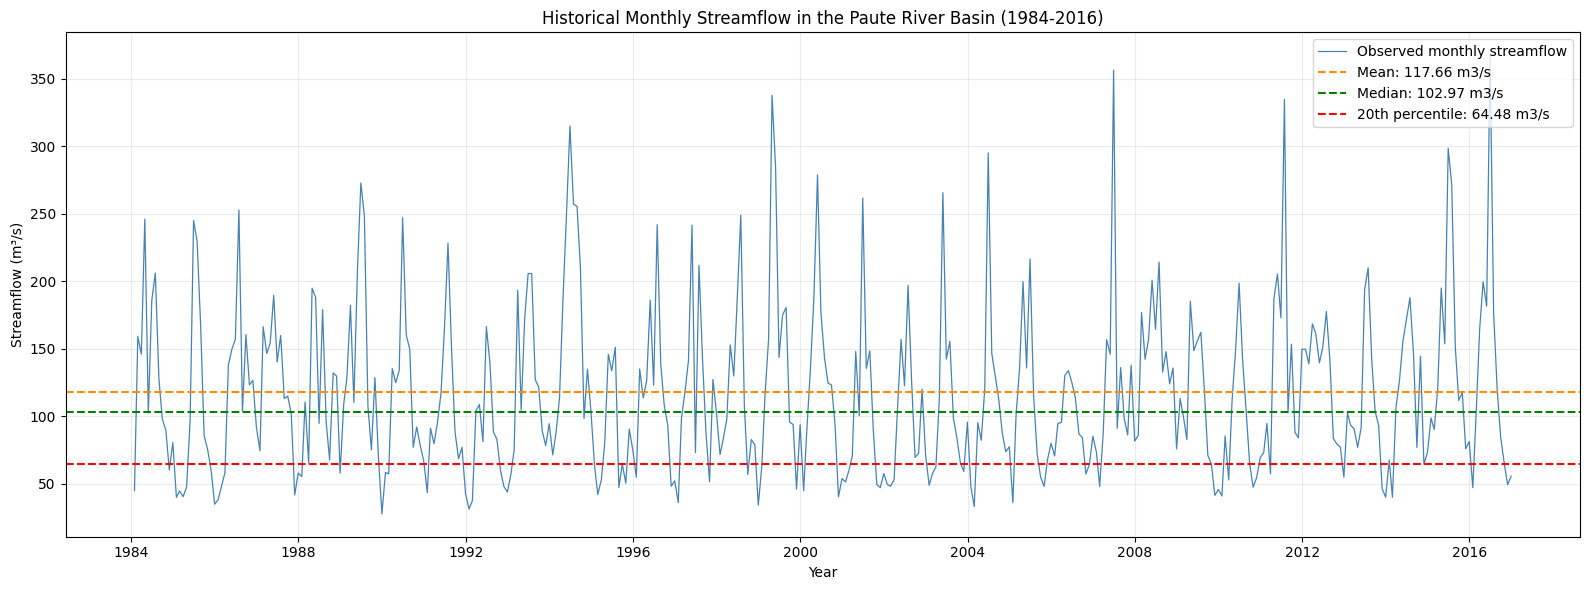

In [8]:


# Calculate the historical reference statistics
mean_flow = training_data["streamflow"].mean()
median_flow = training_data["streamflow"].median()
p20_flow = training_data["streamflow"].quantile(0.20)

# Create the historical streamflow figure
fig, ax = plt.subplots(figsize=(16, 6))

# Plot observed monthly streamflow
ax.plot(
    training_data.index,
    training_data["streamflow"],
    color="steelblue",
    linewidth=0.9,
    label="Observed monthly streamflow"
)

# Add reference lines
ax.axhline(
    mean_flow,
    color="darkorange",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean: {mean_flow:.2f} m3/s"
)

ax.axhline(
    median_flow,
    color="green",
    linestyle="--",
    linewidth=1.5,
    label=f"Median: {median_flow:.2f} m3/s"
)

ax.axhline(
    p20_flow,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"20th percentile: {p20_flow:.2f} m3/s"
)

# Configure the figure
ax.set_title(
    "Historical Monthly Streamflow in the Paute River Basin (1984-2016)"
)

ax.set_xlabel("Year")
ax.set_ylabel("Streamflow (m³/s)")

ax.legend(loc="upper right")
ax.grid(alpha=0.25)

plt.tight_layout()

# Save the figure
fig.savefig(
    OUTPUT_DIR / "historical_streamflow.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,count,mean,median,std,minimum,maximum,p20,cv_percent
month,,,,,,,,
Jan,33,63.9031,57.2157,26.4239,31.1634,149.5782,43.8955,41.3500
Feb,33,88.8050,91.0119,38.3697,32.9980,176.7987,47.9596,43.2067
Mar,33,106.7792,103.8692,41.6145,40.3536,193.1748,63.6067,38.9725
Apr,33,147.6142,141.0855,55.8493,47.3955,337.7904,106.9157,37.8346
May,33,164.8693,149.9874,53.8626,81.1377,284.0986,124.3446,32.6699
Jun,33,194.6233,172.8158,72.6452,72.9763,367.4304,140.9686,37.3261
Jul,33,189.9123,178.9038,52.9603,90.9025,334.8357,144.5448,27.8867
Aug,33,126.6256,126.9893,35.9611,47.0234,255.4046,102.8075,28.3996
Sep,33,97.1593,87.6301,33.0031,54.9714,209.0877,72.5134,33.9680


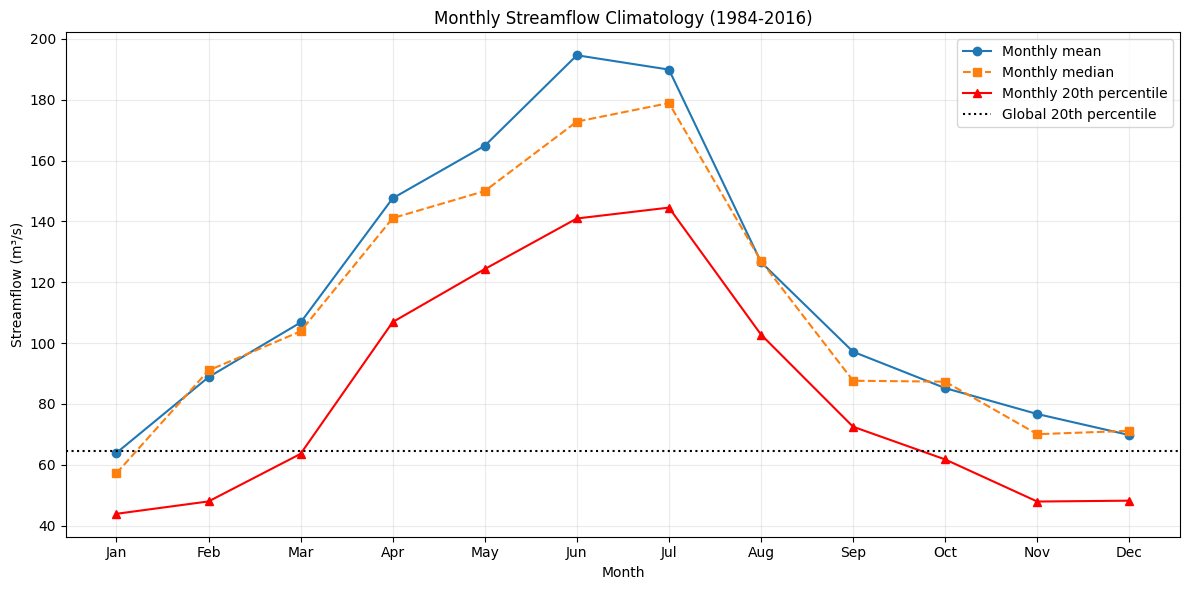

In [9]:

# Create a copy of the training dataset
seasonal_data = training_data.copy()

# Extract calendar months
seasonal_data["month"] = seasonal_data.index.month

# Calculate monthly descriptive statistics
monthly_stats = seasonal_data.groupby("month")["streamflow"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std",
    minimum="min",
    maximum="max",
    p20=lambda x: x.quantile(0.20)
)

# Calculate the monthly coefficient of variation
monthly_stats["cv_percent"] = (
    monthly_stats["std"] / monthly_stats["mean"]
) * 100

# Define month labels
month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

monthly_stats.index = month_names
monthly_stats.index.name = "month"

# Display monthly statistics
display(monthly_stats.round(4))

# Save monthly statistics
monthly_stats.to_csv(
    OUTPUT_DIR / "monthly_seasonality_statistics.csv"
)

# Create the seasonal climatology figure
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    month_names,
    monthly_stats["mean"],
    marker="o",
    label="Monthly mean"
)

ax.plot(
    month_names,
    monthly_stats["median"],
    marker="s",
    linestyle="--",
    label="Monthly median"
)

ax.plot(
    month_names,
    monthly_stats["p20"],
    marker="^",
    color="red",
    label="Monthly 20th percentile"
)

# Add the global low-flow reference
ax.axhline(
    training_data["streamflow"].quantile(0.20),
    color="black",
    linestyle=":",
    label="Global 20th percentile"
)

# Configure the figure
ax.set_title(
    "Monthly Streamflow Climatology (1984-2016)"
)

ax.set_xlabel("Month")
ax.set_ylabel("Streamflow (m³/s)")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

# Save the figure
fig.savefig(
    OUTPUT_DIR / "monthly_streamflow_climatology.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:


# Create a copy of the training dataset
annual_data = training_data.copy()

# Extract calendar information
annual_data["year"] = annual_data.index.year
annual_data["month"] = annual_data.index.month
annual_data["days_in_month"] = annual_data.index.days_in_month

# Calculate global and seasonal thresholds
global_threshold = training_data["streamflow"].quantile(0.20)

monthly_thresholds = (
    training_data["streamflow"]
    .groupby(training_data.index.month)
    .quantile(0.20)
)

# Assign the corresponding seasonal threshold
annual_data["seasonal_threshold"] = (
    annual_data["month"].map(monthly_thresholds)
)

# Identify low-flow months
annual_data["global_low_flow"] = (
    annual_data["streamflow"] <= global_threshold
)

annual_data["seasonal_low_flow"] = (
    annual_data["streamflow"] <=
    annual_data["seasonal_threshold"]
)

# Estimate monthly water volume
annual_data["water_volume_m3"] = (
    annual_data["streamflow"]
    * annual_data["days_in_month"]
    * 86400
)

# Calculate annual statistics
annual_stats = annual_data.groupby("year").agg(
    observations=("streamflow", "count"),
    total_days=("days_in_month", "sum"),
    minimum=("streamflow", "min"),
    maximum=("streamflow", "max"),
    std=("streamflow", "std"),
    total_volume_m3=("water_volume_m3", "sum"),
    global_low_flow_months=("global_low_flow", "sum"),
    seasonal_low_flow_months=("seasonal_low_flow", "sum")
)

# Calculate time-weighted annual mean streamflow
annual_stats["mean"] = (
    annual_stats["total_volume_m3"]
    / (annual_stats["total_days"] * 86400)
)

# Verify annual completeness
assert annual_stats["observations"].eq(12).all()

# Display annual statistics
print("Annual streamflow statistics:")
display(annual_stats.round(4))

# Identify the five lowest-flow years
print("\nFive lowest-flow years:")
display(
    annual_stats.nsmallest(5, "mean")[
        [
            "mean",
            "global_low_flow_months",
            "seasonal_low_flow_months"
        ]
    ].round(4)
)

# Identify the five highest-flow years
print("\nFive highest-flow years:")
display(
    annual_stats.nlargest(5, "mean")[
        [
            "mean",
            "global_low_flow_months",
            "seasonal_low_flow_months"
        ]
    ].round(4)
)

# Save annual statistics
annual_stats.to_csv(
    OUTPUT_DIR / "annual_streamflow_statistics.csv"
)

print("\nAnnual statistics saved successfully.")

Annual streamflow statistics:


,observations,total_days,minimum,maximum,std,total_volume_m3,global_low_flow_months,seasonal_low_flow_months,mean
year,,,,,,,,,
1984,12,366,44.8207,245.9541,61.3855,4.062105e+09,2,1,128.4566
1985,12,365,34.7275,244.9050,74.9734,3.072605e+09,6,6,97.4317
1986,12,365,38.2439,252.7798,59.3117,3.811509e+09,3,3,120.8622
1987,12,365,41.5537,189.5666,46.0131,3.827055e+09,2,2,121.3551
1988,12,366,55.1280,194.7832,51.0621,3.608236e+09,2,3,114.1038
1989,12,365,27.6006,272.7527,74.2391,4.382657e+09,1,1,138.9731
1990,12,365,57.2052,247.0146,55.3798,3.636503e+09,2,0,115.3127
1991,12,365,42.6942,228.1000,53.8317,3.275282e+09,2,4,103.8585
1992,12,366,31.1634,166.3294,41.9398,2.612131e+09,5,8,82.6038



Five lowest-flow years:


,mean,global_low_flow_months,seasonal_low_flow_months
year,,,
1992,82.6038,5,8
1995,83.1445,6,7
2010,93.1645,4,5
2006,94.9291,2,4
1985,97.4317,6,6



Five highest-flow years:


,mean,global_low_flow_months,seasonal_low_flow_months
year,,,
1994,173.7265,0,0
1999,149.0848,2,1
2015,147.3251,0,0
2008,146.1353,0,0
2011,142.1381,1,2



Annual statistics saved successfully.


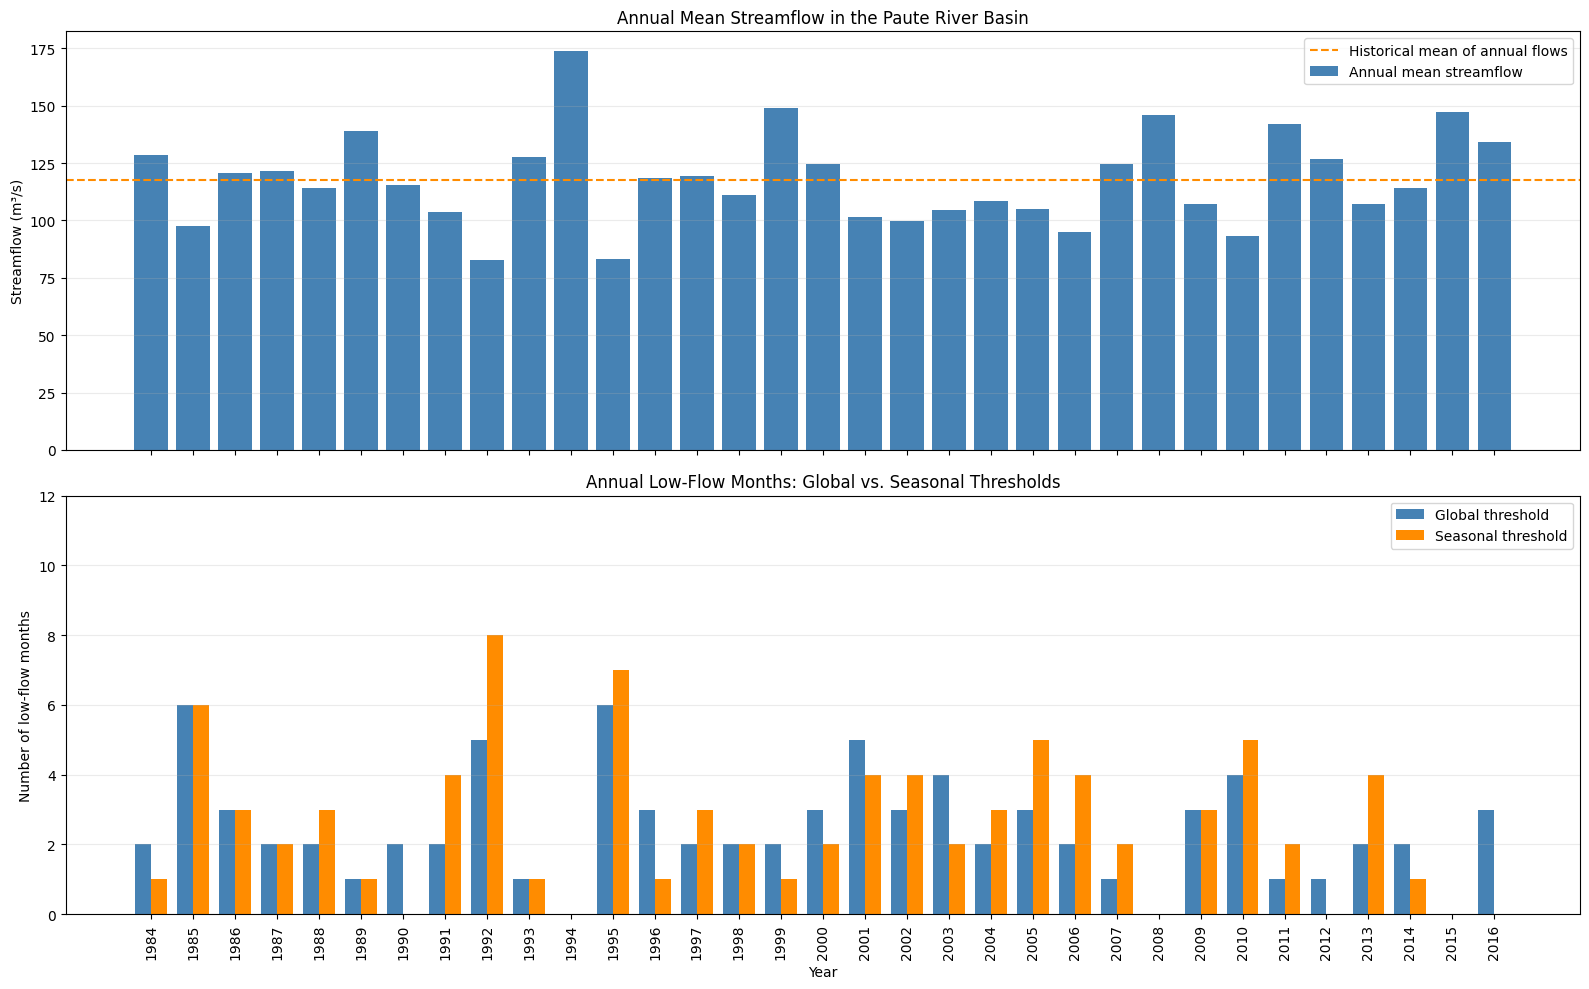

In [11]:

# Visualize annual mean streamflow and low-flow months

fig, axes = plt.subplots(
    2, 1,
    figsize=(16, 10),
    sharex=True
)

# Plot annual mean streamflow
axes[0].bar(
    annual_stats.index,
    annual_stats["mean"],
    color="steelblue",
    label="Annual mean streamflow"
)

axes[0].axhline(
    annual_stats["mean"].mean(),
    color="darkorange",
    linestyle="--",
    label="Historical mean of annual flows"
)

axes[0].set_title(
    "Annual Mean Streamflow in the Paute River Basin"
)

axes[0].set_ylabel("Streamflow (m³/s)")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)

# Compare global and seasonal low-flow methods
years = annual_stats.index.to_numpy()
bar_width = 0.38

axes[1].bar(
    years - bar_width / 2,
    annual_stats["global_low_flow_months"],
    width=bar_width,
    color="steelblue",
    label="Global threshold"
)

axes[1].bar(
    years + bar_width / 2,
    annual_stats["seasonal_low_flow_months"],
    width=bar_width,
    color="darkorange",
    label="Seasonal threshold"
)

axes[1].set_title(
    "Annual Low-Flow Months: Global vs. Seasonal Thresholds"
)

axes[1].set_xlabel("Year")
axes[1].set_ylabel("Number of low-flow months")

axes[1].set_ylim(0, 12)
axes[1].set_yticks(range(0, 13, 2))
axes[1].set_xticks(years)
axes[1].tick_params(axis="x", rotation=90)

axes[1].legend()
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()

# Save the figure
fig.savefig(
    OUTPUT_DIR / "annual_streamflow_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


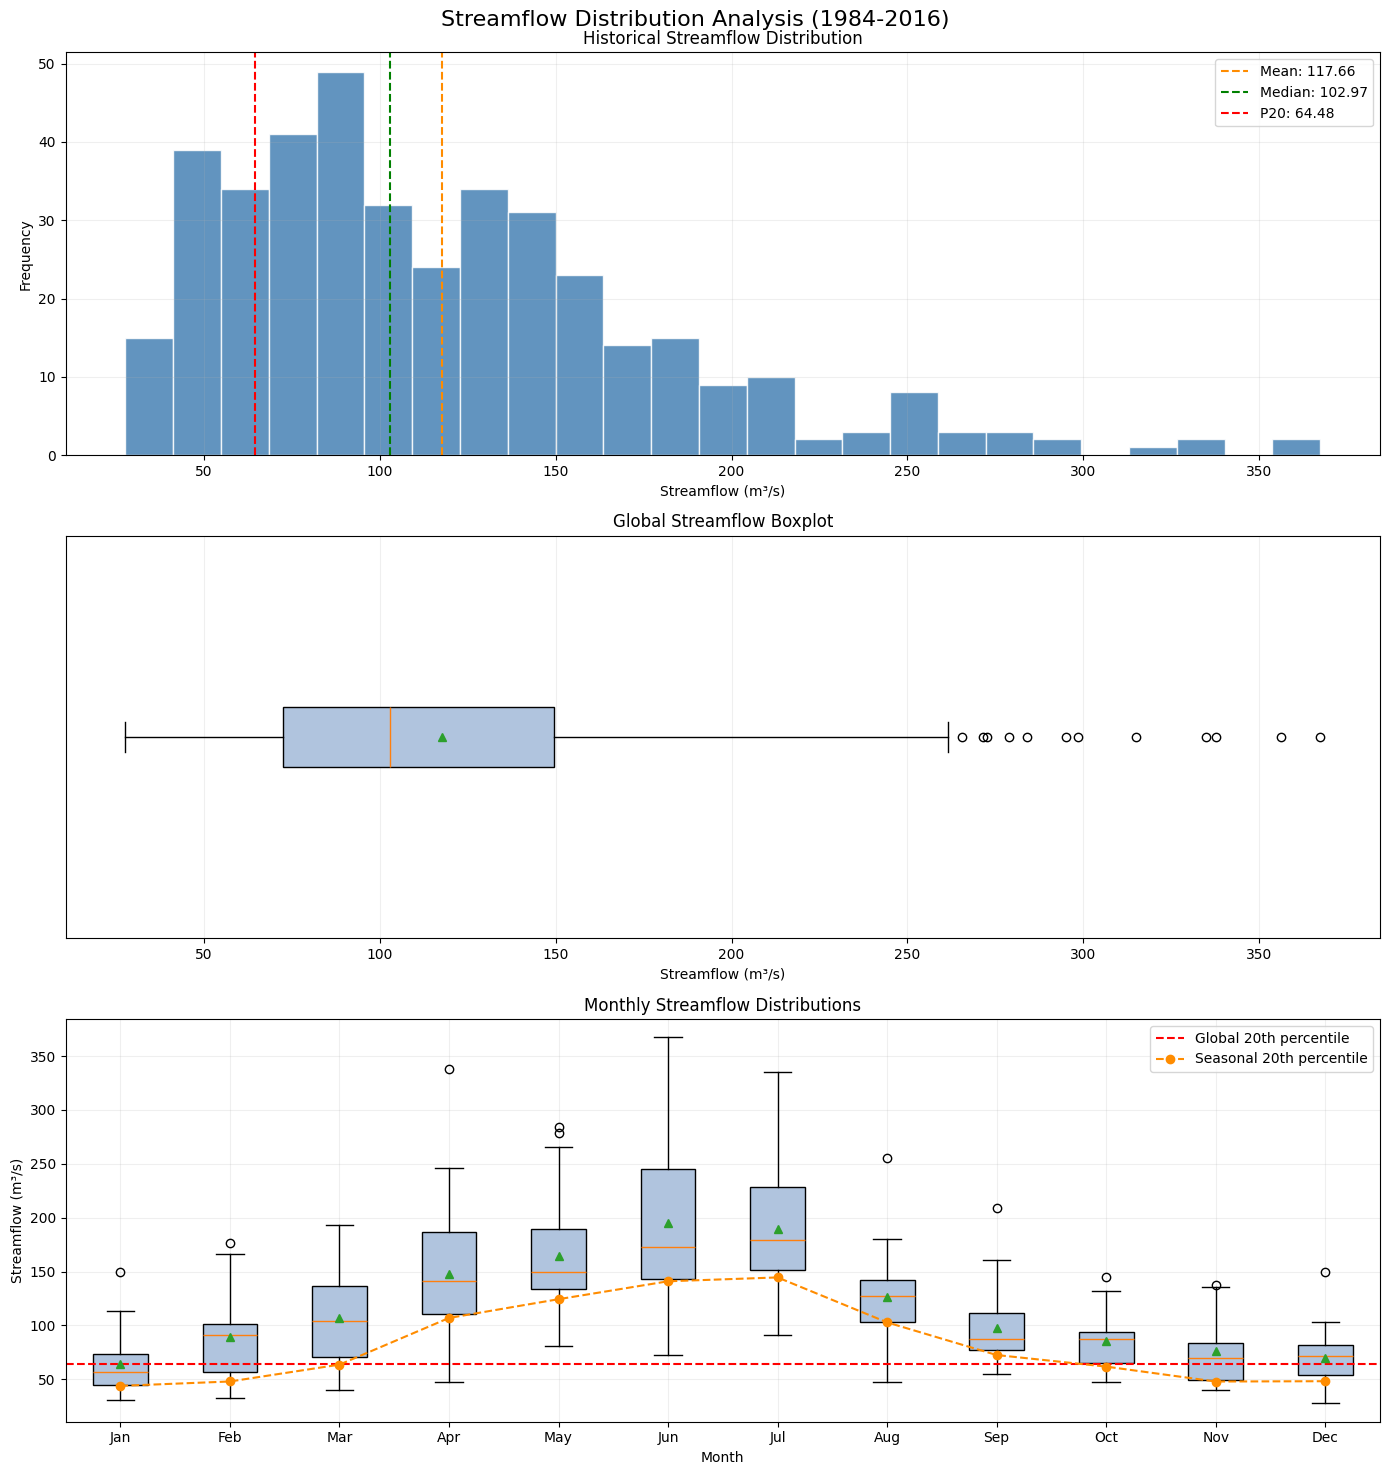

Streamflow distribution analysis saved successfully.


In [12]:

# Select training observations
flow_values = training_data["streamflow"]

# Calculate reference statistics
mean_flow = flow_values.mean()
median_flow = flow_values.median()
p20_flow = flow_values.quantile(0.20)

# Prepare monthly observations
monthly_groups = [
    training_data.loc[
        training_data.index.month == month,
        "streamflow"
    ].to_numpy()
    for month in range(1, 13)
]

# Define month labels
month_labels = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

# Create the figure
fig, axes = plt.subplots(3, 1, figsize=(14, 15))

# 1. Streamflow histogram
axes[0].hist(
    flow_values,
    bins=25,
    color="steelblue",
    edgecolor="white",
    alpha=0.85
)

axes[0].axvline(
    mean_flow,
    color="darkorange",
    linestyle="--",
    label=f"Mean: {mean_flow:.2f}"
)

axes[0].axvline(
    median_flow,
    color="green",
    linestyle="--",
    label=f"Median: {median_flow:.2f}"
)

axes[0].axvline(
    p20_flow,
    color="red",
    linestyle="--",
    label=f"P20: {p20_flow:.2f}"
)

axes[0].set_title("Historical Streamflow Distribution")
axes[0].set_xlabel("Streamflow (m³/s)")
axes[0].set_ylabel("Frequency")
axes[0].legend()
axes[0].grid(alpha=0.2)

# 2. Global streamflow boxplot
axes[1].boxplot(
    flow_values,
    vert=False,
    patch_artist=True,
    showmeans=True,
    boxprops=dict(facecolor="lightsteelblue")
)

axes[1].set_title("Global Streamflow Boxplot")
axes[1].set_xlabel("Streamflow (m³/s)")
axes[1].set_yticks([])
axes[1].grid(alpha=0.2)

# 3. Monthly streamflow boxplots
axes[2].boxplot(
    monthly_groups,
    patch_artist=True,
    showmeans=True,
    boxprops=dict(facecolor="lightsteelblue")
)

axes[2].set_xticks(range(1, 13))
axes[2].set_xticklabels(month_labels)

axes[2].axhline(
    p20_flow,
    color="red",
    linestyle="--",
    label="Global 20th percentile"
)

# Add seasonal thresholds
seasonal_p20 = [
    np.quantile(group, 0.20)
    for group in monthly_groups
]

axes[2].plot(
    range(1, 13),
    seasonal_p20,
    color="darkorange",
    marker="o",
    linestyle="--",
    label="Seasonal 20th percentile"
)

axes[2].set_title("Monthly Streamflow Distributions")
axes[2].set_xlabel("Month")
axes[2].set_ylabel("Streamflow (m³/s)")
axes[2].legend()
axes[2].grid(alpha=0.2)

fig.suptitle(
    "Streamflow Distribution Analysis (1984-2016)",
    fontsize=16
)

plt.tight_layout()

# Save the figure
fig.savefig(
    OUTPUT_DIR / "streamflow_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Streamflow distribution analysis saved successfully.")

Autocorrelation at selected lags:


,lag,acf_original,pacf_original,acf_anomalies,pacf_anomalies
1,1,0.5249,0.5249,0.2247,0.2247
2,2,0.3273,0.0714,0.2365,0.1959
3,3,0.0653,-0.1827,0.1866,0.1093
6,6,-0.4235,-0.1365,0.0575,0.0150
12,12,0.4921,0.1847,0.0015,0.0255
24,24,0.4060,0.0518,-0.1196,-0.0206
36,36,0.4842,0.1717,0.0684,0.1179


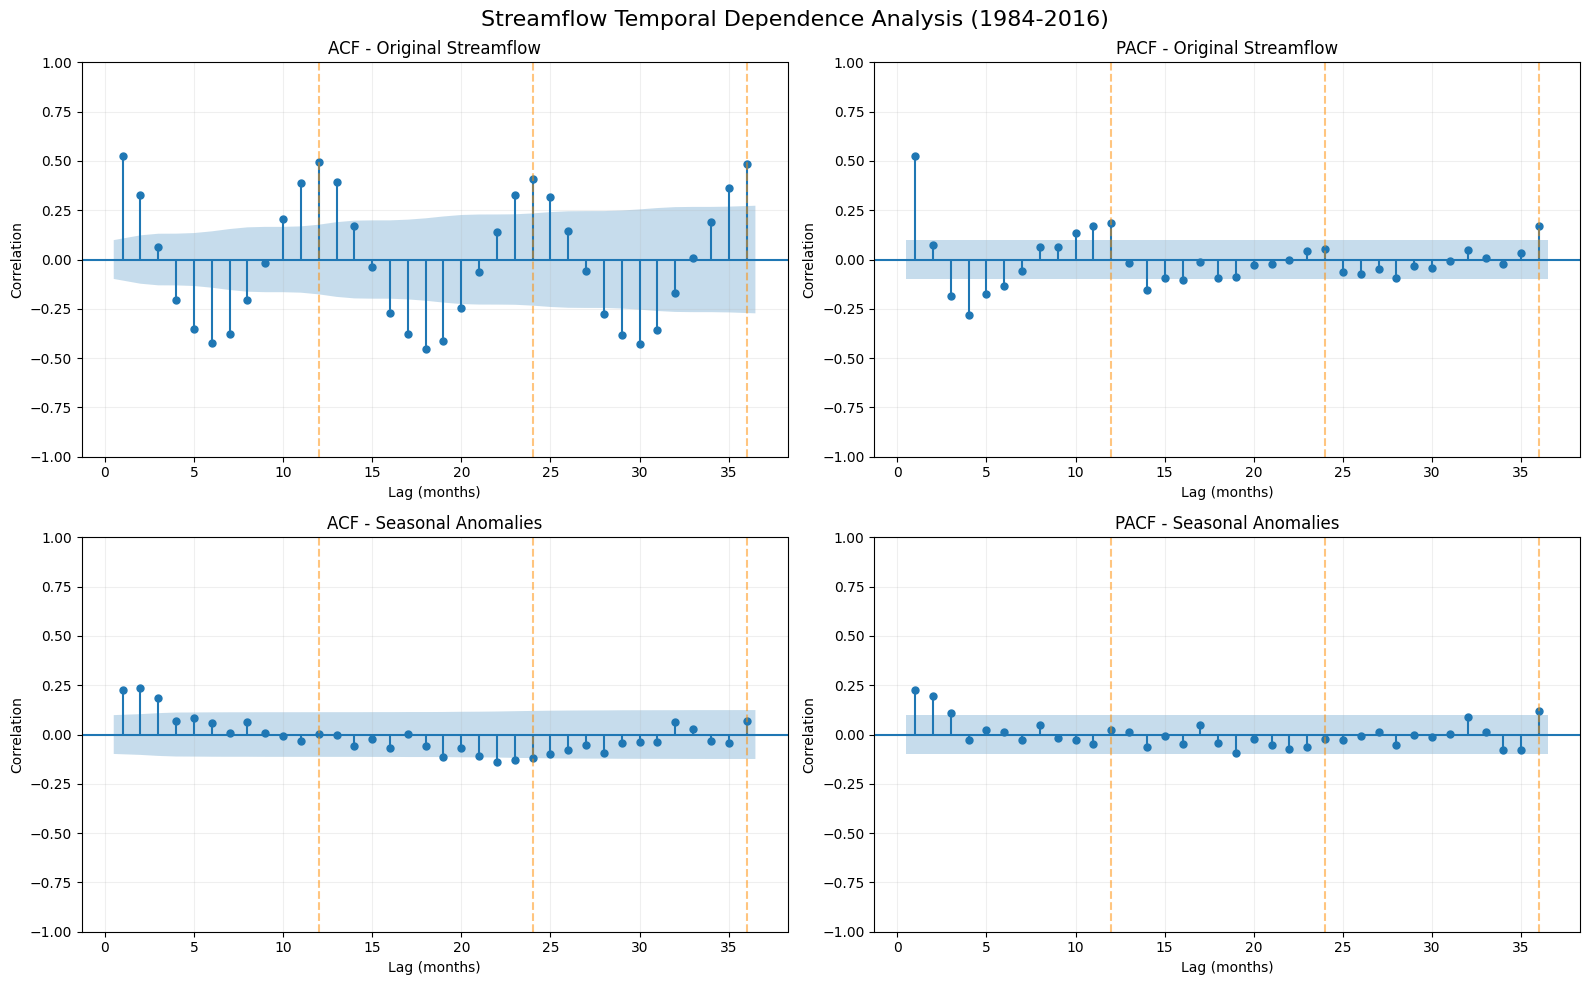


Autocorrelation analysis saved successfully.


In [13]:


from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf

# Select training observations
flow_series = training_data["streamflow"].copy()

# Calculate monthly climatology
monthly_climatology = flow_series.groupby(
    flow_series.index.month
).mean()

# Remove the mean seasonal cycle
seasonal_anomalies = flow_series - (
    flow_series.index.month.map(monthly_climatology)
    .to_numpy()
)

# Define the maximum number of lags
MAX_LAGS = 36

# Calculate autocorrelation values
acf_original = acf(
    flow_series,
    nlags=MAX_LAGS,
    fft=False
)

pacf_original = pacf(
    flow_series,
    nlags=MAX_LAGS,
    method="ywm"
)

# Calculate autocorrelation of seasonal anomalies
acf_anomalies = acf(
    seasonal_anomalies,
    nlags=MAX_LAGS,
    fft=False
)

pacf_anomalies = pacf(
    seasonal_anomalies,
    nlags=MAX_LAGS,
    method="ywm"
)

# Create the autocorrelation results table
autocorrelation_results = pd.DataFrame({
    "lag": np.arange(MAX_LAGS + 1),
    "acf_original": acf_original,
    "pacf_original": pacf_original,
    "acf_anomalies": acf_anomalies,
    "pacf_anomalies": pacf_anomalies
})

# Display selected lags
selected_lags = [1, 2, 3, 6, 12, 24, 36]

print("Autocorrelation at selected lags:")

display(
    autocorrelation_results.loc[
        autocorrelation_results["lag"].isin(selected_lags)
    ].round(4)
)

# Save numerical results
autocorrelation_results.to_csv(
    OUTPUT_DIR / "autocorrelation_results.csv",
    index=False
)

# Create autocorrelation figures
fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10)
)

# ACF of the original series
plot_acf(
    flow_series,
    lags=MAX_LAGS,
    alpha=0.05,
    zero=False,
    ax=axes[0, 0]
)

axes[0, 0].set_title(
    "ACF - Original Streamflow"
)

# PACF of the original series
plot_pacf(
    flow_series,
    lags=MAX_LAGS,
    method="ywm",
    alpha=0.05,
    zero=False,
    ax=axes[0, 1]
)

axes[0, 1].set_title(
    "PACF - Original Streamflow"
)

# ACF of seasonal anomalies
plot_acf(
    seasonal_anomalies,
    lags=MAX_LAGS,
    alpha=0.05,
    zero=False,
    ax=axes[1, 0]
)

axes[1, 0].set_title(
    "ACF - Seasonal Anomalies"
)

# PACF of seasonal anomalies
plot_pacf(
    seasonal_anomalies,
    lags=MAX_LAGS,
    method="ywm",
    alpha=0.05,
    zero=False,
    ax=axes[1, 1]
)

axes[1, 1].set_title(
    "PACF - Seasonal Anomalies"
)

# Highlight annual seasonal lags
for ax in axes.flat:

    for lag in [12, 24, 36]:
        ax.axvline(
            lag,
            color="darkorange",
            linestyle="--",
            alpha=0.5
        )

    ax.set_xlabel("Lag (months)")
    ax.set_ylabel("Correlation")
    ax.set_ylim(-1, 1)
    ax.grid(alpha=0.2)

fig.suptitle(
    "Streamflow Temporal Dependence Analysis (1984-2016)",
    fontsize=16
)

plt.tight_layout()

# Save the figure
fig.savefig(
    OUTPUT_DIR / "autocorrelation_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nAutocorrelation analysis saved successfully.")

Global threshold: 64.4773 m3/s

Classification summary:


,observations,percentage
classification,,
Both methods,47,11.8687
Global only,33,8.3333
Seasonal only,37,9.3434
Neither method,279,70.4545



Agreement: 82.32%
Disagreement: 17.68%

Monthly classification:


classification,Both methods,Global only,Seasonal only,Neither method
Jan,7,13,0,13
Feb,7,4,0,22
Mar,7,0,0,26
Apr,1,0,6,26
May,0,0,7,26
Jun,0,0,7,26
Jul,0,0,7,26
Aug,1,0,6,26
Sep,3,0,4,26
Oct,7,1,0,25


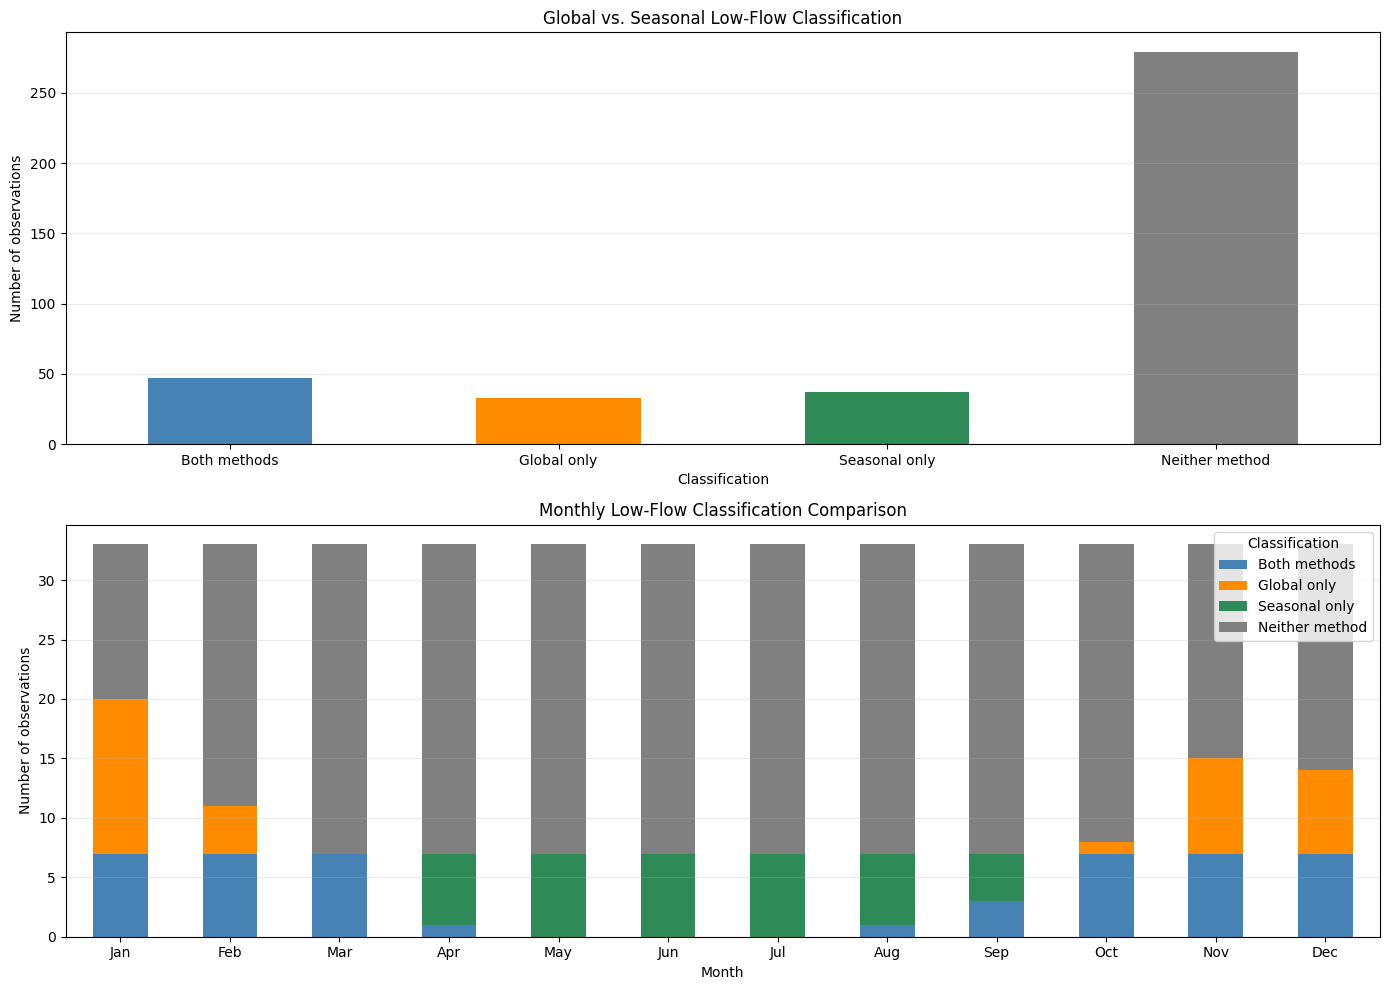


Low-flow classification analysis saved successfully.


In [ ]:


# Create a copy of the training dataset
low_flow_data = training_data.copy()

# Extract calendar information
low_flow_data["year"] = low_flow_data.index.year
low_flow_data["month"] = low_flow_data.index.month

# Define the candidate percentile
LOW_FLOW_PERCENTILE = 0.20

# Calculate the global threshold
global_threshold = training_data["streamflow"].quantile(
    LOW_FLOW_PERCENTILE
)

# Calculate seasonal thresholds
monthly_thresholds = (
    training_data["streamflow"]
    .groupby(training_data.index.month)
    .quantile(LOW_FLOW_PERCENTILE)
)

# Assign thresholds to each observation
low_flow_data["global_threshold"] = global_threshold

low_flow_data["seasonal_threshold"] = (
    low_flow_data["month"].map(monthly_thresholds)
)

# Identify low-flow conditions
low_flow_data["global_low_flow"] = (
    low_flow_data["streamflow"]
    <= low_flow_data["global_threshold"]
)

low_flow_data["seasonal_low_flow"] = (
    low_flow_data["streamflow"]
    <= low_flow_data["seasonal_threshold"]
)

# Define classification conditions
conditions = [
    low_flow_data["global_low_flow"]
    & low_flow_data["seasonal_low_flow"],

    low_flow_data["global_low_flow"]
    & ~low_flow_data["seasonal_low_flow"],

    ~low_flow_data["global_low_flow"]
    & low_flow_data["seasonal_low_flow"]
]

categories = [
    "Both methods",
    "Global only",
    "Seasonal only"
]

# Classify each observation
low_flow_data["classification"] = np.select(
    conditions,
    categories,
    default="Neither method"
)

# Define the category order
category_order = [
    "Both methods",
    "Global only",
    "Seasonal only",
    "Neither method"
]

# Calculate classification counts
classification_summary = (
    low_flow_data["classification"]
    .value_counts()
    .reindex(category_order, fill_value=0)
    .rename("observations")
    .to_frame()
)

# Calculate percentages
classification_summary["percentage"] = (
    classification_summary["observations"]
    / len(low_flow_data)
) * 100

# Calculate agreement between methods
agreement = (
    low_flow_data["global_low_flow"]
    == low_flow_data["seasonal_low_flow"]
).mean()

disagreement = 1 - agreement

# Display results
print(f"Global threshold: {global_threshold:.4f} m3/s")

print("\nClassification summary:")
display(classification_summary.round(4))

print(f"\nAgreement: {agreement:.2%}")
print(f"Disagreement: {disagreement:.2%}")

# Calculate monthly classifications
monthly_classification = pd.crosstab(
    low_flow_data["month"],
    low_flow_data["classification"]
).reindex(
    index=range(1, 13),
    columns=category_order,
    fill_value=0
)

monthly_classification.index = month_labels

print("\nMonthly classification:")
display(monthly_classification)

# Verify classification completeness
assert classification_summary["observations"].sum() == len(
    low_flow_data
)

# Save results
low_flow_data.to_csv(
    OUTPUT_DIR / "low_flow_classification.csv"
)

classification_summary.to_csv(
    OUTPUT_DIR / "low_flow_classification_summary.csv"
)

monthly_classification.to_csv(
    OUTPUT_DIR / "monthly_low_flow_comparison.csv"
)

# Create visualizations
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Plot overall classification
classification_summary["observations"].plot(
    kind="bar",
    ax=axes[0],
    color=["steelblue", "darkorange", "seagreen", "gray"]
)

axes[0].set_title("Global vs. Seasonal Low-Flow Classification")
axes[0].set_ylabel("Number of observations")
axes[0].set_xlabel("Classification")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.25)

# Plot monthly classifications
monthly_classification.plot(
    kind="bar",
    stacked=True,
    ax=axes[1],
    color=["steelblue", "darkorange", "seagreen", "gray"]
)

axes[1].set_title("Monthly Low-Flow Classification Comparison")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Number of observations")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Classification")
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "low_flow_classification_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nLow-flow classification analysis saved successfully.")

In [15]:

# Define a function to identify consecutive low-flow episodes
def identify_low_flow_events(dataset, method):

    event_data = dataset.copy()

    # Select the corresponding threshold
    threshold_column = f"{method}_threshold"
    low_flow_column = f"{method}_low_flow"

    # Extract the number of days in each month
    event_data["days_in_month"] = (
        event_data.index.days_in_month
    )

    # Calculate monthly streamflow deficit
    event_data["deficit_m3s"] = (
        event_data[threshold_column]
        - event_data["streamflow"]
    ).clip(lower=0)

    # Convert streamflow deficit into water volume
    event_data["deficit_volume_m3"] = (
        event_data["deficit_m3s"]
        * event_data["days_in_month"]
        * 86400
    )

    # Identify changes between low-flow and other conditions
    event_data["event_id"] = (
        event_data[low_flow_column]
        .ne(event_data[low_flow_column].shift())
        .cumsum()
    )

    # Select low-flow observations
    low_flow_months = event_data.loc[
        event_data[low_flow_column]
    ].copy()

    events = []

    # Analyze each consecutive low-flow episode
    for event_id, group in low_flow_months.groupby("event_id"):

        duration = len(group)

        total_days = group["days_in_month"].sum()

        total_deficit = group["deficit_volume_m3"].sum()

        mean_intensity = total_deficit / (
            total_days * 86400
        )

        peak_intensity = group["deficit_m3s"].max()

        # Check whether the episode touches dataset boundaries
        boundary_event = (
            group.index.min() == event_data.index.min()
            or group.index.max() == event_data.index.max()
        )

        events.append({
            "method": method,
            "start_date": group.index.min(),
            "end_date": group.index.max(),
            "duration_months": duration,
            "minimum_flow_m3s": group["streamflow"].min(),
            "deficit_volume_hm3": total_deficit / 1e6,
            "mean_intensity_m3s": mean_intensity,
            "peak_intensity_m3s": peak_intensity,
            "boundary_event": boundary_event
        })

    return pd.DataFrame(events)


# Identify global and seasonal low-flow episodes
global_events = identify_low_flow_events(
    low_flow_data,
    method="global"
)

seasonal_events = identify_low_flow_events(
    low_flow_data,
    method="seasonal"
)

# Combine results
all_events = pd.concat(
    [global_events, seasonal_events],
    ignore_index=True
)

# Verify that all low-flow months are included
assert global_events["duration_months"].sum() == (
    low_flow_data["global_low_flow"].sum()
)

assert seasonal_events["duration_months"].sum() == (
    low_flow_data["seasonal_low_flow"].sum()
)

# Calculate summary statistics
event_summary = all_events.groupby("method").agg(
    number_of_events=("duration_months", "count"),
    total_low_flow_months=("duration_months", "sum"),
    mean_duration=("duration_months", "mean"),
    maximum_duration=("duration_months", "max"),
    total_deficit_hm3=("deficit_volume_hm3", "sum"),
    maximum_event_deficit_hm3=("deficit_volume_hm3", "max"),
    maximum_intensity_m3s=("peak_intensity_m3s", "max")
)

print("Low-flow event summary:")
display(event_summary.round(4))

# Display the five longest episodes for each method
for method in ["global", "seasonal"]:

    method_events = all_events[
        all_events["method"] == method
    ]

    print(f"\nFive longest events - {method} method:")

    display(
        method_events.nlargest(
            5, "duration_months"
        ).round(4)
    )

    print(f"\nFive largest deficit events - {method} method:")

    display(
        method_events.nlargest(
            5, "deficit_volume_hm3"
        ).round(4)
    )

# Save results
all_events.to_csv(
    OUTPUT_DIR / "low_flow_events.csv",
    index=False
)

event_summary.to_csv(
    OUTPUT_DIR / "low_flow_event_summary.csv"
)

print("\nLow-flow event analysis saved successfully.")

Low-flow event summary:


,number_of_events,total_low_flow_months,mean_duration,maximum_duration,total_deficit_hm3,maximum_event_deficit_hm3,maximum_intensity_m3s
method,,,,,,,
global,38,80,2.1053,6,3132.5442,223.3699,36.8767
seasonal,53,84,1.5849,5,2980.6339,308.7963,67.9923



Five longest events - global method:


C:\Users\DETPC\AppData\Local\Temp\ipykernel_50104\4194089769.py:130: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(4)


,method,start_date,end_date,duration_months,minimum_flow_m3s,deficit_volume_hm3,mean_intensity_m3s,peak_intensity_m3s,boundary_event
20,global,2001-10-31,2002-03-31,6,46.9497,216.1310,13.7446,17.5276,False
3,global,1985-11-30,1986-03-31,5,34.7275,219.1847,16.8004,29.7497,False
2,global,1985-01-31,1985-04-30,4,39.7745,223.3699,21.5442,24.7027,False
9,global,1992-10-31,1993-01-31,4,43.7922,130.0373,12.2363,20.6850,False
19,global,2000-11-30,2001-02-28,4,40.1614,140.0993,13.5127,24.3159,False



Five largest deficit events - global method:


... (5 outputs left out)


Five largest deficit events - seasonal method:


C:\Users\DETPC\AppData\Local\Temp\ipykernel_50104\4194089769.py:138: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(4)


,method,start_date,end_date,duration_months,minimum_flow_m3s,deficit_volume_hm3,mean_intensity_m3s,peak_intensity_m3s,boundary_event
39,seasonal,1985-01-31,1985-05-31,5,39.7745,308.7963,23.6691,59.5202,False
76,seasonal,2005-07-31,2005-10-31,4,47.9172,240.8198,22.6607,30.4120,False
55,seasonal,1995-08-31,1995-10-31,3,47.0234,201.0894,25.2981,55.7841,False
58,seasonal,1997-06-30,1997-06-30,1,72.9763,176.2360,67.9923,67.9923,False
77,seasonal,2006-06-30,2006-08-31,3,86.7616,167.0772,21.0192,30.9244,False



Low-flow event analysis saved successfully.


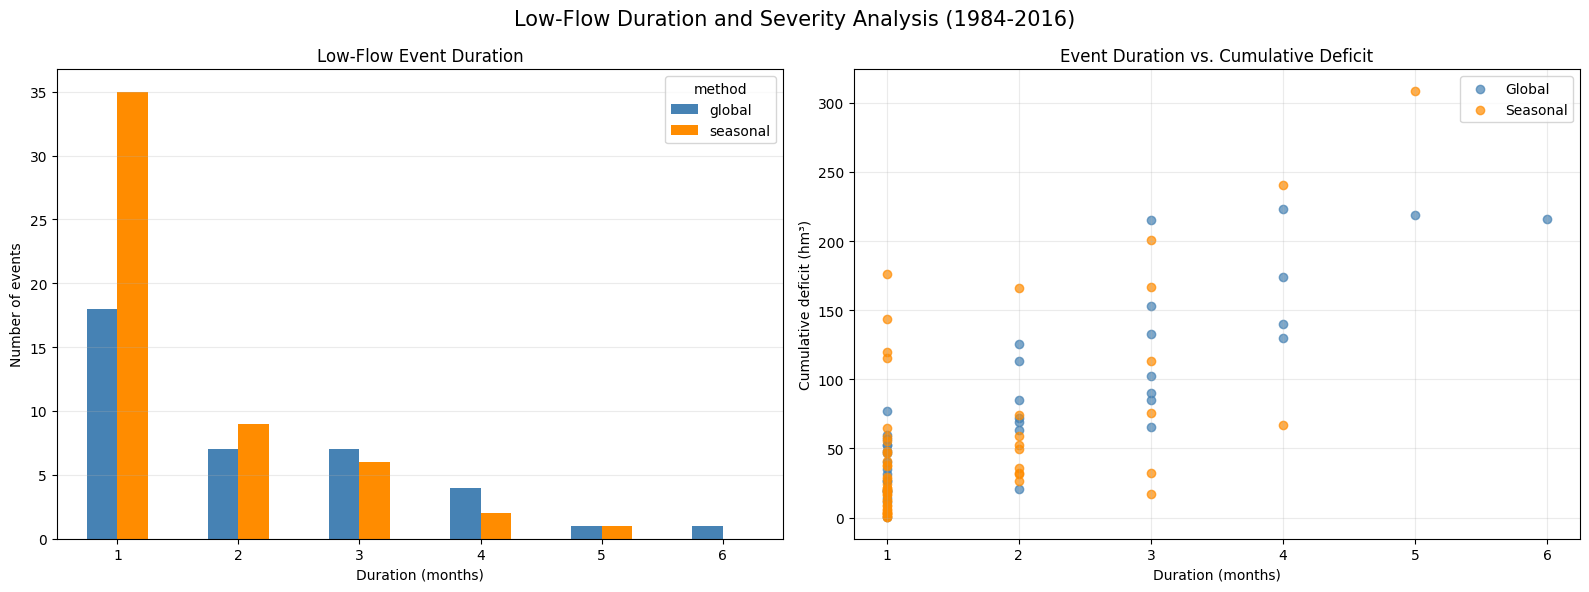

In [16]:
# Visualize event duration and severity

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

# Compare event duration frequencies
duration_counts = pd.crosstab(
    all_events["duration_months"],
    all_events["method"]
)

duration_counts.plot(
    kind="bar",
    ax=axes[0],
    color=["steelblue", "darkorange"]
)

axes[0].set_title("Low-Flow Event Duration")
axes[0].set_xlabel("Duration (months)")
axes[0].set_ylabel("Number of events")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.25)

# Compare duration and cumulative deficit
for method, color in [
    ("global", "steelblue"),
    ("seasonal", "darkorange")
]:

    subset = all_events[
        all_events["method"] == method
    ]

    axes[1].scatter(
        subset["duration_months"],
        subset["deficit_volume_hm3"],
        color=color,
        alpha=0.7,
        label=method.capitalize()
    )

axes[1].set_title("Event Duration vs. Cumulative Deficit")
axes[1].set_xlabel("Duration (months)")
axes[1].set_ylabel("Cumulative deficit (hm³)")
axes[1].legend()
axes[1].grid(alpha=0.25)

fig.suptitle(
    "Low-Flow Duration and Severity Analysis (1984-2016)",
    fontsize=15
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "low_flow_duration_severity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:


# Define candidate percentiles
PERCENTILES = [0.05, 0.10, 0.20, 0.25]

sensitivity_records = []
agreement_records = []
threshold_records = []

# Evaluate each percentile
for percentile in PERCENTILES:

    percentile_label = f"P{int(percentile * 100)}"

    # Create a copy of the training dataset
    sensitivity_data = training_data.copy()
    sensitivity_data["month"] = sensitivity_data.index.month

    # Calculate global and seasonal thresholds
    global_limit = training_data["streamflow"].quantile(
        percentile
    )

    seasonal_limits = (
        training_data["streamflow"]
        .groupby(training_data.index.month)
        .quantile(percentile)
    )

    sensitivity_data["global_threshold"] = global_limit

    sensitivity_data["seasonal_threshold"] = (
        sensitivity_data["month"].map(seasonal_limits)
    )

    # Store monthly thresholds
    for month, seasonal_limit in seasonal_limits.items():

        threshold_records.append({
            "percentile": percentile_label,
            "month": month,
            "global_threshold": global_limit,
            "seasonal_threshold": seasonal_limit
        })

    # Identify low-flow months
    for method in ["global", "seasonal"]:

        sensitivity_data[f"{method}_low_flow"] = (
            sensitivity_data["streamflow"]
            <= sensitivity_data[f"{method}_threshold"]
        )

        # Identify consecutive low-flow episodes
        events = identify_low_flow_events(
            sensitivity_data,
            method
        )

        # Store sensitivity results
        sensitivity_records.append({
            "percentile": percentile_label,
            "method": method,
            "low_flow_months": (
                sensitivity_data[f"{method}_low_flow"].sum()
            ),
            "number_of_events": len(events),
            "mean_duration": events["duration_months"].mean(),
            "maximum_duration": events["duration_months"].max(),
            "total_deficit_hm3": (
                events["deficit_volume_hm3"].sum()
            ),
            "maximum_event_deficit_hm3": (
                events["deficit_volume_hm3"].max()
            ),
            "maximum_intensity_m3s": (
                events["peak_intensity_m3s"].max()
            )
        })

    # Compare global and seasonal classifications
    global_mask = sensitivity_data["global_low_flow"]
    seasonal_mask = sensitivity_data["seasonal_low_flow"]

    both = (global_mask & seasonal_mask).sum()
    global_only = (global_mask & ~seasonal_mask).sum()
    seasonal_only = (~global_mask & seasonal_mask).sum()
    neither = (~global_mask & ~seasonal_mask).sum()

    # Calculate overall agreement
    agreement = (global_mask == seasonal_mask).mean()

    # Calculate Jaccard similarity
    union = (global_mask | seasonal_mask).sum()

    jaccard = both / union if union > 0 else np.nan

    agreement_records.append({
        "percentile": percentile_label,
        "both_methods": both,
        "global_only": global_only,
        "seasonal_only": seasonal_only,
        "neither_method": neither,
        "agreement_percent": agreement * 100,
        "disagreement_percent": (1 - agreement) * 100,
        "jaccard_percent": jaccard * 100
    })

# Create results tables
sensitivity_results = pd.DataFrame(sensitivity_records)
agreement_results = pd.DataFrame(agreement_records)
threshold_results = pd.DataFrame(threshold_records)

# Display results
print("Threshold sensitivity results:")
display(sensitivity_results.round(4))

print("\nClassification agreement and Jaccard index:")
display(agreement_results.round(4))

print("\nGlobal and seasonal thresholds:")
display(threshold_results.round(4))

# Save results
sensitivity_results.to_csv(
    OUTPUT_DIR / "threshold_sensitivity_results.csv",
    index=False
)

agreement_results.to_csv(
    OUTPUT_DIR / "threshold_agreement_results.csv",
    index=False
)

threshold_results.to_csv(
    OUTPUT_DIR / "percentile_thresholds.csv",
    index=False
)

print("\nThreshold sensitivity analysis saved successfully.")

Threshold sensitivity results:


,percentile,method,low_flow_months,number_of_events,mean_duration,maximum_duration,total_deficit_hm3,maximum_event_deficit_hm3,maximum_intensity_m3s
0,P5,global,20,17,1.1765,3,300.6950,51.9277,16.0688
1,P5,seasonal,24,19,1.2632,3,579.8024,114.5897,38.3524
2,P10,global,40,28,1.4286,4,694.3539,93.5126,21.3579
3,P10,seasonal,48,34,1.4118,4,1144.8185,142.2854,50.3636
4,P20,global,80,38,2.1053,6,3132.5442,223.3699,36.8767
5,P20,seasonal,84,53,1.5849,5,2980.6339,308.7963,67.9923
6,P25,global,99,44,2.2500,6,4996.0230,341.5836,44.8547
7,P25,seasonal,108,63,1.7143,5,4050.1464,385.3280,70.5565



Classification agreement and Jaccard index:


,percentile,both_methods,global_only,seasonal_only,neither_method,agreement_percent,disagreement_percent,jaccard_percent
0,P5,9,11,15,361,93.4343,6.5657,25.7143
1,P10,21,19,27,329,88.3838,11.6162,31.3433
2,P20,47,33,37,279,82.3232,17.6768,40.1709
3,P25,64,35,44,253,80.0505,19.9495,44.7552



Global and seasonal thresholds:


,percentile,month,global_threshold,seasonal_threshold
0,P5,1,43.6694,35.8488
1,P5,2,43.6694,38.8719
2,P5,3,43.6694,52.7083
3,P5,4,43.6694,78.8379
4,P5,5,43.6694,94.8920
5,P5,6,43.6694,111.3288
6,P5,7,43.6694,114.9668
7,P5,8,43.6694,81.0151
8,P5,9,43.6694,61.3621
9,P5,10,43.6694,48.7540



Threshold sensitivity analysis saved successfully.


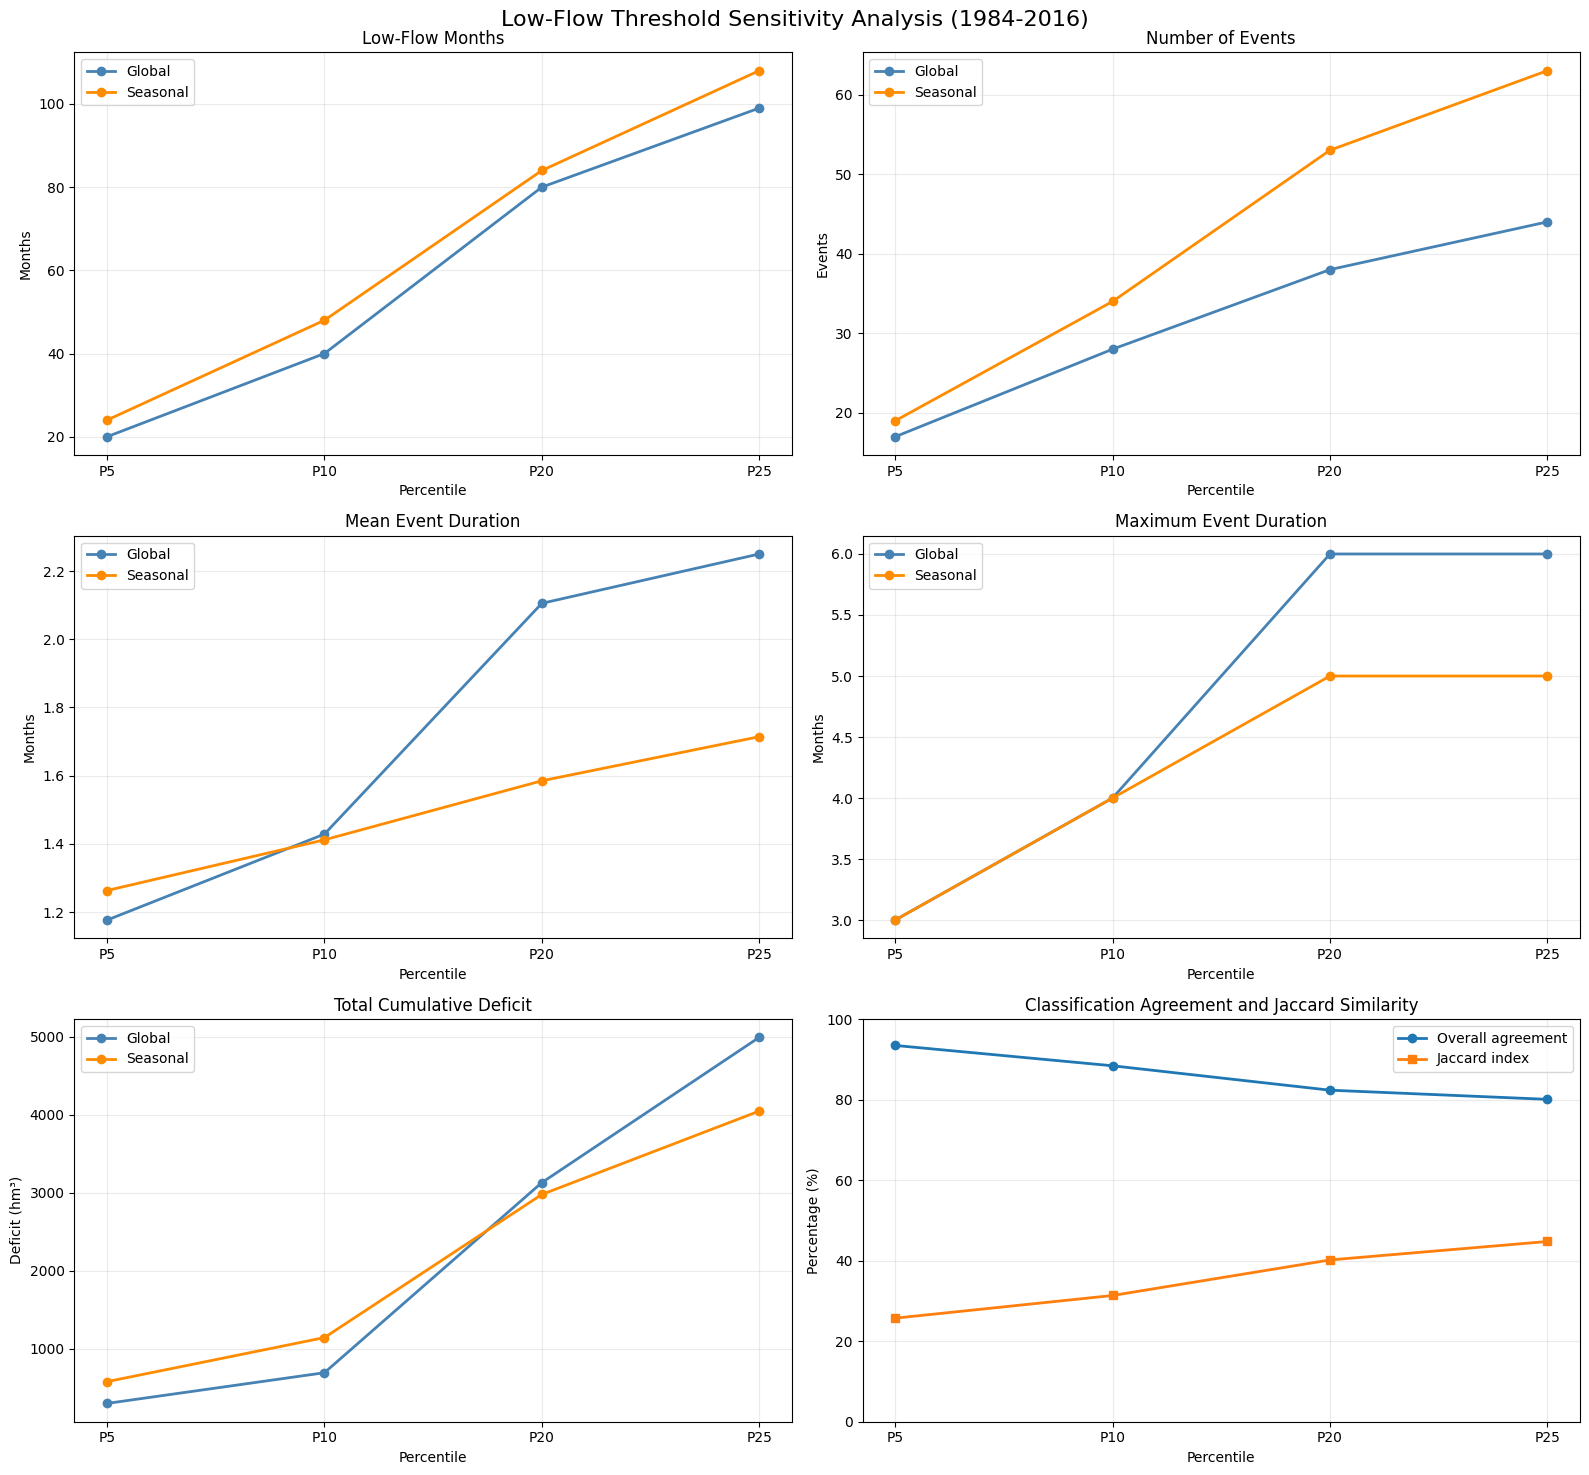

In [18]:


fig, axes = plt.subplots(
    3, 2,
    figsize=(16, 15)
)

percentile_order = ["P5", "P10", "P20", "P25"]

metrics = [
    ("low_flow_months", "Low-Flow Months", "Months"),
    ("number_of_events", "Number of Events", "Events"),
    ("mean_duration", "Mean Event Duration", "Months"),
    ("maximum_duration", "Maximum Event Duration", "Months"),
    ("total_deficit_hm3", "Total Cumulative Deficit", "Deficit (hm³)")
]

# Compare metrics across percentiles
for ax, (metric, title, ylabel) in zip(
    axes.flat,
    metrics
):

    for method, color in [
        ("global", "steelblue"),
        ("seasonal", "darkorange")
    ]:

        subset = sensitivity_results.loc[
            sensitivity_results["method"] == method
        ].set_index("percentile").reindex(percentile_order)

        ax.plot(
            percentile_order,
            subset[metric],
            marker="o",
            linewidth=2,
            color=color,
            label=method.capitalize()
        )

    ax.set_title(title)
    ax.set_xlabel("Percentile")
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(alpha=0.25)

# Plot agreement and Jaccard similarity
axes[2, 1].plot(
    agreement_results["percentile"],
    agreement_results["agreement_percent"],
    marker="o",
    linewidth=2,
    label="Overall agreement"
)

axes[2, 1].plot(
    agreement_results["percentile"],
    agreement_results["jaccard_percent"],
    marker="s",
    linewidth=2,
    label="Jaccard index"
)

axes[2, 1].set_title(
    "Classification Agreement and Jaccard Similarity"
)

axes[2, 1].set_xlabel("Percentile")
axes[2, 1].set_ylabel("Percentage (%)")
axes[2, 1].set_ylim(0, 100)
axes[2, 1].legend()
axes[2, 1].grid(alpha=0.25)

fig.suptitle(
    "Low-Flow Threshold Sensitivity Analysis (1984-2016)",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "threshold_sensitivity_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:


# Define chronological boundaries
TRAIN_END = "2016-12-31"

VALIDATION_START = "2017-01-01"
VALIDATION_END = "2022-12-31"

TEST_START = "2023-01-01"
TEST_END = "2024-12-31"

COMPLEMENTARY_START = "2025-01-01"
COMPLEMENTARY_END = "2025-12-31"

# Create chronological subsets
train = data.loc[:TRAIN_END].copy()

validation = data.loc[
    VALIDATION_START:VALIDATION_END
].copy()

test = data.loc[
    TEST_START:TEST_END
].copy()

complementary = data.loc[
    COMPLEMENTARY_START:COMPLEMENTARY_END
].copy()

# Store the datasets
datasets = {
    "Training": train,
    "Validation": validation,
    "Testing": test,
    "Complementary": complementary
}

# Generate the partition summary
split_summary = pd.DataFrame([
    {
        "dataset": name,
        "start_date": subset.index.min(),
        "end_date": subset.index.max(),
        "observations": len(subset),
        "percentage": len(subset) / len(data) * 100
    }
    for name, subset in datasets.items()
])

# Verify chronological ordering
assert train.index.max() < validation.index.min()

assert validation.index.max() < test.index.min()

assert test.index.max() < complementary.index.min()

# Verify that all observations are preserved
combined_data = pd.concat(datasets.values())

assert combined_data.index.is_unique

pd.testing.assert_frame_equal(
    combined_data,
    data,
    check_freq=False
)

# Verify expected partition sizes
assert len(train) == 396
assert len(validation) == 72
assert len(test) == 24
assert len(complementary) == 12

# Display partition information
print("Chronological data splitting summary:")

display(
    split_summary.round({"percentage": 4})
)

print("\nTotal observations:", len(combined_data))

print("Overlapping observations: 0")
print("Lost observations: 0")

print("\nChronological verification: PASSED")

# Save partition information
split_summary.to_csv(
    OUTPUT_DIR / "chronological_data_split.csv",
    index=False
)

print("\nData splitting summary saved successfully.")

Chronological data splitting summary:


,dataset,start_date,end_date,observations,percentage
0,Training,1984-01-31,2016-12-31,396,78.5714
1,Validation,2017-01-31,2022-12-31,72,14.2857
2,Testing,2023-01-31,2024-12-31,24,4.7619
3,Complementary,2025-01-31,2025-12-31,12,2.3810



Total observations: 504
Overlapping observations: 0
Lost observations: 0

Chronological verification: PASSED

Data splitting summary saved successfully.


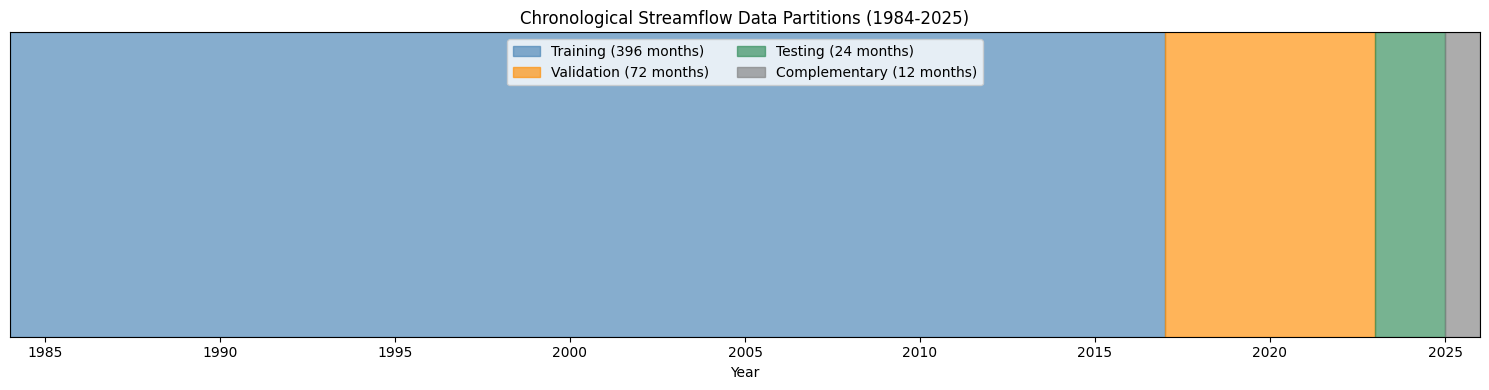

In [20]:
# Visualize the chronological data partitions

fig, ax = plt.subplots(figsize=(15, 4))

partition_colors = {
    "Training": "steelblue",
    "Validation": "darkorange",
    "Testing": "seagreen",
    "Complementary": "gray"
}

# Represent the temporal coverage of each subset
for name, subset in datasets.items():

    start = subset.index.min().to_period("M").start_time

    end = (
        subset.index.max().to_period("M") + 1
    ).start_time

    ax.axvspan(
        start,
        end,
        color=partition_colors[name],
        alpha=0.65,
        label=f"{name} ({len(subset)} months)"
    )

# Configure the figure
ax.set_title(
    "Chronological Streamflow Data Partitions (1984-2025)"
)

ax.set_xlabel("Year")
ax.set_yticks([])
ax.legend(loc="upper center", ncol=2)

ax.set_xlim(
    data.index.min().to_period("M").start_time,
    (data.index.max().to_period("M") + 1).start_time
)

plt.tight_layout()

# Save the figure
fig.savefig(
    OUTPUT_DIR / "chronological_data_split.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:



# Define candidate lag features
LAGS = [1, 2, 3, 6, 12]

# Define rolling windows
ROLLING_WINDOWS = [3, 6]

# Create a copy of the original time series
feature_data = data.copy()

# Create lagged streamflow features
for lag in LAGS:

    feature_data[f"lag_{lag}"] = (
        feature_data["streamflow"].shift(lag)
    )

# Create historical rolling means
for window in ROLLING_WINDOWS:

    feature_data[f"rolling_mean_{window}"] = (
        feature_data["streamflow"]
        .shift(1)
        .rolling(window=window)
        .mean()
    )

# Create cyclical calendar features
month = feature_data.index.month

feature_data["month_sin"] = np.sin(
    2 * np.pi * month / 12
)

feature_data["month_cos"] = np.cos(
    2 * np.pi * month / 12
)

# Define predictor and target columns
FEATURE_COLUMNS = (
    [f"lag_{lag}" for lag in LAGS]
    + [
        f"rolling_mean_{window}"
        for window in ROLLING_WINDOWS
    ]
    + ["month_sin", "month_cos"]
)

TARGET_COLUMN = "streamflow"

# Remove rows without sufficient historical information
initial_observations = len(feature_data)

feature_data = feature_data.dropna(
    subset=FEATURE_COLUMNS + [TARGET_COLUMN]
).copy()

# Calculate removed observations
removed_observations = (
    initial_observations - len(feature_data)
)

# Create chronological feature subsets
train_features = feature_data.loc[:TRAIN_END].copy()

validation_features = feature_data.loc[
    VALIDATION_START:VALIDATION_END
].copy()

test_features = feature_data.loc[
    TEST_START:TEST_END
].copy()

complementary_features = feature_data.loc[
    COMPLEMENTARY_START:COMPLEMENTARY_END
].copy()

# Separate predictors and target
X_train = train_features[FEATURE_COLUMNS]
y_train = train_features[TARGET_COLUMN]

X_val = validation_features[FEATURE_COLUMNS]
y_val = validation_features[TARGET_COLUMN]

X_test = test_features[FEATURE_COLUMNS]
y_test = test_features[TARGET_COLUMN]

X_comp = complementary_features[FEATURE_COLUMNS]
y_comp = complementary_features[TARGET_COLUMN]

# Verify feature completeness
assert not feature_data[FEATURE_COLUMNS].isna().any().any()

assert removed_observations == max(LAGS)

# Verify that lag 1 uses the previous observation
pd.testing.assert_series_equal(
    feature_data["lag_1"],
    data["streamflow"].shift(1).loc[feature_data.index],
    check_names=False
)

# Display feature engineering results
print("Number of predictors:", len(FEATURE_COLUMNS))
print("Initial observations:", initial_observations)
print("Removed observations:", removed_observations)
print("Available observations:", len(feature_data))

print("\nPredictor variables:")
for feature in FEATURE_COLUMNS:
    print("-", feature)

# Display partition dimensions
feature_summary = pd.DataFrame({
    "Dataset": [
        "Training",
        "Validation",
        "Testing",
        "Complementary"
    ],
    "Observations": [
        len(X_train),
        len(X_val),
        len(X_test),
        len(X_comp)
    ],
    "Predictors": [
        X_train.shape[1],
        X_val.shape[1],
        X_test.shape[1],
        X_comp.shape[1]
    ]
})

print("\nFeature partition summary:")
display(feature_summary)

print("\nFirst five training observations:")
display(train_features.head().round(4))

# Save engineered features
feature_data.to_csv(
    OUTPUT_DIR / "engineered_streamflow_features.csv"
)

feature_summary.to_csv(
    OUTPUT_DIR / "feature_partition_summary.csv",
    index=False
)

print("\nFeature engineering completed successfully.")

Number of predictors: 9
Initial observations: 504
Removed observations: 12
Available observations: 492

Predictor variables:
- lag_1
- lag_2
- lag_3
- lag_6
- lag_12
- rolling_mean_3
- rolling_mean_6
- month_sin
- month_cos

Feature partition summary:


,Dataset,Observations,Predictors
0,Training,384,9
1,Validation,72,9
2,Testing,24,9
3,Complementary,12,9



First five training observations:


,streamflow,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_6,month_sin,month_cos
date,,,,,,,,,,
1985-01-31,39.7745,80.4126,60.0420,89.5045,206.0644,44.8207,76.6530,110.3447,0.500,0.866
1985-02-28,44.5048,39.7745,80.4126,60.0420,128.1640,159.0101,60.0764,82.6297,0.866,0.500
1985-03-31,40.3536,44.5048,39.7745,80.4126,97.8807,145.8941,54.8973,68.6865,1.000,0.000
1985-04-30,47.3955,40.3536,44.5048,39.7745,89.5045,245.9541,41.5443,59.0987,0.866,-0.500
1985-05-31,97.1480,47.3955,40.3536,44.5048,60.0420,102.4697,44.0846,52.0805,0.500,-0.866



Feature engineering completed successfully.


In [22]:


def calculate_forecasting_metrics(y_true, y_pred):

    # Verify chronological alignment when using pandas Series
    if isinstance(y_true, pd.Series) and isinstance(y_pred, pd.Series):
        if not y_true.index.equals(y_pred.index):
            raise ValueError("Observation and prediction dates do not match.")

    # Convert inputs into numerical arrays
    observed = np.asarray(y_true, dtype=float)
    predicted = np.asarray(y_pred, dtype=float)

    # Validate input dimensions
    if observed.ndim != 1 or predicted.ndim != 1:
        raise ValueError("Inputs must be one-dimensional.")

    if observed.shape != predicted.shape:
        raise ValueError("Inputs must have the same shape.")

    if len(observed) == 0:
        raise ValueError("Inputs cannot be empty.")

    # Check for missing or infinite values
    if not (
        np.isfinite(observed).all()
        and np.isfinite(predicted).all()
    ):
        raise ValueError("Inputs contain invalid values.")

    # Calculate prediction errors
    errors = predicted - observed

    # Mean Absolute Error
    mae = np.mean(np.abs(errors))

    # Root Mean Squared Error
    rmse = np.sqrt(np.mean(errors ** 2))

    # Mean Bias
    bias = np.mean(errors)

    # Nash-Sutcliffe Efficiency
    denominator = np.sum(
        (observed - observed.mean()) ** 2
    )

    nse = (
        1 - np.sum(errors ** 2) / denominator
        if denominator > 0
        else np.nan
    )

    # Calculate descriptive statistics
    observed_mean = observed.mean()
    predicted_mean = predicted.mean()

    observed_std = observed.std()
    predicted_std = predicted.std()

    # Pearson correlation coefficient
    if observed_std > 0 and predicted_std > 0:
        r = np.corrcoef(observed, predicted)[0, 1]
    else:
        r = np.nan

    # Variability ratio
    alpha = (
        predicted_std / observed_std
        if observed_std > 0
        else np.nan
    )

    # Mean ratio
    beta = (
        predicted_mean / observed_mean
        if observed_mean != 0
        else np.nan
    )

    # Kling-Gupta Efficiency (original formulation)
    kge = 1 - np.sqrt(
        (r - 1) ** 2
        + (alpha - 1) ** 2
        + (beta - 1) ** 2
    )

    # Return forecasting metrics
    return {
        "MAE": mae,
        "RMSE": rmse,
        "Bias": bias,
        "NSE": nse,
        "KGE": kge,
        "KGE_r": r,
        "KGE_alpha": alpha,
        "KGE_beta": beta
    }


print("Forecasting metrics function created successfully.")

Forecasting metrics function created successfully.


In [23]:
# Validate the forecasting metrics function

observed_example = np.array([
    50, 100, 150, 200
])

# Perfect predictions
perfect_prediction = observed_example.copy()

# Systematic overestimation
overestimated_prediction = observed_example + 20

# Systematic underestimation
underestimated_prediction = observed_example - 20

# Calculate metrics for each example
metric_examples = {
    "Perfect prediction": perfect_prediction,
    "Overestimation": overestimated_prediction,
    "Underestimation": underestimated_prediction
}

metric_test_results = pd.DataFrame([
    {
        "Scenario": name,
        **calculate_forecasting_metrics(
            observed_example,
            predictions
        )
    }
    for name, predictions in metric_examples.items()
])

print("Forecasting metrics verification:")

display(metric_test_results.round(4))

# Verify perfect prediction results
perfect_metrics = calculate_forecasting_metrics(
    observed_example,
    perfect_prediction
)

assert np.isclose(perfect_metrics["MAE"], 0)
assert np.isclose(perfect_metrics["RMSE"], 0)
assert np.isclose(perfect_metrics["Bias"], 0)
assert np.isclose(perfect_metrics["NSE"], 1)
assert np.isclose(perfect_metrics["KGE"], 1)

# Verify systematic bias
assert np.isclose(
    calculate_forecasting_metrics(
        observed_example,
        overestimated_prediction
    )["Bias"],
    20
)

assert np.isclose(
    calculate_forecasting_metrics(
        observed_example,
        underestimated_prediction
    )["Bias"],
    -20
)

# Save verification results
metric_test_results.to_csv(
    OUTPUT_DIR / "forecasting_metrics_verification.csv",
    index=False
)

print("\nForecasting metrics verification: PASSED")

Forecasting metrics verification:


,Scenario,MAE,RMSE,Bias,NSE,KGE,KGE_r,KGE_alpha,KGE_beta
0,Perfect prediction,0.0,0.0,0.0,1.000,1.00,1.0,1.0,1.00
1,Overestimation,20.0,20.0,20.0,0.872,0.84,1.0,1.0,1.16
2,Underestimation,20.0,20.0,-20.0,0.872,0.84,1.0,1.0,0.84



Forecasting metrics verification: PASSED


In [24]:
# PERSISTENCE AND SEASONAL NAIVE

# Create a dataframe for validation forecasts
validation_predictions = pd.DataFrame(
    index=y_val.index
)

# Store observed streamflow
validation_predictions["Observed"] = y_val

# Persistence model
validation_predictions["Persistence"] = (
    X_val["lag_1"]
)

# Seasonal Naive model
validation_predictions["Seasonal Naive"] = (
    X_val["lag_12"]
)

# Define baseline models
BASELINE_MODELS = [
    "Persistence",
    "Seasonal Naive"
]

# Verify prediction completeness
assert len(validation_predictions) == 72

assert not validation_predictions.isna().any().any()

# Calculate forecasting metrics
baseline_records = []

for model in BASELINE_MODELS:

    metrics = calculate_forecasting_metrics(
        validation_predictions["Observed"],
        validation_predictions[model]
    )

    baseline_records.append({
        "Model": model,
        **metrics
    })

# Create the baseline performance table
baseline_results = pd.DataFrame(
    baseline_records
).set_index("Model")

# Rank models according to validation MAE
baseline_results = baseline_results.sort_values("MAE")

print("Baseline forecasting performance:")
display(baseline_results.round(4))

# Display the first five predictions
print("\nFirst five validation predictions:")
display(validation_predictions.head().round(4))

# Save predictions and performance metrics
validation_predictions.to_csv(
    OUTPUT_DIR / "baseline_validation_predictions.csv"
)

baseline_results.to_csv(
    OUTPUT_DIR / "baseline_validation_metrics.csv"
)

print("\nBaseline model evaluation completed successfully.")

Baseline forecasting performance:


,MAE,RMSE,Bias,NSE,KGE,KGE_r,KGE_alpha,KGE_beta
Model,,,,,,,,
Seasonal Naive,46.0356,59.9809,3.1421,-0.0350,0.5197,0.5280,1.0857,1.0241
Persistence,46.7860,62.5590,0.1680,-0.1259,0.4348,0.4348,0.9961,1.0013



First five validation predictions:


,Observed,Persistence,Seasonal Naive
date,,,
2017-01-31,102.6763,55.5468,46.9507
2017-02-28,98.4732,102.6763,101.5455
2017-03-31,182.2603,98.4732,164.4997
2017-04-30,203.4769,182.2603,199.5373
2017-05-31,188.9177,203.4769,181.4728



Baseline model evaluation completed successfully.


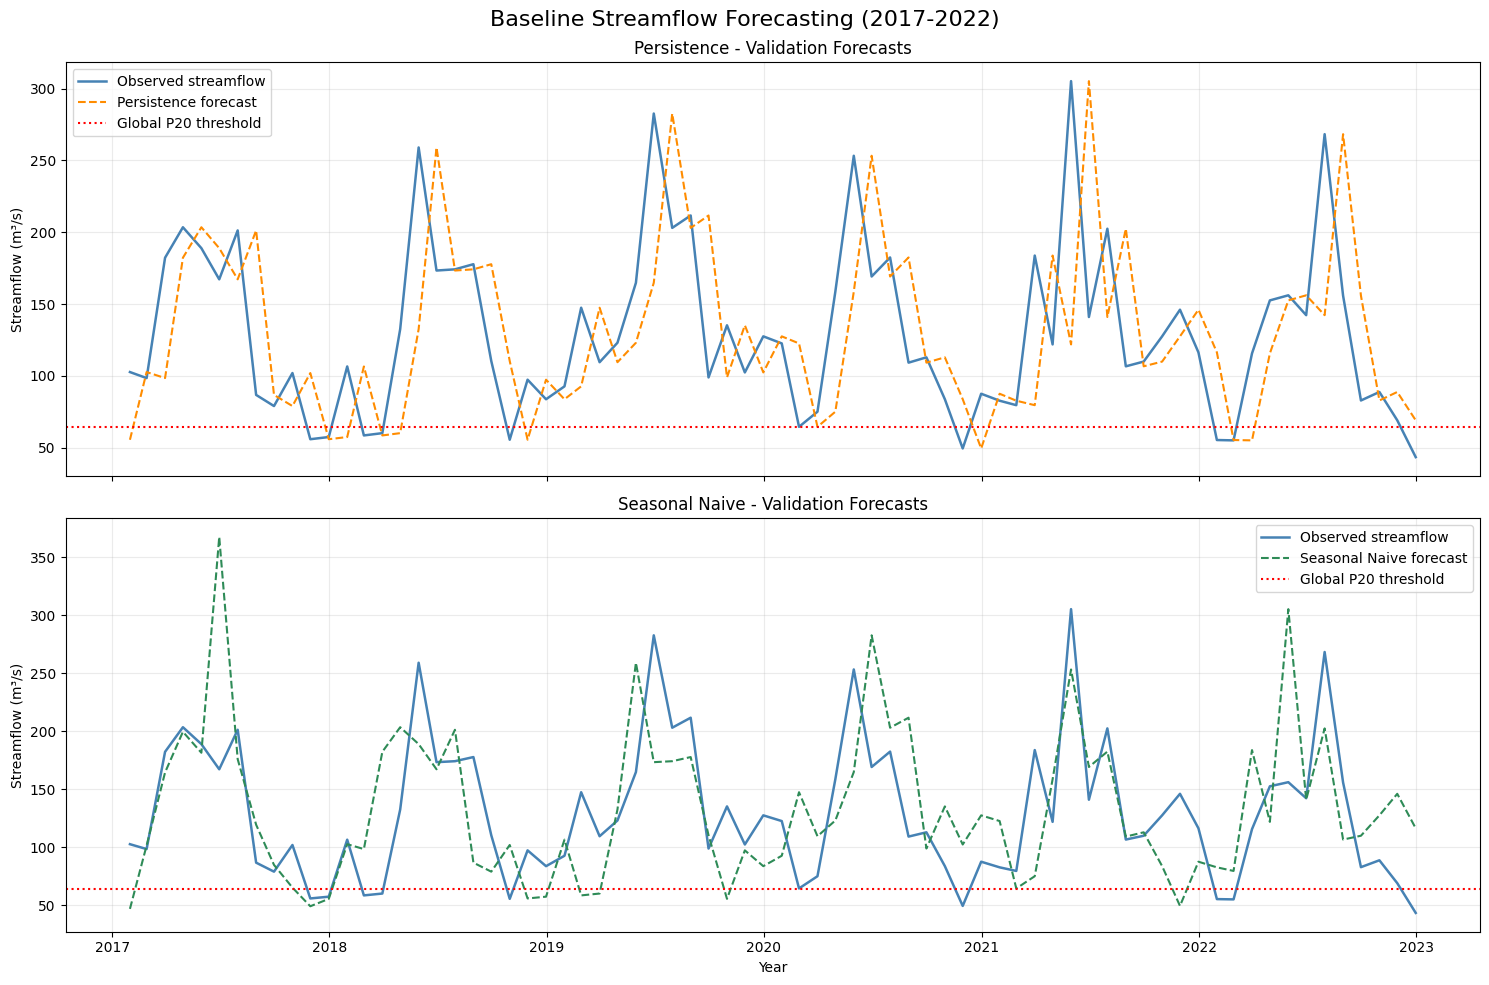

In [25]:
# Visualize baseline forecasts

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 10),
    sharex=True
)

model_colors = {
    "Persistence": "darkorange",
    "Seasonal Naive": "seagreen"
}

for ax, model in zip(axes, BASELINE_MODELS):

    # Plot observed streamflow
    ax.plot(
        validation_predictions.index,
        validation_predictions["Observed"],
        color="steelblue",
        linewidth=1.8,
        label="Observed streamflow"
    )

    # Plot predicted streamflow
    ax.plot(
        validation_predictions.index,
        validation_predictions[model],
        color=model_colors[model],
        linestyle="--",
        linewidth=1.5,
        label=f"{model} forecast"
    )

    # Add the global low-flow reference
    ax.axhline(
        train["streamflow"].quantile(0.20),
        color="red",
        linestyle=":",
        label="Global P20 threshold"
    )

    ax.set_title(f"{model} - Validation Forecasts")
    ax.set_ylabel("Streamflow (m³/s)")
    ax.legend()
    ax.grid(alpha=0.25)

axes[1].set_xlabel("Year")

fig.suptitle(
    "Baseline Streamflow Forecasting (2017-2022)",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "baseline_validation_forecasts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# B. MONTHLY CLIMATOLOGY BASELINE

# Calculate monthly climatology using training data only
monthly_climatology = (
    train["streamflow"]
    .groupby(train.index.month)
    .mean()
)

# Verify that all calendar months are represented
assert len(monthly_climatology) == 12

# Generate validation forecasts
validation_predictions["Monthly Climatology"] = (
    validation_predictions.index.month.map(
        monthly_climatology
    )
)

# Update baseline model list
BASELINE_MODELS = [
    "Persistence",
    "Seasonal Naive",
    "Monthly Climatology"
]

# Verify prediction completeness
assert len(validation_predictions) == 72
assert not validation_predictions.isna().any().any()

# Evaluate all baseline models
baseline_records = []

for model in BASELINE_MODELS:

    metrics = calculate_forecasting_metrics(
        validation_predictions["Observed"],
        validation_predictions[model]
    )

    baseline_records.append({
        "Model": model,
        **metrics
    })

# Create updated performance table
baseline_results = (
    pd.DataFrame(baseline_records)
    .set_index("Model")
    .sort_values("MAE")
)

# Display results
print("Updated baseline forecasting performance:")
display(baseline_results.round(4))

print("\nMonthly climatology values:")
display(monthly_climatology.round(4))

print("\nFirst five validation predictions:")
display(validation_predictions.head().round(4))

# Save updated predictions and metrics
validation_predictions.to_csv(
    OUTPUT_DIR / "baseline_validation_predictions.csv"
)

baseline_results.to_csv(
    OUTPUT_DIR / "baseline_validation_metrics.csv"
)

monthly_climatology.to_csv(
    OUTPUT_DIR / "monthly_climatology.csv"
)

print("\nMonthly climatology evaluation completed successfully.")


Updated baseline forecasting performance:


,MAE,RMSE,Bias,NSE,KGE,KGE_r,KGE_alpha,KGE_beta
Model,,,,,,,,
Monthly Climatology,32.1165,41.9397,-12.7687,0.4940,0.6250,0.7356,0.7528,0.9021
Seasonal Naive,46.0356,59.9809,3.1421,-0.0350,0.5197,0.5280,1.0857,1.0241
Persistence,46.7860,62.5590,0.1680,-0.1259,0.4348,0.4348,0.9961,1.0013



Monthly climatology values:


date
1      63.9031
2      88.8050
3     106.7792
4     147.6142
5     164.8693
6     194.6233
7     189.9123
8     126.6256
9      97.1593
10     85.2087
11     76.6937
12     69.7713
Name: streamflow, dtype: float64


First five validation predictions:


,Observed,Persistence,Seasonal Naive,Monthly Climatology
date,,,,
2017-01-31,102.6763,55.5468,46.9507,63.9031
2017-02-28,98.4732,102.6763,101.5455,88.8050
2017-03-31,182.2603,98.4732,164.4997,106.7792
2017-04-30,203.4769,182.2603,199.5373,147.6142
2017-05-31,188.9177,203.4769,181.4728,164.8693



Monthly climatology evaluation completed successfully.


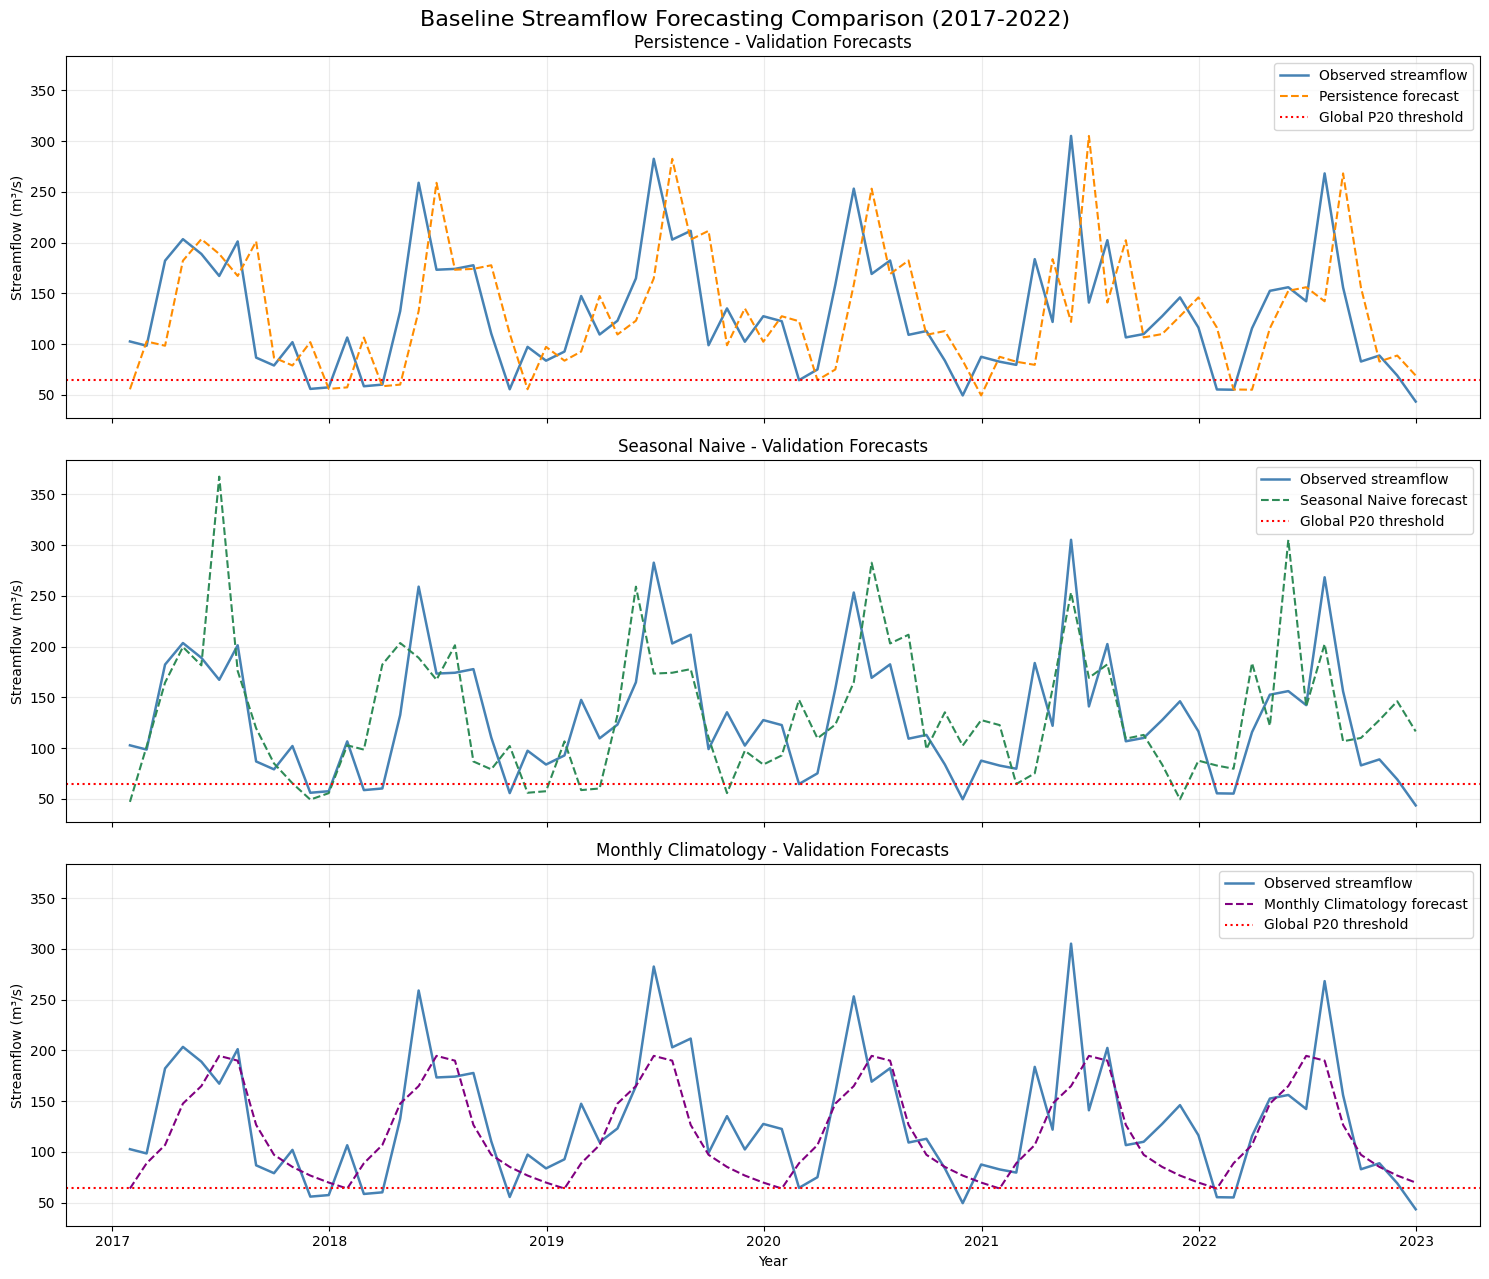

In [27]:
# Visualize all baseline forecasts

fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 13),
    sharex=True,
    sharey=True
)

model_colors = {
    "Persistence": "darkorange",
    "Seasonal Naive": "seagreen",
    "Monthly Climatology": "purple"
}

for ax, model in zip(axes, BASELINE_MODELS):

    # Plot observed streamflow
    ax.plot(
        validation_predictions.index,
        validation_predictions["Observed"],
        color="steelblue",
        linewidth=1.8,
        label="Observed streamflow"
    )

    # Plot forecasted streamflow
    ax.plot(
        validation_predictions.index,
        validation_predictions[model],
        color=model_colors[model],
        linestyle="--",
        linewidth=1.5,
        label=f"{model} forecast"
    )

    # Add global low-flow threshold
    ax.axhline(
        train["streamflow"].quantile(0.20),
        color="red",
        linestyle=":",
        label="Global P20 threshold"
    )

    ax.set_title(f"{model} - Validation Forecasts")
    ax.set_ylabel("Streamflow (m³/s)")
    ax.legend()
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Year")

fig.suptitle(
    "Baseline Streamflow Forecasting Comparison (2017-2022)",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "baseline_forecasting_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
#  SARIMA MODEL

import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Select training and validation time series
sarima_train = train["streamflow"].copy().asfreq("ME")
sarima_val = validation["streamflow"].copy().asfreq("ME")

# Define candidate SARIMA configurations
SARIMA_CANDIDATES = [
    ((1, 0, 0), (1, 0, 0, 12)),
    ((2, 0, 0), (1, 0, 0, 12)),
    ((1, 0, 1), (1, 0, 0, 12)),
    ((1, 0, 0), (0, 1, 1, 12)),
    ((2, 0, 0), (0, 1, 1, 12)),
    ((1, 1, 1), (0, 1, 1, 12))
]

sarima_records = []
sarima_models = {}
sarima_predictions = {}

# Define sequential one-step-ahead forecasting
def rolling_sarima_forecast(fitted_model, evaluation_series):

    current_model = fitted_model
    predictions = []

    for i in range(len(evaluation_series)):

        # Forecast before observing the target value
        forecast = current_model.forecast(steps=1)

        predictions.append(
            float(forecast.iloc[0])
        )

        # Update the model state with the observed value
        new_observation = evaluation_series.iloc[i:i + 1]

        current_model = current_model.extend(
            new_observation
        )

    return pd.Series(
        predictions,
        index=evaluation_series.index,
        name="SARIMA"
    )


# Evaluate candidate configurations
for order, seasonal_order in SARIMA_CANDIDATES:

    model_name = f"SARIMA{order}{seasonal_order}"

    print(f"\nEvaluating {model_name}...")

    try:

        # Include an intercept for undifferenced models
        trend = (
            "c"
            if order[1] == 0 and seasonal_order[1] == 0
            else "n"
        )

        # Define the statistical model
        model = SARIMAX(
            sarima_train,
            order=order,
            seasonal_order=seasonal_order,
            trend=trend,
            enforce_stationarity=True,
            enforce_invertibility=True
        )

        # Estimate parameters using training data only
        with warnings.catch_warnings(record=True) as captured:

            warnings.simplefilter("always")

            fitted_model = model.fit(
                disp=False,
                maxiter=200
            )

        # Check optimization convergence
        converged = bool(
            fitted_model.mle_retvals.get(
                "converged", False
            )
        )

        if not converged:

            sarima_records.append({
                "Model": model_name,
                "Order": str(order),
                "Seasonal_order": str(seasonal_order),
                "Converged": False,
                "AIC": fitted_model.aic,
                "Status": "Not converged"
            })

            print("Model did not converge.")
            continue

        # Generate sequential validation forecasts
        predictions = rolling_sarima_forecast(
            fitted_model,
            sarima_val
        )

        # Calculate forecasting metrics
        metrics = calculate_forecasting_metrics(
            sarima_val,
            predictions
        )

        # Store candidate results
        sarima_records.append({
            "Model": model_name,
            "Order": str(order),
            "Seasonal_order": str(seasonal_order),
            "Converged": True,
            "AIC": fitted_model.aic,
            "Negative_predictions": (
                predictions < 0
            ).sum(),
            "Warnings": len(captured),
            "Status": "Success",
            **metrics
        })

        # Store fitted model and predictions
        sarima_models[model_name] = fitted_model
        sarima_predictions[model_name] = predictions

        print(f"MAE: {metrics['MAE']:.4f}")
        print(f"RMSE: {metrics['RMSE']:.4f}")
        print(f"AIC: {fitted_model.aic:.4f}")

    except Exception as error:

        sarima_records.append({
            "Model": model_name,
            "Order": str(order),
            "Seasonal_order": str(seasonal_order),
            "Converged": False,
            "Status": str(error)
        })

        print(f"Model evaluation failed: {error}")


# Create the candidate evaluation table
sarima_candidate_results = pd.DataFrame(
    sarima_records
)

# Save all candidate results
sarima_candidate_results.to_csv(
    OUTPUT_DIR / "sarima_candidate_results.csv",
    index=False
)

# Select successfully evaluated models
successful_sarima = sarima_candidate_results.loc[
    sarima_candidate_results["Converged"]
    & sarima_candidate_results["Status"].eq("Success")
].copy()

if successful_sarima.empty:
    raise RuntimeError(
        "No SARIMA candidate was successfully evaluated."
    )

# Rank candidates by validation MAE
successful_sarima = successful_sarima.sort_values(
    "MAE"
)

print("\nSARIMA candidate comparison:")

display(
    successful_sarima.round(4)
)

# Select the best SARIMA configuration
best_sarima_name = successful_sarima.iloc[0]["Model"]

best_sarima_model = sarima_models[
    best_sarima_name
]

# Add the selected forecast to the comparison table
validation_predictions["SARIMA"] = (
    sarima_predictions[best_sarima_name]
)

print("\nSelected SARIMA model:")
print(best_sarima_name)

print("\nSelected model parameters:")
display(
    best_sarima_model.params.round(4)
)

print("\nSARIMA model evaluation completed successfully.")


Evaluating SARIMA(1, 0, 0)(1, 0, 0, 12)...
MAE: 39.8899
RMSE: 50.5883
AIC: 4220.3055

Evaluating SARIMA(2, 0, 0)(1, 0, 0, 12)...
MAE: 39.2707
RMSE: 50.5778
AIC: 4209.6133

Evaluating SARIMA(1, 0, 1)(1, 0, 0, 12)...
MAE: 39.5342
RMSE: 50.6045
AIC: 4214.4292

Evaluating SARIMA(1, 0, 0)(0, 1, 1, 12)...
MAE: 33.0303
RMSE: 42.7382
AIC: 4014.9929

Evaluating SARIMA(2, 0, 0)(0, 1, 1, 12)...
MAE: 33.6626
RMSE: 42.5421
AIC: 4001.9382

Evaluating SARIMA(1, 1, 1)(0, 1, 1, 12)...
MAE: 33.2160
RMSE: 42.0839
AIC: 4017.0460

SARIMA candidate comparison:


,Model,Order,Seasonal_order,Converged,AIC,Negative_predictions,Warnings,Status,MAE,RMSE,Bias,NSE,KGE,KGE_r,KGE_alpha,KGE_beta
3,"SARIMA(1, 0, 0)(0, 1, 1, 12)","(1, 0, 0)","(0, 1, 1, 12)",True,4014.9929,0,0,Success,33.0303,42.7382,-9.1372,0.4745,0.6222,0.7087,0.7699,0.9299
5,"SARIMA(1, 1, 1)(0, 1, 1, 12)","(1, 1, 1)","(0, 1, 1, 12)",True,4017.0460,0,0,Success,33.2160,42.0839,-1.5328,0.4905,0.6261,0.7041,0.7718,0.9882
4,"SARIMA(2, 0, 0)(0, 1, 1, 12)","(2, 0, 0)","(0, 1, 1, 12)",True,4001.9382,0,0,Success,33.6626,42.5421,-7.2677,0.4793,0.6313,0.7073,0.7829,0.9443
1,"SARIMA(2, 0, 0)(1, 0, 0, 12)","(2, 0, 0)","(1, 0, 0, 12)",True,4209.6133,0,0,Success,39.2707,50.5778,-2.8099,0.2641,0.3944,0.5255,0.6244,0.9785
2,"SARIMA(1, 0, 1)(1, 0, 0, 12)","(1, 0, 1)","(1, 0, 0, 12)",True,4214.4292,0,0,Success,39.5342,50.6045,-3.0079,0.2633,0.3840,0.5231,0.6109,0.9769
0,"SARIMA(1, 0, 0)(1, 0, 0, 12)","(1, 0, 0)","(1, 0, 0, 12)",True,4220.3055,0,0,Success,39.8899,50.5883,-3.8337,0.2638,0.3719,0.5225,0.5930,0.9706



Selected SARIMA model:
SARIMA(1, 0, 0)(0, 1, 1, 12)

Selected model parameters:


ar.L1          0.2243
ma.S.L12      -0.9942
sigma2      1805.5566
dtype: float64


SARIMA model evaluation completed successfully.


In [29]:
# Compare SARIMA with the baseline models

COMPARISON_MODELS = BASELINE_MODELS + ["SARIMA"]

comparison_records = []

for model in COMPARISON_MODELS:

    metrics = calculate_forecasting_metrics(
        validation_predictions["Observed"],
        validation_predictions[model]
    )

    comparison_records.append({
        "Model": model,
        **metrics
    })

validation_results = (
    pd.DataFrame(comparison_records)
    .set_index("Model")
    .sort_values("MAE")
)

# Calculate skill relative to monthly climatology
reference_mae = validation_results.loc[
    "Monthly Climatology", "MAE"
]

validation_results["Skill_MAE"] = (
    1 - validation_results["MAE"] / reference_mae
)

print("\nUpdated forecasting performance:")
display(validation_results.round(4))

# Display the first five predictions
print("\nFirst five validation forecasts:")
display(validation_predictions.head().round(4))

# Save updated results
validation_results.to_csv(
    OUTPUT_DIR / "validation_model_comparison.csv"
)

validation_predictions.to_csv(
    OUTPUT_DIR / "validation_model_predictions.csv"
)

# Save the selected SARIMA model
best_sarima_model.save(
    str(OUTPUT_DIR / "best_sarima_model.pkl")
)

print("\nSARIMA comparison saved successfully.")


Updated forecasting performance:


,MAE,RMSE,Bias,NSE,KGE,KGE_r,KGE_alpha,KGE_beta,Skill_MAE
Model,,,,,,,,,
Monthly Climatology,32.1165,41.9397,-12.7687,0.4940,0.6250,0.7356,0.7528,0.9021,0.0000
SARIMA,33.0303,42.7382,-9.1372,0.4745,0.6222,0.7087,0.7699,0.9299,-0.0285
Seasonal Naive,46.0356,59.9809,3.1421,-0.0350,0.5197,0.5280,1.0857,1.0241,-0.4334
Persistence,46.7860,62.5590,0.1680,-0.1259,0.4348,0.4348,0.9961,1.0013,-0.4568



First five validation forecasts:


,Observed,Persistence,Seasonal Naive,Monthly Climatology,SARIMA
date,,,,,
2017-01-31,102.6763,55.5468,46.9507,63.9031,60.6967
2017-02-28,98.4732,102.6763,101.5455,88.8050,97.4867
2017-03-31,182.2603,98.4732,164.4997,106.7792,108.9441
2017-04-30,203.4769,182.2603,199.5373,147.6142,164.5706
2017-05-31,188.9177,203.4769,181.4728,164.8693,177.3666



SARIMA comparison saved successfully.


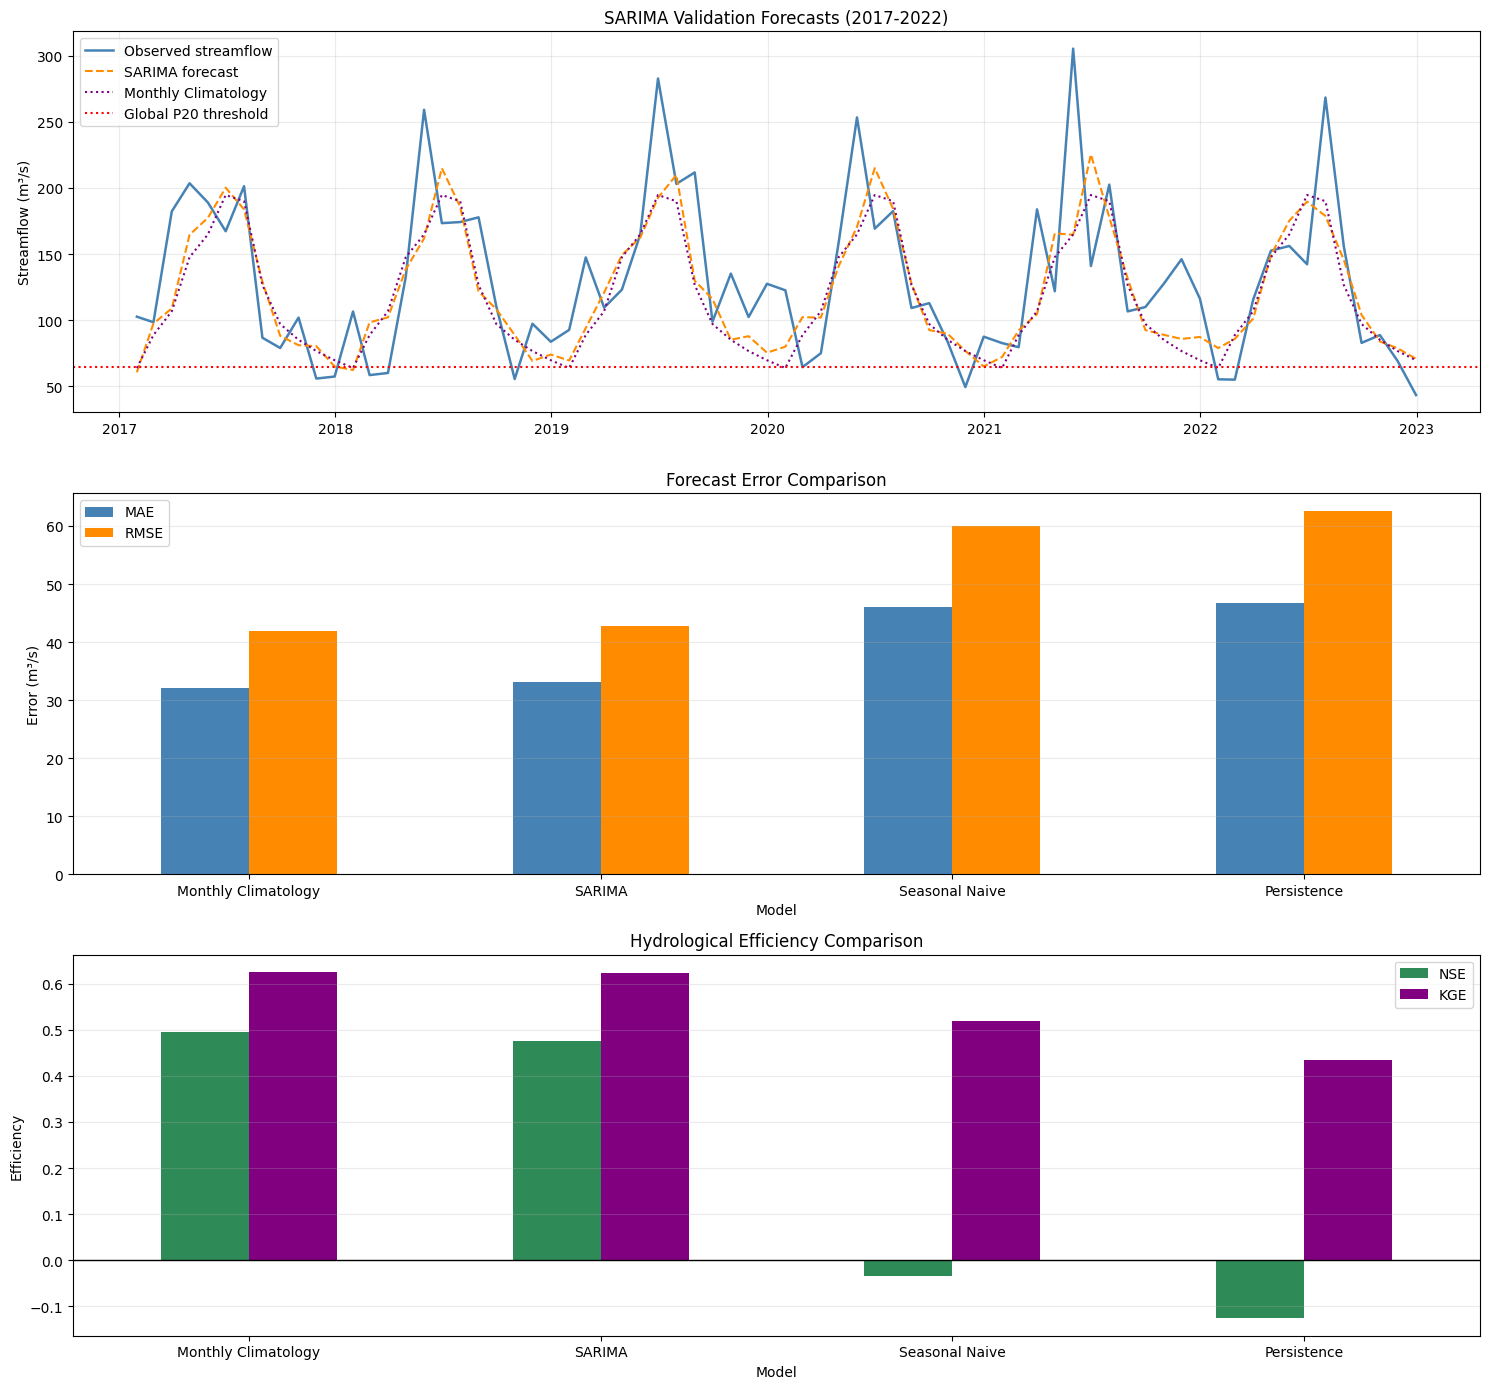

In [30]:
# Visualize SARIMA forecasts and model performance

fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 14)
)

# Plot SARIMA validation forecasts
axes[0].plot(
    validation_predictions.index,
    validation_predictions["Observed"],
    color="steelblue",
    linewidth=1.8,
    label="Observed streamflow"
)

axes[0].plot(
    validation_predictions.index,
    validation_predictions["SARIMA"],
    color="darkorange",
    linestyle="--",
    label="SARIMA forecast"
)

axes[0].plot(
    validation_predictions.index,
    validation_predictions["Monthly Climatology"],
    color="purple",
    linestyle=":",
    label="Monthly Climatology"
)

axes[0].axhline(
    train["streamflow"].quantile(0.20),
    color="red",
    linestyle=":",
    label="Global P20 threshold"
)

axes[0].set_title(
    "SARIMA Validation Forecasts (2017-2022)"
)

axes[0].set_ylabel("Streamflow (m³/s)")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Compare MAE and RMSE
validation_results[["MAE", "RMSE"]].plot(
    kind="bar",
    ax=axes[1],
    color=["steelblue", "darkorange"]
)

axes[1].set_title("Forecast Error Comparison")
axes[1].set_ylabel("Error (m³/s)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.25)

# Compare hydrological efficiency metrics
validation_results[["NSE", "KGE"]].plot(
    kind="bar",
    ax=axes[2],
    color=["seagreen", "purple"]
)

axes[2].axhline(
    0,
    color="black",
    linewidth=1
)

axes[2].set_title("Hydrological Efficiency Comparison")
axes[2].set_ylabel("Efficiency")
axes[2].tick_params(axis="x", rotation=0)
axes[2].grid(axis="y", alpha=0.25)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "sarima_validation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
# 18B. SARIMA RESIDUAL DIAGNOSTICS

from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.gofplots import qqplot
from statsmodels.graphics.tsaplots import plot_acf

# Display all SARIMA candidate results
print("SARIMA candidate results:")
display(sarima_candidate_results)

print("\nSelected SARIMA model:")
print(best_sarima_name)

# Extract selected model orders
selected_order = best_sarima_model.model.order

selected_seasonal_order = (
    best_sarima_model.model.seasonal_order
)

print("Order:", selected_order)
print("Seasonal order:", selected_seasonal_order)

# Extract standardized forecast errors
filter_results = best_sarima_model.filter_results

standardized_residuals = (
    filter_results.standardized_forecasts_error[0]
)

# Exclude initialization observations
burn_in = max(
    best_sarima_model.loglikelihood_burn,
    filter_results.nobs_diffuse
)

residuals = pd.Series(
    standardized_residuals,
    index=sarima_train.index,
    name="standardized_residual"
).iloc[burn_in:]

# Remove invalid residuals
residuals = residuals.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

# Calculate descriptive statistics
residual_summary = pd.DataFrame({
    "Statistic": [
        "Number of residuals",
        "Mean",
        "Standard deviation",
        "Minimum",
        "Maximum",
        "Skewness",
        "Excess kurtosis"
    ],
    "Value": [
        len(residuals),
        residuals.mean(),
        residuals.std(),
        residuals.min(),
        residuals.max(),
        residuals.skew(),
        residuals.kurt()
    ]
})

print("\nStandardized residual statistics:")
display(residual_summary.round(4))

# Calculate model degrees of freedom
p, d, q = selected_order
P, D, Q, s = selected_seasonal_order

model_df = p + q + P + Q

# Perform the Ljung-Box test
ljung_box_results = acorr_ljungbox(
    residuals,
    lags=[12, 24, 36],
    model_df=model_df,
    return_df=True
)

print("\nLjung-Box test results:")
display(ljung_box_results.round(6))

# Check physically invalid validation forecasts
negative_predictions = (
    validation_predictions["SARIMA"] < 0
).sum()

print("\nNegative validation forecasts:")
print(negative_predictions)

# Save diagnostic results
residuals.to_csv(
    OUTPUT_DIR / "sarima_standardized_residuals.csv"
)

residual_summary.to_csv(
    OUTPUT_DIR / "sarima_residual_summary.csv",
    index=False
)

ljung_box_results.to_csv(
    OUTPUT_DIR / "sarima_ljung_box_results.csv"
)

print("\nSARIMA residual diagnostics completed.")


SARIMA candidate results:


,Model,Order,Seasonal_order,Converged,AIC,Negative_predictions,Warnings,Status,MAE,RMSE,Bias,NSE,KGE,KGE_r,KGE_alpha,KGE_beta
0,"SARIMA(1, 0, 0)(1, 0, 0, 12)","(1, 0, 0)","(1, 0, 0, 12)",True,4220.305485,0,0,Success,39.889934,50.588311,-3.833745,0.263753,0.371871,0.522456,0.593019,0.970607
1,"SARIMA(2, 0, 0)(1, 0, 0, 12)","(2, 0, 0)","(1, 0, 0, 12)",True,4209.613320,0,0,Success,39.270723,50.577799,-2.809903,0.264059,0.394430,0.525470,0.624405,0.978457
2,"SARIMA(1, 0, 1)(1, 0, 0, 12)","(1, 0, 1)","(1, 0, 0, 12)",True,4214.429166,0,0,Success,39.534189,50.604475,-3.007933,0.263282,0.384035,0.523065,0.610881,0.976939
3,"SARIMA(1, 0, 0)(0, 1, 1, 12)","(1, 0, 0)","(0, 1, 1, 12)",True,4014.992941,0,0,Success,33.030257,42.738227,-9.137244,0.474520,0.622242,0.708718,0.769895,0.929947
4,"SARIMA(2, 0, 0)(0, 1, 1, 12)","(2, 0, 0)","(0, 1, 1, 12)",True,4001.938243,0,0,Success,33.662603,42.542128,-7.267716,0.479331,0.631334,0.707281,0.782916,0.944280
5,"SARIMA(1, 1, 1)(0, 1, 1, 12)","(1, 1, 1)","(0, 1, 1, 12)",True,4017.046009,0,0,Success,33.215969,42.083862,-1.532846,0.490488,0.626141,0.704094,0.771807,0.988248



Selected SARIMA model:
SARIMA(1, 0, 0)(0, 1, 1, 12)
Order: (1, 0, 0)
Seasonal order: (0, 1, 1, 12)

Standardized residual statistics:


,Statistic,Value
0,Number of residuals,384.0000
1,Mean,0.0080
2,Standard deviation,1.0012
3,Minimum,-3.1207
4,Maximum,4.4133
5,Skewness,0.7776
6,Excess kurtosis,2.5825



Ljung-Box test results:


,lb_stat,lb_pvalue
12,23.799698,0.008150
24,42.247342,0.005834
36,60.099907,0.003778



Negative validation forecasts:
0

SARIMA residual diagnostics completed.


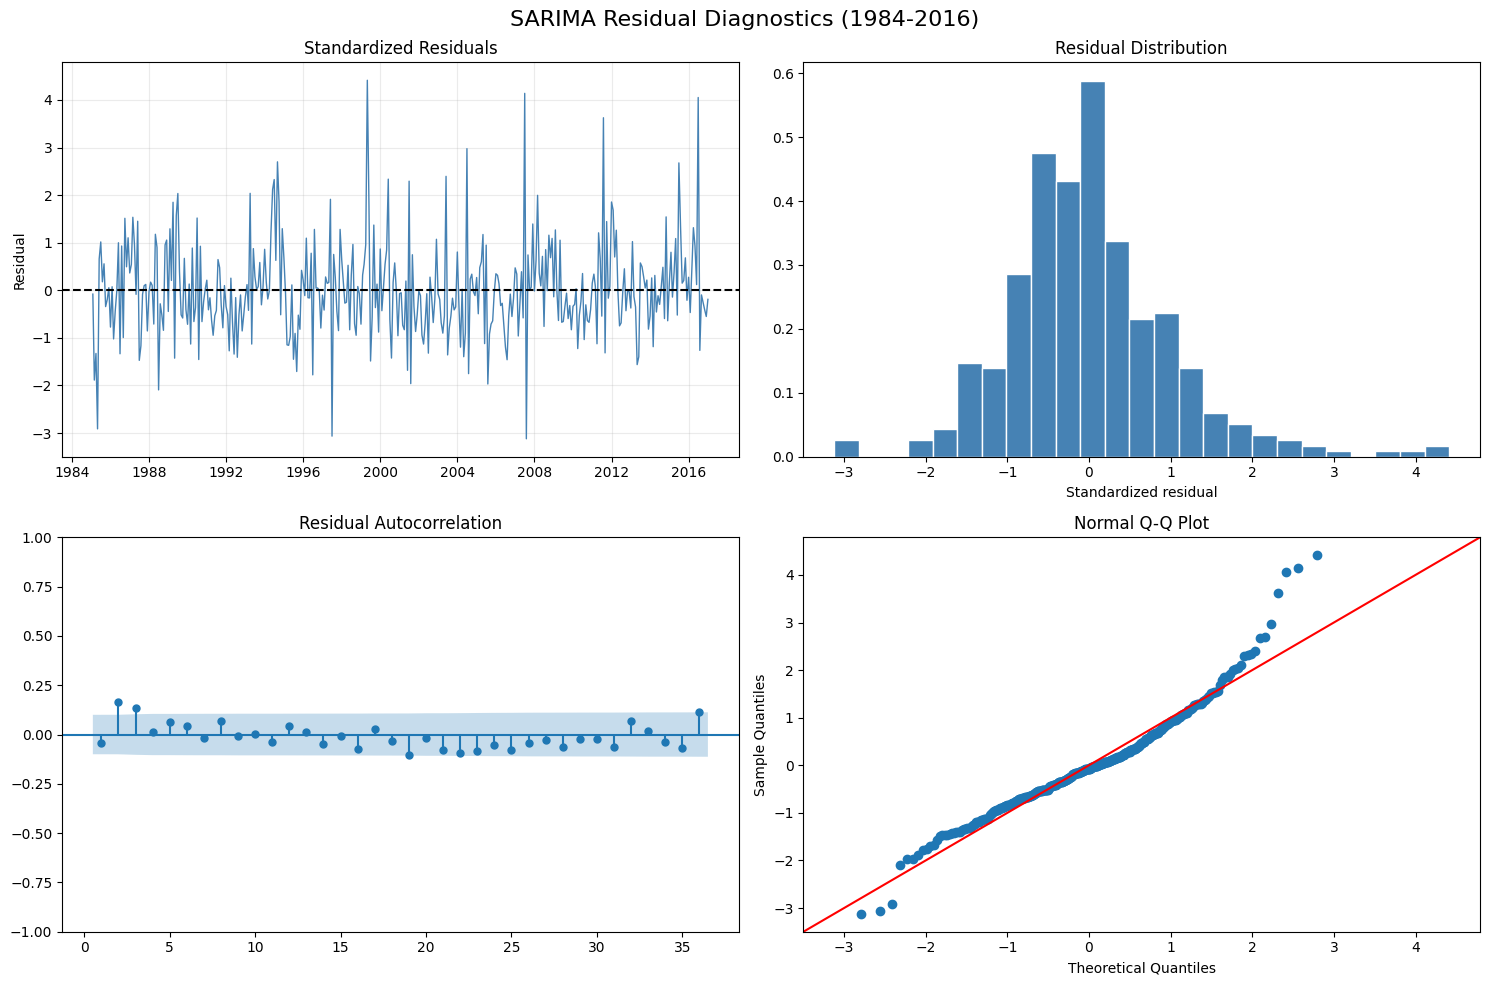

In [32]:
# Visualize SARIMA residual diagnostics

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10)
)

# Standardized residual time series
axes[0, 0].plot(
    residuals.index,
    residuals,
    color="steelblue",
    linewidth=1
)

axes[0, 0].axhline(
    0,
    color="black",
    linestyle="--"
)

axes[0, 0].set_title("Standardized Residuals")
axes[0, 0].set_ylabel("Residual")
axes[0, 0].grid(alpha=0.25)

# Residual distribution
axes[0, 1].hist(
    residuals,
    bins=25,
    density=True,
    color="steelblue",
    edgecolor="white"
)

axes[0, 1].set_title("Residual Distribution")
axes[0, 1].set_xlabel("Standardized residual")

# Residual autocorrelation
plot_acf(
    residuals,
    lags=36,
    zero=False,
    alpha=0.05,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Residual Autocorrelation")

# Normal Q-Q plot
qqplot(
    residuals,
    line="45",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Normal Q-Q Plot")

fig.suptitle(
    "SARIMA Residual Diagnostics (1984-2016)",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "sarima_residual_diagnostics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
#  RANDOM FOREST REGRESSION

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterGrid
import joblib

# Define candidate hyperparameters
rf_param_grid = {
    "n_estimators": [300],
    "max_depth": [3, 6, None],
    "min_samples_leaf": [2, 5, 10],
    "max_features": [0.67, 1.0]
}

rf_candidates = list(ParameterGrid(rf_param_grid))

rf_records = []
rf_models = {}
rf_predictions = {}

print("Number of Random Forest configurations:",
      len(rf_candidates))

# Evaluate each candidate configuration
for i, params in enumerate(rf_candidates, start=1):

    model_name = f"RF_{i:02d}"

    print(f"Evaluating {model_name}...")

    # Define the Random Forest model
    model = RandomForestRegressor(
        **params,
        criterion="squared_error",
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    # Fit using training data only
    model.fit(X_train, y_train)

    # Generate training predictions
    train_predictions = pd.Series(
        model.predict(X_train),
        index=y_train.index
    )

    # Generate one-step-ahead validation predictions
    predictions = pd.Series(
        model.predict(X_val),
        index=y_val.index,
        name="Random Forest"
    )

    # Calculate training and validation metrics
    train_metrics = calculate_forecasting_metrics(
        y_train,
        train_predictions
    )

    val_metrics = calculate_forecasting_metrics(
        y_val,
        predictions
    )

    # Store model evaluation results
    rf_records.append({
        "Model": model_name,
        **params,
        "Training_MAE": train_metrics["MAE"],
        "Generalization_Gap": (
            val_metrics["MAE"]
            - train_metrics["MAE"]
        ),
        **val_metrics
    })

    # Store trained models and predictions
    rf_models[model_name] = model
    rf_predictions[model_name] = predictions

    print(f"Validation MAE: {val_metrics['MAE']:.4f}")


# Create candidate comparison table
rf_candidate_results = (
    pd.DataFrame(rf_records)
    .sort_values(["MAE", "RMSE"])
    .reset_index(drop=True)
)

print("\nRandom Forest candidate comparison:")
display(rf_candidate_results.round(4))

# Select the best configuration
best_rf_name = rf_candidate_results.iloc[0]["Model"]

best_rf_model = rf_models[best_rf_name]

print("\nSelected Random Forest model:")
print(best_rf_name)

print("\nSelected hyperparameters:")

display(
    rf_candidate_results.iloc[[0]][
        list(rf_param_grid.keys())
    ]
)

# Add selected forecasts to validation table
validation_predictions["Random Forest"] = (
    rf_predictions[best_rf_name]
)

# Verify prediction completeness
assert len(validation_predictions) == 72
assert not validation_predictions.isna().any().any()

# Save candidate results
rf_candidate_results.to_csv(
    OUTPUT_DIR / "random_forest_candidate_results.csv",
    index=False
)

# Save selected model
joblib.dump(
    best_rf_model,
    OUTPUT_DIR / "best_random_forest_model.pkl"
)

print("\nRandom Forest model evaluation completed successfully.")

Number of Random Forest configurations: 18
Evaluating RF_01...
Validation MAE: 30.8856
Evaluating RF_02...
Validation MAE: 30.7467
Evaluating RF_03...
Validation MAE: 30.7046
Evaluating RF_04...
Validation MAE: 31.1413
Evaluating RF_05...
Validation MAE: 31.1038
Evaluating RF_06...
Validation MAE: 31.1134
Evaluating RF_07...
Validation MAE: 33.7110
Evaluating RF_08...
Validation MAE: 32.8144
Evaluating RF_09...
Validation MAE: 32.2236
Evaluating RF_10...
Validation MAE: 33.6460
Evaluating RF_11...
Validation MAE: 32.7605
Evaluating RF_12...
Validation MAE: 32.2697
Evaluating RF_13...
Validation MAE: 33.8455
Evaluating RF_14...
Validation MAE: 33.0381
Evaluating RF_15...
Validation MAE: 32.1595
Evaluating RF_16...
Validation MAE: 33.5708
Evaluating RF_17...
Validation MAE: 32.7923
Evaluating RF_18...
Validation MAE: 32.2904

Random Forest candidate comparison:


,Model,max_depth,max_features,min_samples_leaf,n_estimators,Training_MAE,Generalization_Gap,MAE,RMSE,Bias,NSE,KGE,KGE_r,KGE_alpha,KGE_beta
0,RF_03,3.0,0.67,10,300,29.3559,1.3487,30.7046,39.9524,-7.2733,0.5408,0.6471,0.7458,0.7616,0.9442
1,RF_02,3.0,0.67,5,300,29.1108,1.6359,30.7467,39.9171,-7.3112,0.5416,0.6505,0.7466,0.7660,0.9439
2,RF_01,3.0,0.67,2,300,29.0158,1.8698,30.8856,40.1685,-7.4298,0.5358,0.6463,0.7430,0.7638,0.9430
3,RF_05,3.0,1.00,5,300,28.9514,2.1524,31.1038,40.2634,-7.4561,0.5336,0.6622,0.7428,0.7886,0.9428
4,RF_06,3.0,1.00,10,300,29.2695,1.8439,31.1134,40.1615,-7.4452,0.5360,0.6611,0.7441,0.7853,0.9429
5,RF_04,3.0,1.00,2,300,28.9348,2.2065,31.1413,40.4023,-7.6096,0.5304,0.6584,0.7409,0.7851,0.9417
6,RF_15,NaN,0.67,10,300,26.4691,5.6904,32.1595,40.3815,-5.9420,0.5309,0.6668,0.7381,0.7991,0.9544
7,RF_09,6.0,0.67,10,300,26.5895,5.6341,32.2236,40.4347,-5.8543,0.5296,0.6686,0.7374,0.8029,0.9551
8,RF_12,6.0,1.00,10,300,26.1359,6.1338,32.2697,40.4638,-5.7771,0.5290,0.6771,0.7380,0.8164,0.9557
9,RF_18,NaN,1.00,10,300,26.0727,6.2177,32.2904,40.4752,-5.7664,0.5287,0.6769,0.7379,0.8164,0.9558



Selected Random Forest model:
RF_03

Selected hyperparameters:


,n_estimators,max_depth,min_samples_leaf,max_features
0,300,3.0,10,0.67



Random Forest model evaluation completed successfully.


In [34]:
# Compare Random Forest with previous models

COMPARISON_MODELS = BASELINE_MODELS + [
    "SARIMA",
    "Random Forest"
]

comparison_records = []

for model in COMPARISON_MODELS:

    metrics = calculate_forecasting_metrics(
        validation_predictions["Observed"],
        validation_predictions[model]
    )

    comparison_records.append({
        "Model": model,
        **metrics
    })

# Create updated performance table
validation_results = (
    pd.DataFrame(comparison_records)
    .set_index("Model")
    .sort_values("MAE")
)

# Calculate skill relative to monthly climatology
reference_mae = validation_results.loc[
    "Monthly Climatology", "MAE"
]

validation_results["Skill_MAE"] = (
    1 - validation_results["MAE"] / reference_mae
)

print("\nUpdated forecasting performance:")
display(validation_results.round(4))

# Calculate feature importance
rf_feature_importance = pd.DataFrame({
    "Feature": FEATURE_COLUMNS,
    "Importance": best_rf_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

print("\nRandom Forest feature importance:")
display(rf_feature_importance.round(4))

# Save updated results
validation_results.to_csv(
    OUTPUT_DIR / "validation_model_comparison.csv"
)

validation_predictions.to_csv(
    OUTPUT_DIR / "validation_model_predictions.csv"
)

rf_feature_importance.to_csv(
    OUTPUT_DIR / "random_forest_feature_importance.csv",
    index=False
)

print("\nRandom Forest comparison saved successfully.")


Updated forecasting performance:


,MAE,RMSE,Bias,NSE,KGE,KGE_r,KGE_alpha,KGE_beta,Skill_MAE
Model,,,,,,,,,
Random Forest,30.7046,39.9524,-7.2733,0.5408,0.6471,0.7458,0.7616,0.9442,0.0440
Monthly Climatology,32.1165,41.9397,-12.7687,0.4940,0.6250,0.7356,0.7528,0.9021,0.0000
SARIMA,33.0303,42.7382,-9.1372,0.4745,0.6222,0.7087,0.7699,0.9299,-0.0285
Seasonal Naive,46.0356,59.9809,3.1421,-0.0350,0.5197,0.5280,1.0857,1.0241,-0.4334
Persistence,46.7860,62.5590,0.1680,-0.1259,0.4348,0.4348,0.9961,1.0013,-0.4568



Random Forest feature importance:


,Feature,Importance
8,month_cos,0.5774
0,lag_1,0.1669
4,lag_12,0.1235
7,month_sin,0.0314
3,lag_6,0.0282
5,rolling_mean_3,0.0256
1,lag_2,0.0214
6,rolling_mean_6,0.0149
2,lag_3,0.0108



Random Forest comparison saved successfully.


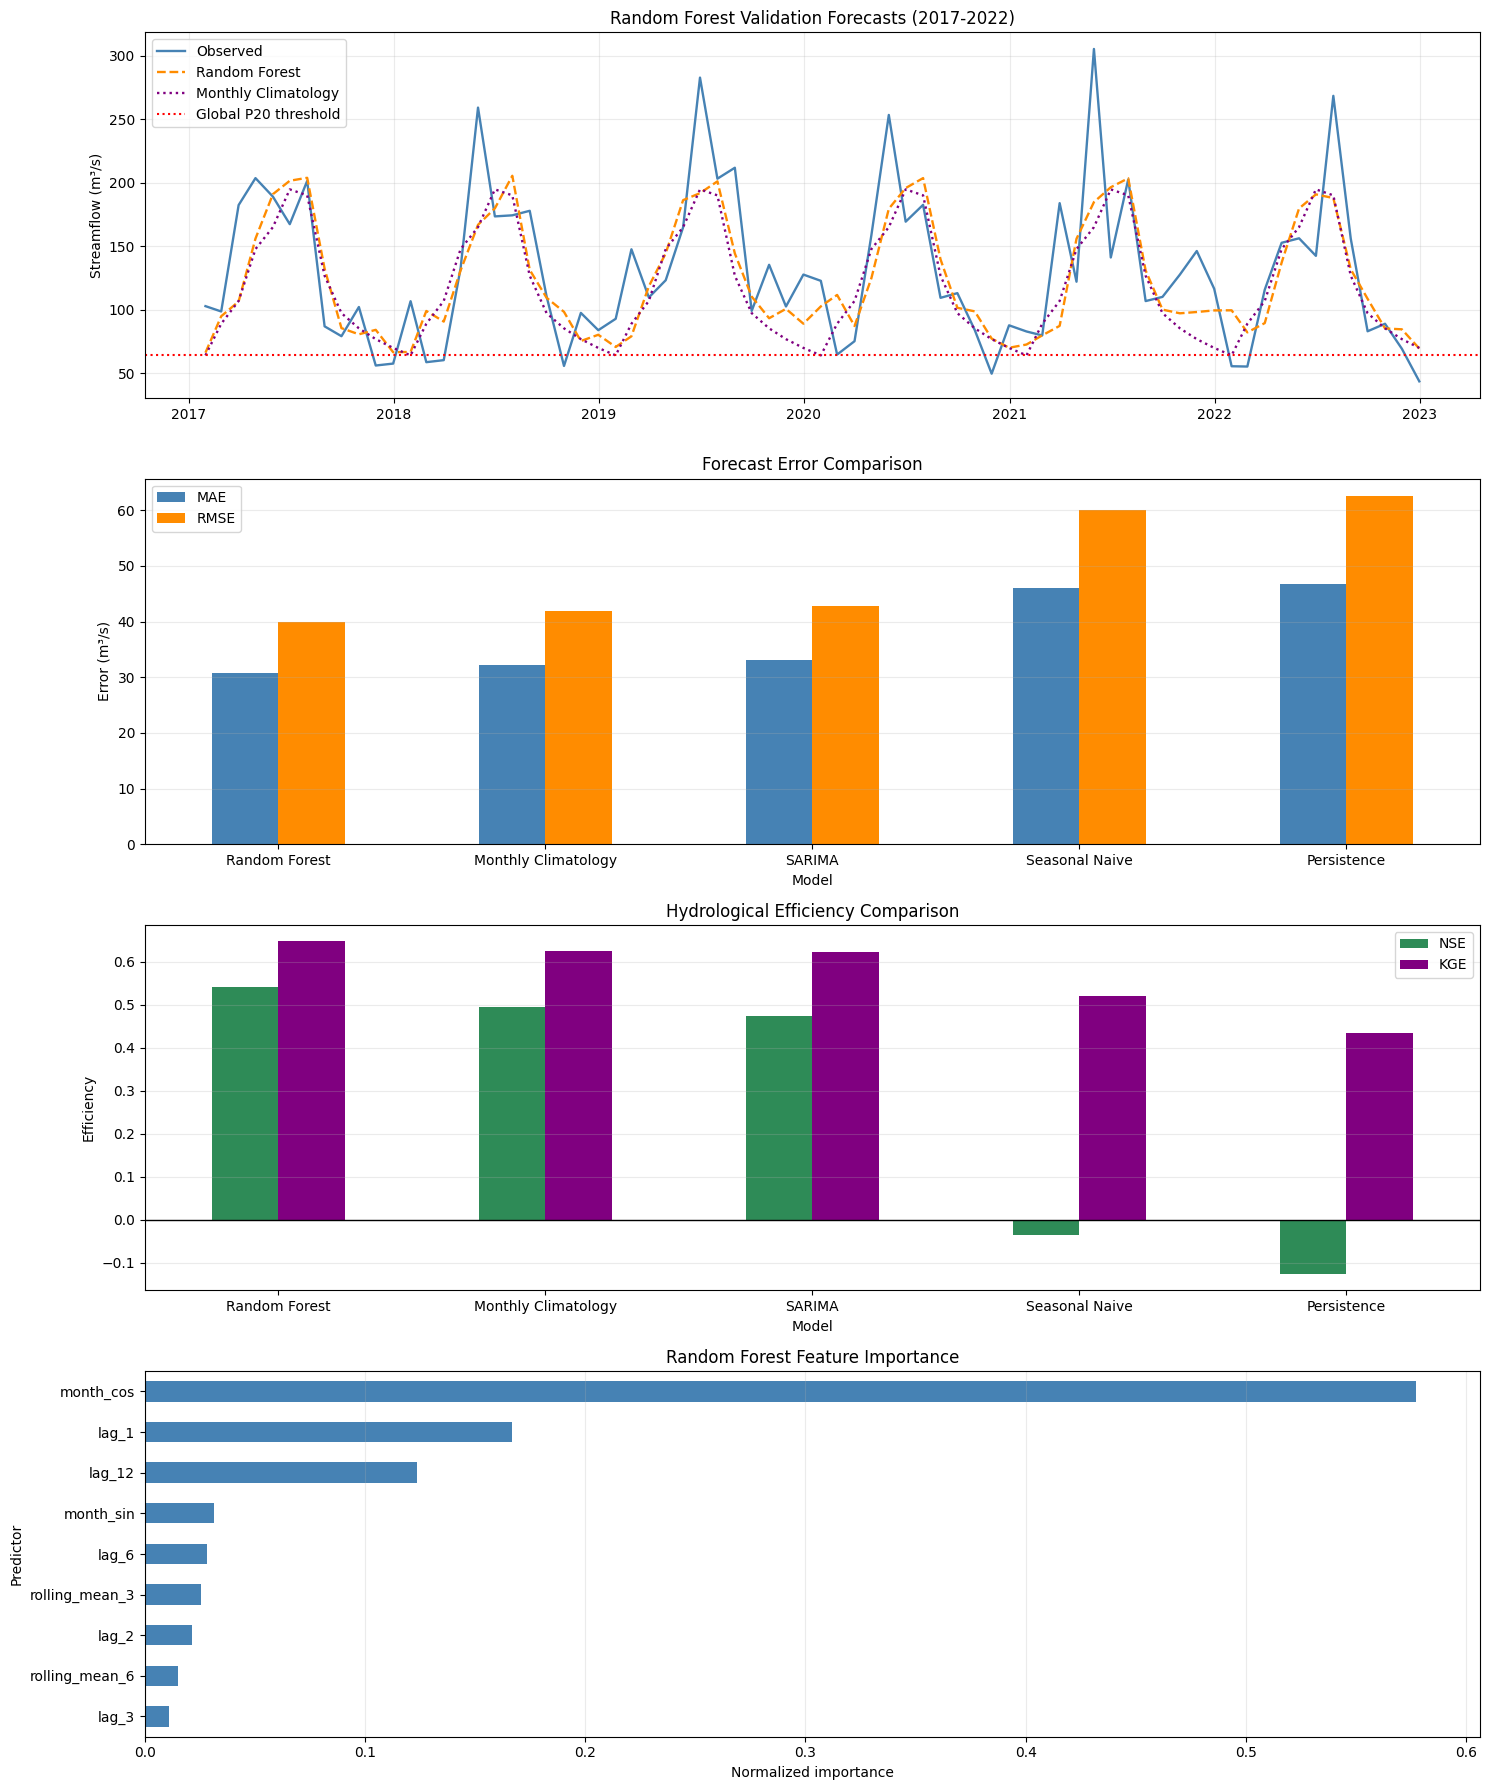

In [35]:
# Visualize Random Forest forecasting results

fig, axes = plt.subplots(
    4, 1,
    figsize=(15, 18)
)

# Compare observed and predicted streamflow
for model, color, style in [
    ("Observed", "steelblue", "-"),
    ("Random Forest", "darkorange", "--"),
    ("Monthly Climatology", "purple", ":")
]:

    axes[0].plot(
        validation_predictions.index,
        validation_predictions[model],
        color=color,
        linestyle=style,
        linewidth=1.7,
        label=model
    )

axes[0].axhline(
    train["streamflow"].quantile(0.20),
    color="red",
    linestyle=":",
    label="Global P20 threshold"
)

axes[0].set_title(
    "Random Forest Validation Forecasts (2017-2022)"
)

axes[0].set_ylabel("Streamflow (m³/s)")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Compare prediction errors
validation_results[["MAE", "RMSE"]].plot(
    kind="bar",
    ax=axes[1],
    color=["steelblue", "darkorange"]
)

axes[1].set_title("Forecast Error Comparison")
axes[1].set_ylabel("Error (m³/s)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.25)

# Compare hydrological efficiency
validation_results[["NSE", "KGE"]].plot(
    kind="bar",
    ax=axes[2],
    color=["seagreen", "purple"]
)

axes[2].axhline(
    0,
    color="black",
    linewidth=1
)

axes[2].set_title(
    "Hydrological Efficiency Comparison"
)

axes[2].set_ylabel("Efficiency")
axes[2].tick_params(axis="x", rotation=0)
axes[2].grid(axis="y", alpha=0.25)

# Visualize feature importance
rf_feature_importance.sort_values(
    "Importance"
).plot(
    kind="barh",
    x="Feature",
    y="Importance",
    ax=axes[3],
    color="steelblue",
    legend=False
)

axes[3].set_title(
    "Random Forest Feature Importance"
)

axes[3].set_xlabel("Normalized importance")
axes[3].set_ylabel("Predictor")
axes[3].grid(axis="x", alpha=0.25)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "random_forest_validation_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
# . RANDOM FOREST DIAGNOSTICS

# Retrieve selected hyperparameters
selected_rf_params = best_rf_model.get_params()

print("Selected Random Forest configuration:")
print(best_rf_name)

print("\nSelected hyperparameters:")

for parameter in rf_param_grid:

    print(
        f"{parameter}: {selected_rf_params[parameter]}"
    )

# Compare training and validation performance
diagnostic_columns = [
    "Model",
    "max_depth",
    "min_samples_leaf",
    "max_features",
    "Training_MAE",
    "MAE",
    "Generalization_Gap"
]

print("\nRandom Forest generalization analysis:")

display(
    rf_candidate_results[
        diagnostic_columns
    ].round(4)
)

# Retrieve the best model results
best_rf_diagnostics = rf_candidate_results.iloc[0]

print("\nSelected model diagnostics:")

print(
    f"Training MAE: "
    f"{best_rf_diagnostics['Training_MAE']:.4f}"
)

print(
    f"Validation MAE: "
    f"{best_rf_diagnostics['MAE']:.4f}"
)

print(
    f"Generalization gap: "
    f"{best_rf_diagnostics['Generalization_Gap']:.4f}"
)

# Save diagnostic results
rf_candidate_results[diagnostic_columns].to_csv(
    OUTPUT_DIR / "random_forest_diagnostics.csv",
    index=False
)

print("\nRandom Forest diagnostics completed.")

Selected Random Forest configuration:
RF_03

Selected hyperparameters:
n_estimators: 300
max_depth: 3
min_samples_leaf: 10
max_features: 0.67

Random Forest generalization analysis:


,Model,max_depth,min_samples_leaf,max_features,Training_MAE,MAE,Generalization_Gap
0,RF_03,3.0,10,0.67,29.3559,30.7046,1.3487
1,RF_02,3.0,5,0.67,29.1108,30.7467,1.6359
2,RF_01,3.0,2,0.67,29.0158,30.8856,1.8698
3,RF_05,3.0,5,1.00,28.9514,31.1038,2.1524
4,RF_06,3.0,10,1.00,29.2695,31.1134,1.8439
5,RF_04,3.0,2,1.00,28.9348,31.1413,2.2065
6,RF_15,NaN,10,0.67,26.4691,32.1595,5.6904
7,RF_09,6.0,10,0.67,26.5895,32.2236,5.6341
8,RF_12,6.0,10,1.00,26.1359,32.2697,6.1338
9,RF_18,NaN,10,1.00,26.0727,32.2904,6.2177



Selected model diagnostics:
Training MAE: 29.3559
Validation MAE: 30.7046
Generalization gap: 1.3487

Random Forest diagnostics completed.


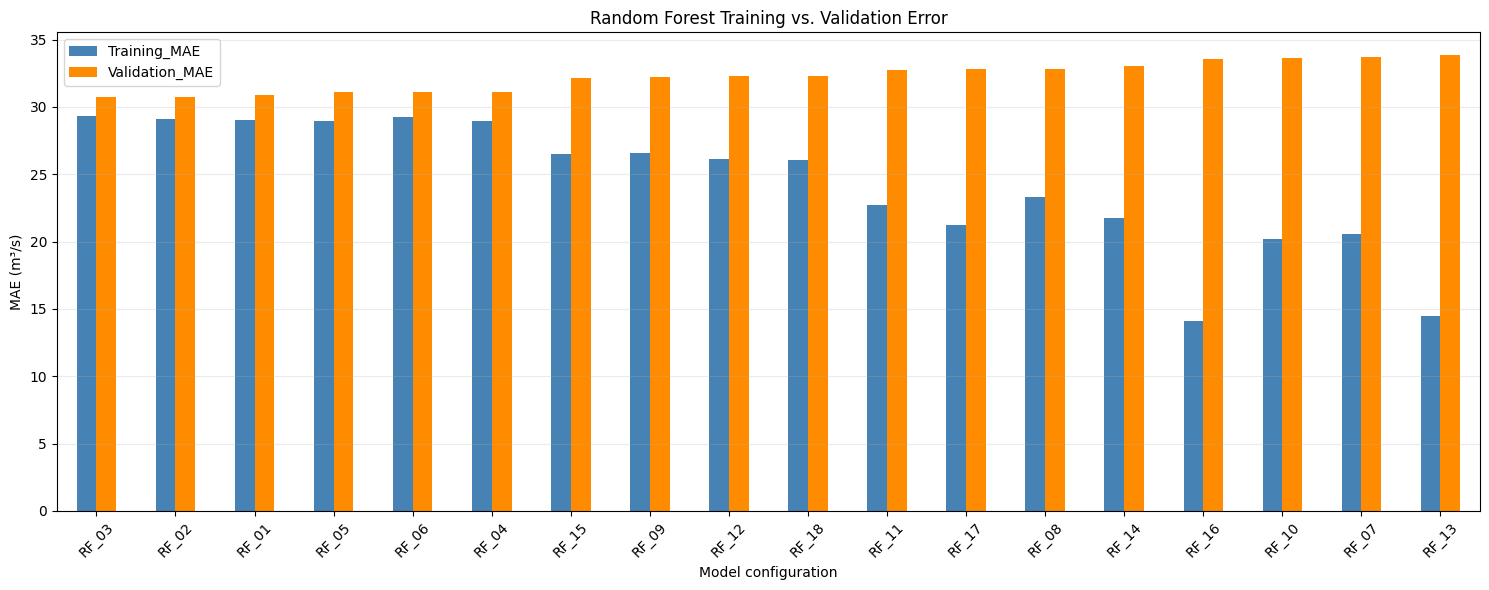

In [37]:
# Visualize training and validation errors

rf_diagnostic_plot = rf_candidate_results.set_index(
    "Model"
)

ax = rf_diagnostic_plot[
    ["Training_MAE", "MAE"]
].rename(
    columns={"MAE": "Validation_MAE"}
).plot(
    kind="bar",
    figsize=(15, 6),
    color=["steelblue", "darkorange"]
)

ax.set_title(
    "Random Forest Training vs. Validation Error"
)

ax.set_xlabel("Model configuration")
ax.set_ylabel("MAE (m³/s)")

ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "random_forest_generalization_gap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [39]:
#  XGBOOST REGRESSION

from xgboost import XGBRegressor
from sklearn.model_selection import ParameterGrid

# Define candidate hyperparameters
xgb_param_grid = {
    "n_estimators": [100, 300],
    "max_depth": [1, 2, 3],
    "learning_rate": [0.03, 0.10],
    "min_child_weight": [1, 10]
}

xgb_candidates = list(
    ParameterGrid(xgb_param_grid)
)

xgb_records = []
xgb_models = {}
xgb_predictions = {}

print("Number of XGBoost configurations:",
      len(xgb_candidates))

# Evaluate candidate configurations
for i, params in enumerate(xgb_candidates, start=1):

    model_name = f"XGB_{i:02d}"

    print(f"Evaluating {model_name}...")

    # Define XGBoost model
    model = XGBRegressor(
        **params,
        objective="reg:squarederror",
        subsample=0.8,
        colsample_bytree=1.0,
        reg_lambda=1.0,
        reg_alpha=0.0,
        gamma=0.0,
        importance_type="gain",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0
    )

    # Train using historical training data only
    model.fit(X_train, y_train)

    # Generate training predictions
    training_predictions = pd.Series(
        model.predict(X_train),
        index=y_train.index
    )

    # Generate validation predictions
    predictions = pd.Series(
        model.predict(X_val),
        index=y_val.index,
        name="XGBoost"
    )

    # Calculate training metrics
    training_metrics = calculate_forecasting_metrics(
        y_train,
        training_predictions
    )

    # Calculate validation metrics
    val_metrics = calculate_forecasting_metrics(
        y_val,
        predictions
    )

    # Calculate generalization gap
    generalization_gap = (
        val_metrics["MAE"]
        - training_metrics["MAE"]
    )

    # Store candidate results
    xgb_records.append({
        "Model": model_name,
        **params,
        "Training_MAE": training_metrics["MAE"],
        "Generalization_Gap": generalization_gap,
        "Negative_predictions": (
            predictions < 0
        ).sum(),
        **val_metrics
    })

    # Store trained model and predictions
    xgb_models[model_name] = model
    xgb_predictions[model_name] = predictions

    print(
        f"Validation MAE: {val_metrics['MAE']:.4f}"
    )


# Create candidate comparison table
xgb_candidate_results = (
    pd.DataFrame(xgb_records)
    .sort_values(["MAE", "RMSE"])
    .reset_index(drop=True)
)

print("\nXGBoost candidate comparison:")

display(xgb_candidate_results.round(4))

# Select best configuration
best_xgb_name = xgb_candidate_results.iloc[0]["Model"]

best_xgb_model = xgb_models[best_xgb_name]

print("\nSelected XGBoost model:")
print(best_xgb_name)

print("\nSelected hyperparameters:")

display(
    xgb_candidate_results.iloc[[0]][
        list(xgb_param_grid.keys())
    ]
)

# Add selected forecasts to validation table
validation_predictions["XGBoost"] = (
    xgb_predictions[best_xgb_name]
)

# Verify prediction completeness
assert len(validation_predictions) == 72

assert not validation_predictions.isna().any().any()

# Save candidate results
xgb_candidate_results.to_csv(
    OUTPUT_DIR / "xgboost_candidate_results.csv",
    index=False
)

# Save selected XGBoost model
best_xgb_model.save_model(
    str(OUTPUT_DIR / "best_xgboost_model.json")
)

print("\nXGBoost model evaluation completed successfully.")

Number of XGBoost configurations: 24
Evaluating XGB_01...
Validation MAE: 30.0769
Evaluating XGB_02...
Validation MAE: 31.9069
Evaluating XGB_03...
Validation MAE: 30.0647
Evaluating XGB_04...
Validation MAE: 31.7371
Evaluating XGB_05...
Validation MAE: 31.3819
Evaluating XGB_06...
Validation MAE: 33.8862
Evaluating XGB_07...
Validation MAE: 31.3981
Evaluating XGB_08...
Validation MAE: 33.9993
Evaluating XGB_09...
Validation MAE: 32.3032
Evaluating XGB_10...
Validation MAE: 35.6758
Evaluating XGB_11...
Validation MAE: 32.3575
Evaluating XGB_12...
Validation MAE: 35.7942
Evaluating XGB_13...
Validation MAE: 32.0426
Evaluating XGB_14...
Validation MAE: 33.6132
Evaluating XGB_15...
Validation MAE: 31.9767
Evaluating XGB_16...
Validation MAE: 33.3507
Evaluating XGB_17...
Validation MAE: 34.4088
Evaluating XGB_18...
Validation MAE: 36.8048
Evaluating XGB_19...
Validation MAE: 34.3290
Evaluating XGB_20...
Validation MAE: 37.7500
Evaluating XGB_21...
Validation MAE: 35.4982
Evaluating XGB_22.

,Model,learning_rate,max_depth,min_child_weight,n_estimators,Training_MAE,Generalization_Gap,Negative_predictions,MAE,RMSE,Bias,NSE,KGE,KGE_r,KGE_alpha,KGE_beta
0,XGB_03,0.03,1,10,100,31.5340,-1.4693,0,30.0647,39.7585,-9.1435,0.5452,0.5692,0.7635,0.6468,0.9299
1,XGB_01,0.03,1,1,100,31.5425,-1.4656,0,30.0769,39.7709,-9.0432,0.5450,0.5697,0.7627,0.6479,0.9307
2,XGB_05,0.03,2,1,100,28.5290,2.8530,0,31.3819,40.4939,-7.8510,0.5283,0.6040,0.7396,0.7078,0.9398
3,XGB_07,0.03,2,10,100,28.6363,2.7618,0,31.3981,40.4191,-7.4371,0.5300,0.6085,0.7393,0.7136,0.9430
4,XGB_04,0.03,1,10,300,28.9816,2.7555,0,31.7371,40.0085,-5.8412,0.5395,0.6419,0.7413,0.7564,0.9552
5,XGB_02,0.03,1,1,300,28.8585,3.0483,0,31.9069,40.2681,-6.2782,0.5335,0.6372,0.7383,0.7534,0.9519
6,XGB_15,0.10,1,10,100,28.7489,3.2278,0,31.9767,40.0364,-5.3664,0.5389,0.6554,0.7406,0.7769,0.9589
7,XGB_13,0.10,1,1,100,28.6321,3.4105,0,32.0426,40.2606,-6.0139,0.5337,0.6543,0.7387,0.7784,0.9539
8,XGB_09,0.03,3,1,100,24.8366,7.4667,0,32.3032,41.4030,-7.3562,0.5068,0.6317,0.7238,0.7629,0.9436
9,XGB_11,0.03,3,10,100,25.6101,6.7474,0,32.3575,41.3969,-7.0326,0.5070,0.6164,0.7222,0.7410,0.9461



Selected XGBoost model:
XGB_03

Selected hyperparameters:


,n_estimators,max_depth,learning_rate,min_child_weight
0,100,1,0.03,10



XGBoost model evaluation completed successfully.


In [40]:
# Compare all forecasting models

COMPARISON_MODELS = BASELINE_MODELS + [
    "SARIMA",
    "Random Forest",
    "XGBoost"
]

comparison_records = []

for model in COMPARISON_MODELS:

    metrics = calculate_forecasting_metrics(
        validation_predictions["Observed"],
        validation_predictions[model]
    )

    comparison_records.append({
        "Model": model,
        **metrics
    })

# Create final validation comparison
validation_results = (
    pd.DataFrame(comparison_records)
    .set_index("Model")
    .sort_values("MAE")
)

# Calculate skill relative to monthly climatology
reference_mae = validation_results.loc[
    "Monthly Climatology", "MAE"
]

validation_results["Skill_MAE"] = (
    1 - validation_results["MAE"] / reference_mae
)

print("\nUpdated forecasting performance:")
display(validation_results.round(4))

# Calculate XGBoost feature importance
xgb_feature_importance = pd.DataFrame({
    "Feature": FEATURE_COLUMNS,
    "Importance": best_xgb_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

print("\nXGBoost feature importance:")
display(xgb_feature_importance.round(4))

# Display selected model diagnostics
best_xgb_diagnostics = xgb_candidate_results.iloc[0]

print("\nSelected model diagnostics:")

print(
    f"Training MAE: "
    f"{best_xgb_diagnostics['Training_MAE']:.4f}"
)

print(
    f"Validation MAE: "
    f"{best_xgb_diagnostics['MAE']:.4f}"
)

print(
    f"Generalization gap: "
    f"{best_xgb_diagnostics['Generalization_Gap']:.4f}"
)

print(
    f"Negative predictions: "
    f"{best_xgb_diagnostics['Negative_predictions']}"
)

# Save results
validation_results.to_csv(
    OUTPUT_DIR / "validation_model_comparison.csv"
)

validation_predictions.to_csv(
    OUTPUT_DIR / "validation_model_predictions.csv"
)

xgb_feature_importance.to_csv(
    OUTPUT_DIR / "xgboost_feature_importance.csv",
    index=False
)

print("\nXGBoost comparison saved successfully.")


Updated forecasting performance:


,MAE,RMSE,Bias,NSE,KGE,KGE_r,KGE_alpha,KGE_beta,Skill_MAE
Model,,,,,,,,,
XGBoost,30.0647,39.7585,-9.1435,0.5452,0.5692,0.7635,0.6468,0.9299,0.0639
Random Forest,30.7046,39.9524,-7.2733,0.5408,0.6471,0.7458,0.7616,0.9442,0.0440
Monthly Climatology,32.1165,41.9397,-12.7687,0.4940,0.6250,0.7356,0.7528,0.9021,0.0000
SARIMA,33.0303,42.7382,-9.1372,0.4745,0.6222,0.7087,0.7699,0.9299,-0.0285
Seasonal Naive,46.0356,59.9809,3.1421,-0.0350,0.5197,0.5280,1.0857,1.0241,-0.4334
Persistence,46.7860,62.5590,0.1680,-0.1259,0.4348,0.4348,0.9961,1.0013,-0.4568



XGBoost feature importance:


,Feature,Importance
8,month_cos,0.4701
0,lag_1,0.1789
4,lag_12,0.1245
5,rolling_mean_3,0.0636
7,month_sin,0.0606
1,lag_2,0.0582
3,lag_6,0.0441
2,lag_3,0.0000
6,rolling_mean_6,0.0000



Selected model diagnostics:
Training MAE: 31.5340
Validation MAE: 30.0647
Generalization gap: -1.4693
Negative predictions: 0

XGBoost comparison saved successfully.


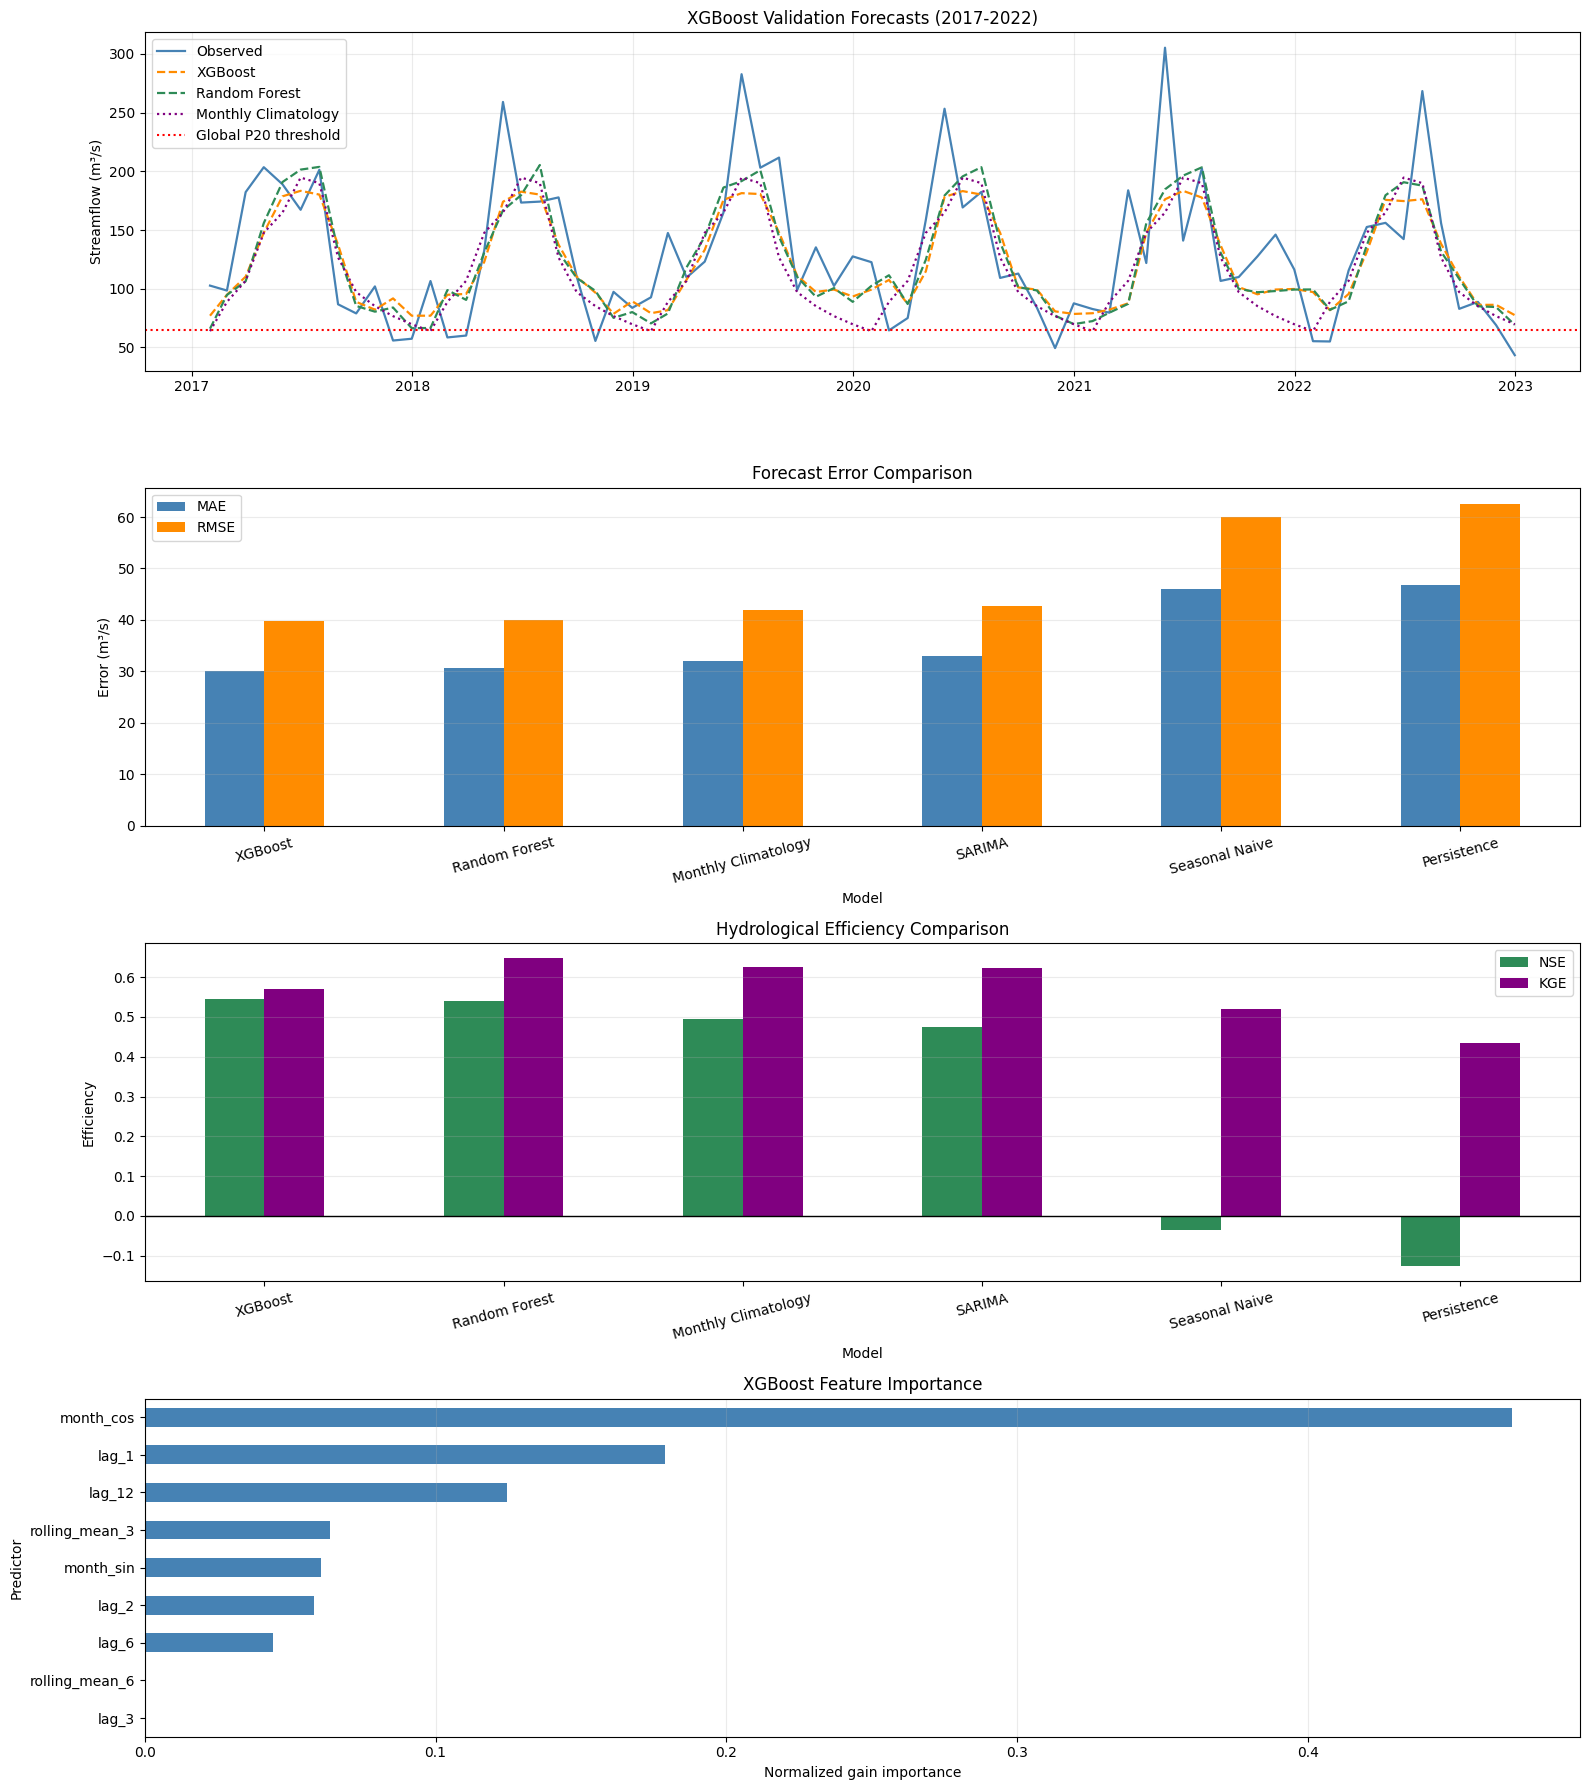

In [41]:
# Visualize XGBoost forecasting results

fig, axes = plt.subplots(
    4, 1,
    figsize=(16, 18)
)

# Compare observed and predicted streamflow
for model, color, style in [
    ("Observed", "steelblue", "-"),
    ("XGBoost", "darkorange", "--"),
    ("Random Forest", "seagreen", "--"),
    ("Monthly Climatology", "purple", ":")
]:

    axes[0].plot(
        validation_predictions.index,
        validation_predictions[model],
        color=color,
        linestyle=style,
        linewidth=1.6,
        label=model
    )

axes[0].axhline(
    train["streamflow"].quantile(0.20),
    color="red",
    linestyle=":",
    label="Global P20 threshold"
)

axes[0].set_title(
    "XGBoost Validation Forecasts (2017-2022)"
)

axes[0].set_ylabel("Streamflow (m³/s)")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Compare forecasting errors
validation_results[["MAE", "RMSE"]].plot(
    kind="bar",
    ax=axes[1],
    color=["steelblue", "darkorange"]
)

axes[1].set_title("Forecast Error Comparison")
axes[1].set_ylabel("Error (m³/s)")
axes[1].tick_params(axis="x", rotation=15)
axes[1].grid(axis="y", alpha=0.25)

# Compare hydrological efficiency
validation_results[["NSE", "KGE"]].plot(
    kind="bar",
    ax=axes[2],
    color=["seagreen", "purple"]
)

axes[2].axhline(
    0,
    color="black",
    linewidth=1
)

axes[2].set_title("Hydrological Efficiency Comparison")
axes[2].set_ylabel("Efficiency")
axes[2].tick_params(axis="x", rotation=15)
axes[2].grid(axis="y", alpha=0.25)

# Visualize feature importance
xgb_feature_importance.sort_values(
    "Importance"
).plot(
    kind="barh",
    x="Feature",
    y="Importance",
    ax=axes[3],
    color="steelblue",
    legend=False
)

axes[3].set_title("XGBoost Feature Importance")
axes[3].set_xlabel("Normalized gain importance")
axes[3].set_ylabel("Predictor")
axes[3].grid(axis="x", alpha=0.25)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "xgboost_validation_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
#  ABLATION STUDY

from sklearn.base import clone

# Define experimental feature subsets
ABLATION_FEATURES = {
    "E0 - Full model": FEATURE_COLUMNS.copy(),

    "E1 - Lag 1 only": [
        "lag_1"
    ],

    "E2 - Short-term lags": [
        "lag_1", "lag_2", "lag_3"
    ],

    "E3 - All lags": [
        "lag_1", "lag_2", "lag_3",
        "lag_6", "lag_12"
    ],

    "E4 - No rolling means": [
        feature for feature in FEATURE_COLUMNS
        if not feature.startswith("rolling_mean")
    ],

    "E5 - No calendar": [
        feature for feature in FEATURE_COLUMNS
        if feature not in ["month_sin", "month_cos"]
    ],

    "E6 - No lag 12": [
        feature for feature in FEATURE_COLUMNS
        if feature != "lag_12"
    ],

    "E7 - Top 3 features": [
        "lag_1", "lag_12", "month_cos"
    ],

    "E8 - Calendar only": [
        "month_sin", "month_cos"
    ]
}

# Define selected model configurations
ablation_base_models = {
    "Random Forest": best_rf_model,
    "XGBoost": best_xgb_model
}

# Initialize result containers
ablation_records = []
ablation_models = {}
ablation_predictions = {}

print("Number of feature configurations:",
      len(ABLATION_FEATURES))

print("Total experiments:",
      len(ABLATION_FEATURES) * len(ablation_base_models))

# Evaluate each model
for model_name, base_model in ablation_base_models.items():

    print(f"\nEvaluating {model_name}:")

    for experiment, features in ABLATION_FEATURES.items():

        # Create an independent unfitted model
        model = clone(base_model)

        # Select the corresponding features
        X_train_subset = X_train[features]
        X_val_subset = X_val[features]

        # Train using historical training data
        model.fit(X_train_subset, y_train)

        # Generate training predictions
        training_predictions = pd.Series(
            model.predict(X_train_subset),
            index=y_train.index
        )

        # Generate validation predictions
        predictions = pd.Series(
            model.predict(X_val_subset),
            index=y_val.index
        )

        # Calculate training metrics
        train_metrics = calculate_forecasting_metrics(
            y_train,
            training_predictions
        )

        # Calculate validation metrics
        val_metrics = calculate_forecasting_metrics(
            y_val,
            predictions
        )

        # Verify full-model reproducibility
        if experiment == "E0 - Full model":

            np.testing.assert_allclose(
                predictions.to_numpy(),
                validation_predictions[model_name].to_numpy(),
                rtol=1e-5,
                atol=1e-4
            )

        # Store experiment results
        ablation_records.append({
            "Model": model_name,
            "Experiment": experiment,
            "Number_of_features": len(features),
            "Features": ", ".join(features),
            "Training_MAE": train_metrics["MAE"],
            "Generalization_Gap": (
                val_metrics["MAE"]
                - train_metrics["MAE"]
            ),
            "Negative_predictions": int(
                (predictions < 0).sum()
            ),
            **val_metrics
        })

        # Store fitted models and predictions
        ablation_models[(model_name, experiment)] = model

        ablation_predictions[
            (model_name, experiment)
        ] = predictions

        print(
            f"{experiment}: "
            f"MAE = {val_metrics['MAE']:.4f}"
        )

# Create experiment results table
ablation_results = pd.DataFrame(ablation_records)

# Verify experiment completeness
assert len(ablation_results) == 18

print("\nAll ablation experiments completed successfully.")

Number of feature configurations: 9
Total experiments: 18

Evaluating Random Forest:
E0 - Full model: MAE = 30.7046
E1 - Lag 1 only: MAE = 37.8954
E2 - Short-term lags: MAE = 37.9794
E3 - All lags: MAE = 31.8913
E4 - No rolling means: MAE = 30.6615
E5 - No calendar: MAE = 32.7441
E6 - No lag 12: MAE = 30.8282
E7 - Top 3 features: MAE = 30.1966
E8 - Calendar only: MAE = 31.0450

Evaluating XGBoost:
E0 - Full model: MAE = 30.0647
E1 - Lag 1 only: MAE = 38.3443
E2 - Short-term lags: MAE = 37.9827
E3 - All lags: MAE = 32.2698
E4 - No rolling means: MAE = 30.0721
E5 - No calendar: MAE = 32.2827
E6 - No lag 12: MAE = 30.5254
E7 - Top 3 features: MAE = 30.0883
E8 - Calendar only: MAE = 30.8769

All ablation experiments completed successfully.


In [43]:
# Calculate performance changes relative to the full model

# Retrieve the full-model MAE for each algorithm
full_model_mae = (
    ablation_results.loc[
        ablation_results["Experiment"] == "E0 - Full model"
    ]
    .set_index("Model")["MAE"]
)

# Assign the corresponding reference MAE
ablation_results["Full_Model_MAE"] = (
    ablation_results["Model"].map(full_model_mae)
)

# Calculate absolute MAE variation
ablation_results["Delta_MAE"] = (
    ablation_results["MAE"]
    - ablation_results["Full_Model_MAE"]
)

# Calculate percentage MAE variation
ablation_results["Delta_MAE_Percent"] = (
    ablation_results["Delta_MAE"]
    / ablation_results["Full_Model_MAE"]
) * 100

# Calculate skill relative to monthly climatology
climatology_mae = validation_results.loc[
    "Monthly Climatology", "MAE"
]

ablation_results["Skill_MAE"] = (
    1 - ablation_results["MAE"] / climatology_mae
)

# Define summary columns
summary_columns = [
    "Model",
    "Experiment",
    "Number_of_features",
    "Training_MAE",
    "MAE",
    "RMSE",
    "Bias",
    "NSE",
    "KGE",
    "Generalization_Gap",
    "Delta_MAE",
    "Delta_MAE_Percent",
    "Skill_MAE"
]

# Display results for each algorithm
for model_name in ablation_base_models:

    print(f"\nAblation results - {model_name}:")

    model_results = ablation_results.loc[
        ablation_results["Model"] == model_name
    ].sort_values("MAE")

    display(
        model_results[summary_columns].round(4)
    )

# Identify the best experimental configuration
best_ablation_results = (
    ablation_results
    .sort_values(["MAE", "RMSE"])
    .groupby("Model", sort=False)
    .head(1)
    .reset_index(drop=True)
)

print("\nBest exploratory configuration for each model:")

display(
    best_ablation_results[summary_columns].round(4)
)

# Create comparative MAE table
ablation_mae_comparison = ablation_results.pivot(
    index="Experiment",
    columns="Model",
    values="MAE"
).reindex(list(ABLATION_FEATURES.keys()))

print("\nComparative ablation MAE:")
display(ablation_mae_comparison.round(4))

# Save experiment predictions
ablation_prediction_table = pd.DataFrame(
    {"Observed": y_val}
)

for (model_name, experiment), predictions in ablation_predictions.items():

    column_name = f"{model_name} | {experiment}"

    ablation_prediction_table[column_name] = predictions

# Save experimental results
ablation_results.to_csv(
    OUTPUT_DIR / "ablation_study_results.csv",
    index=False
)

best_ablation_results.to_csv(
    OUTPUT_DIR / "best_ablation_configurations.csv",
    index=False
)

ablation_mae_comparison.to_csv(
    OUTPUT_DIR / "ablation_mae_comparison.csv"
)

ablation_prediction_table.to_csv(
    OUTPUT_DIR / "ablation_validation_predictions.csv"
)

print("\nAblation study results saved successfully.")


Ablation results - Random Forest:


,Model,Experiment,Number_of_features,Training_MAE,MAE,RMSE,Bias,NSE,KGE,Generalization_Gap,Delta_MAE,Delta_MAE_Percent,Skill_MAE
7,Random Forest,E7 - Top 3 features,3,30.6502,30.1966,38.9774,-7.6276,0.5629,0.6458,-0.4536,-0.5080,-1.6546,0.0598
4,Random Forest,E4 - No rolling means,7,29.5932,30.6615,39.6974,-7.4190,0.5466,0.6491,1.0683,-0.0431,-0.1404,0.0453
0,Random Forest,E0 - Full model,9,29.3559,30.7046,39.9524,-7.2733,0.5408,0.6471,1.3487,0.0000,0.0000,0.0440
6,Random Forest,E6 - No lag 12,8,29.2690,30.8282,40.4888,-8.3800,0.5284,0.6305,1.5592,0.1237,0.4027,0.0401
8,Random Forest,E8 - Calendar only,2,32.4051,31.0450,41.6118,-13.0776,0.5019,0.5583,-1.3601,0.3404,1.1087,0.0334
3,Random Forest,E3 - All lags,5,32.1266,31.8913,42.9150,-5.7297,0.4702,0.5478,-0.2352,1.1868,3.8651,0.0070
5,Random Forest,E5 - No calendar,7,31.3744,32.7441,43.2793,-6.4076,0.4611,0.5371,1.3697,2.0395,6.6424,-0.0195
1,Random Forest,E1 - Lag 1 only,1,37.4567,37.8954,50.5239,-1.6669,0.2656,0.3667,0.4387,7.1908,23.4192,-0.1799
2,Random Forest,E2 - Short-term lags,3,35.6721,37.9794,50.1431,-3.5906,0.2767,0.3576,2.3073,7.2748,23.6929,-0.1826



Ablation results - XGBoost:


,Model,Experiment,Number_of_features,Training_MAE,MAE,RMSE,Bias,NSE,KGE,Generalization_Gap,Delta_MAE,Delta_MAE_Percent,Skill_MAE
9,XGBoost,E0 - Full model,9,31.5340,30.0647,39.7585,-9.1435,0.5452,0.5692,-1.4693,0.0000,0.0000,0.0639
13,XGBoost,E4 - No rolling means,7,31.5198,30.0721,39.6866,-9.2996,0.5469,0.5713,-1.4476,0.0074,0.0246,0.0637
16,XGBoost,E7 - Top 3 features,3,31.5621,30.0883,39.5447,-9.2791,0.5501,0.5786,-1.4737,0.0236,0.0785,0.0632
15,XGBoost,E6 - No lag 12,8,31.6706,30.5254,40.5692,-10.1156,0.5265,0.5572,-1.1451,0.4607,1.5323,0.0495
17,XGBoost,E8 - Calendar only,2,32.6502,30.8769,40.8645,-13.1418,0.5196,0.5717,-1.7732,0.8122,2.7015,0.0386
12,XGBoost,E3 - All lags,5,33.7258,32.2698,43.3994,-6.3012,0.4581,0.4936,-1.4561,2.2050,7.3343,-0.0048
14,XGBoost,E5 - No calendar,7,33.7003,32.2827,43.4179,-6.3517,0.4577,0.4918,-1.4177,2.2179,7.3771,-0.0052
11,XGBoost,E2 - Short-term lags,3,37.6573,37.9827,50.4611,-5.1879,0.2675,0.3120,0.3254,7.9179,26.3363,-0.1827
10,XGBoost,E1 - Lag 1 only,1,38.0681,38.3443,50.9798,-4.2457,0.2523,0.3128,0.2762,8.2796,27.5391,-0.1939



Best exploratory configuration for each model:


,Model,Experiment,Number_of_features,Training_MAE,MAE,RMSE,Bias,NSE,KGE,Generalization_Gap,Delta_MAE,Delta_MAE_Percent,Skill_MAE
0,XGBoost,E0 - Full model,9,31.5340,30.0647,39.7585,-9.1435,0.5452,0.5692,-1.4693,0.000,0.0000,0.0639
1,Random Forest,E7 - Top 3 features,3,30.6502,30.1966,38.9774,-7.6276,0.5629,0.6458,-0.4536,-0.508,-1.6546,0.0598



Comparative ablation MAE:


Model,Random Forest,XGBoost
Experiment,,
E0 - Full model,30.7046,30.0647
E1 - Lag 1 only,37.8954,38.3443
E2 - Short-term lags,37.9794,37.9827
E3 - All lags,31.8913,32.2698
E4 - No rolling means,30.6615,30.0721
E5 - No calendar,32.7441,32.2827
E6 - No lag 12,30.8282,30.5254
E7 - Top 3 features,30.1966,30.0883
E8 - Calendar only,31.0450,30.8769



Ablation study results saved successfully.


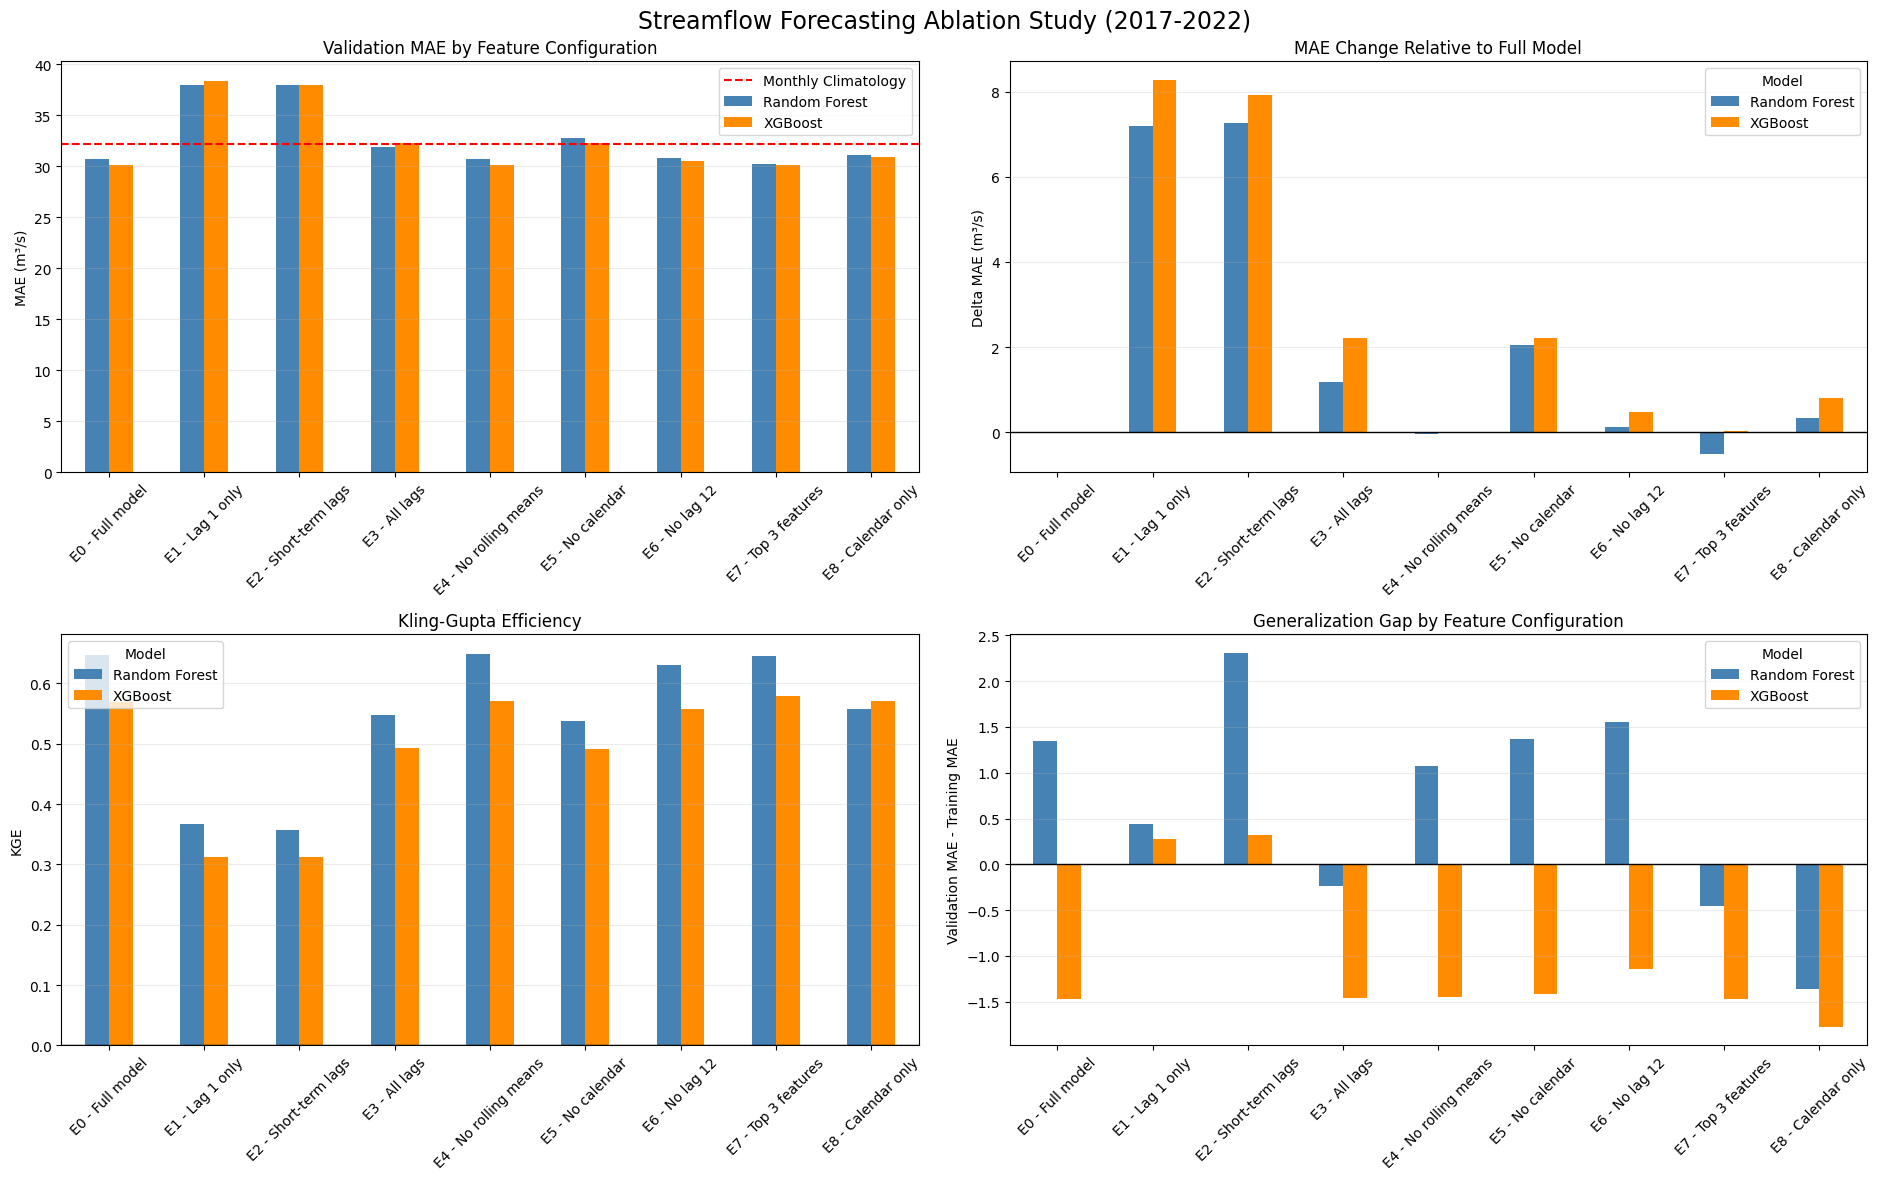

In [44]:
# Visualize ablation study results

fig, axes = plt.subplots(
    2, 2,
    figsize=(19, 12)
)

experiment_order = list(ABLATION_FEATURES.keys())

# Compare validation MAE
ablation_mae_comparison.plot(
    kind="bar",
    ax=axes[0, 0],
    color=["steelblue", "darkorange"]
)

axes[0, 0].axhline(
    climatology_mae,
    color="red",
    linestyle="--",
    label="Monthly Climatology"
)

axes[0, 0].set_title("Validation MAE by Feature Configuration")
axes[0, 0].set_ylabel("MAE (m³/s)")
axes[0, 0].set_xlabel("")
axes[0, 0].legend()

# Compare MAE changes relative to full models
delta_comparison = ablation_results.pivot(
    index="Experiment",
    columns="Model",
    values="Delta_MAE"
).reindex(experiment_order)

delta_comparison.plot(
    kind="bar",
    ax=axes[0, 1],
    color=["steelblue", "darkorange"]
)

axes[0, 1].axhline(
    0,
    color="black",
    linewidth=1
)

axes[0, 1].set_title("MAE Change Relative to Full Model")
axes[0, 1].set_ylabel("Delta MAE (m³/s)")
axes[0, 1].set_xlabel("")

# Compare Kling-Gupta Efficiency
kge_comparison = ablation_results.pivot(
    index="Experiment",
    columns="Model",
    values="KGE"
).reindex(experiment_order)

kge_comparison.plot(
    kind="bar",
    ax=axes[1, 0],
    color=["steelblue", "darkorange"]
)

axes[1, 0].axhline(
    0,
    color="black",
    linewidth=1
)

axes[1, 0].set_title("Kling-Gupta Efficiency")
axes[1, 0].set_ylabel("KGE")
axes[1, 0].set_xlabel("")

# Compare training-validation gaps
gap_comparison = ablation_results.pivot(
    index="Experiment",
    columns="Model",
    values="Generalization_Gap"
).reindex(experiment_order)

gap_comparison.plot(
    kind="bar",
    ax=axes[1, 1],
    color=["steelblue", "darkorange"]
)

axes[1, 1].axhline(
    0,
    color="black",
    linewidth=1
)

axes[1, 1].set_title("Generalization Gap by Feature Configuration")
axes[1, 1].set_ylabel("Validation MAE - Training MAE")
axes[1, 1].set_xlabel("")

# Configure all plots
for ax in axes.flat:

    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Streamflow Forecasting Ablation Study (2017-2022)",
    fontsize=17
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "ablation_study_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [45]:
# . FINAL MODEL CONFIGURATION AND SELECTION

import json

# Define final machine learning configurations
FINAL_ML_MODELS = {
    "Random Forest Full": {
        "model": ablation_models[
            ("Random Forest", "E0 - Full model")
        ],
        "features": ABLATION_FEATURES[
            "E0 - Full model"
        ]
    },

    "Random Forest Reduced": {
        "model": ablation_models[
            ("Random Forest", "E7 - Top 3 features")
        ],
        "features": ABLATION_FEATURES[
            "E7 - Top 3 features"
        ]
    },

    "XGBoost Full": {
        "model": ablation_models[
            ("XGBoost", "E0 - Full model")
        ],
        "features": ABLATION_FEATURES[
            "E0 - Full model"
        ]
    },

    "XGBoost Reduced": {
        "model": ablation_models[
            ("XGBoost", "E7 - Top 3 features")
        ],
        "features": ABLATION_FEATURES[
            "E7 - Top 3 features"
        ]
    }
}

# Create the final validation prediction table
final_validation_predictions = (
    validation_predictions[
        [
            "Observed",
            "Persistence",
            "Seasonal Naive",
            "Monthly Climatology",
            "SARIMA"
        ]
    ].copy()
)

# Generate forecasts using the selected configurations
for model_name, configuration in FINAL_ML_MODELS.items():

    model = configuration["model"]
    features = configuration["features"]

    final_validation_predictions[model_name] = (
        model.predict(X_val[features])
    )

# Define final model names
FINAL_MODEL_NAMES = [
    column
    for column in final_validation_predictions.columns
    if column != "Observed"
]

# Calculate validation metrics
final_records = []

for model_name in FINAL_MODEL_NAMES:

    metrics = calculate_forecasting_metrics(
        final_validation_predictions["Observed"],
        final_validation_predictions[model_name]
    )

    final_records.append({
        "Model": model_name,
        **metrics
    })

# Create the final validation ranking
final_validation_results = (
    pd.DataFrame(final_records)
    .set_index("Model")
    .sort_values(["MAE", "RMSE"])
)

# Calculate skill relative to monthly climatology
reference_mae = final_validation_results.loc[
    "Monthly Climatology", "MAE"
]

final_validation_results["Skill_MAE"] = (
    1 - final_validation_results["MAE"]
    / reference_mae
)

# Verify the final experimental configuration
assert len(FINAL_MODEL_NAMES) == 8
assert len(final_validation_predictions) == 72

assert np.isfinite(
    final_validation_predictions.to_numpy()
).all()

print("Final validation performance:")

display(final_validation_results.round(4))

# Identify the provisional MAE leader
best_validation_model = (
    final_validation_results.index[0]
)

print("\nBest model according to validation MAE:")
print(best_validation_model)

# Save the selected machine learning models
for model_name, configuration in FINAL_ML_MODELS.items():

    file_name = model_name.lower().replace(" ", "_")

    joblib.dump(
        configuration["model"],
        OUTPUT_DIR / f"{file_name}.pkl"
    )

# Save final validation results
final_validation_results.to_csv(
    OUTPUT_DIR / "final_validation_results.csv"
)

final_validation_predictions.to_csv(
    OUTPUT_DIR / "final_validation_predictions.csv"
)

Final validation performance:


,MAE,RMSE,Bias,NSE,KGE,KGE_r,KGE_alpha,KGE_beta,Skill_MAE
Model,,,,,,,,,
XGBoost Full,30.0647,39.7585,-9.1435,0.5452,0.5692,0.7635,0.6468,0.9299,0.0639
XGBoost Reduced,30.0883,39.5447,-9.2791,0.5501,0.5786,0.7660,0.6568,0.9289,0.0632
Random Forest Reduced,30.1966,38.9774,-7.6276,0.5629,0.6458,0.7615,0.7447,0.9415,0.0598
Random Forest Full,30.7046,39.9524,-7.2733,0.5408,0.6471,0.7458,0.7616,0.9442,0.0440
Monthly Climatology,32.1165,41.9397,-12.7687,0.4940,0.6250,0.7356,0.7528,0.9021,0.0000
SARIMA,33.0303,42.7382,-9.1372,0.4745,0.6222,0.7087,0.7699,0.9299,-0.0285
Seasonal Naive,46.0356,59.9809,3.1421,-0.0350,0.5197,0.5280,1.0857,1.0241,-0.4334
Persistence,46.7860,62.5590,0.1680,-0.1259,0.4348,0.4348,0.9961,1.0013,-0.4568



Best model according to validation MAE:
XGBoost Full


In [46]:
# Freeze the experimental protocol

EXPERIMENT_PROTOCOL = {
    "random_state": RANDOM_STATE,

    "forecast_horizon_months": 1,

    "training_period": "1984-2016",
    "validation_period": "2017-2022",
    "testing_period": "2023-2024",
    "complementary_period": "2025",

    "training_observations": len(train),
    "ml_training_observations": len(X_train),

    "selection_metric": "MAE",
    "tie_breaker": "RMSE",

    "low_flow_percentile": 0.20,
    "low_flow_methods": [
        "Global",
        "Seasonal"
    ],

    "parameter_update_policy": "Fixed parameters",

    "sarima_update_policy": (
        "Update state after observing each target"
    ),

    "test_retuning": False,

    "negative_forecast_policy": (
        "Report without silent clipping"
    ),

    "final_models": FINAL_MODEL_NAMES,

    "sarima_configuration": {
        "order": list(
            best_sarima_model.model.order
        ),
        "seasonal_order": list(
            best_sarima_model.model.seasonal_order
        )
    },

    "machine_learning_configurations": {
        name: {
            "features": configuration["features"],
            "hyperparameters": (
                configuration["model"].get_params()
            )
        }
        for name, configuration
        in FINAL_ML_MODELS.items()
    }
}

# Save the experimental protocol
with open(
    OUTPUT_DIR / "experimental_protocol.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        EXPERIMENT_PROTOCOL,
        file,
        indent=4,
        default=str
    )

print("\nExperimental protocol saved successfully.")
print("Number of final models:", len(FINAL_MODEL_NAMES))
print("Test data used for model selection: No")
print("Final model configuration: COMPLETED")


Experimental protocol saved successfully.
Number of final models: 8
Test data used for model selection: No
Final model configuration: COMPLETED


In [47]:
#  OUT-OF-SAMPLE TEMPORAL EVALUATION

# Verify that the experimental protocol was saved
protocol_path = OUTPUT_DIR / "experimental_protocol.json"

assert protocol_path.exists(), (
    "Execute Cell 22 completely before continuing."
)

with open(protocol_path, "r", encoding="utf-8") as file:
    saved_protocol = json.load(file)

assert saved_protocol["final_models"] == FINAL_MODEL_NAMES
assert saved_protocol["test_retuning"] is False

# Combine testing and complementary periods
evaluation_features = pd.concat(
    [X_test, X_comp]
)

evaluation_observed = pd.concat(
    [y_test, y_comp]
)

# Create the evaluation prediction table
evaluation_predictions = pd.DataFrame({
    "Observed": evaluation_observed
})

# Generate baseline forecasts
evaluation_predictions["Persistence"] = (
    evaluation_features["lag_1"]
)

evaluation_predictions["Seasonal Naive"] = (
    evaluation_features["lag_12"]
)

evaluation_predictions["Monthly Climatology"] = (
    evaluation_predictions.index.month.map(
        monthly_climatology
    )
)

# Update SARIMA state through December 2022
sarima_updated_model = best_sarima_model.extend(
    sarima_val
)

# Generate sequential SARIMA forecasts
sarima_evaluation_series = (
    evaluation_observed.asfreq("ME")
)

evaluation_predictions["SARIMA"] = (
    rolling_sarima_forecast(
        sarima_updated_model,
        sarima_evaluation_series
    )
)

# Generate machine learning forecasts
for model_name, configuration in FINAL_ML_MODELS.items():

    model = configuration["model"]
    features = configuration["features"]

    evaluation_predictions[model_name] = (
        model.predict(
            evaluation_features[features]
        )
    )

# Verify evaluation completeness
assert len(evaluation_predictions) == 36

assert evaluation_predictions.index.is_unique

assert evaluation_predictions.index.is_monotonic_increasing

assert np.isfinite(
    evaluation_predictions.to_numpy()
).all()

# Separate testing and complementary forecasts
test_predictions = evaluation_predictions.loc[
    TEST_START:TEST_END
].copy()

complementary_predictions = evaluation_predictions.loc[
    COMPLEMENTARY_START:COMPLEMENTARY_END
].copy()

assert len(test_predictions) == 24
assert len(complementary_predictions) == 12

print("Temporal forecasts generated successfully.")
print("Testing observations:", len(test_predictions))
print("Complementary observations:",
      len(complementary_predictions))

print("\nFirst five testing forecasts:")
display(test_predictions.head().round(4))

Temporal forecasts generated successfully.
Testing observations: 24
Complementary observations: 12

First five testing forecasts:


,Observed,Persistence,Seasonal Naive,Monthly Climatology,SARIMA,Random Forest Full,Random Forest Reduced,XGBoost Full,XGBoost Reduced
date,,,,,,,,,
2023-01-31,64.3940,43.4533,55.3588,63.9031,61.9903,65.3354,66.1089,74.985397,74.798599
2023-02-28,54.1468,64.3940,55.1167,88.8050,87.0984,71.7954,75.1084,79.650497,80.382301
2023-03-31,98.4724,54.1468,115.6570,106.7792,101.3997,86.6497,83.3525,84.109497,84.353798
2023-04-30,133.6341,98.4724,152.5586,147.6142,145.4359,133.2821,137.4635,137.575806,138.773102
2023-05-31,130.9289,133.6341,156.1005,164.8693,170.4515,168.2441,183.8306,174.595200,176.754196


In [48]:
# Evaluate forecasting performance by period

def evaluate_forecast_period(predictions, period_name):

    records = []

    for model_name in FINAL_MODEL_NAMES:

        metrics = calculate_forecasting_metrics(
            predictions["Observed"],
            predictions[model_name]
        )

        records.append({
            "Model": model_name,
            "Period": period_name,
            "Observations": len(predictions),
            "Negative_predictions": int(
                (predictions[model_name] < 0).sum()
            ),
            **metrics
        })

    results = (
        pd.DataFrame(records)
        .set_index("Model")
        .sort_values(["MAE", "RMSE"])
    )

    # Calculate skill relative to monthly climatology
    reference_mae = results.loc[
        "Monthly Climatology", "MAE"
    ]

    results["Skill_MAE"] = (
        1 - results["MAE"] / reference_mae
        if reference_mae > 0
        else np.nan
    )

    return results


# Evaluate the testing period
test_results = evaluate_forecast_period(
    test_predictions,
    "2023-2024"
)

# Evaluate the complementary period
complementary_results = evaluate_forecast_period(
    complementary_predictions,
    "2025"
)

print("Testing performance (2023-2024):")
display(test_results.round(4))

print("\nComplementary performance (2025):")
display(complementary_results.round(4))

# Compare MAE across the three evaluation periods
temporal_mae_comparison = pd.DataFrame({
    "Validation_2017_2022": (
        final_validation_results["MAE"]
    ),
    "Testing_2023_2024": test_results["MAE"],
    "Complementary_2025": complementary_results["MAE"]
})

# Calculate changes relative to validation
temporal_mae_comparison["Test_MAE_Change"] = (
    temporal_mae_comparison["Testing_2023_2024"]
    - temporal_mae_comparison["Validation_2017_2022"]
)

temporal_mae_comparison["Complementary_MAE_Change"] = (
    temporal_mae_comparison["Complementary_2025"]
    - temporal_mae_comparison["Validation_2017_2022"]
)

print("\nTemporal MAE comparison:")
display(temporal_mae_comparison.round(4))

# Save all results
test_predictions.to_csv(
    OUTPUT_DIR / "test_predictions_2023_2024.csv"
)

complementary_predictions.to_csv(
    OUTPUT_DIR / "complementary_predictions_2025.csv"
)

test_results.to_csv(
    OUTPUT_DIR / "test_results_2023_2024.csv"
)

complementary_results.to_csv(
    OUTPUT_DIR / "complementary_results_2025.csv"
)

temporal_mae_comparison.to_csv(
    OUTPUT_DIR / "temporal_mae_comparison.csv"
)

print("\nTemporal evaluation completed successfully.")

Testing performance (2023-2024):


,Period,Observations,Negative_predictions,MAE,RMSE,Bias,NSE,KGE,KGE_r,KGE_alpha,KGE_beta,Skill_MAE
Model,,,,,,,,,,,,
Persistence,2023-2024,24,0,24.5322,31.0309,-0.7600,0.4130,0.7106,0.7111,1.0149,0.9911,0.3069
Random Forest Full,2023-2024,24,0,28.3614,35.7109,24.3194,0.2226,0.6501,0.8030,1.0514,1.2846,0.1987
XGBoost Full,2023-2024,24,0,29.2023,35.6517,26.6182,0.2252,0.6427,0.8257,0.9830,1.3115,0.1749
SARIMA,2023-2024,24,0,29.2806,35.8990,26.1072,0.2144,0.6428,0.8302,1.0738,1.3055,0.1727
Seasonal Naive,2023-2024,24,0,29.7456,38.6624,20.4589,0.0888,0.5491,0.7899,1.3191,1.2394,0.1596
XGBoost Reduced,2023-2024,24,0,29.7937,36.0874,27.2012,0.2061,0.6387,0.8291,1.0033,1.3183,0.1582
Random Forest Reduced,2023-2024,24,0,30.3623,37.3169,26.5292,0.1511,0.6178,0.8234,1.1363,1.3104,0.1422
Monthly Climatology,2023-2024,24,0,35.3945,42.5539,32.2021,-0.1039,0.5576,0.7889,1.0958,1.3768,0.0000



Complementary performance (2025):


,Period,Observations,Negative_predictions,MAE,RMSE,Bias,NSE,KGE,KGE_r,KGE_alpha,KGE_beta,Skill_MAE
Model,,,,,,,,,,,,
Random Forest Full,2025,12,0,45.9204,65.1742,-36.1695,0.2814,0.3972,0.7550,0.4956,0.7787,0.0770
SARIMA,2025,12,0,46.9382,62.3235,-35.0457,0.3429,0.4904,0.7572,0.6067,0.7855,0.0565
XGBoost Full,2025,12,0,48.1184,68.8164,-39.8007,0.1988,0.3414,0.7491,0.4419,0.7564,0.0328
XGBoost Reduced,2025,12,0,48.6646,69.4360,-40.5592,0.1843,0.3389,0.7432,0.4437,0.7518,0.0218
Random Forest Reduced,2025,12,0,49.3621,71.5256,-41.2835,0.1345,0.3306,0.6873,0.4648,0.7474,0.0078
Monthly Climatology,2025,12,0,49.7511,65.3464,-45.7516,0.2776,0.4670,0.8358,0.5773,0.7200,0.0000
Persistence,2025,12,0,61.8686,89.8707,1.0229,-0.3664,0.3036,0.3039,0.9811,1.0063,-0.2436
Seasonal Naive,2025,12,0,90.9259,111.5718,-88.8801,-1.1060,0.0763,0.4804,0.4640,0.4561,-0.8276



Temporal MAE comparison:


,Validation_2017_2022,Testing_2023_2024,Complementary_2025,Test_MAE_Change,Complementary_MAE_Change
Model,,,,,
Monthly Climatology,32.1165,35.3945,49.7511,3.2780,17.6346
Persistence,46.7860,24.5322,61.8686,-22.2538,15.0827
Random Forest Full,30.7046,28.3614,45.9204,-2.3432,15.2158
Random Forest Reduced,30.1966,30.3623,49.3621,0.1657,19.1655
SARIMA,33.0303,29.2806,46.9382,-3.7496,13.9079
Seasonal Naive,46.0356,29.7456,90.9259,-16.2901,44.8903
XGBoost Full,30.0647,29.2023,48.1184,-0.8625,18.0537
XGBoost Reduced,30.0883,29.7937,48.6646,-0.2946,18.5763



Temporal evaluation completed successfully.


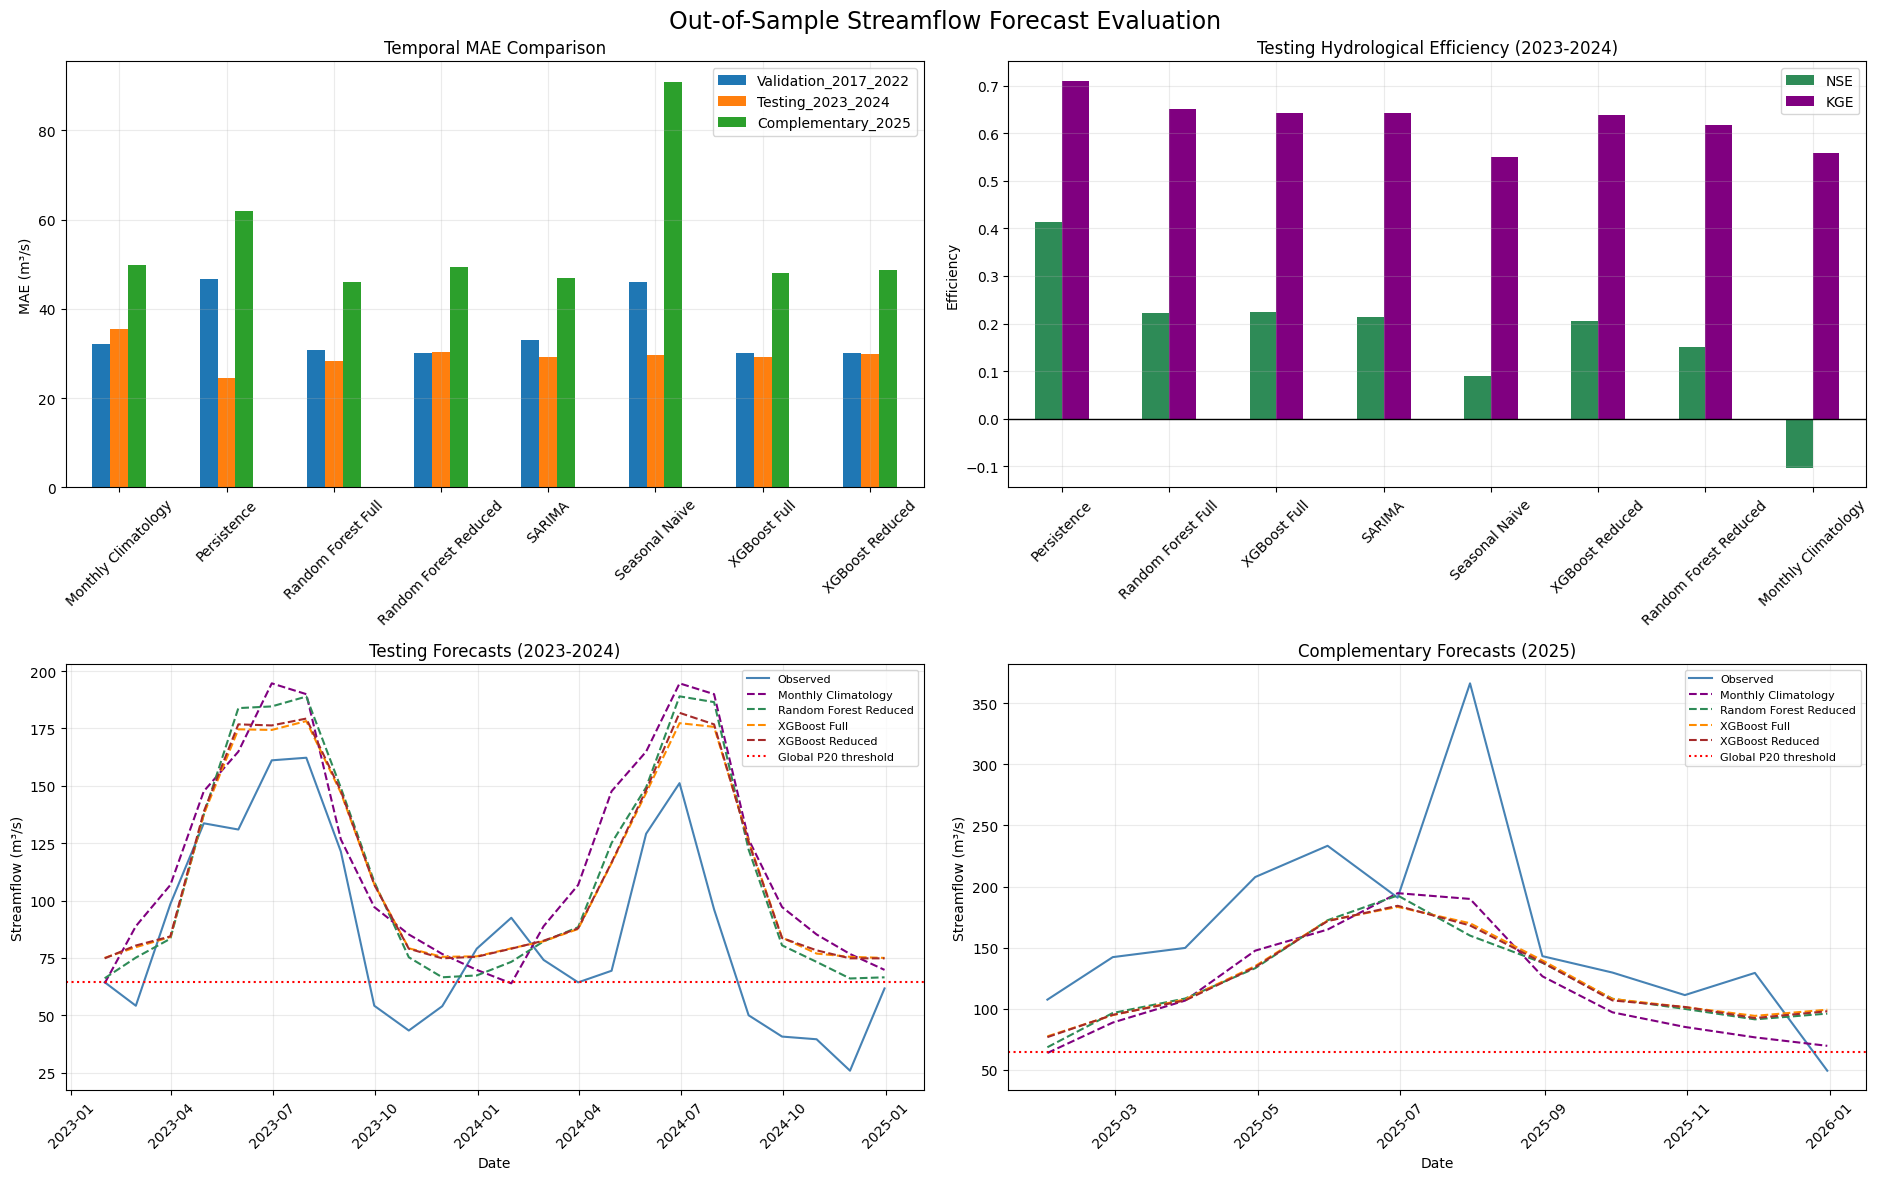

In [49]:
# Visualize temporal forecasting performance

fig, axes = plt.subplots(
    2, 2,
    figsize=(19, 12)
)

# Compare MAE across evaluation periods
temporal_mae_comparison[
    [
        "Validation_2017_2022",
        "Testing_2023_2024",
        "Complementary_2025"
    ]
].plot(
    kind="bar",
    ax=axes[0, 0]
)

axes[0, 0].set_title("Temporal MAE Comparison")
axes[0, 0].set_ylabel("MAE (m³/s)")
axes[0, 0].set_xlabel("")

# Compare testing hydrological efficiency
test_results[["NSE", "KGE"]].plot(
    kind="bar",
    ax=axes[0, 1],
    color=["seagreen", "purple"]
)

axes[0, 1].axhline(
    0, color="black", linewidth=1
)

axes[0, 1].set_title(
    "Testing Hydrological Efficiency (2023-2024)"
)

axes[0, 1].set_ylabel("Efficiency")
axes[0, 1].set_xlabel("")

# Select models for forecast visualization
PLOT_MODELS = [
    "Observed",
    "Monthly Climatology",
    "Random Forest Reduced",
    "XGBoost Full",
    "XGBoost Reduced"
]

plot_colors = {
    "Observed": "steelblue",
    "Monthly Climatology": "purple",
    "Random Forest Reduced": "seagreen",
    "XGBoost Full": "darkorange",
    "XGBoost Reduced": "brown"
}

# Plot testing forecasts
for model_name in PLOT_MODELS:

    axes[1, 0].plot(
        test_predictions.index,
        test_predictions[model_name],
        color=plot_colors[model_name],
        linestyle=(
            "-" if model_name == "Observed" else "--"
        ),
        label=model_name
    )

# Plot complementary forecasts
for model_name in PLOT_MODELS:

    axes[1, 1].plot(
        complementary_predictions.index,
        complementary_predictions[model_name],
        color=plot_colors[model_name],
        linestyle=(
            "-" if model_name == "Observed" else "--"
        ),
        label=model_name
    )

# Calculate global low-flow threshold
global_p20 = train["streamflow"].quantile(0.20)

# Configure forecast plots
for ax in [axes[1, 0], axes[1, 1]]:

    ax.axhline(
        global_p20,
        color="red",
        linestyle=":",
        label="Global P20 threshold"
    )

    ax.set_ylabel("Streamflow (m³/s)")
    ax.set_xlabel("Date")
    ax.legend(fontsize=8)

axes[1, 0].set_title(
    "Testing Forecasts (2023-2024)"
)

axes[1, 1].set_title(
    "Complementary Forecasts (2025)"
)

# Configure all plots
for ax in axes.flat:

    ax.grid(alpha=0.25)
    ax.tick_params(axis="x", rotation=45)

fig.suptitle(
    "Out-of-Sample Streamflow Forecast Evaluation",
    fontsize=17
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "temporal_forecast_evaluation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [50]:
#  LOW-FLOW FORECAST EVALUATION

# Calculate thresholds using training data only
LOW_FLOW_PERCENTILE = 0.20

global_low_flow_threshold = (
    train["streamflow"].quantile(
        LOW_FLOW_PERCENTILE
    )
)

seasonal_low_flow_thresholds = (
    train["streamflow"]
    .groupby(train.index.month)
    .quantile(LOW_FLOW_PERCENTILE)
)

# Define a safe division function
def safe_divide(numerator, denominator):

    return (
        numerator / denominator
        if denominator > 0
        else np.nan
    )


# Define low-flow evaluation metrics
def calculate_low_flow_metrics(
    observed, predicted, thresholds
):

    # Convert inputs into numerical arrays
    observed = np.asarray(observed, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    thresholds = np.asarray(thresholds, dtype=float)

    # Verify input dimensions
    assert observed.shape == predicted.shape
    assert observed.shape == thresholds.shape

    assert np.isfinite(observed).all()
    assert np.isfinite(predicted).all()
    assert np.isfinite(thresholds).all()

    # Classify observed and predicted low-flow months
    observed_low = observed <= thresholds
    predicted_low = predicted <= thresholds

    # Calculate confusion matrix components
    tp = int((observed_low & predicted_low).sum())

    fn = int((observed_low & ~predicted_low).sum())

    fp = int((~observed_low & predicted_low).sum())

    tn = int((~observed_low & ~predicted_low).sum())

    # Verify classification completeness
    assert tp + fn + fp + tn == len(observed)

    # Calculate classification metrics
    recall = safe_divide(tp, tp + fn)

    precision = safe_divide(tp, tp + fp)

    f1 = safe_divide(
        2 * tp,
        2 * tp + fp + fn
    )

    far = safe_divide(fp, tp + fp)

    specificity = safe_divide(tn, tn + fp)

    # Calculate errors during observed low-flow months
    if observed_low.any():

        low_flow_errors = (
            predicted[observed_low]
            - observed[observed_low]
        )

        low_flow_mae = np.mean(
            np.abs(low_flow_errors)
        )

        low_flow_bias = np.mean(
            low_flow_errors
        )

    else:

        low_flow_mae = np.nan
        low_flow_bias = np.nan

    # Return evaluation results
    return {
        "Observations": len(observed),
        "Observed_low_months": int(observed_low.sum()),
        "Predicted_low_months": int(predicted_low.sum()),
        "TP": tp,
        "FN": fn,
        "FP": fp,
        "TN": tn,
        "Recall": recall,
        "Precision": precision,
        "F1": f1,
        "FAR": far,
        "Specificity": specificity,
        "Low_flow_MAE": low_flow_mae,
        "Low_flow_Bias": low_flow_bias
    }


print("Global P20 threshold:",
      round(global_low_flow_threshold, 4))

print("\nSeasonal P20 thresholds:")
display(seasonal_low_flow_thresholds.round(4))

print("\nLow-flow metrics function created successfully.")

Global P20 threshold: 64.4773

Seasonal P20 thresholds:


date
1      43.8955
2      47.9596
3      63.6067
4     106.9157
5     124.3446
6     140.9686
7     144.5448
8     102.8075
9      72.5134
10     61.7604
11     47.9241
12     48.2105
Name: streamflow, dtype: float64


Low-flow metrics function created successfully.


In [51]:
# Define evaluation periods
LOW_FLOW_PERIODS = {
    "Validation 2017-2022": final_validation_predictions,
    "Testing 2023-2024": test_predictions,
    "Complementary 2025": complementary_predictions
}

low_flow_records = []

# Evaluate all periods
for period_name, predictions in LOW_FLOW_PERIODS.items():

    # Create global threshold array
    global_thresholds = np.full(
        len(predictions),
        global_low_flow_threshold
    )

    # Create monthly seasonal threshold array
    seasonal_thresholds = np.asarray(
        predictions.index.month.map(
            seasonal_low_flow_thresholds
        ),
        dtype=float
    )

    threshold_methods = {
        "Global": global_thresholds,
        "Seasonal": seasonal_thresholds
    }

    # Evaluate both low-flow definitions
    for method, thresholds in threshold_methods.items():

        for model_name in FINAL_MODEL_NAMES:

            metrics = calculate_low_flow_metrics(
                predictions["Observed"],
                predictions[model_name],
                thresholds
            )

            low_flow_records.append({
                "Period": period_name,
                "Method": method,
                "Model": model_name,
                **metrics
            })

# Create low-flow evaluation table
low_flow_results = pd.DataFrame(
    low_flow_records
)

# Verify experiment completeness
assert len(low_flow_results) == 48

# Define display columns
low_flow_columns = [
    "Model",
    "Observed_low_months",
    "Predicted_low_months",
    "TP",
    "FN",
    "FP",
    "TN",
    "Recall",
    "Precision",
    "F1",
    "FAR",
    "Low_flow_MAE",
    "Low_flow_Bias"
]

# Display results by period and method
for period_name in LOW_FLOW_PERIODS:

    for method in ["Global", "Seasonal"]:

        subset = low_flow_results.loc[
            (low_flow_results["Period"] == period_name)
            & (low_flow_results["Method"] == method)
        ].sort_values(
            ["F1", "Recall"],
            ascending=False
        )

        print(f"\n{period_name} - {method} threshold:")

        display(
            subset[low_flow_columns].round(4)
        )

# Save complete evaluation results
low_flow_results.to_csv(
    OUTPUT_DIR / "low_flow_forecast_evaluation.csv",
    index=False
)

print("\nTotal evaluations:", len(low_flow_results))
print("Low-flow forecast evaluation completed successfully.")


Validation 2017-2022 - Global threshold:


,Model,Observed_low_months,Predicted_low_months,TP,FN,FP,TN,Recall,Precision,F1,FAR,Low_flow_MAE,Low_flow_Bias
0,Persistence,9,9,3,6,6,57,0.3333,0.3333,0.3333,0.6667,30.3527,29.6589
1,Seasonal Naive,9,9,2,7,7,56,0.2222,0.2222,0.2222,0.7778,43.8634,41.9454
2,Monthly Climatology,9,6,1,8,5,58,0.1111,0.1667,0.1333,0.8333,26.1510,26.1510
3,SARIMA,9,2,0,9,2,61,0.0000,0.0000,0.0000,1.0000,28.4617,28.4617
4,Random Forest Full,9,0,0,9,0,63,0.0000,NaN,0.0000,NaN,30.5215,30.5215
5,Random Forest Reduced,9,0,0,9,0,63,0.0000,NaN,0.0000,NaN,29.6052,29.6052
6,XGBoost Full,9,0,0,9,0,63,0.0000,NaN,0.0000,NaN,33.5602,33.5602
7,XGBoost Reduced,9,0,0,9,0,63,0.0000,NaN,0.0000,NaN,33.0013,33.0013



Validation 2017-2022 - Seasonal threshold:


,Model,Observed_low_months,Predicted_low_months,TP,FN,FP,TN,Recall,Precision,F1,FAR,Low_flow_MAE,Low_flow_Bias
8,Persistence,4,8,1,3,7,61,0.25,0.125,0.1667,0.875,49.1364,48.3350
9,Seasonal Naive,4,3,0,4,3,65,0.00,0.000,0.0000,1.000,68.5233,68.5233
10,Monthly Climatology,4,0,0,4,0,68,0.00,NaN,0.0000,NaN,35.6087,35.6087
11,SARIMA,4,0,0,4,0,68,0.00,NaN,0.0000,NaN,36.2548,36.2548
12,Random Forest Full,4,0,0,4,0,68,0.00,NaN,0.0000,NaN,36.0418,36.0418
13,Random Forest Reduced,4,0,0,4,0,68,0.00,NaN,0.0000,NaN,37.6095,37.6095
14,XGBoost Full,4,0,0,4,0,68,0.00,NaN,0.0000,NaN,40.3409,40.3409
15,XGBoost Reduced,4,0,0,4,0,68,0.00,NaN,0.0000,NaN,40.1017,40.1017



Testing 2023-2024 - Global threshold:


,Model,Observed_low_months,Predicted_low_months,TP,FN,FP,TN,Recall,Precision,F1,FAR,Low_flow_MAE,Low_flow_Bias
16,Persistence,11,11,8,3,3,10,0.7273,0.7273,0.7273,0.2727,21.4278,9.1742
17,Seasonal Naive,11,8,5,6,3,10,0.4545,0.6250,0.5263,0.3750,24.3208,22.6780
19,SARIMA,11,2,2,9,0,13,0.1818,1.0000,0.3077,0.0000,30.7972,30.1871
18,Monthly Climatology,11,2,1,10,1,12,0.0909,0.5000,0.1538,0.5000,38.4466,38.3574
20,Random Forest Full,11,0,0,11,0,13,0.0000,NaN,0.0000,NaN,31.3976,31.3976
21,Random Forest Reduced,11,0,0,11,0,13,0.0000,NaN,0.0000,NaN,30.5379,30.5379
22,XGBoost Full,11,0,0,11,0,13,0.0000,NaN,0.0000,NaN,35.3599,35.3599
23,XGBoost Reduced,11,0,0,11,0,13,0.0000,NaN,0.0000,NaN,35.3159,35.3159


... (3 outputs left out)

,Model,Observed_low_months,Predicted_low_months,TP,FN,FP,TN,Recall,Precision,F1,FAR,Low_flow_MAE,Low_flow_Bias
33,Seasonal Naive,1,6,1,0,5,6,1.0,0.1667,0.2857,0.8333,12.2748,12.2748
32,Persistence,1,1,0,1,1,10,0.0,0.0000,0.0000,1.0000,79.9896,79.9896
34,Monthly Climatology,1,1,0,1,1,10,0.0,0.0000,0.0000,1.0000,20.3523,20.3523
35,SARIMA,1,0,0,1,0,11,0.0,NaN,0.0000,NaN,34.5761,34.5761
36,Random Forest Full,1,0,0,1,0,11,0.0,NaN,0.0000,NaN,49.2806,49.2806
37,Random Forest Reduced,1,0,0,1,0,11,0.0,NaN,0.0000,NaN,46.7035,46.7035
38,XGBoost Full,1,0,0,1,0,11,0.0,NaN,0.0000,NaN,49.9061,49.9061
39,XGBoost Reduced,1,0,0,1,0,11,0.0,NaN,0.0000,NaN,48.6327,48.6327



Complementary 2025 - Seasonal threshold:


,Model,Observed_low_months,Predicted_low_months,TP,FN,FP,TN,Recall,Precision,F1,FAR,Low_flow_MAE,Low_flow_Bias
41,Seasonal Naive,0,6,0,0,6,6,NaN,0.0,0.0,1.0,NaN,NaN
40,Persistence,0,0,0,0,0,12,NaN,NaN,NaN,NaN,NaN,NaN
42,Monthly Climatology,0,0,0,0,0,12,NaN,NaN,NaN,NaN,NaN,NaN
43,SARIMA,0,0,0,0,0,12,NaN,NaN,NaN,NaN,NaN,NaN
44,Random Forest Full,0,0,0,0,0,12,NaN,NaN,NaN,NaN,NaN,NaN
45,Random Forest Reduced,0,0,0,0,0,12,NaN,NaN,NaN,NaN,NaN,NaN
46,XGBoost Full,0,0,0,0,0,12,NaN,NaN,NaN,NaN,NaN,NaN
47,XGBoost Reduced,0,0,0,0,0,12,NaN,NaN,NaN,NaN,NaN,NaN



Total evaluations: 48
Low-flow forecast evaluation completed successfully.


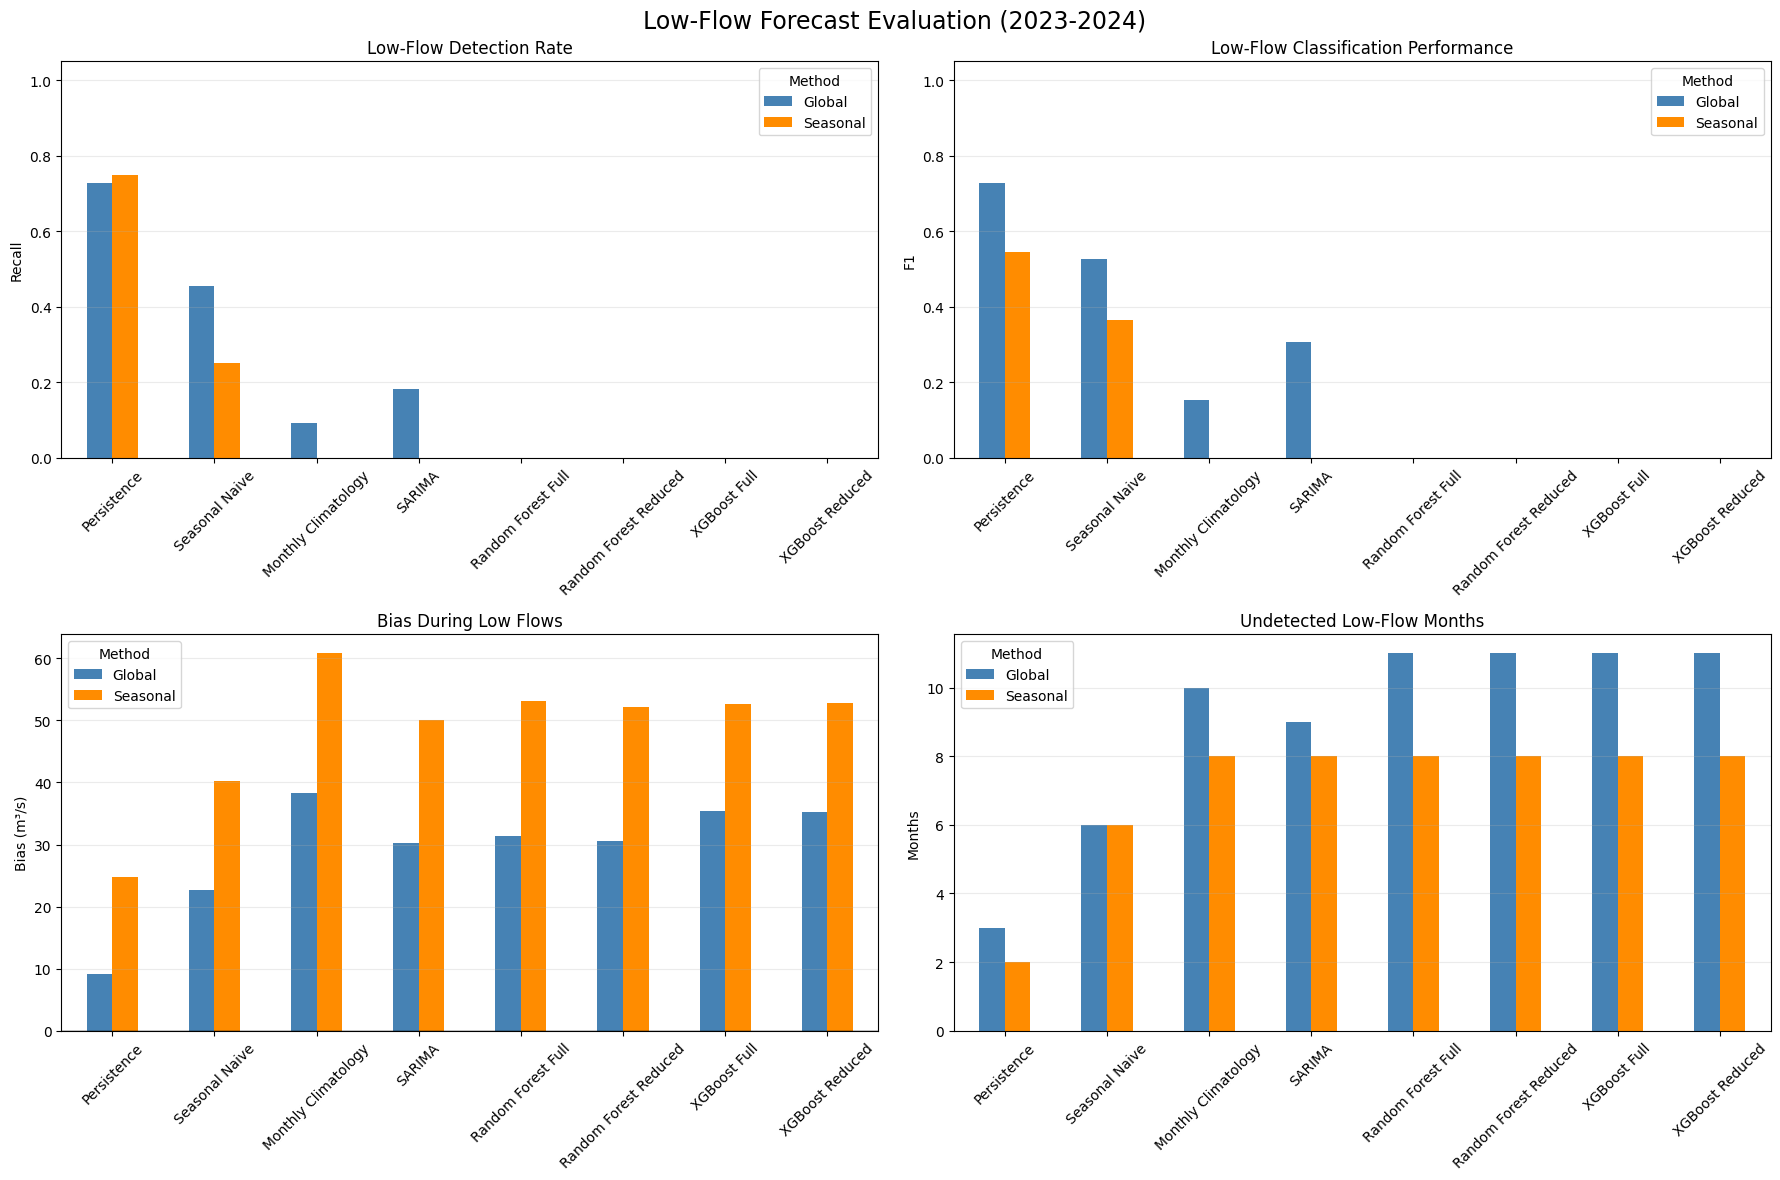

In [52]:
# Visualize testing low-flow performance

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 12)
)

# Select testing results
low_flow_test = low_flow_results.loc[
    low_flow_results["Period"] == "Testing 2023-2024"
].copy()

# Define metrics for visualization
plot_metrics = [
    ("Recall", "Low-Flow Detection Rate", "Recall"),
    ("F1", "Low-Flow Classification Performance", "F1"),
    ("Low_flow_Bias", "Bias During Low Flows", "Bias (m³/s)"),
    ("FN", "Undetected Low-Flow Months", "Months")
]

# Plot global and seasonal performance
for ax, (metric, title, ylabel) in zip(
    axes.flat,
    plot_metrics
):

    comparison = low_flow_test.pivot(
        index="Model",
        columns="Method",
        values=metric
    ).reindex(FINAL_MODEL_NAMES)

    comparison.plot(
        kind="bar",
        ax=ax,
        color=["steelblue", "darkorange"]
    )

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.25)

    if metric in ["Recall", "F1"]:

        ax.set_ylim(0, 1.05)

    if metric == "Low_flow_Bias":

        ax.axhline(
            0,
            color="black",
            linewidth=1
        )

fig.suptitle(
    "Low-Flow Forecast Evaluation (2023-2024)",
    fontsize=17
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "low_flow_forecast_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [53]:
#  FORECAST UNCERTAINTY AND PROBABILISTIC EVALUATION

CONFIDENCE_LEVEL = 0.90

alpha = 1 - CONFIDENCE_LEVEL

uncertainty_records = []
probability_records = []
uncertainty_predictions = {}

UNCERTAINTY_PERIODS = {
    "Testing 2023-2024": test_predictions,
    "Complementary 2025": complementary_predictions
}

# Calculate historical low-flow reference probabilities
training_months = train.index.month

global_reference_probability = (
    train["streamflow"] <= global_low_flow_threshold
).mean()

training_seasonal_thresholds = training_months.map(
    seasonal_low_flow_thresholds
)

seasonal_reference_probabilities = (
    train["streamflow"]
    <= training_seasonal_thresholds
).groupby(training_months).mean()

# Evaluate each forecasting model
for model_name in FINAL_MODEL_NAMES:

    # Estimate residual distribution using validation only
    calibration_residuals = (
        final_validation_predictions["Observed"]
        - final_validation_predictions[model_name]
    ).to_numpy()

    assert np.isfinite(calibration_residuals).all()

    # Calculate empirical residual quantiles
    lower_quantile = np.quantile(
        calibration_residuals,
        alpha / 2
    )

    upper_quantile = np.quantile(
        calibration_residuals,
        1 - alpha / 2
    )

    for period_name, predictions in UNCERTAINTY_PERIODS.items():

        observed = predictions["Observed"].to_numpy()

        point_forecast = predictions[model_name].to_numpy()

        # Construct empirical prediction intervals
        lower_bound = point_forecast + lower_quantile

        upper_bound = point_forecast + upper_quantile

        # Calculate prediction interval coverage
        covered = (
            (observed >= lower_bound)
            & (observed <= upper_bound)
        )

        picp = covered.mean()

        mpiw = np.mean(
            upper_bound - lower_bound
        )

        # Generate empirical predictive samples
        predictive_samples = (
            point_forecast[:, None]
            + calibration_residuals[None, :]
        )

        # Define global and seasonal thresholds
        global_thresholds = np.full(
            len(observed),
            global_low_flow_threshold
        )

        seasonal_thresholds = np.asarray(
            predictions.index.month.map(
                seasonal_low_flow_thresholds
            ),
            dtype=float
        )

        threshold_methods = {
            "Global": global_thresholds,
            "Seasonal": seasonal_thresholds
        }

        # Store prediction interval results
        uncertainty_records.append({
            "Model": model_name,
            "Period": period_name,
            "Observations": len(observed),
            "Calibration_residuals": len(
                calibration_residuals
            ),
            "Nominal_coverage": CONFIDENCE_LEVEL,
            "PICP": picp,
            "MPIW": mpiw,
            "Covered_observations": int(covered.sum()),
            "Negative_lower_bounds": int(
                (lower_bound < 0).sum()
            )
        })

        # Store monthly uncertainty predictions
        result = pd.DataFrame({
            "Observed": observed,
            "Forecast": point_forecast,
            "Lower_bound": lower_bound,
            "Upper_bound": upper_bound
        }, index=predictions.index)

        # Evaluate both low-flow definitions
        for method, thresholds in threshold_methods.items():

            # Estimate low-flow probabilities
            probabilities = (
                predictive_samples
                <= thresholds[:, None]
            ).mean(axis=1)

            # Define observed low-flow events
            observed_low = (
                observed <= thresholds
            ).astype(int)

            # Calculate Brier Score
            brier_score = np.mean(
                (probabilities - observed_low) ** 2
            )

            # Historical reference probabilities
            if method == "Global":

                reference_probabilities = np.full(
                    len(observed),
                    global_reference_probability
                )

            else:

                reference_probabilities = np.asarray(
                    predictions.index.month.map(
                        seasonal_reference_probabilities
                    ),
                    dtype=float
                )

            reference_brier = np.mean(
                (
                    reference_probabilities
                    - observed_low
                ) ** 2
            )

            brier_skill = (
                1 - brier_score / reference_brier
                if reference_brier > 0
                else np.nan
            )

            # Apply a fixed exploratory alert threshold
            alerts = probabilities >= 0.50

            tp = int(
                (alerts & (observed_low == 1)).sum()
            )

            fn = int(
                (~alerts & (observed_low == 1)).sum()
            )

            fp = int(
                (alerts & (observed_low == 0)).sum()
            )

            tn = int(
                (~alerts & (observed_low == 0)).sum()
            )

            probability_records.append({
                "Model": model_name,
                "Period": period_name,
                "Method": method,
                "Brier_Score": brier_score,
                "Reference_Brier": reference_brier,
                "Brier_Skill": brier_skill,
                "Observed_low_months": int(
                    observed_low.sum()
                ),
                "Probability_alerts": int(alerts.sum()),
                "TP": tp,
                "FN": fn,
                "FP": fp,
                "TN": tn,
                "Recall": safe_divide(tp, tp + fn),
                "Precision": safe_divide(tp, tp + fp),
                "F1": safe_divide(
                    2 * tp,
                    2 * tp + fp + fn
                )
            })

            result[f"{method}_threshold"] = thresholds

            result[f"{method}_probability"] = (
                probabilities
            )

            result[f"{method}_observed_low"] = (
                observed_low
            )

        uncertainty_predictions[
            (model_name, period_name)
        ] = result

# Create evaluation tables
uncertainty_results = pd.DataFrame(
    uncertainty_records
)

probability_results = pd.DataFrame(
    probability_records
)

assert len(uncertainty_results) == 16
assert len(probability_results) == 32

print("Uncertainty evaluation completed successfully.")

Uncertainty evaluation completed successfully.


In [54]:
# Display uncertainty and probabilistic results

for period_name in UNCERTAINTY_PERIODS:

    print(f"\nPrediction intervals - {period_name}:")

    display(
        uncertainty_results.loc[
            uncertainty_results["Period"] == period_name
        ].round(4)
    )

    for method in ["Global", "Seasonal"]:

        print(f"\n{period_name} - {method} probability:")

        subset = probability_results.loc[
            (probability_results["Period"] == period_name)
            & (probability_results["Method"] == method)
        ].sort_values("Brier_Score")

        display(subset.round(4))

# Save evaluation results
uncertainty_results.to_csv(
    OUTPUT_DIR / "prediction_interval_evaluation.csv",
    index=False
)

probability_results.to_csv(
    OUTPUT_DIR / "probabilistic_low_flow_evaluation.csv",
    index=False
)

# Save monthly predictions and probabilities
for (model_name, period_name), result in (
    uncertainty_predictions.items()
):

    file_name = (
        f"{model_name}_{period_name}"
        .lower()
        .replace(" ", "_")
    )

    result.to_csv(
        OUTPUT_DIR / f"uncertainty_{file_name}.csv"
    )

print("\nInterval evaluations:", len(uncertainty_results))

print("Probability evaluations:", len(probability_results))

print("Uncertainty results saved successfully.")


Prediction intervals - Testing 2023-2024:


,Model,Period,Observations,Calibration_residuals,Nominal_coverage,PICP,MPIW,Covered_observations,Negative_lower_bounds
0,Persistence,Testing 2023-2024,24,72,0.9,1.0000,213.5795,24,17
2,Seasonal Naive,Testing 2023-2024,24,72,0.9,1.0000,197.2366,24,13
4,Monthly Climatology,Testing 2023-2024,24,72,0.9,0.5833,122.8427,14,0
6,SARIMA,Testing 2023-2024,24,72,0.9,0.8750,128.7890,21,0
8,Random Forest Full,Testing 2023-2024,24,72,0.9,0.8333,129.8565,20,0
10,Random Forest Reduced,Testing 2023-2024,24,72,0.9,0.7917,122.2740,19,0
12,XGBoost Full,Testing 2023-2024,24,72,0.9,0.7083,129.5995,17,0
14,XGBoost Reduced,Testing 2023-2024,24,72,0.9,0.7083,126.6496,17,0



Testing 2023-2024 - Global probability:


,Model,Period,Method,Brier_Score,Reference_Brier,Brier_Skill,Observed_low_months,Probability_alerts,TP,FN,FP,TN,Recall,Precision,F1
0,Persistence,Testing 2023-2024,Global,0.1687,0.314,0.4626,11,9,7,4,2,11,0.6364,0.7778,0.7000
4,Seasonal Naive,Testing 2023-2024,Global,0.1944,0.314,0.3810,11,7,5,6,2,11,0.4545,0.7143,0.5556
12,SARIMA,Testing 2023-2024,Global,0.2428,0.314,0.2268,11,2,2,9,0,13,0.1818,1.0000,0.3077
20,Random Forest Reduced,Testing 2023-2024,Global,0.2459,0.314,0.2169,11,0,0,11,0,13,0.0000,NaN,0.0000
16,Random Forest Full,Testing 2023-2024,Global,0.2488,0.314,0.2074,11,0,0,11,0,13,0.0000,NaN,0.0000
28,XGBoost Reduced,Testing 2023-2024,Global,0.2720,0.314,0.1337,11,0,0,11,0,13,0.0000,NaN,0.0000
24,XGBoost Full,Testing 2023-2024,Global,0.2770,0.314,0.1178,11,0,0,11,0,13,0.0000,NaN,0.0000
8,Monthly Climatology,Testing 2023-2024,Global,0.3093,0.314,0.0148,11,0,0,11,0,13,0.0000,NaN,0.0000



Testing 2023-2024 - Seasonal probability:


,Model,Period,Method,Brier_Score,Reference_Brier,Brier_Skill,Observed_low_months,Probability_alerts,TP,FN,FP,TN,Recall,Precision,F1
5,Seasonal Naive,Testing 2023-2024,Seasonal,0.1886,0.2369,0.2039,8,3,2,6,1,15,0.25,0.6667,0.3636
13,SARIMA,Testing 2023-2024,Seasonal,0.1957,0.2369,0.1741,8,0,0,8,0,16,0.00,NaN,0.0000
21,Random Forest Reduced,Testing 2023-2024,Seasonal,0.2091,0.2369,0.1173,8,0,0,8,0,16,0.00,NaN,0.0000
25,XGBoost Full,Testing 2023-2024,Seasonal,0.2103,0.2369,0.1122,8,0,0,8,0,16,0.00,NaN,0.0000
29,XGBoost Reduced,Testing 2023-2024,Seasonal,0.2124,0.2369,0.1035,8,0,0,8,0,16,0.00,NaN,0.0000
17,Random Forest Full,Testing 2023-2024,Seasonal,0.2131,0.2369,0.1005,8,0,0,8,0,16,0.00,NaN,0.0000
1,Persistence,Testing 2023-2024,Seasonal,0.2425,0.2369,-0.0234,8,13,6,2,7,9,0.75,0.4615,0.5714
9,Monthly Climatology,Testing 2023-2024,Seasonal,0.2549,0.2369,-0.0760,8,0,0,8,0,16,0.00,NaN,0.0000


... (3 outputs left out)

,Model,Period,Method,Brier_Score,Reference_Brier,Brier_Skill,Observed_low_months,Probability_alerts,TP,FN,FP,TN,Recall,Precision,F1
10,Monthly Climatology,Complementary 2025,Global,0.0628,0.0905,0.3062,1,0,0,1,0,11,0.0,NaN,0.0000
14,SARIMA,Complementary 2025,Global,0.0733,0.0905,0.1900,1,0,0,1,0,11,0.0,NaN,0.0000
30,XGBoost Reduced,Complementary 2025,Global,0.0751,0.0905,0.1699,1,0,0,1,0,11,0.0,NaN,0.0000
26,XGBoost Full,Complementary 2025,Global,0.0772,0.0905,0.1465,1,0,0,1,0,11,0.0,NaN,0.0000
18,Random Forest Full,Complementary 2025,Global,0.0841,0.0905,0.0702,1,0,0,1,0,11,0.0,NaN,0.0000
22,Random Forest Reduced,Complementary 2025,Global,0.0861,0.0905,0.0482,1,0,0,1,0,11,0.0,NaN,0.0000
2,Persistence,Complementary 2025,Global,0.0952,0.0905,-0.0522,1,1,0,1,1,10,0.0,0.0,0.0000
6,Seasonal Naive,Complementary 2025,Global,0.2339,0.0905,-1.5857,1,5,1,0,4,7,1.0,0.2,0.3333



Complementary 2025 - Seasonal probability:


,Model,Period,Method,Brier_Score,Reference_Brier,Brier_Skill,Observed_low_months,Probability_alerts,TP,FN,FP,TN,Recall,Precision,F1
19,Random Forest Full,Complementary 2025,Seasonal,0.0085,0.045,0.8110,0,0,0,0,0,12,NaN,NaN,NaN
27,XGBoost Full,Complementary 2025,Seasonal,0.0106,0.045,0.7649,0,0,0,0,0,12,NaN,NaN,NaN
31,XGBoost Reduced,Complementary 2025,Seasonal,0.0120,0.045,0.7338,0,0,0,0,0,12,NaN,NaN,NaN
15,SARIMA,Complementary 2025,Seasonal,0.0147,0.045,0.6731,0,0,0,0,0,12,NaN,NaN,NaN
11,Monthly Climatology,Complementary 2025,Seasonal,0.0200,0.045,0.5563,0,0,0,0,0,12,NaN,NaN,NaN
23,Random Forest Reduced,Complementary 2025,Seasonal,0.0220,0.045,0.5109,0,0,0,0,0,12,NaN,NaN,NaN
3,Persistence,Complementary 2025,Seasonal,0.0297,0.045,0.3401,0,0,0,0,0,12,NaN,NaN,NaN
7,Seasonal Naive,Complementary 2025,Seasonal,0.3543,0.045,-6.8733,0,6,0,0,6,6,NaN,0.0,0.0



Interval evaluations: 16
Probability evaluations: 32
Uncertainty results saved successfully.


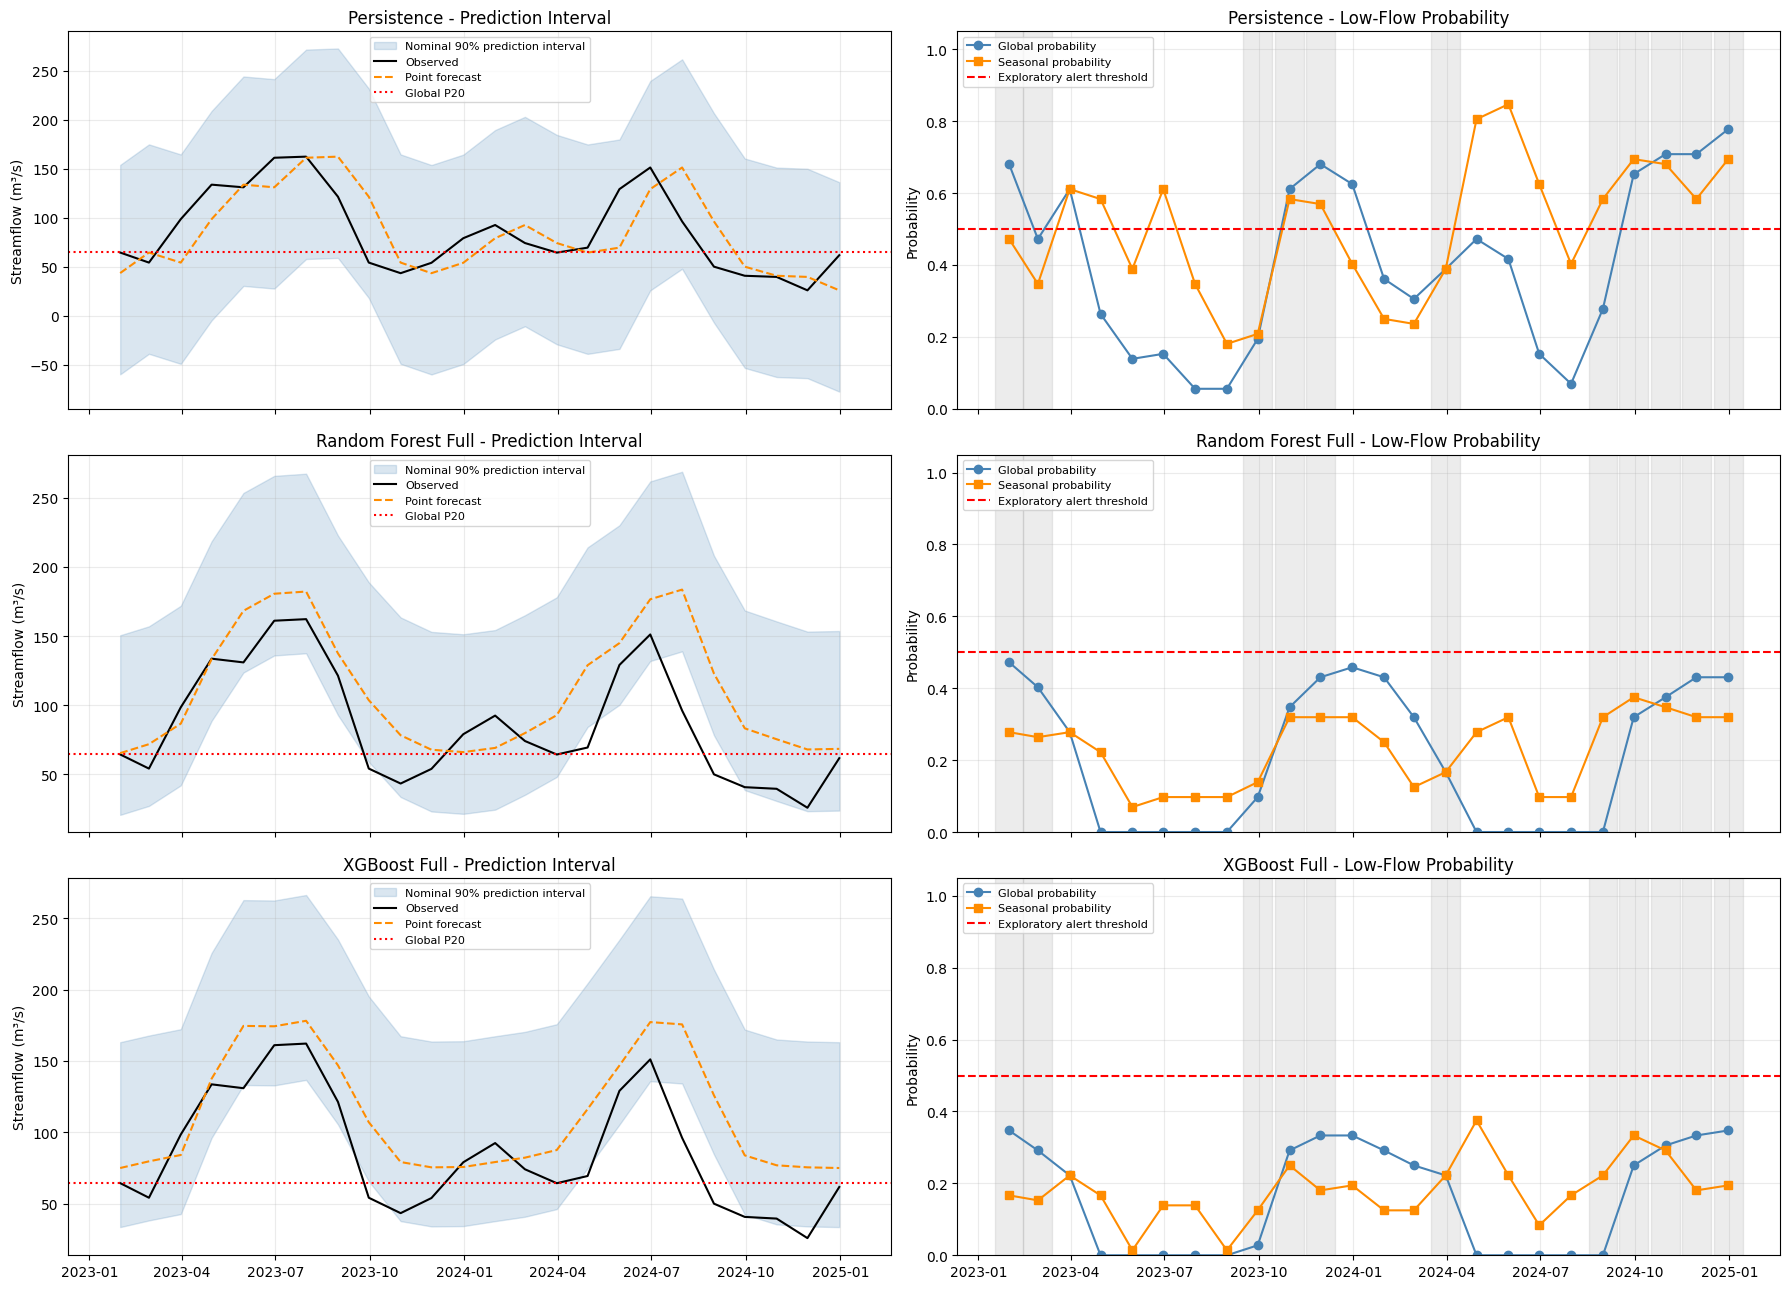

In [55]:
# Visualize prediction intervals and low-flow probabilities

selected_models = [
    "Persistence",
    "Random Forest Full",
    "XGBoost Full"
]

period_name = "Testing 2023-2024"

fig, axes = plt.subplots(
    3, 2,
    figsize=(18, 13),
    sharex=True
)

for i, model_name in enumerate(selected_models):

    result = uncertainty_predictions[
        (model_name, period_name)
    ]

    # Plot prediction intervals
    ax = axes[i, 0]

    ax.fill_between(
        result.index,
        result["Lower_bound"].to_numpy(),
        result["Upper_bound"].to_numpy(),
        color="steelblue",
        alpha=0.20,
        label="Nominal 90% prediction interval"
    )

    ax.plot(
        result.index,
        result["Observed"],
        color="black",
        label="Observed"
    )

    ax.plot(
        result.index,
        result["Forecast"],
        color="darkorange",
        linestyle="--",
        label="Point forecast"
    )

    ax.axhline(
        global_low_flow_threshold,
        color="red",
        linestyle=":",
        label="Global P20"
    )

    ax.set_title(f"{model_name} - Prediction Interval")
    ax.set_ylabel("Streamflow (m³/s)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

    # Plot low-flow probabilities
    ax = axes[i, 1]

    ax.plot(
        result.index,
        result["Global_probability"],
        color="steelblue",
        marker="o",
        label="Global probability"
    )

    ax.plot(
        result.index,
        result["Seasonal_probability"],
        color="darkorange",
        marker="s",
        label="Seasonal probability"
    )

    ax.axhline(
        0.50,
        color="red",
        linestyle="--",
        label="Exploratory alert threshold"
    )

    # Highlight observed global low-flow months
    for date in result.index[
        result["Global_observed_low"] == 1
    ]:

        ax.axvspan(
            date - pd.Timedelta(days=14),
            date + pd.Timedelta(days=14),
            color="gray",
            alpha=0.15
        )

    ax.set_ylim(0, 1.05)
    ax.set_title(f"{model_name} - Low-Flow Probability")
    ax.set_ylabel("Probability")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "forecast_uncertainty_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [56]:
# TWO-MONTH-AHEAD FORECASTING

from sklearn.base import clone

FORECAST_HORIZON = 2

# Create a new feature dataset
h2_data = data.copy()

# Define available lag features
H2_LAGS = [2, 3, 4, 6, 12]

for lag in H2_LAGS:

    h2_data[f"lag_{lag}"] = (
        h2_data["streamflow"].shift(lag)
    )

# Create rolling means without future information
for window in [3, 6]:

    h2_data[f"rolling_mean_{window}"] = (
        h2_data["streamflow"]
        .shift(FORECAST_HORIZON)
        .rolling(window)
        .mean()
    )

# Create cyclical calendar features
month = h2_data.index.month

h2_data["month_sin"] = np.sin(
    2 * np.pi * month / 12
)

h2_data["month_cos"] = np.cos(
    2 * np.pi * month / 12
)

# Define full and reduced feature configurations
H2_FULL_FEATURES = [
    "lag_2",
    "lag_3",
    "lag_4",
    "lag_6",
    "lag_12",
    "rolling_mean_3",
    "rolling_mean_6",
    "month_sin",
    "month_cos"
]

H2_REDUCED_FEATURES = [
    "lag_2",
    "lag_12",
    "month_cos"
]

# Remove incomplete observations
h2_data = h2_data.dropna(
    subset=H2_FULL_FEATURES
).copy()

# Create training dataset
h2_train = h2_data.loc[:TRAIN_END].copy()

# Create continuous evaluation dataset
h2_evaluation = h2_data.loc[
    VALIDATION_START:COMPLEMENTARY_END
].copy()

# Exclude the first target month because
# its forecast origin precedes the training cutoff
h2_evaluation = h2_evaluation.iloc[1:].copy()

# Define training predictors and target
X_h2_train = h2_train[H2_FULL_FEATURES]
y_h2_train = h2_train["streamflow"]

X_h2_eval = h2_evaluation[H2_FULL_FEATURES]

# Verify feature alignment
pd.testing.assert_series_equal(
    h2_data["lag_2"],
    data["streamflow"].shift(2).loc[h2_data.index],
    check_names=False
)

assert len(h2_train) == 384
assert len(h2_evaluation) == 107

print("Training observations:", len(h2_train))
print("Continuous evaluation observations:", len(h2_evaluation))
print("Forecast horizon:", FORECAST_HORIZON)
print("Full predictors:", len(H2_FULL_FEATURES))
print("Reduced predictors:", len(H2_REDUCED_FEATURES))

display(h2_train.head().round(4))

Training observations: 384
Continuous evaluation observations: 107
Forecast horizon: 2
Full predictors: 9
Reduced predictors: 3


,streamflow,lag_2,lag_3,lag_4,lag_6,lag_12,rolling_mean_3,rolling_mean_6,month_sin,month_cos
date,,,,,,,,,,
1985-01-31,39.7745,60.0420,89.5045,97.8807,206.0644,44.8207,82.4757,127.8885,0.500,0.866
1985-02-28,44.5048,80.4126,60.0420,89.5045,128.1640,159.0101,76.6530,110.3447,0.866,0.500
1985-03-31,40.3536,39.7745,80.4126,60.0420,97.8807,145.8941,60.0764,82.6297,1.000,0.000
1985-04-30,47.3955,44.5048,39.7745,80.4126,89.5045,245.9541,54.8973,68.6865,0.866,-0.500
1985-05-31,97.1480,40.3536,44.5048,39.7745,60.0420,102.4697,41.5443,59.0987,0.500,-0.866


In [57]:
# Generate two-month-ahead forecasts

h2_predictions = pd.DataFrame({
    "Observed": h2_evaluation["streamflow"]
})

# Persistence baseline
h2_predictions["Persistence"] = (
    h2_evaluation["lag_2"]
)

# Seasonal Naive baseline
h2_predictions["Seasonal Naive"] = (
    h2_evaluation["lag_12"]
)

# Monthly Climatology baseline
h2_predictions["Monthly Climatology"] = (
    h2_predictions.index.month.map(
        monthly_climatology
    )
)

# Generate sequential two-step SARIMA forecasts
current_sarima_model = best_sarima_model

h2_sarima_forecasts = []

for target_date in h2_predictions.index:

    # Forecast two months ahead
    forecast = current_sarima_model.forecast(
        steps=2
    )

    assert forecast.index[-1] == target_date

    h2_sarima_forecasts.append(
        float(forecast.iloc[-1])
    )

    # Advance the forecast origin by one month
    next_origin = target_date - pd.offsets.MonthEnd(1)

    new_observation = data.loc[
        [next_origin], "streamflow"
    ].asfreq("ME")

    current_sarima_model = (
        current_sarima_model.extend(
            new_observation
        )
    )

h2_predictions["SARIMA"] = h2_sarima_forecasts

# Train machine learning models for horizon 2
h2_models = {}

for model_name, configuration in FINAL_ML_MODELS.items():

    # Select the corresponding feature configuration
    features = (
        H2_REDUCED_FEATURES
        if "Reduced" in model_name
        else H2_FULL_FEATURES
    )

    # Preserve previously selected hyperparameters
    model = clone(configuration["model"])

    # Train using horizon-specific predictors
    model.fit(
        X_h2_train[features],
        y_h2_train
    )

    # Generate forecasts
    h2_predictions[model_name] = model.predict(
        X_h2_eval[features]
    )

    h2_models[model_name] = {
        "model": model,
        "features": features
    }

# Verify prediction completeness
assert np.isfinite(
    h2_predictions.to_numpy()
).all()

print("Two-month-ahead forecasts generated successfully.")

display(h2_predictions.head().round(4))

Two-month-ahead forecasts generated successfully.


,Observed,Persistence,Seasonal Naive,Monthly Climatology,SARIMA,Random Forest Full,Random Forest Reduced,XGBoost Full,XGBoost Reduced
date,,,,,,,,,
2017-02-28,98.4732,55.5468,101.5455,88.8050,88.0692,80.1761,82.2138,83.848900,82.770203
2017-03-31,182.2603,102.6763,164.4997,106.7792,108.7228,107.5926,106.3888,106.930702,106.261101
2017-04-30,203.4769,98.4732,199.5373,147.6142,148.1232,147.1167,143.0009,139.064194,138.743607
2017-05-31,188.9177,182.2603,181.4728,164.8693,168.6385,190.2308,195.4842,177.914307,178.273102
2017-06-30,167.2261,203.4769,367.4304,194.6233,197.5216,200.7267,203.8208,184.408798,185.689606


In [58]:
# Compare one-month and two-month forecasting horizons

HORIZON_PERIODS = {
    "Validation 2017-2022": (
        final_validation_predictions,
        VALIDATION_START,
        VALIDATION_END
    ),

    "Testing 2023-2024": (
        test_predictions,
        TEST_START,
        TEST_END
    ),

    "Complementary 2025": (
        complementary_predictions,
        COMPLEMENTARY_START,
        COMPLEMENTARY_END
    )
}

horizon_records = []
horizon_low_flow_records = []

for period_name, period_config in HORIZON_PERIODS.items():

    h1_table, start_date, end_date = period_config

    # Use identical evaluation dates
    common_dates = h1_table.index[1:]

    h1_subset = h1_table.loc[common_dates]

    h2_subset = h2_predictions.loc[common_dates]

    pd.testing.assert_series_equal(
        h1_subset["Observed"],
        h2_subset["Observed"]
    )

    # Define low-flow thresholds
    thresholds_by_method = {
        "Global": np.full(
            len(common_dates),
            global_low_flow_threshold
        ),

        "Seasonal": np.asarray(
            common_dates.month.map(
                seasonal_low_flow_thresholds
            ),
            dtype=float
        )
    }

    for model_name in FINAL_MODEL_NAMES:

        for horizon, prediction_table in [
            (1, h1_subset),
            (2, h2_subset)
        ]:

            metrics = calculate_forecasting_metrics(
                prediction_table["Observed"],
                prediction_table[model_name]
            )

            horizon_records.append({
                "Period": period_name,
                "Model": model_name,
                "Horizon": horizon,
                "Observations": len(prediction_table),
                **metrics
            })

            # Evaluate low-flow detection
            for method, thresholds in thresholds_by_method.items():

                low_metrics = calculate_low_flow_metrics(
                    prediction_table["Observed"],
                    prediction_table[model_name],
                    thresholds
                )

                horizon_low_flow_records.append({
                    "Period": period_name,
                    "Model": model_name,
                    "Horizon": horizon,
                    "Method": method,
                    **low_metrics
                })

# Create result tables
horizon_results = pd.DataFrame(
    horizon_records
)

horizon_low_flow_results = pd.DataFrame(
    horizon_low_flow_records
)

# Compare MAE between horizons
horizon_comparison = horizon_results.pivot(
    index=["Period", "Model"],
    columns="Horizon",
    values="MAE"
).rename(columns={
    1: "MAE_H1",
    2: "MAE_H2"
})

horizon_comparison["Delta_MAE"] = (
    horizon_comparison["MAE_H2"]
    - horizon_comparison["MAE_H1"]
)

horizon_comparison["Delta_MAE_Percent"] = (
    100 * horizon_comparison["Delta_MAE"]
    / horizon_comparison["MAE_H1"]
)

assert len(horizon_results) == 48
assert len(horizon_low_flow_results) == 96

print("Forecast horizon comparison:")

display(horizon_comparison.round(4))

# Display testing low-flow performance
print("\nTesting low-flow comparison:")

display(
    horizon_low_flow_results.loc[
        horizon_low_flow_results["Period"]
        == "Testing 2023-2024",
        [
            "Model",
            "Horizon",
            "Method",
            "Observed_low_months",
            "TP",
            "FN",
            "FP",
            "Recall",
            "F1",
            "Low_flow_Bias"
        ]
    ].round(4)
)

# Save results
h2_predictions.to_csv(
    OUTPUT_DIR / "two_month_forecasts.csv"
)

horizon_results.to_csv(
    OUTPUT_DIR / "forecast_horizon_metrics.csv",
    index=False
)

horizon_comparison.to_csv(
    OUTPUT_DIR / "forecast_horizon_comparison.csv"
)

horizon_low_flow_results.to_csv(
    OUTPUT_DIR / "forecast_horizon_low_flow.csv",
    index=False
)

print("\nForecast horizon evaluation completed successfully.")

Forecast horizon comparison:


Horizon                                      MAE_H1   MAE_H2  Delta_MAE  \
Period               Model                                                
Complementary 2025   Monthly Climatology    50.3068  50.3068     0.0000   
                     Persistence            63.3251  72.7284     9.4033   
                     Random Forest Full     47.0002  51.1923     4.1921   
                     Random Forest Reduced  50.3100  54.6704     4.3605   
                     SARIMA                 47.4926  48.6450     1.1524   
                     Seasonal Naive         97.8222  97.8222     0.0000   
                     XGBoost Full           49.7634  53.8817     4.1183   
                     XGBoost Reduced        50.3018  53.6918     3.3900   
Testing 2023-2024    Monthly Climatology    36.9121  36.9121     0.0000   
                     Persistence            24.6883  40.7365    16.0481   
                     Random Forest Full     29.5536  32.2725     2.7189   
                     Random Forest Reduced  31.6078  31.9342     0.3263   
                     SARIMA                 30.4492  36.4458     5.9966   
                     Seasonal Naive         30.6460  30.6460     0.0000   
                     XGBoost Full           30.0114  32.1830     2.1716   
                     XGBoost Reduced        30.6367  32.1432     1.5065   
Validation 2017-2022 Monthly Climatology    32.0227  32.0227     0.0000   
                     Persistence            46.7812  57.0274    10.2462   
                     Random Forest Full     30.6210  31.5495     0.9285   
                     Random Forest Reduced  30.1318  31.7202     1.5884   
                     SARIMA                 32.9042  32.3056    -0.5986   
                     Seasonal Naive         45.8991  45.8991     0.0000   
                     XGBoost Full           30.1272  30.8508     0.7236   
                     XGBoost Reduced        30.1489  30.8553     0.7065   

Horizon                                     Delta_MAE_Percent  
Period               Model                                     
Complementary 2025   Monthly Climatology               0.0000  
                     Persistence                      14.8493  
                     Random Forest Full                8.9193  
                     Random Forest Reduced             8.6672  
                     SARIMA                            2.4264  
                     Seasonal Naive                    0.0000  
                     XGBoost Full                      8.2757  
                     XGBoost Reduced                   6.7393  
Testing 2023-2024    Monthly Climatology               0.0000  
                     Persistence                      65.0030  
                     Random Forest Full                9.1999  
                     Random Forest Reduced             1.0324  
                     SARIMA                           19.6938  
                     Seasonal Naive                    0.0000  
                     XGBoost Full                      7.2359  
                     XGBoost Reduced                   4.9173  
Validation 2017-2022 Monthly Climatology               0.0000  
                     Persistence                      21.9024  
                     Random Forest Full                3.0321  
                     Random Forest Reduced             5.2716  
                     SARIMA                           -1.8192  
                     Seasonal Naive                    0.0000  
                     XGBoost Full                      2.4018  
                     XGBoost Reduced                   2.3432


Testing low-flow comparison:


,Model,Horizon,Method,Observed_low_months,TP,FN,FP,Recall,F1,Low_flow_Bias
32,Persistence,1,Global,10,7,3,3,0.70,0.7000,12.1857
33,Persistence,1,Seasonal,8,6,2,7,0.75,0.5714,24.7786
34,Persistence,2,Global,10,5,5,5,0.50,0.5000,36.3454
35,Persistence,2,Seasonal,8,4,4,9,0.50,0.3810,50.7010
36,Seasonal Naive,1,Global,10,4,6,3,0.40,0.4706,25.8493
37,Seasonal Naive,1,Seasonal,8,2,6,1,0.25,0.3636,40.1514
38,Seasonal Naive,2,Global,10,4,6,3,0.40,0.4706,25.8493
39,Seasonal Naive,2,Seasonal,8,2,6,1,0.25,0.3636,40.1514
40,Monthly Climatology,1,Global,10,0,10,1,0.00,0.0000,42.2422
41,Monthly Climatology,1,Seasonal,8,0,8,0,0.00,0.0000,60.8105



Forecast horizon evaluation completed successfully.


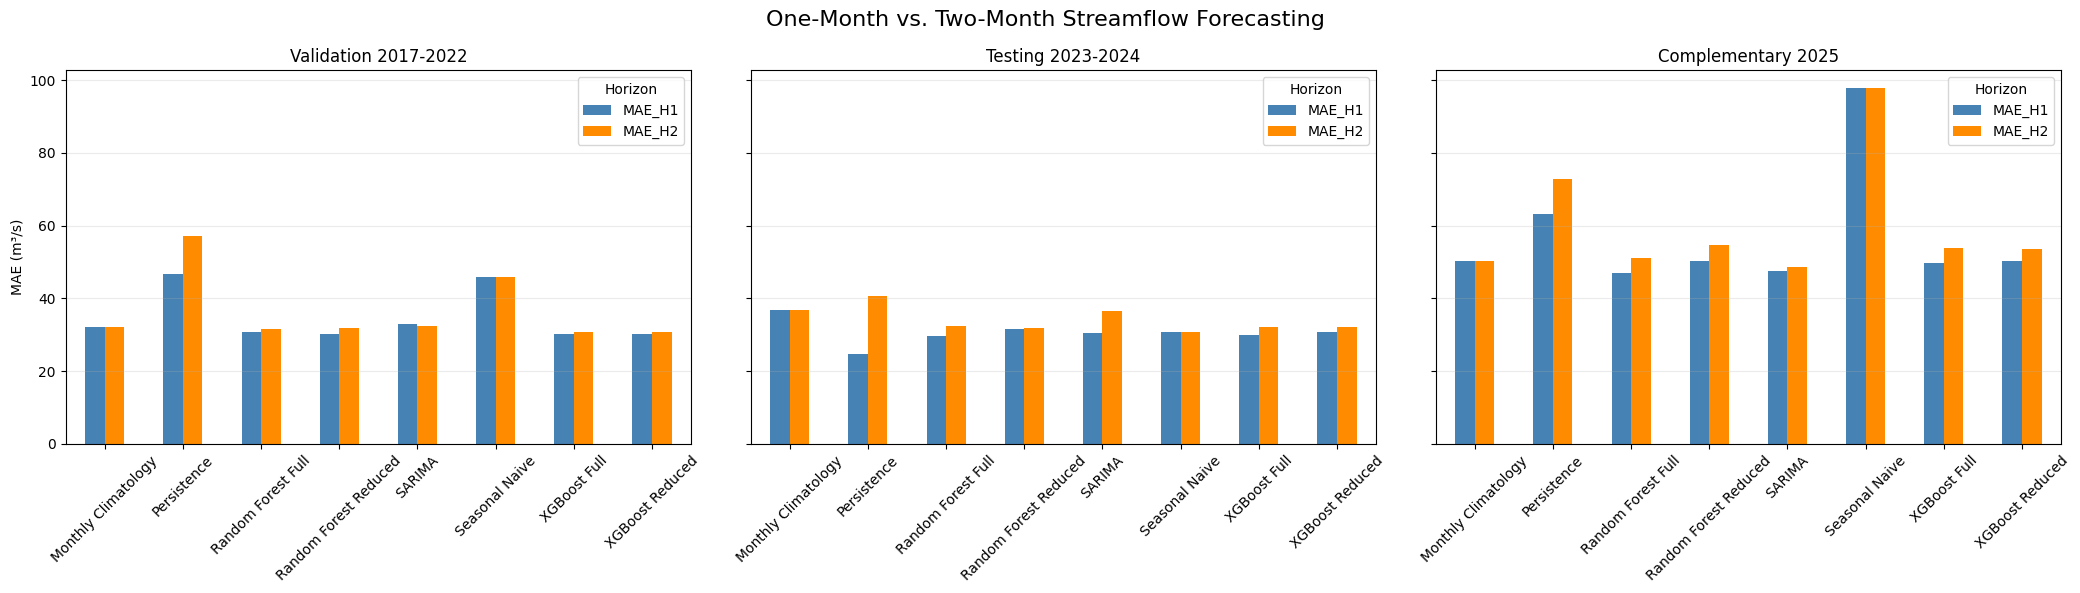

In [59]:
# Visualize the effect of forecast horizon

fig, axes = plt.subplots(
    1, 3,
    figsize=(21, 6),
    sharey=True
)

for ax, period_name in zip(
    axes,
    HORIZON_PERIODS.keys()
):

    comparison = horizon_comparison.loc[
        period_name,
        ["MAE_H1", "MAE_H2"]
    ]

    comparison.plot(
        kind="bar",
        ax=ax,
        color=["steelblue", "darkorange"]
    )

    ax.set_title(period_name)
    ax.set_ylabel("MAE (m³/s)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "One-Month vs. Two-Month Streamflow Forecasting",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "forecast_horizon_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [60]:
# HYDROLOGICAL SCENARIO PREPARATION

scenario_records = []

# Build monthly hydrological scenarios
for (model_name, period_name), result in (
    uncertainty_predictions.items()
):

    scenario = result.copy()

    # Identify model and evaluation period
    scenario["Model"] = model_name
    scenario["Period"] = period_name

    # Calculate the number of seconds per month
    scenario["Days_in_month"] = (
        scenario.index.days_in_month
    )

    scenario["Seconds_in_month"] = (
        scenario["Days_in_month"] * 86400
    )

    # Construct physically admissible scenarios
    scenario["Observed_flow"] = (
        scenario["Observed"]
    )

    scenario["Conservative_flow"] = (
        scenario["Lower_bound"].clip(lower=0)
    )

    scenario["Point_flow"] = (
        scenario["Forecast"].clip(lower=0)
    )

    scenario["Favorable_flow"] = (
        scenario["Upper_bound"].clip(lower=0)
    )

    # Record physical adjustments
    scenario["Lower_bound_adjusted"] = (
        scenario["Lower_bound"] < 0
    )

    scenario["Point_adjusted"] = (
        scenario["Forecast"] < 0
    )

    scenario["Upper_bound_adjusted"] = (
        scenario["Upper_bound"] < 0
    )

    # Convert monthly streamflow into volume
    scenario_types = [
        "Observed",
        "Conservative",
        "Point",
        "Favorable"
    ]

    for scenario_type in scenario_types:

        scenario[f"{scenario_type}_volume_hm3"] = (
            scenario[f"{scenario_type}_flow"]
            * scenario["Seconds_in_month"]
            / 1e6
        )

    # Check interval ordering
    assert (
        scenario["Conservative_flow"]
        <= scenario["Favorable_flow"]
    ).all()

    # Check whether point forecasts are inside intervals
    scenario["Point_outside_interval"] = (
        (scenario["Point_flow"] < scenario["Conservative_flow"])
        | (scenario["Point_flow"] > scenario["Favorable_flow"])
    )

    # Store scenario data
    scenario.index.name = "Date"

    scenario_records.append(
        scenario.reset_index()
    )

# Combine all hydrological scenarios
hydrological_scenarios = pd.concat(
    scenario_records,
    ignore_index=True
)

# Verify expected number of observations
assert len(hydrological_scenarios) == 288

# Verify physical validity
flow_columns = [
    "Observed_flow",
    "Conservative_flow",
    "Point_flow",
    "Favorable_flow"
]

assert np.isfinite(
    hydrological_scenarios[flow_columns].to_numpy()
).all()

assert (
    hydrological_scenarios[flow_columns] >= 0
).all().all()

assert not hydrological_scenarios.duplicated(
    subset=["Model", "Period", "Date"]
).any()

print("Hydrological scenario preparation completed.")

print("\nNumber of scenario records:",
      len(hydrological_scenarios))

print("Number of forecasting models:",
      hydrological_scenarios["Model"].nunique())

print("Negative scenario flows:",
      (hydrological_scenarios[flow_columns] < 0).sum().sum())

print("\nFirst five scenario observations:")

display(hydrological_scenarios.head().round(4))

Hydrological scenario preparation completed.

Number of scenario records: 288
Number of forecasting models: 8
Negative scenario flows: 0

First five scenario observations:


C:\Users\DETPC\AppData\Local\Temp\ipykernel_50104\848115066.py:132: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(hydrological_scenarios.head().round(4))


,Date,Observed,Forecast,Lower_bound,Upper_bound,Global_threshold,Global_probability,Global_observed_low,Seasonal_threshold,Seasonal_probability,...,Point_flow,Favorable_flow,Lower_bound_adjusted,Point_adjusted,Upper_bound_adjusted,Observed_volume_hm3,Conservative_volume_hm3,Point_volume_hm3,Favorable_volume_hm3,Point_outside_interval
0,2023-01-31,64.3940,43.4533,-59.8196,153.7599,64.4773,0.6806,1,43.8955,0.4722,...,43.4533,153.7599,True,False,False,172.4729,0.0000,116.3854,411.8306,False
1,2023-02-28,54.1468,64.3940,-38.8789,174.7006,64.4773,0.4722,1,47.9596,0.3472,...,64.3940,174.7006,True,False,False,130.9920,0.0000,155.7820,422.6357,False
2,2023-03-31,98.4724,54.1468,-49.1261,164.4534,64.4773,0.6111,0,63.6067,0.6111,...,54.1468,164.4534,True,False,False,263.7486,0.0000,145.0268,440.4721,False
3,2023-04-30,133.6341,98.4724,-4.8005,208.7790,64.4773,0.2639,0,106.9157,0.5833,...,98.4724,208.7790,True,False,False,346.3797,0.0000,255.2405,541.1553,False
4,2023-05-31,130.9289,133.6341,30.3612,243.9408,64.4773,0.1389,0,124.3446,0.3889,...,133.6341,243.9408,False,False,False,350.6800,81.3195,357.9257,653.3709,False


In [61]:
# Summarize hydrological scenarios

hydrological_summary = (
    hydrological_scenarios
    .groupby(["Period", "Model"])
    .agg(
        Observations=("Date", "count"),

        Observed_volume_hm3=(
            "Observed_volume_hm3", "sum"
        ),

        Conservative_volume_hm3=(
            "Conservative_volume_hm3", "sum"
        ),

        Point_volume_hm3=(
            "Point_volume_hm3", "sum"
        ),

        Favorable_volume_hm3=(
            "Favorable_volume_hm3", "sum"
        ),

        Adjusted_lower_bounds=(
            "Lower_bound_adjusted", "sum"
        ),

        Adjusted_point_forecasts=(
            "Point_adjusted", "sum"
        ),

        Adjusted_upper_bounds=(
            "Upper_bound_adjusted", "sum"
        ),

        Point_outside_interval=(
            "Point_outside_interval", "sum"
        )
    )
    .reset_index()
)

# Calculate cumulative volume differences
hydrological_summary["Point_volume_bias_hm3"] = (
    hydrological_summary["Point_volume_hm3"]
    - hydrological_summary["Observed_volume_hm3"]
)

hydrological_summary["Point_volume_bias_percent"] = (
    100
    * hydrological_summary["Point_volume_bias_hm3"]
    / hydrological_summary["Observed_volume_hm3"]
)

# Calculate scenario uncertainty range
hydrological_summary["Scenario_range_hm3"] = (
    hydrological_summary["Favorable_volume_hm3"]
    - hydrological_summary["Conservative_volume_hm3"]
)

# Verify summary completeness
assert len(hydrological_summary) == 16

for period_name in UNCERTAINTY_PERIODS:

    print(f"\nHydrological scenarios - {period_name}:")

    display(
        hydrological_summary.loc[
            hydrological_summary["Period"] == period_name
        ].round(4)
    )

# Save simulation inputs
hydrological_scenarios.to_csv(
    OUTPUT_DIR / "hydrological_scenarios.csv",
    index=False
)

hydrological_summary.to_csv(
    OUTPUT_DIR / "hydrological_scenario_summary.csv",
    index=False
)

print("\nHydrological scenario files saved successfully.")


Hydrological scenarios - Testing 2023-2024:


,Period,Model,Observations,Observed_volume_hm3,Conservative_volume_hm3,Point_volume_hm3,Favorable_volume_hm3,Adjusted_lower_bounds,Adjusted_point_forecasts,Adjusted_upper_bounds,Point_outside_interval,Point_volume_bias_hm3,Point_volume_bias_percent,Scenario_range_hm3
8,Testing 2023-2024,Monthly Climatology,24,5407.1672,5132.9507,7436.0696,12891.5011,0,0,0,0,2028.9024,37.5225,7758.5503
9,Testing 2023-2024,Persistence,24,5407.1672,707.6202,5353.5917,12320.3812,17,0,0,0,-53.5755,-0.9908,11612.7610
10,Testing 2023-2024,Random Forest Full,24,5407.1672,4123.5353,6943.1164,12325.0672,0,0,0,0,1535.9492,28.4058,8201.5319
11,Testing 2023-2024,Random Forest Reduced,24,5407.1672,4417.4874,7082.5764,12140.1184,0,0,0,0,1675.4092,30.9850,7722.6310
12,Testing 2023-2024,SARIMA,24,5407.1672,4334.7709,7050.5461,12468.8767,0,0,0,0,1643.3789,30.3926,8134.1058
13,Testing 2023-2024,Seasonal Naive,24,5407.1672,1375.1511,6711.6934,12386.0997,13,0,0,0,1304.5262,24.1259,11010.9486
14,Testing 2023-2024,XGBoost Full,24,5407.1672,4472.1120,7087.9713,12657.4101,0,0,0,0,1680.8041,31.0847,8185.2982
15,Testing 2023-2024,XGBoost Reduced,24,5407.1672,4584.6089,7124.6723,12583.5947,0,0,0,0,1717.5051,31.7635,7998.9858



Hydrological scenarios - Complementary 2025:


,Period,Model,Observations,Observed_volume_hm3,Conservative_volume_hm3,Point_volume_hm3,Favorable_volume_hm3,Adjusted_lower_bounds,Adjusted_point_forecasts,Adjusted_upper_bounds,Point_outside_interval,Point_volume_bias_hm3,Point_volume_bias_percent,Scenario_range_hm3
0,Complementary 2025,Monthly Climatology,12,5158.5717,2564.2143,3714.1984,6438.1827,0,0,0,0,-1444.3733,-27.9995,3873.9684
1,Complementary 2025,Persistence,12,5158.5717,2056.7657,5202.2151,8680.8446,1,0,0,0,43.6434,0.8460,6624.0790
2,Complementary 2025,Random Forest Full,12,5158.5717,2608.5873,4016.4493,6703.7435,0,0,0,0,-1142.1225,-22.1403,4095.1562
3,Complementary 2025,Random Forest Reduced,12,5158.5717,2524.2347,3854.9563,6380.2679,0,0,0,0,-1303.6155,-25.2709,3856.0333
4,Complementary 2025,SARIMA,12,5158.5717,2698.4562,4054.4863,6759.9454,0,0,0,0,-1104.0855,-21.4029,4061.4892
5,Complementary 2025,Seasonal Naive,12,5158.5717,171.4956,2351.6121,5184.9340,10,0,0,0,-2806.9596,-54.4135,5013.4384
6,Complementary 2025,XGBoost Full,12,5158.5717,2597.3556,3903.4960,6684.4060,0,0,0,0,-1255.0757,-24.3299,4087.0504
7,Complementary 2025,XGBoost Reduced,12,5158.5717,2611.0076,3879.3018,6605.0292,0,0,0,0,-1279.2699,-24.7989,3994.0216



Hydrological scenario files saved successfully.


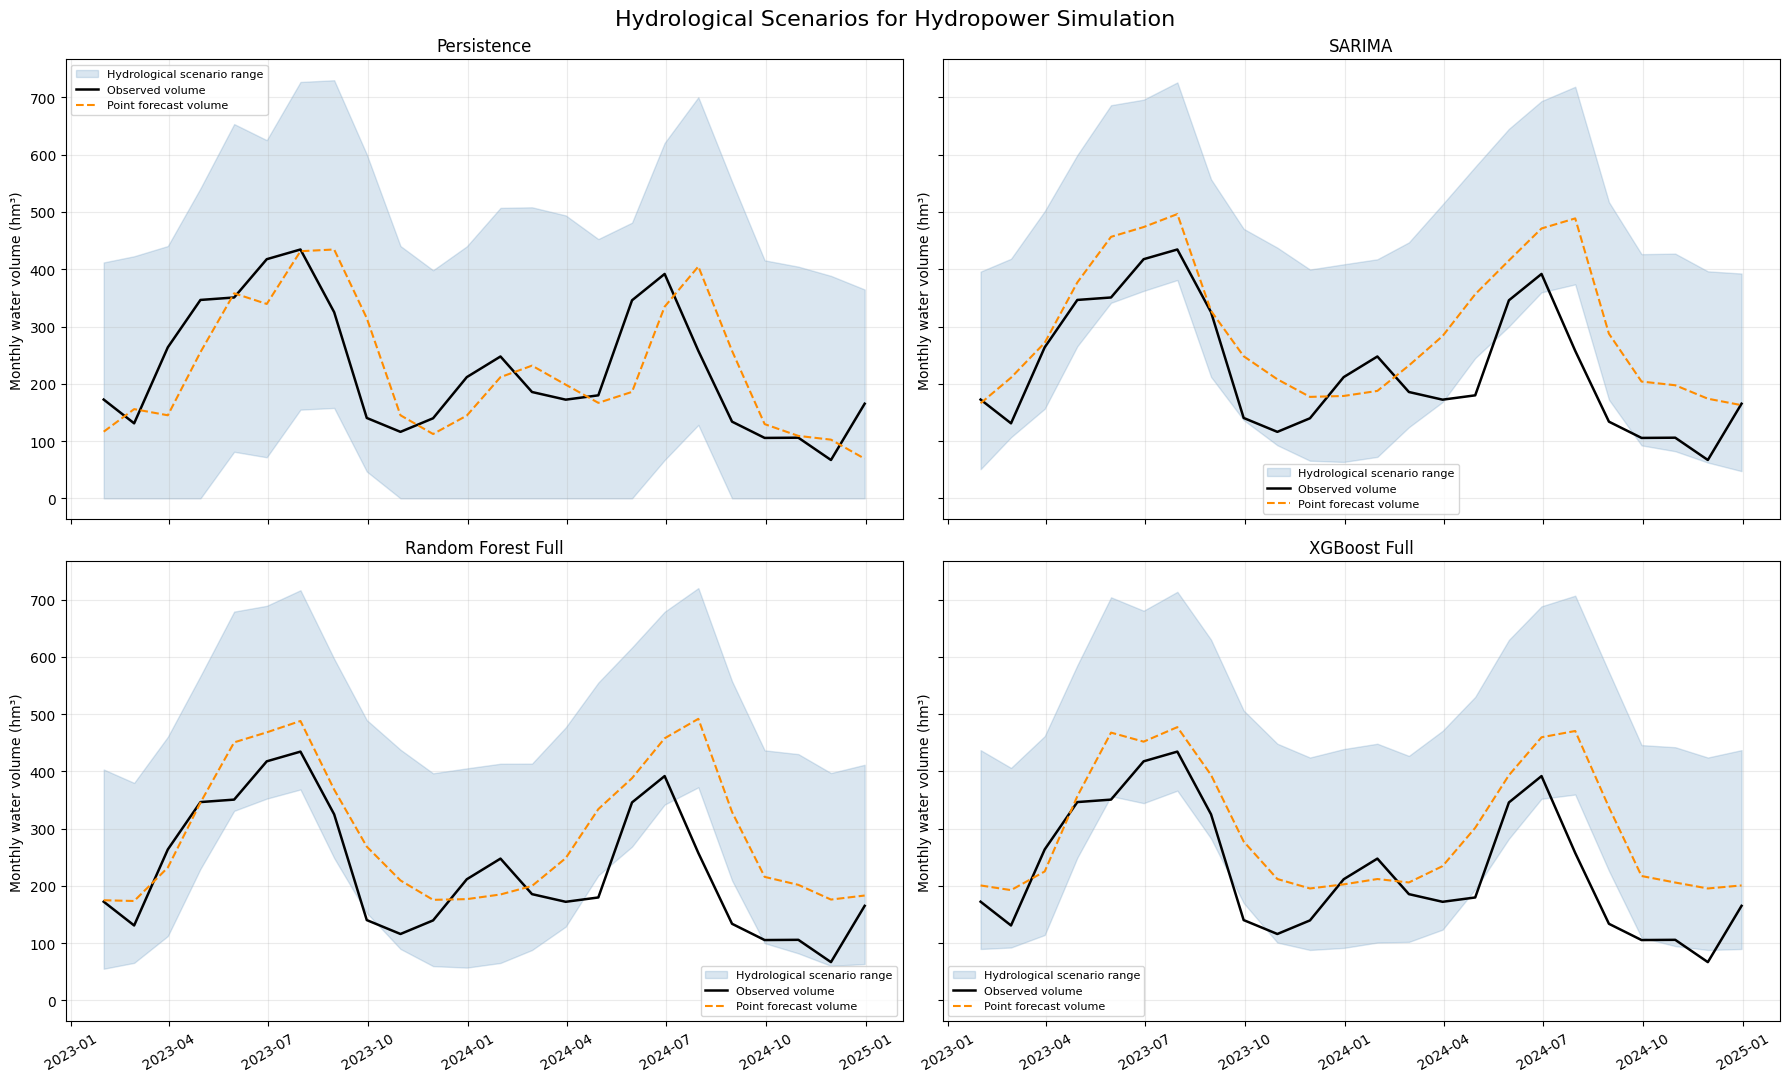

Hydrological scenario preparation: COMPLETED


In [62]:
# Visualize hydrological scenarios

selected_models = [
    "Persistence",
    "SARIMA",
    "Random Forest Full",
    "XGBoost Full"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 11),
    sharex=True,
    sharey=True
)

for ax, model_name in zip(
    axes.flat,
    selected_models
):

    subset = hydrological_scenarios.loc[
        (hydrological_scenarios["Model"] == model_name)
        & (
            hydrological_scenarios["Period"]
            == "Testing 2023-2024"
        )
    ].sort_values("Date")

    # Display monthly water availability scenarios
    ax.fill_between(
        subset["Date"],
        subset["Conservative_volume_hm3"],
        subset["Favorable_volume_hm3"],
        color="steelblue",
        alpha=0.20,
        label="Hydrological scenario range"
    )

    ax.plot(
        subset["Date"],
        subset["Observed_volume_hm3"],
        color="black",
        linewidth=1.8,
        label="Observed volume"
    )

    ax.plot(
        subset["Date"],
        subset["Point_volume_hm3"],
        color="darkorange",
        linestyle="--",
        label="Point forecast volume"
    )

    ax.set_title(model_name)
    ax.set_ylabel("Monthly water volume (hm³)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
    ax.tick_params(axis="x", rotation=30)

fig.suptitle(
    "Hydrological Scenarios for Hydropower Simulation",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "hydrological_scenario_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Hydrological scenario preparation: COMPLETED")

In [63]:
# HYDROPOWER SYSTEM PARAMETERS

# Documented physical parameters
MAZAR_PARAMETERS = {
    "installed_capacity_mw": 170.0,
    "total_storage_hm3": 410.0,
    "active_storage_hm3": 310.0,
    "number_of_turbines": 2,
    "unit_capacity_mw": 85.0,
    "turbine_type": "Francis",
    "design_flow_m3s": 141.1,
    "maximum_elevation_m": 2153.0,
    "minimum_elevation_m": 2098.0
}

# Physical constants
PHYSICAL_CONSTANTS = {
    "water_density_kg_m3": 1000.0,
    "gravity_m_s2": 9.81,
    "seconds_per_day": 86400,
    "m3_per_hm3": 1e6
}

# Exploratory simulation assumptions
SIMULATION_ASSUMPTIONS = {
    "initial_storage_fraction": 0.50,
    "minimum_active_storage_hm3": 0.0,
    "maximum_active_storage_hm3": 310.0,
    "inflow_is_basin_proxy": True,
    "time_step": "Monthly",
    "forecast_horizon_months": 1
}

# Parameters requiring additional verification
UNVERIFIED_PARAMETERS = {
    "net_head_m": None,
    "overall_efficiency": None,
    "environmental_flow_m3s": None,
    "evaporation_losses_hm3": None,
    "actual_initial_storage_hm3": None,
    "operational_maximum_turbine_flow_m3s": None
}

# Calculate derived reference parameters
DERIVED_PARAMETERS = {
    "remaining_storage_hm3": (
        MAZAR_PARAMETERS["total_storage_hm3"]
        - MAZAR_PARAMETERS["active_storage_hm3"]
    ),

    "initial_active_storage_hm3": (
        MAZAR_PARAMETERS["active_storage_hm3"]
        * SIMULATION_ASSUMPTIONS[
            "initial_storage_fraction"
        ]
    ),

    "operating_elevation_range_m": (
        MAZAR_PARAMETERS["maximum_elevation_m"]
        - MAZAR_PARAMETERS["minimum_elevation_m"]
    )
}

# Verify physical consistency
assert (
    MAZAR_PARAMETERS["active_storage_hm3"]
    <= MAZAR_PARAMETERS["total_storage_hm3"]
)

assert (
    MAZAR_PARAMETERS["number_of_turbines"]
    * MAZAR_PARAMETERS["unit_capacity_mw"]
    == MAZAR_PARAMETERS["installed_capacity_mw"]
)

assert (
    0 <= SIMULATION_ASSUMPTIONS[
        "initial_storage_fraction"
    ] <= 1
)

assert (
    MAZAR_PARAMETERS["maximum_elevation_m"]
    > MAZAR_PARAMETERS["minimum_elevation_m"]
)

# Display documented parameters
print("Documented hydropower parameters:")

display(
    pd.DataFrame(
        MAZAR_PARAMETERS.items(),
        columns=["Parameter", "Value"]
    )
)

print("\nDerived parameters:")

display(
    pd.DataFrame(
        DERIVED_PARAMETERS.items(),
        columns=["Parameter", "Value"]
    )
)

print("\nParameters requiring verification:")

display(
    pd.DataFrame(
        UNVERIFIED_PARAMETERS.items(),
        columns=["Parameter", "Value"]
    )
)

print("\nHydropower parameter verification: PASSED")

Documented hydropower parameters:


,Parameter,Value
0,installed_capacity_mw,170.0
1,total_storage_hm3,410.0
2,active_storage_hm3,310.0
3,number_of_turbines,2
4,unit_capacity_mw,85.0
5,turbine_type,Francis
6,design_flow_m3s,141.1
7,maximum_elevation_m,2153.0
8,minimum_elevation_m,2098.0



Derived parameters:


,Parameter,Value
0,remaining_storage_hm3,100.0
1,initial_active_storage_hm3,155.0
2,operating_elevation_range_m,55.0



Parameters requiring verification:


,Parameter,Value
0,net_head_m,None
1,overall_efficiency,None
2,environmental_flow_m3s,None
3,evaporation_losses_hm3,None
4,actual_initial_storage_hm3,None
5,operational_maximum_turbine_flow_m3s,None



Hydropower parameter verification: PASSED


In [64]:
# Define initial storage sensitivity scenarios

INITIAL_STORAGE_SCENARIOS = {
    "Low": 0.25,
    "Medium": 0.50,
    "High": 0.75
}

storage_scenario_records = []

for scenario, fraction in INITIAL_STORAGE_SCENARIOS.items():

    storage_scenario_records.append({
        "Scenario": scenario,
        "Storage_fraction": fraction,
        "Storage_percent": fraction * 100,
        "Initial_storage_hm3": (
            fraction
            * MAZAR_PARAMETERS["active_storage_hm3"]
        )
    })

initial_storage_scenarios = pd.DataFrame(
    storage_scenario_records
)

print("Initial storage sensitivity scenarios:")

display(initial_storage_scenarios.round(4))

# Save physical parameters and assumptions
hydropower_configuration = {
    "documented_parameters": MAZAR_PARAMETERS,
    "physical_constants": PHYSICAL_CONSTANTS,
    "simulation_assumptions": SIMULATION_ASSUMPTIONS,
    "derived_parameters": DERIVED_PARAMETERS,
    "unverified_parameters": UNVERIFIED_PARAMETERS,
    "initial_storage_scenarios": INITIAL_STORAGE_SCENARIOS
}

with open(
    OUTPUT_DIR / "hydropower_configuration.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        hydropower_configuration,
        file,
        indent=4
    )

initial_storage_scenarios.to_csv(
    OUTPUT_DIR / "initial_storage_scenarios.csv",
    index=False
)

print("\nHydropower configuration saved successfully.")

Initial storage sensitivity scenarios:


,Scenario,Storage_fraction,Storage_percent,Initial_storage_hm3
0,Low,0.25,25.0,77.5
1,Medium,0.50,50.0,155.0
2,High,0.75,75.0,232.5



Hydropower configuration saved successfully.


In [65]:
#  RESERVOIR WATER BALANCE

def reservoir_water_balance(
    initial_storage,
    inflow_volume,
    requested_release,
    maximum_storage,
    maximum_release
):

    # Validate physical inputs
    assert 0 <= initial_storage <= maximum_storage
    assert inflow_volume >= 0
    assert requested_release >= 0
    assert maximum_release >= 0

    # Calculate available water
    available_water = (
        initial_storage + inflow_volume
    )

    # Calculate feasible turbine release
    actual_release = min(
        requested_release,
        available_water,
        maximum_release
    )

    # Calculate excess water
    remaining_water = (
        available_water - actual_release
    )

    # Calculate spill volume
    spill_volume = max(
        0,
        remaining_water - maximum_storage
    )

    # Calculate final reservoir storage
    final_storage = (
        remaining_water - spill_volume
    )

    # Calculate unmet water release
    unmet_release = (
        requested_release - actual_release
    )

    # Verify mass conservation
    balance_error = (
        initial_storage
        + inflow_volume
        - actual_release
        - spill_volume
        - final_storage
    )

    assert abs(balance_error) < 1e-8

    assert 0 <= final_storage <= maximum_storage + 1e-8

    return {
        "Initial_storage_hm3": initial_storage,
        "Inflow_hm3": inflow_volume,
        "Requested_release_hm3": requested_release,
        "Maximum_release_hm3": maximum_release,
        "Actual_release_hm3": actual_release,
        "Spill_hm3": spill_volume,
        "Final_storage_hm3": final_storage,
        "Unmet_release_hm3": unmet_release,
        "Balance_error_hm3": balance_error
    }


print("Reservoir water balance function created successfully.")

Reservoir water balance function created successfully.


In [66]:
# Verify reservoir behavior under controlled scenarios

water_balance_tests = {
    "Normal operation": {
        "initial_storage": 155,
        "inflow_volume": 180,
        "requested_release": 220
    },

    "Water shortage": {
        "initial_storage": 30,
        "inflow_volume": 40,
        "requested_release": 200
    },

    "Excess inflow": {
        "initial_storage": 250,
        "inflow_volume": 400,
        "requested_release": 200
    },

    "Hydraulic capacity limitation": {
        "initial_storage": 200,
        "inflow_volume": 300,
        "requested_release": 450
    }
}

test_records = []

for scenario, parameters in water_balance_tests.items():

    result = reservoir_water_balance(
        **parameters,
        maximum_storage=310,
        maximum_release=365
    )

    test_records.append({
        "Scenario": scenario,
        **result
    })

water_balance_verification = pd.DataFrame(
    test_records
).set_index("Scenario")

# Verify expected mathematical results
np.testing.assert_allclose(
    water_balance_verification["Final_storage_hm3"],
    [115, 0, 310, 135]
)

np.testing.assert_allclose(
    water_balance_verification["Spill_hm3"],
    [0, 0, 140, 0]
)

np.testing.assert_allclose(
    water_balance_verification["Unmet_release_hm3"],
    [0, 130, 0, 85]
)

print("Reservoir water balance verification:")

display(water_balance_verification.round(4))

print("\nWater balance verification: PASSED")

Reservoir water balance verification:


,Initial_storage_hm3,Inflow_hm3,Requested_release_hm3,Maximum_release_hm3,Actual_release_hm3,Spill_hm3,Final_storage_hm3,Unmet_release_hm3,Balance_error_hm3
Scenario,,,,,,,,,
Normal operation,155,180,220,365,220,0,115,0,0
Water shortage,30,40,200,365,70,0,0,130,0
Excess inflow,250,400,200,365,200,140,310,0,0
Hydraulic capacity limitation,200,300,450,365,365,0,135,85,0



Water balance verification: PASSED


In [67]:
# Simulate reservoir storage using observed inflows

REFERENCE_RELEASE_M3S = 100.0

maximum_storage = MAZAR_PARAMETERS[
    "active_storage_hm3"
]

design_flow = MAZAR_PARAMETERS[
    "design_flow_m3s"
]

# Extract a single observed hydrological series
observed_hydrology = (
    hydrological_scenarios.loc[
        hydrological_scenarios["Model"]
        == "Persistence",
        [
            "Date",
            "Period",
            "Observed_flow",
            "Observed_volume_hm3",
            "Seconds_in_month"
        ]
    ]
    .sort_values("Date")
    .reset_index(drop=True)
)

# Verify chronological completeness
assert len(observed_hydrology) == 36

assert observed_hydrology["Date"].is_unique

assert observed_hydrology["Date"].is_monotonic_increasing

simulation_records = []

# Evaluate initial storage scenarios
for scenario, fraction in INITIAL_STORAGE_SCENARIOS.items():

    current_storage = (
        fraction * maximum_storage
    )

    for _, row in observed_hydrology.iterrows():

        seconds = row["Seconds_in_month"]

        # Convert requested flow into monthly volume
        requested_release = (
            REFERENCE_RELEASE_M3S
            * seconds
            / 1e6
        )

        # Calculate provisional hydraulic limit
        maximum_release = (
            design_flow
            * seconds
            / 1e6
        )

        # Calculate monthly water balance
        result = reservoir_water_balance(
            initial_storage=current_storage,
            inflow_volume=row["Observed_volume_hm3"],
            requested_release=requested_release,
            maximum_storage=maximum_storage,
            maximum_release=maximum_release
        )

        # Store simulation results
        simulation_records.append({
            "Date": row["Date"],
            "Period": row["Period"],
            "Scenario": scenario,
            "Observed_flow_m3s": row["Observed_flow"],
            **result
        })

        # Update storage for the next month
        current_storage = result[
            "Final_storage_hm3"
        ]

# Create simulation dataset
reservoir_simulation = pd.DataFrame(
    simulation_records
)

# Verify the number of simulations
assert len(reservoir_simulation) == 108

# Verify mass conservation
assert np.allclose(
    reservoir_simulation["Balance_error_hm3"],
    0,
    atol=1e-8
)

# Calculate storage percentage
reservoir_simulation["Storage_percent"] = (
    100
    * reservoir_simulation["Final_storage_hm3"]
    / maximum_storage
)

print("Reservoir simulation completed successfully.")

print("Simulation records:", len(reservoir_simulation))

print("\nFirst five simulation records:")

display(
    reservoir_simulation.head().round(4)
)

Reservoir simulation completed successfully.
Simulation records: 108

First five simulation records:


C:\Users\DETPC\AppData\Local\Temp\ipykernel_50104\1230835335.py:116: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  reservoir_simulation.head().round(4)


,Date,Period,Scenario,Observed_flow_m3s,Initial_storage_hm3,Inflow_hm3,Requested_release_hm3,Maximum_release_hm3,Actual_release_hm3,Spill_hm3,Final_storage_hm3,Unmet_release_hm3,Balance_error_hm3,Storage_percent
0,2023-01-31,Testing 2023-2024,Low,64.3940,77.5000,172.4729,267.84,377.9222,249.9729,0.0,0.0000,17.8671,0.0,0.0000
1,2023-02-28,Testing 2023-2024,Low,54.1468,0.0000,130.9920,241.92,341.3491,130.9920,0.0,0.0000,110.9280,0.0,0.0000
2,2023-03-31,Testing 2023-2024,Low,98.4724,0.0000,263.7486,267.84,377.9222,263.7486,0.0,0.0000,4.0914,0.0,0.0000
3,2023-04-30,Testing 2023-2024,Low,133.6341,0.0000,346.3797,259.20,365.7312,259.2000,0.0,87.1797,0.0000,0.0,28.1225
4,2023-05-31,Testing 2023-2024,Low,130.9289,87.1797,350.6800,267.84,377.9222,267.8400,0.0,170.0197,0.0000,0.0,54.8451


In [68]:
# Evaluate reservoir water supply performance

reservoir_summary_records = []

for scenario, subset in reservoir_simulation.groupby(
    "Scenario"
):

    subset = subset.sort_values("Date")

    total_requested = (
        subset["Requested_release_hm3"].sum()
    )

    total_released = (
        subset["Actual_release_hm3"].sum()
    )

    total_unmet = (
        subset["Unmet_release_hm3"].sum()
    )

    shortage_months = int(
        (subset["Unmet_release_hm3"] > 1e-8).sum()
    )

    temporal_reliability = (
        1 - shortage_months / len(subset)
    )

    volumetric_reliability = (
        total_released / total_requested
        if total_requested > 0
        else np.nan
    )

    reservoir_summary_records.append({
        "Scenario": scenario,
        "Initial_storage_hm3": (
            subset["Initial_storage_hm3"].iloc[0]
        ),
        "Final_storage_hm3": (
            subset["Final_storage_hm3"].iloc[-1]
        ),
        "Minimum_storage_hm3": (
            subset["Final_storage_hm3"].min()
        ),
        "Mean_storage_hm3": (
            subset["Final_storage_hm3"].mean()
        ),
        "Total_requested_hm3": total_requested,
        "Total_released_hm3": total_released,
        "Total_spill_hm3": (
            subset["Spill_hm3"].sum()
        ),
        "Total_unmet_hm3": total_unmet,
        "Shortage_months": shortage_months,
        "Temporal_reliability": temporal_reliability,
        "Volumetric_reliability": volumetric_reliability
    })

reservoir_summary = pd.DataFrame(
    reservoir_summary_records
).set_index("Scenario")

print("Reservoir water balance summary:")

display(reservoir_summary.round(4))

# Save simulation results
water_balance_verification.to_csv(
    OUTPUT_DIR / "reservoir_balance_verification.csv"
)

reservoir_simulation.to_csv(
    OUTPUT_DIR / "reservoir_simulation.csv",
    index=False
)

reservoir_summary.to_csv(
    OUTPUT_DIR / "reservoir_simulation_summary.csv"
)

print("\nReservoir simulation results saved successfully.")

Reservoir water balance summary:


,Initial_storage_hm3,Final_storage_hm3,Minimum_storage_hm3,Mean_storage_hm3,Total_requested_hm3,Total_released_hm3,Total_spill_hm3,Total_unmet_hm3,Shortage_months,Temporal_reliability,Volumetric_reliability
Scenario,,,,,,,,,,,
High,232.5,174.5238,0.0,145.9840,9469.44,8529.0489,2094.6662,940.3911,10,0.7222,0.9007
Low,77.5,174.5238,0.0,139.6040,9469.44,8396.1623,2072.5528,1073.2777,13,0.6389,0.8867
Medium,155.0,174.5238,0.0,141.2605,9469.44,8473.6623,2072.5528,995.7777,12,0.6667,0.8948



Reservoir simulation results saved successfully.


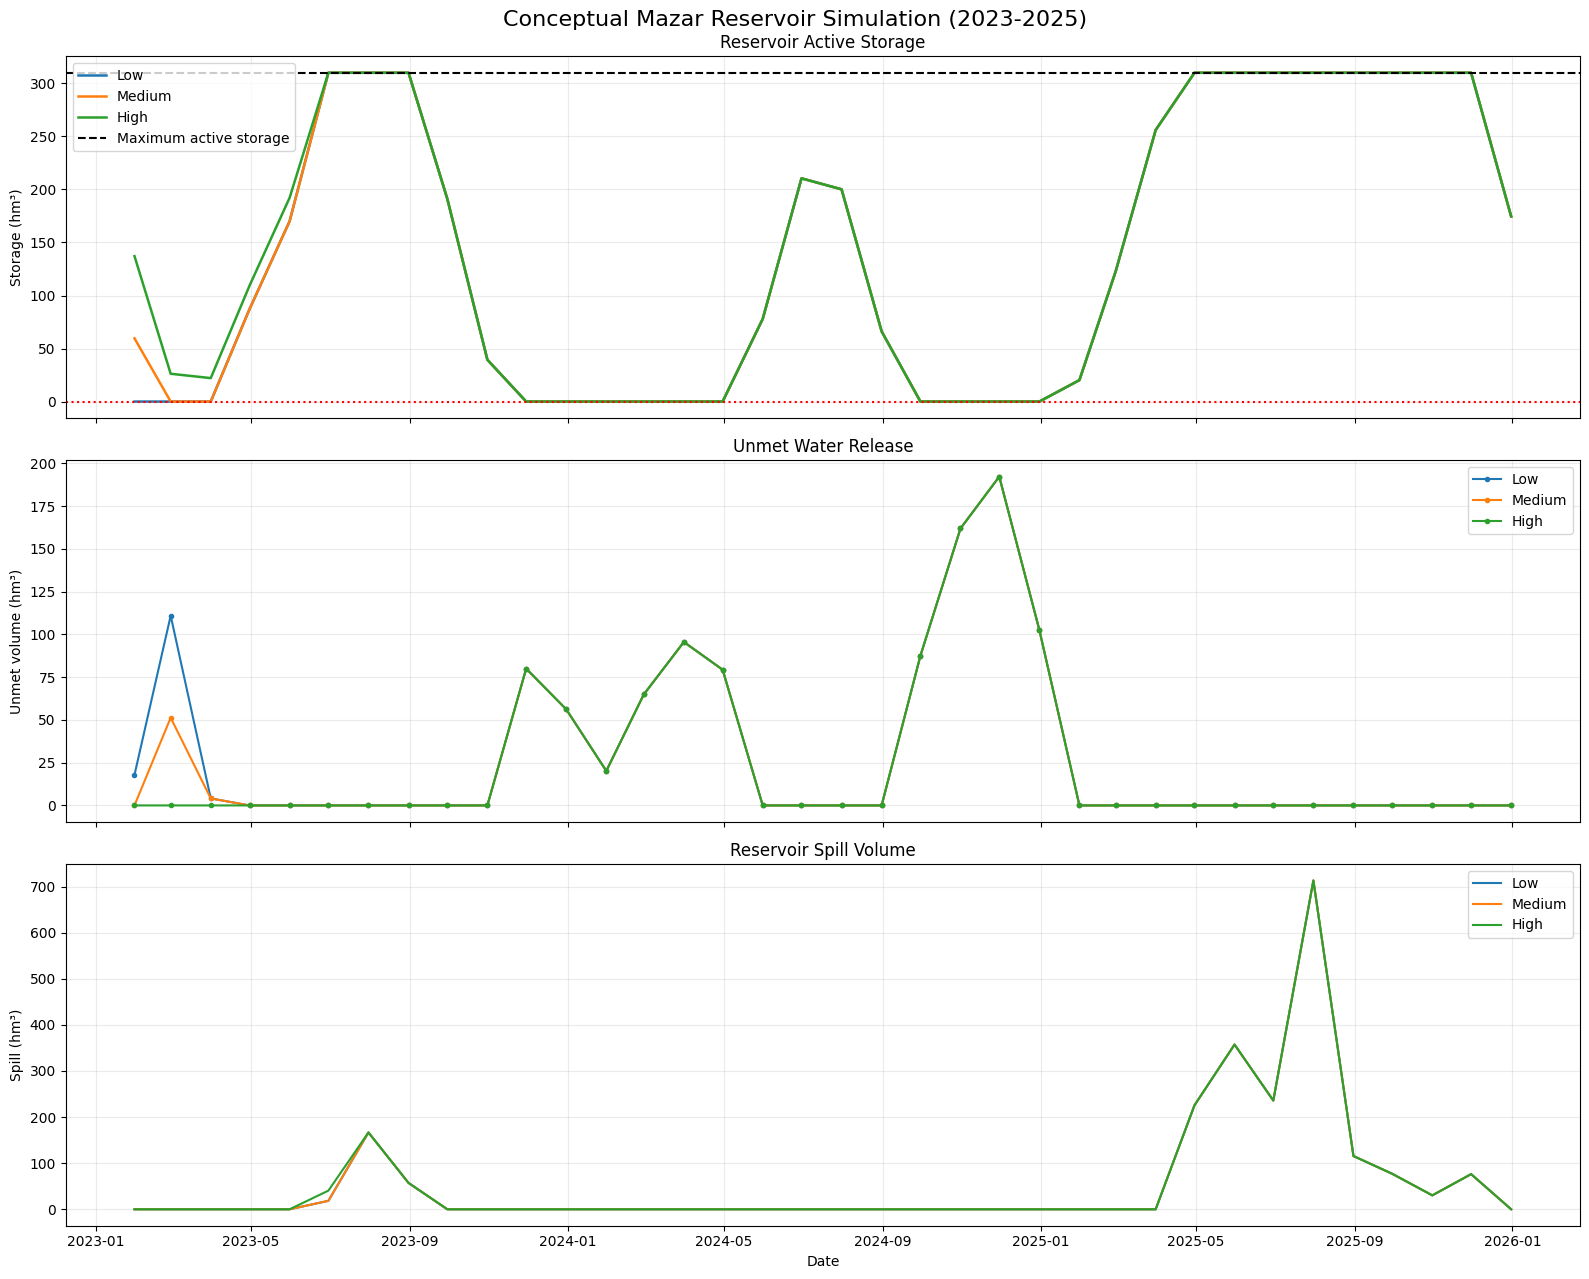

In [69]:
# Visualize reservoir storage and water shortages

fig, axes = plt.subplots(
    3, 1,
    figsize=(16, 13),
    sharex=True
)

for scenario in INITIAL_STORAGE_SCENARIOS:

    subset = reservoir_simulation.loc[
        reservoir_simulation["Scenario"] == scenario
    ]

    # Plot reservoir storage
    axes[0].plot(
        subset["Date"],
        subset["Final_storage_hm3"],
        label=scenario,
        linewidth=1.8
    )

    # Plot unmet water release
    axes[1].plot(
        subset["Date"],
        subset["Unmet_release_hm3"],
        label=scenario,
        marker="o",
        markersize=3
    )

    # Plot spill volume
    axes[2].plot(
        subset["Date"],
        subset["Spill_hm3"],
        label=scenario
    )

# Display storage limits
axes[0].axhline(
    maximum_storage,
    color="black",
    linestyle="--",
    label="Maximum active storage"
)

axes[0].axhline(
    0,
    color="red",
    linestyle=":"
)

axes[0].set_title("Reservoir Active Storage")
axes[0].set_ylabel("Storage (hm³)")

axes[1].set_title("Unmet Water Release")
axes[1].set_ylabel("Unmet volume (hm³)")

axes[2].set_title("Reservoir Spill Volume")
axes[2].set_ylabel("Spill (hm³)")
axes[2].set_xlabel("Date")

for ax in axes:

    ax.legend()
    ax.grid(alpha=0.25)

fig.suptitle(
    "Conceptual Mazar Reservoir Simulation (2023-2025)",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "reservoir_water_balance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [70]:
# . HYDROPOWER ENERGY GENERATION

# Define exploratory energy parameters
ENERGY_PARAMETERS = {
    "net_head_m": 130.0,
    "overall_efficiency": 0.90,
    "installed_capacity_mw": (
        MAZAR_PARAMETERS["installed_capacity_mw"]
    )
}

# Extract physical constants
rho = PHYSICAL_CONSTANTS["water_density_kg_m3"]
g = PHYSICAL_CONSTANTS["gravity_m_s2"]

H = ENERGY_PARAMETERS["net_head_m"]
eta = ENERGY_PARAMETERS["overall_efficiency"]

installed_capacity = ENERGY_PARAMETERS[
    "installed_capacity_mw"
]

# Verify parameter validity
assert H > 0
assert 0 < eta <= 1

# Calculate maximum flow based on installed power
power_limited_flow = (
    installed_capacity * 1e6
    / (rho * g * H * eta)
)

# Combine hydraulic and power constraints
effective_maximum_flow = min(
    MAZAR_PARAMETERS["design_flow_m3s"],
    power_limited_flow
)

# Calculate energy conversion factor
energy_conversion_factor = (
    rho * g * H * eta / 3.6e6
)

print("Exploratory energy parameters:")

display(
    pd.DataFrame(
        ENERGY_PARAMETERS.items(),
        columns=["Parameter", "Value"]
    )
)

print(
    "\nPower-limited flow:",
    round(power_limited_flow, 4),
    "m³/s"
)

print(
    "Effective maximum flow:",
    round(effective_maximum_flow, 4),
    "m³/s"
)

print(
    "Energy conversion factor:",
    round(energy_conversion_factor, 6),
    "GWh/hm³"
)

Exploratory energy parameters:


,Parameter,Value
0,net_head_m,130.0
1,overall_efficiency,0.9
2,installed_capacity_mw,170.0



Power-limited flow: 148.1133 m³/s
Effective maximum flow: 141.1 m³/s
Energy conversion factor: 0.318825 GWh/hm³


In [71]:
# Convert reservoir simulation into energy results

energy_simulation = reservoir_simulation.copy()

# Calculate monthly duration
energy_simulation["Hours_in_month"] = (
    pd.to_datetime(
        energy_simulation["Date"]
    ).dt.days_in_month * 24
)

energy_simulation["Seconds_in_month"] = (
    energy_simulation["Hours_in_month"] * 3600
)

# Calculate actual turbine flow
energy_simulation["Turbine_flow_m3s"] = (
    energy_simulation["Actual_release_hm3"]
    * 1e6
    / energy_simulation["Seconds_in_month"]
)

# Verify hydraulic feasibility
assert (
    energy_simulation["Turbine_flow_m3s"]
    <= effective_maximum_flow + 1e-8
).all(), "Water balance must be recalculated."

# Calculate average generated power
energy_simulation["Generated_power_MW"] = (
    rho * g
    * energy_simulation["Turbine_flow_m3s"]
    * H * eta
    / 1e6
)

# Calculate monthly generated energy
energy_simulation["Generated_energy_GWh"] = (
    energy_simulation["Generated_power_MW"]
    * energy_simulation["Hours_in_month"]
    / 1000
)

# Calculate energy generation target
energy_simulation["Target_energy_GWh"] = (
    energy_simulation["Requested_release_hm3"]
    * energy_conversion_factor
)

# Calculate generation shortfall
energy_simulation["Energy_shortfall_GWh"] = (
    energy_simulation["Target_energy_GWh"]
    - energy_simulation["Generated_energy_GWh"]
).clip(lower=0)

# Calculate equivalent energy associated with spill
energy_simulation["Spill_energy_equivalent_GWh"] = (
    energy_simulation["Spill_hm3"]
    * energy_conversion_factor
)

# Calculate capacity factor
energy_simulation["Capacity_factor"] = (
    energy_simulation["Generated_power_MW"]
    / installed_capacity
)

# Verify power restrictions
assert (
    energy_simulation["Generated_power_MW"]
    <= installed_capacity + 1e-8
).all()

# Verify both energy conversion methods
np.testing.assert_allclose(
    energy_simulation["Generated_energy_GWh"],
    energy_simulation["Actual_release_hm3"]
    * energy_conversion_factor
)

assert len(energy_simulation) == 108

print("Hydropower energy conversion completed.")

display(
    energy_simulation[
        [
            "Date",
            "Scenario",
            "Turbine_flow_m3s",
            "Generated_power_MW",
            "Generated_energy_GWh",
            "Target_energy_GWh",
            "Energy_shortfall_GWh",
            "Capacity_factor"
        ]
    ].head().round(4)
)

Hydropower energy conversion completed.


C:\Users\DETPC\AppData\Local\Temp\ipykernel_50104\681875179.py:97: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head().round(4)


,Date,Scenario,Turbine_flow_m3s,Generated_power_MW,Generated_energy_GWh,Target_energy_GWh,Energy_shortfall_GWh,Capacity_factor
0,2023-01-31,Low,93.3292,107.1204,79.6976,85.3941,5.6965,0.6301
1,2023-02-28,Low,54.1468,62.1481,41.7635,77.1301,35.3666,0.3656
2,2023-03-31,Low,98.4724,113.0237,84.0896,85.3941,1.3045,0.6648
3,2023-04-30,Low,100.0000,114.7770,82.6394,82.6394,0.0000,0.6752
4,2023-05-31,Low,100.0000,114.7770,85.3941,85.3941,0.0000,0.6752


In [72]:
# Evaluate hydropower energy performance

energy_summary_records = []

for scenario, subset in energy_simulation.groupby(
    "Scenario"
):

    target_energy = subset[
        "Target_energy_GWh"
    ].sum()

    generated_energy = subset[
        "Generated_energy_GWh"
    ].sum()

    energy_shortfall = subset[
        "Energy_shortfall_GWh"
    ].sum()

    shortage_months = int(
        (subset["Energy_shortfall_GWh"] > 1e-8).sum()
    )

    total_hours = subset[
        "Hours_in_month"
    ].sum()

    maximum_possible_energy = (
        installed_capacity * total_hours / 1000
    )

    energy_summary_records.append({
        "Scenario": scenario,

        "Target_energy_GWh": target_energy,

        "Generated_energy_GWh": generated_energy,

        "Energy_shortfall_GWh": energy_shortfall,

        "Spill_energy_equivalent_GWh": (
            subset["Spill_energy_equivalent_GWh"].sum()
        ),

        "Shortage_months": shortage_months,

        "Temporal_reliability": (
            1 - shortage_months / len(subset)
        ),

        "Energy_reliability": (
            generated_energy / target_energy
        ),

        "Capacity_factor": (
            generated_energy / maximum_possible_energy
        ),

        "Maximum_power_MW": (
            subset["Generated_power_MW"].max()
        )
    })

energy_summary = (
    pd.DataFrame(energy_summary_records)
    .set_index("Scenario")
)

print("Hydropower energy performance summary:")

display(energy_summary.round(4))

# Save energy simulation results
energy_simulation.to_csv(
    OUTPUT_DIR / "hydropower_energy_simulation.csv",
    index=False
)

energy_summary.to_csv(
    OUTPUT_DIR / "hydropower_energy_summary.csv"
)

# Save exploratory energy parameters
with open(
    OUTPUT_DIR / "energy_parameters.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        ENERGY_PARAMETERS,
        file,
        indent=4
    )

print("\nHydropower energy results saved successfully.")

Hydropower energy performance summary:


,Target_energy_GWh,Generated_energy_GWh,Energy_shortfall_GWh,Spill_energy_equivalent_GWh,Shortage_months,Temporal_reliability,Energy_reliability,Capacity_factor,Maximum_power_MW
Scenario,,,,,,,,,
High,3019.0942,2719.2740,299.8202,667.8320,10,0.7222,0.9007,0.6081,114.777
Low,3019.0942,2676.9065,342.1878,660.7816,13,0.6389,0.8867,0.5986,114.777
Medium,3019.0942,2701.6154,317.4788,660.7816,12,0.6667,0.8948,0.6042,114.777



Hydropower energy results saved successfully.


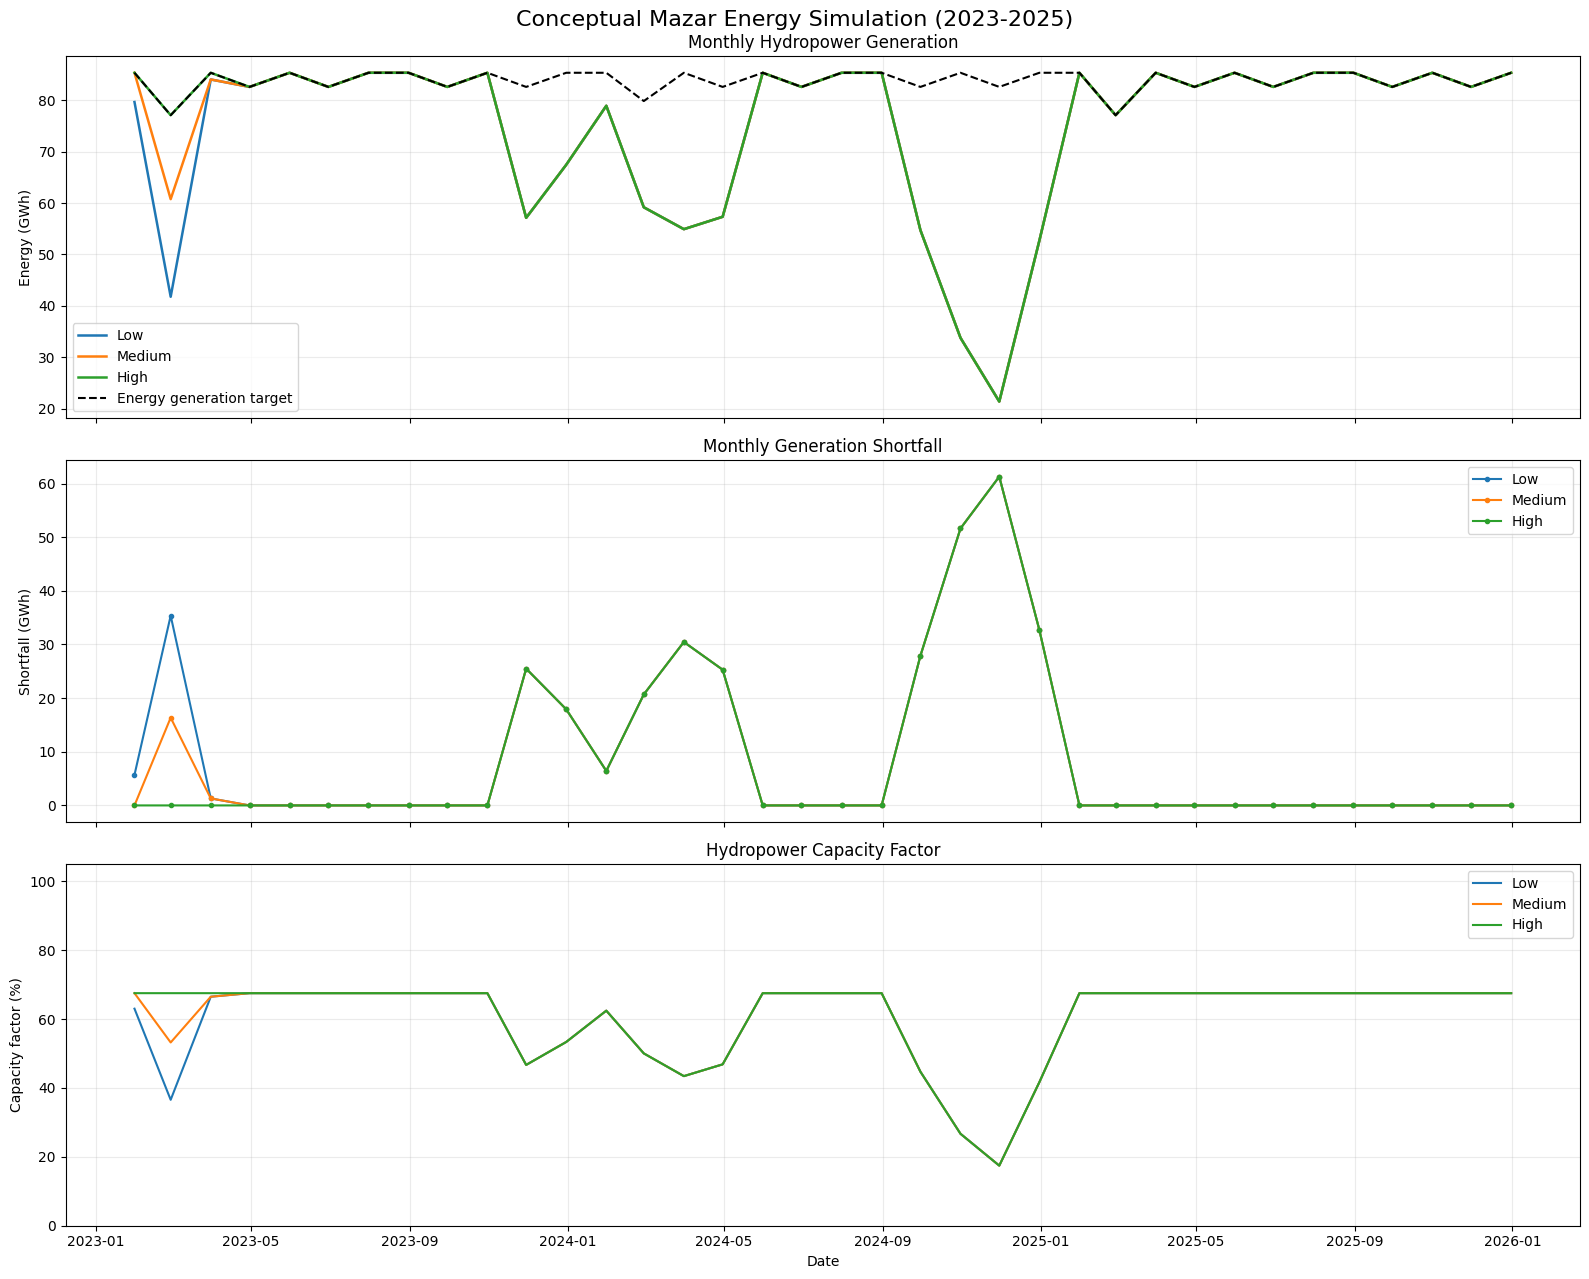

Hydropower energy analysis: COMPLETED


In [73]:
# Visualize hydropower energy performance

fig, axes = plt.subplots(
    3, 1,
    figsize=(16, 13),
    sharex=True
)

for scenario in INITIAL_STORAGE_SCENARIOS:

    subset = energy_simulation.loc[
        energy_simulation["Scenario"] == scenario
    ].sort_values("Date")

    axes[0].plot(
        subset["Date"],
        subset["Generated_energy_GWh"],
        label=scenario,
        linewidth=1.8
    )

    axes[1].plot(
        subset["Date"],
        subset["Energy_shortfall_GWh"],
        label=scenario,
        marker="o",
        markersize=3
    )

    axes[2].plot(
        subset["Date"],
        subset["Capacity_factor"] * 100,
        label=scenario
    )

# Plot energy generation target
reference = energy_simulation.loc[
    energy_simulation["Scenario"] == "Medium"
].sort_values("Date")

axes[0].plot(
    reference["Date"],
    reference["Target_energy_GWh"],
    color="black",
    linestyle="--",
    label="Energy generation target"
)

axes[0].set_title("Monthly Hydropower Generation")
axes[0].set_ylabel("Energy (GWh)")

axes[1].set_title("Monthly Generation Shortfall")
axes[1].set_ylabel("Shortfall (GWh)")

axes[2].set_title("Hydropower Capacity Factor")
axes[2].set_ylabel("Capacity factor (%)")
axes[2].set_xlabel("Date")
axes[2].set_ylim(0, 105)

for ax in axes:

    ax.legend()
    ax.grid(alpha=0.25)

fig.suptitle(
    "Conceptual Mazar Energy Simulation (2023-2025)",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "hydropower_energy_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Hydropower energy analysis: COMPLETED")

In [74]:
# FORECAST-BASED RESERVOIR OPERATION

RESERVE_FRACTION = 0.25

RESERVE_HM3 = (
    RESERVE_FRACTION
    * MAZAR_PARAMETERS["active_storage_hm3"]
)

INITIAL_STORAGE_HM3 = (
    0.50 * MAZAR_PARAMETERS["active_storage_hm3"]
)

# Define reference operating strategies
OPERATING_STRATEGIES = {
    "Constant operation": {
        "type": "constant"
    },

    "Storage only": {
        "type": "storage"
    },

    "Perfect monthly information": {
        "type": "perfect"
    }
}

# Include all point forecasting models
for model_name in FINAL_MODEL_NAMES:

    OPERATING_STRATEGIES[f"{model_name} - Point"] = {
        "type": "forecast",
        "model": model_name,
        "volume_column": "Point_volume_hm3"
    }

# Include uncertainty-based strategies
CONSERVATIVE_MODELS = [
    "Persistence",
    "SARIMA",
    "Random Forest Full",
    "XGBoost Full"
]

for model_name in CONSERVATIVE_MODELS:

    OPERATING_STRATEGIES[
        f"{model_name} - Conservative"
    ] = {
        "type": "forecast",
        "model": model_name,
        "volume_column": "Conservative_volume_hm3"
    }

print("Number of operating strategies:",
      len(OPERATING_STRATEGIES))

print("Preventive reserve:", RESERVE_HM3, "hm³")

print("Initial storage:", INITIAL_STORAGE_HM3, "hm³")

for strategy in OPERATING_STRATEGIES:

    print("-", strategy)

assert len(OPERATING_STRATEGIES) == 15

Number of operating strategies: 15
Preventive reserve: 77.5 hm³
Initial storage: 155.0 hm³
- Constant operation
- Storage only
- Perfect monthly information
- Persistence - Point
- Seasonal Naive - Point
- Monthly Climatology - Point
- SARIMA - Point
- Random Forest Full - Point
- Random Forest Reduced - Point
- XGBoost Full - Point
- XGBoost Reduced - Point
- Persistence - Conservative
- SARIMA - Conservative
- Random Forest Full - Conservative
- XGBoost Full - Conservative


In [75]:
# Define forecast-based reservoir simulation

def simulate_operating_strategy(
    strategy_name,
    configuration,
    initial_storage,
    reserve_volume
):

    current_storage = initial_storage

    records = []

    # Prepare forecast information
    if configuration["type"] == "forecast":

        forecast_data = (
            hydrological_scenarios.loc[
                hydrological_scenarios["Model"]
                == configuration["model"]
            ]
            .set_index("Date")
            .sort_index()
        )

        assert forecast_data.index.is_unique

    # Simulate consecutive months
    for _, row in observed_hydrology.iterrows():

        date = row["Date"]

        seconds = row["Seconds_in_month"]

        actual_inflow = row["Observed_volume_hm3"]

        # Maintain a common generation target
        target_release = (
            REFERENCE_RELEASE_M3S
            * seconds
            / 1e6
        )

        maximum_release = (
            effective_maximum_flow
            * seconds
            / 1e6
        )

        # Determine planned release
        if configuration["type"] == "constant":

            expected_inflow = np.nan

            planned_release = target_release

        else:

            if configuration["type"] == "storage":

                expected_inflow = 0.0

            elif configuration["type"] == "perfect":

                expected_inflow = actual_inflow

            else:

                expected_inflow = float(
                    forecast_data.loc[
                        date,
                        configuration["volume_column"]
                    ]
                )

            # Apply preventive reserve rule
            planned_release = min(
                target_release,
                max(
                    0,
                    current_storage
                    + expected_inflow
                    - reserve_volume
                )
            )

        # Apply physical reservoir balance
        balance = reservoir_water_balance(
            initial_storage=current_storage,
            inflow_volume=actual_inflow,
            requested_release=planned_release,
            maximum_storage=MAZAR_PARAMETERS[
                "active_storage_hm3"
            ],
            maximum_release=maximum_release
        )

        actual_release = balance[
            "Actual_release_hm3"
        ]

        # Separate preventive and physical shortfalls
        preventive_shortfall = max(
            0,
            target_release - planned_release
        )

        physical_shortfall = max(
            0,
            planned_release - actual_release
        )

        total_shortfall = (
            preventive_shortfall
            + physical_shortfall
        )

        # Verify common-target accounting
        assert np.isclose(
            total_shortfall,
            target_release - actual_release
        )

        # Convert water volumes into energy
        target_energy = (
            target_release
            * energy_conversion_factor
        )

        generated_energy = (
            actual_release
            * energy_conversion_factor
        )

        energy_shortfall = (
            total_shortfall
            * energy_conversion_factor
        )

        # Record simulation results
        records.append({
            "Date": date,
            "Period": row["Period"],
            "Strategy": strategy_name,

            "Forecast_inflow_hm3": expected_inflow,
            "Reserve_hm3": reserve_volume,

            "Target_release_hm3": target_release,
            "Planned_release_hm3": planned_release,

            **balance,

            "Preventive_shortfall_hm3":
                preventive_shortfall,

            "Physical_shortfall_hm3":
                physical_shortfall,

            "Total_shortfall_hm3":
                total_shortfall,

            "Target_energy_GWh":
                target_energy,

            "Generated_energy_GWh":
                generated_energy,

            "Energy_shortfall_GWh":
                energy_shortfall,

            "Preventive_shortfall_GWh": (
                preventive_shortfall
                * energy_conversion_factor
            ),

            "Physical_shortfall_GWh": (
                physical_shortfall
                * energy_conversion_factor
            )
        })

        # Update reservoir state
        current_storage = balance[
            "Final_storage_hm3"
        ]

    return pd.DataFrame(records)


print("Adaptive operating function created successfully.")

Adaptive operating function created successfully.


In [76]:
# Execute all operating strategies

operation_records = []

for strategy_name, configuration in (
    OPERATING_STRATEGIES.items()
):

    result = simulate_operating_strategy(
        strategy_name=strategy_name,
        configuration=configuration,
        initial_storage=INITIAL_STORAGE_HM3,
        reserve_volume=RESERVE_HM3
    )

    operation_records.append(result)

    print(f"Completed: {strategy_name}")

# Combine all simulations
operation_simulation = pd.concat(
    operation_records,
    ignore_index=True
)

# Verify simulation dimensions
assert len(operation_simulation) == 540

# Verify mass conservation
assert np.allclose(
    operation_simulation["Balance_error_hm3"],
    0,
    atol=1e-8
)

# Verify common energy target
np.testing.assert_allclose(
    operation_simulation["Target_energy_GWh"],
    operation_simulation["Generated_energy_GWh"]
    + operation_simulation["Energy_shortfall_GWh"]
)

# Verify physical restrictions
assert (
    operation_simulation["Final_storage_hm3"] >= 0
).all()

assert (
    operation_simulation["Final_storage_hm3"]
    <= MAZAR_PARAMETERS["active_storage_hm3"] + 1e-8
).all()

assert (
    operation_simulation["Actual_release_hm3"]
    <= operation_simulation["Maximum_release_hm3"] + 1e-8
).all()

# Verify reproduction of the previous baseline
constant_results = (
    operation_simulation.loc[
        operation_simulation["Strategy"]
        == "Constant operation"
    ]
    .sort_values("Date")
)

previous_medium_results = (
    energy_simulation.loc[
        energy_simulation["Scenario"] == "Medium"
    ]
    .sort_values("Date")
)

np.testing.assert_allclose(
    constant_results["Generated_energy_GWh"],
    previous_medium_results["Generated_energy_GWh"]
)

print("\nSimulation records:", len(operation_simulation))

print("Mass conservation: PASSED")

print("Energy accounting: PASSED")

print("Baseline reproducibility: PASSED")

Completed: Constant operation
Completed: Storage only
Completed: Perfect monthly information
Completed: Persistence - Point
Completed: Seasonal Naive - Point
Completed: Monthly Climatology - Point
Completed: SARIMA - Point
Completed: Random Forest Full - Point
Completed: Random Forest Reduced - Point
Completed: XGBoost Full - Point
Completed: XGBoost Reduced - Point
Completed: Persistence - Conservative
Completed: SARIMA - Conservative
Completed: Random Forest Full - Conservative
Completed: XGBoost Full - Conservative

Simulation records: 540
Mass conservation: PASSED
Energy accounting: PASSED
Baseline reproducibility: PASSED


In [77]:
# Summarize operating strategy performance

def summarize_operation(simulation):

    summary_records = []

    for strategy, subset in simulation.groupby(
        "Strategy"
    ):

        subset = subset.sort_values("Date")

        target = subset[
            "Target_energy_GWh"
        ].sum()

        generated = subset[
            "Generated_energy_GWh"
        ].sum()

        shortfall = subset[
            "Energy_shortfall_GWh"
        ].sum()

        shortage_months = int(
            (subset["Energy_shortfall_GWh"] > 1e-8).sum()
        )

        summary_records.append({
            "Strategy": strategy,

            "Target_energy_GWh": target,

            "Generated_energy_GWh": generated,

            "Energy_shortfall_GWh": shortfall,

            "Preventive_shortfall_GWh": (
                subset["Preventive_shortfall_GWh"].sum()
            ),

            "Physical_shortfall_GWh": (
                subset["Physical_shortfall_GWh"].sum()
            ),

            "Maximum_monthly_shortfall_GWh": (
                subset["Energy_shortfall_GWh"].max()
            ),

            "Shortage_months": shortage_months,

            "Temporal_reliability": (
                1 - shortage_months / len(subset)
            ),

            "Energy_reliability": (
                generated / target
            ),

            "Minimum_storage_hm3": (
                subset["Final_storage_hm3"].min()
            ),

            "Mean_storage_hm3": (
                subset["Final_storage_hm3"].mean()
            ),

            "Final_storage_hm3": (
                subset["Final_storage_hm3"].iloc[-1]
            ),

            "Total_spill_hm3": (
                subset["Spill_hm3"].sum()
            ),

            "Empty_storage_months": int(
                (
                    subset["Final_storage_hm3"] <= 1e-8
                ).sum()
            )
        })

    summary = (
        pd.DataFrame(summary_records)
        .set_index("Strategy")
    )

    # Compare against constant operation
    baseline_shortfall = summary.loc[
        "Constant operation",
        "Energy_shortfall_GWh"
    ]

    summary["Shortfall_reduction_GWh"] = (
        baseline_shortfall
        - summary["Energy_shortfall_GWh"]
    )

    summary["Shortfall_reduction_percent"] = (
        100
        * summary["Shortfall_reduction_GWh"]
        / baseline_shortfall
        if baseline_shortfall > 0
        else np.nan
    )

    return summary.sort_values(
        "Energy_shortfall_GWh"
    )


# Evaluate the complete simulation period
operation_summary = summarize_operation(
    operation_simulation
)

print("Operating strategy comparison (2023-2025):")

display(operation_summary.round(4))

# Evaluate each period separately
period_operation_records = []

for period, subset in operation_simulation.groupby(
    "Period"
):

    period_summary = summarize_operation(subset)

    period_summary["Period"] = period

    period_operation_records.append(
        period_summary.reset_index()
    )

    print(f"\nOperating performance - {period}:")

    display(period_summary.round(4))

operation_period_summary = pd.concat(
    period_operation_records,
    ignore_index=True
)

# Save results
operation_simulation.to_csv(
    OUTPUT_DIR / "adaptive_operation_simulation.csv",
    index=False
)

operation_summary.to_csv(
    OUTPUT_DIR / "adaptive_operation_summary.csv"
)

operation_period_summary.to_csv(
    OUTPUT_DIR / "adaptive_operation_periods.csv",
    index=False
)

print("\nAdaptive operation results saved successfully.")

Operating strategy comparison (2023-2025):


,Target_energy_GWh,Generated_energy_GWh,Energy_shortfall_GWh,Preventive_shortfall_GWh,Physical_shortfall_GWh,Maximum_monthly_shortfall_GWh,Shortage_months,Temporal_reliability,Energy_reliability,Minimum_storage_hm3,Mean_storage_hm3,Final_storage_hm3,Total_spill_hm3,Empty_storage_months,Shortfall_reduction_GWh,Shortfall_reduction_percent
Strategy,,,,,,,,,,,,,,,,
Constant operation,3019.0942,2701.6154,317.4788,0.0000,317.4788,61.2872,12,0.6667,0.8948,0.0000,141.2605,174.5238,2072.5528,12,0.0000,0.0000
Perfect monthly information,3019.0942,2652.1975,366.8967,366.8967,0.0000,61.2872,14,0.6111,0.8785,77.5000,187.3690,174.5238,2227.5528,0,-49.4179,-15.5657
Seasonal Naive - Point,3019.0942,2640.7143,378.3799,363.2697,15.1103,60.8141,13,0.6389,0.8747,0.0000,176.5609,174.5238,2263.5701,1,-60.9011,-19.1827
Monthly Climatology - Point,3019.0942,2628.4664,390.6278,307.7141,82.9137,61.2872,13,0.6389,0.8706,0.0000,169.2346,174.5238,2301.9859,6,-73.1490,-23.0406
SARIMA - Point,3019.0942,2626.2627,392.8315,339.0042,53.8273,61.2872,13,0.6389,0.8699,0.0000,170.7486,174.5238,2308.8978,6,-75.3527,-23.7347
XGBoost Full - Point,3019.0942,2620.7344,398.3598,349.9026,48.4572,61.2872,13,0.6389,0.8681,0.0000,169.8334,174.5238,2326.2374,4,-80.8810,-25.4760
XGBoost Reduced - Point,3019.0942,2620.4031,398.6912,349.5054,49.1857,61.2872,13,0.6389,0.8679,0.0000,169.8727,174.5238,2327.2767,4,-81.2123,-25.5804
Random Forest Full - Point,3019.0942,2619.4711,399.6231,348.7132,50.9099,61.2872,13,0.6389,0.8676,0.0000,173.4402,174.5238,2330.1997,4,-82.1443,-25.8739
Random Forest Reduced - Point,3019.0942,2612.4771,406.6171,364.7775,41.8396,61.2872,13,0.6389,0.8653,0.0000,174.4669,174.5238,2352.1364,4,-89.1383,-28.0769



Operating performance - Complementary 2025:


,Target_energy_GWh,Generated_energy_GWh,Energy_shortfall_GWh,Preventive_shortfall_GWh,Physical_shortfall_GWh,Maximum_monthly_shortfall_GWh,Shortage_months,Temporal_reliability,Energy_reliability,Minimum_storage_hm3,Mean_storage_hm3,Final_storage_hm3,Total_spill_hm3,Empty_storage_months,Shortfall_reduction_GWh,Shortfall_reduction_percent,Period
Strategy,,,,,,,,,,,,,,,,,
Constant operation,1005.4465,1005.4465,0.0000,0.0000,0.0,0.0000,0,1.0000,1.0000,20.1990,254.4456,174.5238,1830.4479,0,0.0000,NaN,Complementary 2025
Perfect monthly information,1005.4465,1005.4465,0.0000,0.0000,0.0,0.0000,0,1.0000,1.0000,97.6990,271.8580,174.5238,1907.9479,0,0.0000,NaN,Complementary 2025
Persistence - Point,1005.4465,1003.3542,2.0923,2.0923,0.0,2.0923,1,0.9167,0.9979,174.5238,288.9579,174.5238,2010.5472,0,-2.0923,NaN,Complementary 2025
SARIMA - Conservative,1005.4465,977.8246,27.6220,27.6220,0.0,27.6220,1,0.9167,0.9725,174.5238,298.0482,174.5238,2112.3031,0,-27.6220,NaN,Complementary 2025
SARIMA - Point,1005.4465,977.8246,27.6220,27.6220,0.0,27.6220,1,0.9167,0.9725,174.5238,286.7223,174.5238,1997.1334,0,-27.6220,NaN,Complementary 2025
Seasonal Naive - Point,1005.4465,977.1159,28.3307,28.3307,0.0,21.2219,2,0.8333,0.9718,117.8573,277.0758,174.5238,1950.4031,0,-28.3307,NaN,Complementary 2025
Random Forest Full - Point,1005.4465,977.0770,28.3695,28.3695,0.0,28.3695,1,0.9167,0.9718,168.6800,283.6882,174.5238,1978.9289,0,-28.3695,NaN,Complementary 2025
Random Forest Full - Conservative,1005.4465,977.0770,28.3695,28.3695,0.0,28.3695,1,0.9167,0.9718,174.5238,296.8980,174.5238,2098.5008,0,-28.3695,NaN,Complementary 2025
XGBoost Full - Point,1005.4465,974.8983,30.5483,30.5483,0.0,30.5483,1,0.9167,0.9696,157.9139,281.8939,174.5238,1968.1628,0,-30.5483,NaN,Complementary 2025



Operating performance - Testing 2023-2024:


,Target_energy_GWh,Generated_energy_GWh,Energy_shortfall_GWh,Preventive_shortfall_GWh,Physical_shortfall_GWh,Maximum_monthly_shortfall_GWh,Shortage_months,Temporal_reliability,Energy_reliability,Minimum_storage_hm3,Mean_storage_hm3,Final_storage_hm3,Total_spill_hm3,Empty_storage_months,Shortfall_reduction_GWh,Shortfall_reduction_percent,Period
Strategy,,,,,,,,,,,,,,,,,
Constant operation,2013.6477,1696.1689,317.4788,0.0000,317.4788,61.2872,12,0.5000,0.8423,0.0000,84.6680,0.0000,242.1049,12,0.0000,0.0000,Testing 2023-2024
Seasonal Naive - Point,2013.6477,1663.5984,350.0493,334.9390,15.1103,60.8141,11,0.5417,0.8262,0.0000,126.3035,31.0955,313.1671,1,-32.5704,-10.2591,Testing 2023-2024
Monthly Climatology - Point,2013.6477,1660.7421,352.9056,269.9919,82.9137,61.2872,12,0.5000,0.8247,0.0000,109.8660,55.8654,297.3560,6,-35.4268,-11.1588,Testing 2023-2024
SARIMA - Point,2013.6477,1648.4381,365.2096,311.3823,53.8273,61.2872,12,0.5000,0.8186,0.0000,112.7618,80.0488,311.7644,6,-47.7308,-15.0343,Testing 2023-2024
Perfect monthly information,2013.6477,1646.7510,366.8967,366.8967,0.0000,61.2872,14,0.4167,0.8178,77.5000,145.1245,77.5000,319.6049,0,-49.4179,-15.5657,Testing 2023-2024
XGBoost Reduced - Point,2013.6477,1645.8853,367.7624,318.5767,49.1857,61.2872,12,0.5000,0.8174,0.0000,113.7210,42.4001,357.4201,4,-50.2836,-15.8384,Testing 2023-2024
XGBoost Full - Point,2013.6477,1645.8361,367.8116,319.3544,48.4572,61.2872,12,0.5000,0.8173,0.0000,113.8032,41.8998,358.0746,4,-50.3327,-15.8539,Testing 2023-2024
Random Forest Full - Point,2013.6477,1642.3941,371.2536,320.3437,50.9099,61.2872,12,0.5000,0.8156,0.0000,118.3163,59.4995,351.2708,4,-53.7748,-16.9381,Testing 2023-2024
Random Forest Reduced - Point,2013.6477,1637.9664,375.6813,333.8417,41.8396,61.2872,12,0.5000,0.8134,0.0000,118.7641,64.5559,360.1021,4,-58.2025,-18.3327,Testing 2023-2024



Adaptive operation results saved successfully.


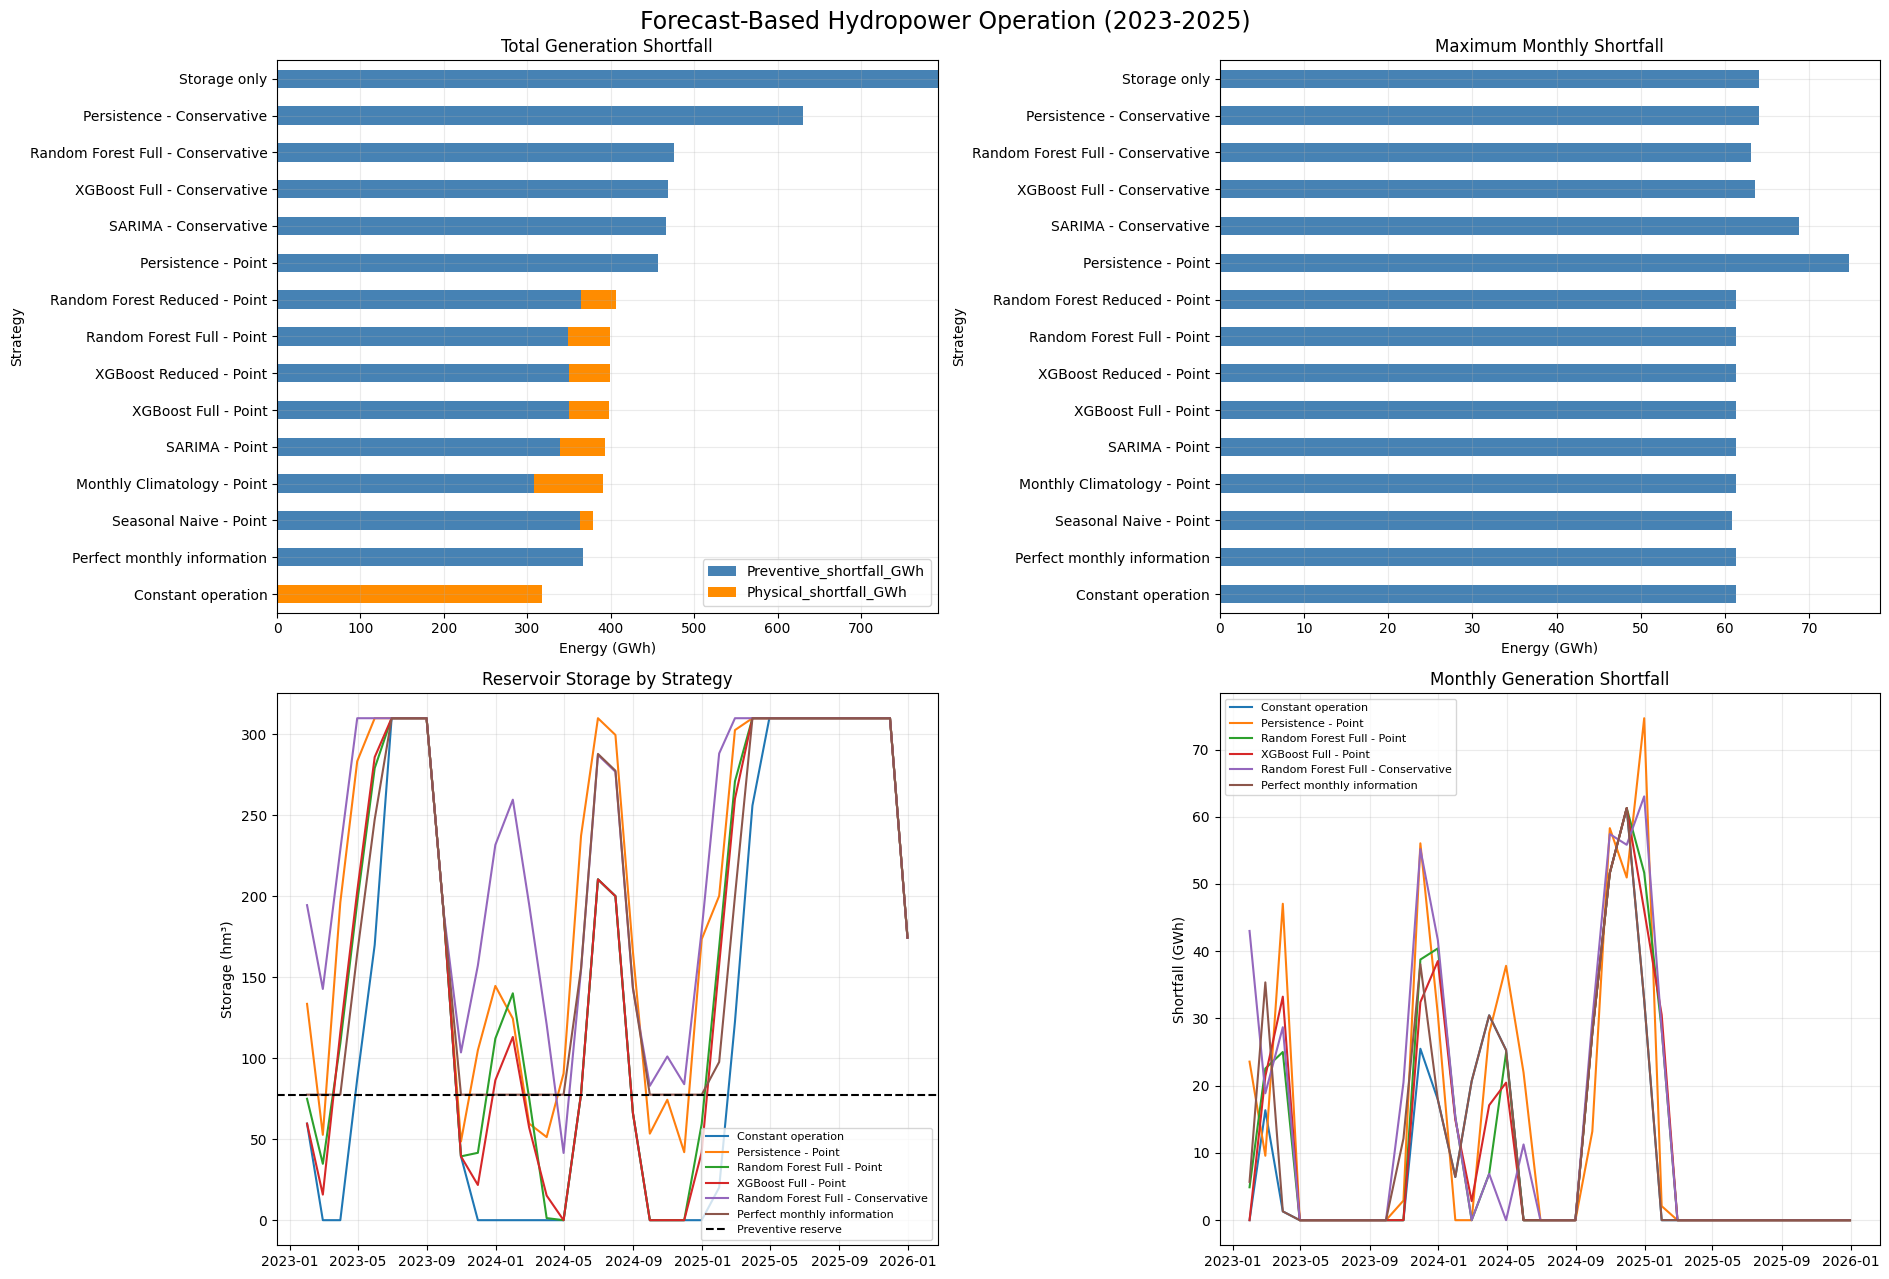

Forecast-based operation: COMPLETED


In [78]:
# Visualize operating strategy performance

fig, axes = plt.subplots(
    2, 2,
    figsize=(19, 13)
)

# Compare total energy shortfalls
operation_summary[
    [
        "Preventive_shortfall_GWh",
        "Physical_shortfall_GWh"
    ]
].plot(
    kind="barh",
    stacked=True,
    ax=axes[0, 0],
    color=["steelblue", "darkorange"]
)

axes[0, 0].set_title("Total Generation Shortfall")
axes[0, 0].set_xlabel("Energy (GWh)")

# Compare maximum monthly shortfall
operation_summary[
    "Maximum_monthly_shortfall_GWh"
].plot(
    kind="barh",
    ax=axes[0, 1],
    color="steelblue"
)

axes[0, 1].set_title("Maximum Monthly Shortfall")
axes[0, 1].set_xlabel("Energy (GWh)")

# Select strategies for temporal visualization
PLOT_STRATEGIES = [
    "Constant operation",
    "Persistence - Point",
    "Random Forest Full - Point",
    "XGBoost Full - Point",
    "Random Forest Full - Conservative",
    "Perfect monthly information"
]

for strategy in PLOT_STRATEGIES:

    subset = operation_simulation.loc[
        operation_simulation["Strategy"] == strategy
    ].sort_values("Date")

    # Plot reservoir storage
    axes[1, 0].plot(
        subset["Date"],
        subset["Final_storage_hm3"],
        label=strategy
    )

    # Plot monthly energy shortfall
    axes[1, 1].plot(
        subset["Date"],
        subset["Energy_shortfall_GWh"],
        label=strategy
    )

axes[1, 0].axhline(
    RESERVE_HM3,
    color="black",
    linestyle="--",
    label="Preventive reserve"
)

axes[1, 0].set_title("Reservoir Storage by Strategy")
axes[1, 0].set_ylabel("Storage (hm³)")
axes[1, 0].legend(fontsize=8)

axes[1, 1].set_title("Monthly Generation Shortfall")
axes[1, 1].set_ylabel("Shortfall (GWh)")
axes[1, 1].legend(fontsize=8)

for ax in axes.flat:

    ax.grid(alpha=0.25)

fig.suptitle(
    "Forecast-Based Hydropower Operation (2023-2025)",
    fontsize=17
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "forecast_based_operation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Forecast-based operation: COMPLETED")

In [79]:
# . OPERATING STRATEGY SENSITIVITY ANALYSIS

from itertools import product

# Define experimental parameter ranges
RESERVE_FRACTIONS = [
    0.00, 0.10, 0.25, 0.40, 0.50
]

INITIAL_FRACTIONS = [
    0.25, 0.50, 0.75
]

storage_capacity = MAZAR_PARAMETERS[
    "active_storage_hm3"
]

sensitivity_records = []

# Evaluate all parameter combinations
for initial_fraction, reserve_fraction in product(
    INITIAL_FRACTIONS,
    RESERVE_FRACTIONS
):

    initial_storage = (
        initial_fraction * storage_capacity
    )

    reserve_volume = (
        reserve_fraction * storage_capacity
    )

    print(
        f"Initial storage: {initial_fraction:.0%} | "
        f"Reserve: {reserve_fraction:.0%}"
    )

    for strategy_name, configuration in (
        OPERATING_STRATEGIES.items()
    ):

        # Simulate operating strategy
        result = simulate_operating_strategy(
            strategy_name=strategy_name,
            configuration=configuration,
            initial_storage=initial_storage,
            reserve_volume=reserve_volume
        )

        # Record experimental configuration
        result["Initial_storage_fraction"] = (
            initial_fraction
        )

        result["Reserve_fraction"] = (
            reserve_fraction
        )

        sensitivity_records.append(result)

# Combine sensitivity simulations
sensitivity_simulation = pd.concat(
    sensitivity_records,
    ignore_index=True
)

# Verify experimental completeness
expected_simulations = (
    len(INITIAL_FRACTIONS)
    * len(RESERVE_FRACTIONS)
    * len(OPERATING_STRATEGIES)
)

expected_records = (
    expected_simulations
    * len(observed_hydrology)
)

assert expected_simulations == 225

assert len(sensitivity_simulation) == expected_records

# Verify physical consistency
assert np.allclose(
    sensitivity_simulation["Balance_error_hm3"],
    0,
    atol=1e-8
)

np.testing.assert_allclose(
    sensitivity_simulation["Target_energy_GWh"],
    sensitivity_simulation["Generated_energy_GWh"]
    + sensitivity_simulation["Energy_shortfall_GWh"]
)

assert (
    sensitivity_simulation["Final_storage_hm3"]
    >= 0
).all()

assert (
    sensitivity_simulation["Final_storage_hm3"]
    <= storage_capacity + 1e-8
).all()

print("\nTotal simulations:", expected_simulations)

print("Total records:", len(sensitivity_simulation))

print("Mass conservation: PASSED")
print("Energy accounting: PASSED")
print("Storage restrictions: PASSED")

Initial storage: 25% | Reserve: 0%
Initial storage: 25% | Reserve: 10%
Initial storage: 25% | Reserve: 25%
Initial storage: 25% | Reserve: 40%
Initial storage: 25% | Reserve: 50%
Initial storage: 50% | Reserve: 0%
Initial storage: 50% | Reserve: 10%
Initial storage: 50% | Reserve: 25%
Initial storage: 50% | Reserve: 40%
Initial storage: 50% | Reserve: 50%
Initial storage: 75% | Reserve: 0%
Initial storage: 75% | Reserve: 10%
Initial storage: 75% | Reserve: 25%
Initial storage: 75% | Reserve: 40%
Initial storage: 75% | Reserve: 50%

Total simulations: 225
Total records: 8100
Mass conservation: PASSED
Energy accounting: PASSED
Storage restrictions: PASSED


In [80]:
# Summarize sensitivity analysis results

sensitivity_summary_records = []

group_columns = [
    "Initial_storage_fraction",
    "Reserve_fraction",
    "Strategy"
]

for group, subset in sensitivity_simulation.groupby(
    group_columns
):

    initial_fraction, reserve_fraction, strategy = group

    subset = subset.sort_values("Date")

    target = subset["Target_energy_GWh"].sum()

    generated = subset["Generated_energy_GWh"].sum()

    shortfalls = subset["Energy_shortfall_GWh"]

    shortage_months = int(
        (shortfalls > 1e-8).sum()
    )

    rms_shortfall = np.sqrt(
        np.mean(shortfalls ** 2)
    )

    sensitivity_summary_records.append({
        "Strategy": strategy,

        "Initial_storage_fraction":
            initial_fraction,

        "Reserve_fraction":
            reserve_fraction,

        "Target_energy_GWh":
            target,

        "Generated_energy_GWh":
            generated,

        "Total_shortfall_GWh":
            shortfalls.sum(),

        "Maximum_shortfall_GWh":
            shortfalls.max(),

        "RMS_shortfall_GWh":
            rms_shortfall,

        "Shortage_months":
            shortage_months,

        "Temporal_reliability":
            1 - shortage_months / len(subset),

        "Energy_reliability":
            generated / target,

        "Mean_storage_hm3":
            subset["Final_storage_hm3"].mean(),

        "Final_storage_hm3":
            subset["Final_storage_hm3"].iloc[-1],

        "Total_spill_hm3":
            subset["Spill_hm3"].sum(),

        "Empty_storage_months": int(
            (
                subset["Final_storage_hm3"] <= 1e-8
            ).sum()
        ),

        "Below_reserve_months": int(
            (
                subset["Final_storage_hm3"]
                < subset["Reserve_hm3"] - 1e-8
            ).sum()
        )
    })

sensitivity_summary = pd.DataFrame(
    sensitivity_summary_records
)

assert len(sensitivity_summary) == 225

# Extract matched constant-operation references
baseline_reference = (
    sensitivity_summary.loc[
        sensitivity_summary["Strategy"]
        == "Constant operation",
        [
            "Initial_storage_fraction",
            "Reserve_fraction",
            "Total_shortfall_GWh",
            "Maximum_shortfall_GWh",
            "RMS_shortfall_GWh"
        ]
    ]
    .rename(columns={
        "Total_shortfall_GWh":
            "Baseline_total_shortfall",

        "Maximum_shortfall_GWh":
            "Baseline_maximum_shortfall",

        "RMS_shortfall_GWh":
            "Baseline_RMS_shortfall"
    })
)

# Match each strategy to its corresponding baseline
sensitivity_summary = sensitivity_summary.merge(
    baseline_reference,
    on=[
        "Initial_storage_fraction",
        "Reserve_fraction"
    ],
    validate="many_to_one"
)

# Calculate improvements relative to constant operation
sensitivity_summary["Total_shortfall_reduction_GWh"] = (
    sensitivity_summary["Baseline_total_shortfall"]
    - sensitivity_summary["Total_shortfall_GWh"]
)

sensitivity_summary["Maximum_shortfall_reduction_GWh"] = (
    sensitivity_summary["Baseline_maximum_shortfall"]
    - sensitivity_summary["Maximum_shortfall_GWh"]
)

sensitivity_summary["RMS_shortfall_reduction_GWh"] = (
    sensitivity_summary["Baseline_RMS_shortfall"]
    - sensitivity_summary["RMS_shortfall_GWh"]
)

print("Sensitivity summary completed successfully.")

print("Configurations evaluated:", len(sensitivity_summary))

Sensitivity summary completed successfully.
Configurations evaluated: 225


In [81]:
# Identify the main sensitivity findings

# Reproduce the original experimental configuration
original_configuration = sensitivity_summary.loc[
    (
        sensitivity_summary["Initial_storage_fraction"]
        == 0.50
    )
    & (
        sensitivity_summary["Reserve_fraction"]
        == 0.25
    )
].copy()

# Verify reproduction of Cell 31
original_check = (
    original_configuration
    .set_index("Strategy")
    .reindex(operation_summary.index)
)

np.testing.assert_allclose(
    original_check["Total_shortfall_GWh"],
    operation_summary["Energy_shortfall_GWh"]
)

print("Original configuration reproducibility: PASSED")

# Define relevant display columns
display_columns = [
    "Strategy",
    "Initial_storage_fraction",
    "Reserve_fraction",
    "Total_shortfall_GWh",
    "Maximum_shortfall_GWh",
    "RMS_shortfall_GWh",
    "Empty_storage_months",
    "Final_storage_hm3",
    "Total_shortfall_reduction_GWh",
    "Maximum_shortfall_reduction_GWh",
    "RMS_shortfall_reduction_GWh"
]

# Exclude the constant baseline from candidate rankings
alternative_strategies = sensitivity_summary.loc[
    sensitivity_summary["Strategy"]
    != "Constant operation"
].copy()

# Rank strategies according to total shortfall
print("\nBest configurations by cumulative shortfall:")

display(
    alternative_strategies
    .sort_values("Total_shortfall_GWh")
    [display_columns]
    .head(10)
    .round(4)
)

# Rank according to reduction of maximum shortfall
print("\nBest configurations by peak shortfall reduction:")

display(
    alternative_strategies
    .sort_values(
        "Maximum_shortfall_reduction_GWh",
        ascending=False
    )
    [display_columns]
    .head(10)
    .round(4)
)

# Rank according to RMS shortfall reduction
print("\nBest configurations by RMS shortfall reduction:")

display(
    alternative_strategies
    .sort_values(
        "RMS_shortfall_reduction_GWh",
        ascending=False
    )
    [display_columns]
    .head(10)
    .round(4)
)

# Count configurations improving the baseline
print("\nConfigurations improving cumulative shortfall:")

print(
    (
        alternative_strategies[
            "Total_shortfall_reduction_GWh"
        ] > 1e-8
    ).sum()
)

print("\nConfigurations improving peak shortfall:")

print(
    (
        alternative_strategies[
            "Maximum_shortfall_reduction_GWh"
        ] > 1e-8
    ).sum()
)

print("\nConfigurations improving RMS shortfall:")

print(
    (
        alternative_strategies[
            "RMS_shortfall_reduction_GWh"
        ] > 1e-8
    ).sum()
)

# Save complete sensitivity analysis
sensitivity_simulation.to_csv(
    OUTPUT_DIR / "operation_sensitivity_simulation.csv",
    index=False
)

sensitivity_summary.to_csv(
    OUTPUT_DIR / "operation_sensitivity_summary.csv",
    index=False
)

print("\nSensitivity results saved successfully.")

Original configuration reproducibility: PASSED

Best configurations by cumulative shortfall:


,Strategy,Initial_storage_fraction,Reserve_fraction,Total_shortfall_GWh,Maximum_shortfall_GWh,RMS_shortfall_GWh,Empty_storage_months,Final_storage_hm3,Total_shortfall_reduction_GWh,Maximum_shortfall_reduction_GWh,RMS_shortfall_reduction_GWh
152,Perfect monthly information,0.75,0.0,299.8202,61.2872,17.7002,10,174.5238,0.0000,0.0000,0.0000
167,Perfect monthly information,0.75,0.1,312.5370,61.2872,18.1693,0,174.5238,-12.7168,0.0000,-0.4691
160,Seasonal Naive - Point,0.75,0.0,313.3560,61.2872,18.5253,7,174.5238,-13.5358,0.0000,-0.8252
77,Perfect monthly information,0.50,0.0,317.4788,61.2872,17.9101,12,174.5238,0.0000,0.0000,0.0000
175,Seasonal Naive - Point,0.75,0.1,324.0202,58.2648,19.2951,6,174.5238,-24.2001,3.0224,-1.5949
163,XGBoost Full - Point,0.75,0.0,324.2330,61.2872,17.9703,8,174.5238,-24.4128,0.0000,-0.2701
164,XGBoost Reduced - Point,0.75,0.0,324.5643,61.2872,17.9875,8,174.5238,-24.7441,0.0000,-0.2873
156,Random Forest Full - Point,0.75,0.0,325.4963,61.2872,18.3219,8,174.5238,-25.6761,0.0000,-0.6217
159,SARIMA - Point,0.75,0.0,328.2548,61.2872,18.5161,7,174.5238,-28.4346,0.0000,-0.8159
151,Monthly Climatology - Point,0.75,0.0,330.6448,61.2872,18.5729,7,174.5238,-30.8246,0.0000,-0.8727



Best configurations by peak shortfall reduction:


,Strategy,Initial_storage_fraction,Reserve_fraction,Total_shortfall_GWh,Maximum_shortfall_GWh,RMS_shortfall_GWh,Empty_storage_months,Final_storage_hm3,Total_shortfall_reduction_GWh,Maximum_shortfall_reduction_GWh,RMS_shortfall_reduction_GWh
12,XGBoost Full - Conservative,0.25,0.00,444.3870,57.8087,22.4610,3,174.5238,-102.1992,3.4785,-3.7797
87,XGBoost Full - Conservative,0.50,0.00,419.6780,57.8087,21.8518,3,174.5238,-102.1992,3.4785,-3.9416
162,XGBoost Full - Conservative,0.75,0.00,394.9691,57.8087,21.5364,3,174.5238,-95.1489,3.4785,-3.8363
25,Seasonal Naive - Point,0.25,0.10,373.4381,58.2648,20.1857,6,174.5238,-31.2504,3.0224,-1.5044
100,Seasonal Naive - Point,0.50,0.10,348.7292,58.2648,19.7568,6,174.5238,-31.2504,3.0224,-1.8467
175,Seasonal Naive - Point,0.75,0.10,324.0202,58.2648,19.2951,6,174.5238,-24.2001,3.0224,-1.5949
115,Seasonal Naive - Point,0.50,0.25,378.3799,60.8141,20.7978,1,174.5238,-60.9011,0.4731,-2.8877
55,Seasonal Naive - Point,0.25,0.40,434.7253,60.8141,23.3478,1,174.5238,-92.5376,0.4731,-4.6666
40,Seasonal Naive - Point,0.25,0.25,403.0888,60.8141,21.6314,1,174.5238,-60.9011,0.4731,-2.9502
205,Seasonal Naive - Point,0.75,0.40,385.3075,60.8141,21.6240,1,174.5238,-85.4873,0.4731,-3.9238



Best configurations by RMS shortfall reduction:


,Strategy,Initial_storage_fraction,Reserve_fraction,Total_shortfall_GWh,Maximum_shortfall_GWh,RMS_shortfall_GWh,Empty_storage_months,Final_storage_hm3,Total_shortfall_reduction_GWh,Maximum_shortfall_reduction_GWh,RMS_shortfall_reduction_GWh
2,Perfect monthly information,0.25,0.0,342.1878,61.2872,18.6813,13,174.5238,0.0000,0.0,0.0000
77,Perfect monthly information,0.50,0.0,317.4788,61.2872,17.9101,12,174.5238,0.0000,0.0,0.0000
152,Perfect monthly information,0.75,0.0,299.8202,61.2872,17.7002,10,174.5238,0.0000,0.0,0.0000
163,XGBoost Full - Point,0.75,0.0,324.2330,61.2872,17.9703,8,174.5238,-24.4128,0.0,-0.2701
164,XGBoost Reduced - Point,0.75,0.0,324.5643,61.2872,17.9875,8,174.5238,-24.7441,0.0,-0.2873
13,XGBoost Full - Point,0.25,0.0,373.6509,61.2872,19.0509,10,174.5238,-31.4631,0.0,-0.3696
14,XGBoost Reduced - Point,0.25,0.0,373.9822,61.2872,19.0646,10,174.5238,-31.7945,0.0,-0.3834
88,XGBoost Full - Point,0.50,0.0,348.9419,61.2872,18.2953,9,174.5238,-31.4631,0.0,-0.3852
89,XGBoost Reduced - Point,0.50,0.0,349.2733,61.2872,18.3096,9,174.5238,-31.7945,0.0,-0.3995
167,Perfect monthly information,0.75,0.1,312.5370,61.2872,18.1693,0,174.5238,-12.7168,0.0,-0.4691



Configurations improving cumulative shortfall:
0

Configurations improving peak shortfall:
18

Configurations improving RMS shortfall:
0

Sensitivity results saved successfully.


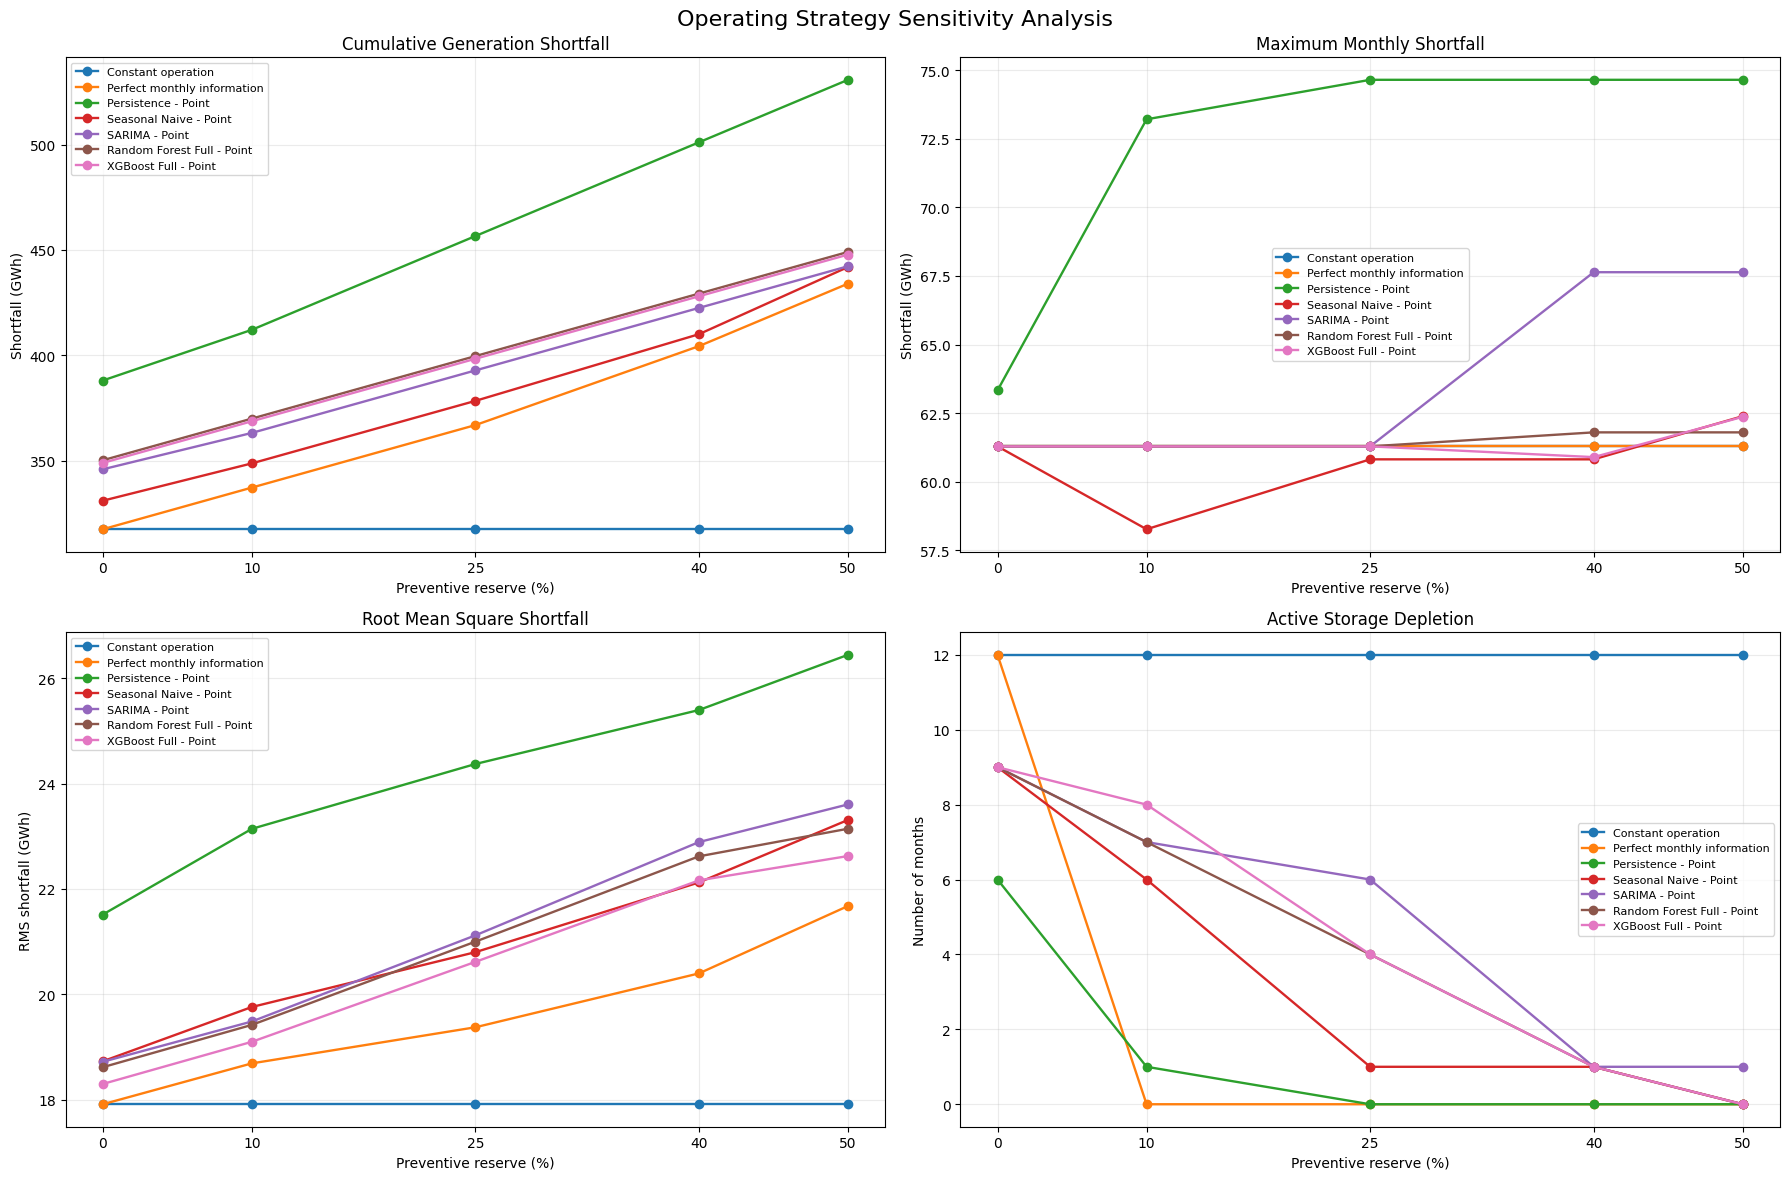

Sensitivity analysis: COMPLETED


In [82]:
# Visualize operating strategy sensitivity

SENSITIVITY_PLOT_STRATEGIES = [
    "Constant operation",
    "Perfect monthly information",
    "Persistence - Point",
    "Seasonal Naive - Point",
    "SARIMA - Point",
    "Random Forest Full - Point",
    "XGBoost Full - Point"
]

# Focus on medium initial storage
medium_sensitivity = sensitivity_summary.loc[
    (
        sensitivity_summary["Initial_storage_fraction"]
        == 0.50
    )
    & (
        sensitivity_summary["Strategy"].isin(
            SENSITIVITY_PLOT_STRATEGIES
        )
    )
].copy()

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 12)
)

plot_metrics = [
    (
        "Total_shortfall_GWh",
        "Cumulative Generation Shortfall",
        "Shortfall (GWh)"
    ),
    (
        "Maximum_shortfall_GWh",
        "Maximum Monthly Shortfall",
        "Shortfall (GWh)"
    ),
    (
        "RMS_shortfall_GWh",
        "Root Mean Square Shortfall",
        "RMS shortfall (GWh)"
    ),
    (
        "Empty_storage_months",
        "Active Storage Depletion",
        "Number of months"
    )
]

for ax, (metric, title, ylabel) in zip(
    axes.flat,
    plot_metrics
):

    for strategy in SENSITIVITY_PLOT_STRATEGIES:

        subset = medium_sensitivity.loc[
            medium_sensitivity["Strategy"]
            == strategy
        ].sort_values("Reserve_fraction")

        ax.plot(
            subset["Reserve_fraction"] * 100,
            subset[metric],
            marker="o",
            linewidth=1.7,
            label=strategy
        )

    ax.set_title(title)

    ax.set_xlabel("Preventive reserve (%)")

    ax.set_ylabel(ylabel)

    ax.set_xticks([0, 10, 25, 40, 50])

    ax.grid(alpha=0.25)

    ax.legend(fontsize=8)

fig.suptitle(
    "Operating Strategy Sensitivity Analysis",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "operation_sensitivity_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Sensitivity analysis: COMPLETED")

In [83]:
#  MULTI-OBJECTIVE PERFORMANCE EVALUATION

def identify_pareto_front(values, tolerance=1e-8):

    values = np.asarray(values, dtype=float)

    assert np.isfinite(values).all()

    number_of_solutions = len(values)

    pareto_mask = np.ones(
        number_of_solutions,
        dtype=bool
    )

    for i in range(number_of_solutions):

        # Identify solutions that are no worse
        no_worse = np.all(
            values <= values[i] + tolerance,
            axis=1
        )

        # Identify solutions that are strictly better
        strictly_better = np.any(
            values < values[i] - tolerance,
            axis=1
        )

        # Check Pareto dominance
        dominated = no_worse & strictly_better

        dominated[i] = False

        pareto_mask[i] = not dominated.any()

    return pareto_mask


# Verify the Pareto identification function
example_values = np.array([
    [2, 5],
    [3, 3],
    [5, 2],
    [4, 4],
    [6, 6]
])

np.testing.assert_array_equal(
    identify_pareto_front(example_values),
    [True, True, True, False, False]
)

print("Pareto function verification: PASSED")

# Define minimization objectives
PARETO_OBJECTIVES = [
    "Total_shortfall_GWh",
    "Maximum_shortfall_GWh",
    "RMS_shortfall_GWh",
    "Empty_storage_months",
    "Negative_final_storage"
]

multiobjective_results = sensitivity_summary.copy()

# Convert maximization into minimization
multiobjective_results["Negative_final_storage"] = (
    -multiobjective_results["Final_storage_hm3"]
)

multiobjective_results["Pareto_optimal"] = False

# Identify non-dominated solutions separately
# for each initial storage condition

for fraction in INITIAL_FRACTIONS:

    mask = (
        multiobjective_results[
            "Initial_storage_fraction"
        ] == fraction
    )

    objective_values = (
        multiobjective_results.loc[
            mask,
            PARETO_OBJECTIVES
        ].to_numpy()
    )

    multiobjective_results.loc[
        mask,
        "Pareto_optimal"
    ] = identify_pareto_front(
        objective_values
    )

# Extract non-dominated configurations
pareto_results = multiobjective_results.loc[
    multiobjective_results["Pareto_optimal"]
].copy()

# Remove repeated constant-operation configurations
pareto_results = pareto_results.sort_values(
    "Reserve_fraction"
).drop_duplicates(
    subset=[
        "Strategy",
        "Initial_storage_fraction",
        *PARETO_OBJECTIVES
    ]
)

print("\nMulti-objective evaluation completed.")

print(
    "Distinct non-dominated configurations:",
    len(pareto_results)
)

Pareto function verification: PASSED

Multi-objective evaluation completed.
Distinct non-dominated configurations: 41


In [84]:
# Summarize the main multi-objective findings

PARETO_DISPLAY_COLUMNS = [
    "Strategy",
    "Initial_storage_fraction",
    "Reserve_fraction",
    "Total_shortfall_GWh",
    "Maximum_shortfall_GWh",
    "RMS_shortfall_GWh",
    "Empty_storage_months",
    "Final_storage_hm3",
    "Total_shortfall_reduction_GWh",
    "Maximum_shortfall_reduction_GWh"
]

for fraction in INITIAL_FRACTIONS:

    subset = pareto_results.loc[
        pareto_results[
            "Initial_storage_fraction"
        ] == fraction
    ].sort_values("Total_shortfall_GWh")

    print(
        f"\nNon-dominated configurations - "
        f"Initial storage: {fraction:.0%}"
    )

    display(
        subset[PARETO_DISPLAY_COLUMNS].round(4)
    )

# Exclude constant operation from improvement counts
alternatives = multiobjective_results.loc[
    multiobjective_results["Strategy"]
    != "Constant operation"
].copy()

# Summarize improvements relative to baseline
improvement_summary = pd.DataFrame({
    "Criterion": [
        "Cumulative shortfall",
        "Maximum monthly shortfall",
        "RMS shortfall"
    ],

    "Improved_configurations": [
        (
            alternatives[
                "Total_shortfall_reduction_GWh"
            ] > 1e-8
        ).sum(),

        (
            alternatives[
                "Maximum_shortfall_reduction_GWh"
            ] > 1e-8
        ).sum(),

        (
            alternatives[
                "RMS_shortfall_reduction_GWh"
            ] > 1e-8
        ).sum()
    ]
})

improvement_summary["Total_configurations"] = (
    len(alternatives)
)

print("\nImprovement summary:")

display(improvement_summary)

# Save final evaluation results
multiobjective_results.to_csv(
    OUTPUT_DIR / "multiobjective_results.csv",
    index=False
)

pareto_results.to_csv(
    OUTPUT_DIR / "pareto_optimal_configurations.csv",
    index=False
)

improvement_summary.to_csv(
    OUTPUT_DIR / "final_improvement_summary.csv",
    index=False
)

print("\nMulti-objective results saved successfully.")


Non-dominated configurations - Initial storage: 25%


,Strategy,Initial_storage_fraction,Reserve_fraction,Total_shortfall_GWh,Maximum_shortfall_GWh,RMS_shortfall_GWh,Empty_storage_months,Final_storage_hm3,Total_shortfall_reduction_GWh,Maximum_shortfall_reduction_GWh
0,Constant operation,0.25,0.00,342.1878,61.2872,18.6813,13,174.5238,0.0000,0.0000
2,Perfect monthly information,0.25,0.00,342.1878,61.2872,18.6813,13,174.5238,0.0000,0.0000
10,Seasonal Naive - Point,0.25,0.00,355.7235,61.2872,19.2216,9,174.5238,-13.5358,0.0000
17,Perfect monthly information,0.25,0.10,361.9549,61.2872,19.2755,0,174.5238,-19.7671,0.0000
25,Seasonal Naive - Point,0.25,0.10,373.4381,58.2648,20.1857,6,174.5238,-31.2504,3.0224
13,XGBoost Full - Point,0.25,0.00,373.6509,61.2872,19.0509,10,174.5238,-31.4631,0.0000
40,Seasonal Naive - Point,0.25,0.25,403.0888,60.8141,21.6314,1,174.5238,-60.9011,0.4731
12,XGBoost Full - Conservative,0.25,0.00,444.3870,57.8087,22.4610,3,174.5238,-102.1992,3.4785
68,SARIMA - Conservative,0.25,0.50,556.0762,85.3941,28.5080,0,177.5609,-213.8885,-24.1069
48,Persistence - Conservative,0.25,0.40,776.3449,85.3941,30.9927,0,186.3621,-434.1572,-24.1069



Non-dominated configurations - Initial storage: 50%


,Strategy,Initial_storage_fraction,Reserve_fraction,Total_shortfall_GWh,Maximum_shortfall_GWh,RMS_shortfall_GWh,Empty_storage_months,Final_storage_hm3,Total_shortfall_reduction_GWh,Maximum_shortfall_reduction_GWh
75,Constant operation,0.5,0.00,317.4788,61.2872,17.9101,12,174.5238,0.0000,0.0000
77,Perfect monthly information,0.5,0.00,317.4788,61.2872,17.9101,12,174.5238,0.0000,0.0000
85,Seasonal Naive - Point,0.5,0.00,331.0146,61.2872,18.7261,9,174.5238,-13.5358,0.0000
92,Perfect monthly information,0.5,0.10,337.2460,61.2872,18.6863,0,174.5238,-19.7672,0.0000
100,Seasonal Naive - Point,0.5,0.10,348.7292,58.2648,19.7568,6,174.5238,-31.2504,3.0224
88,XGBoost Full - Point,0.5,0.00,348.9419,61.2872,18.2953,9,174.5238,-31.4631,0.0000
115,Seasonal Naive - Point,0.5,0.25,378.3799,60.8141,20.7978,1,174.5238,-60.9011,0.4731
87,XGBoost Full - Conservative,0.5,0.00,419.6780,57.8087,21.8518,3,174.5238,-102.1992,3.4785
143,SARIMA - Conservative,0.5,0.50,531.3673,69.1770,27.1850,0,177.5609,-213.8885,-7.8898
123,Persistence - Conservative,0.5,0.40,751.6360,75.5105,29.8669,0,186.3621,-434.1572,-14.2233



Non-dominated configurations - Initial storage: 75%


,Strategy,Initial_storage_fraction,Reserve_fraction,Total_shortfall_GWh,Maximum_shortfall_GWh,RMS_shortfall_GWh,Empty_storage_months,Final_storage_hm3,Total_shortfall_reduction_GWh,Maximum_shortfall_reduction_GWh
152,Perfect monthly information,0.75,0.00,299.8202,61.2872,17.7002,10,174.5238,0.0000,0.0000
150,Constant operation,0.75,0.00,299.8202,61.2872,17.7002,10,174.5238,0.0000,0.0000
167,Perfect monthly information,0.75,0.10,312.5370,61.2872,18.1693,0,174.5238,-12.7168,0.0000
175,Seasonal Naive - Point,0.75,0.10,324.0202,58.2648,19.2951,6,174.5238,-24.2001,3.0224
163,XGBoost Full - Point,0.75,0.00,324.2330,61.2872,17.9703,8,174.5238,-24.4128,0.0000
190,Seasonal Naive - Point,0.75,0.25,353.6710,60.8141,20.3522,1,174.5238,-53.8508,0.4731
162,XGBoost Full - Conservative,0.75,0.00,394.9691,57.8087,21.5364,3,174.5238,-95.1489,3.4785
218,SARIMA - Conservative,0.75,0.50,506.6584,68.8224,25.7103,0,177.5609,-206.8382,-7.5352
198,Persistence - Conservative,0.75,0.40,726.9271,64.0419,28.3784,0,186.3621,-427.1069,-2.7546
191,Storage only,0.75,0.25,766.8411,64.0419,26.6159,0,209.8638,-467.0209,-2.7546



Improvement summary:


,Criterion,Improved_configurations,Total_configurations
0,Cumulative shortfall,0,210
1,Maximum monthly shortfall,18,210
2,RMS shortfall,0,210



Multi-objective results saved successfully.


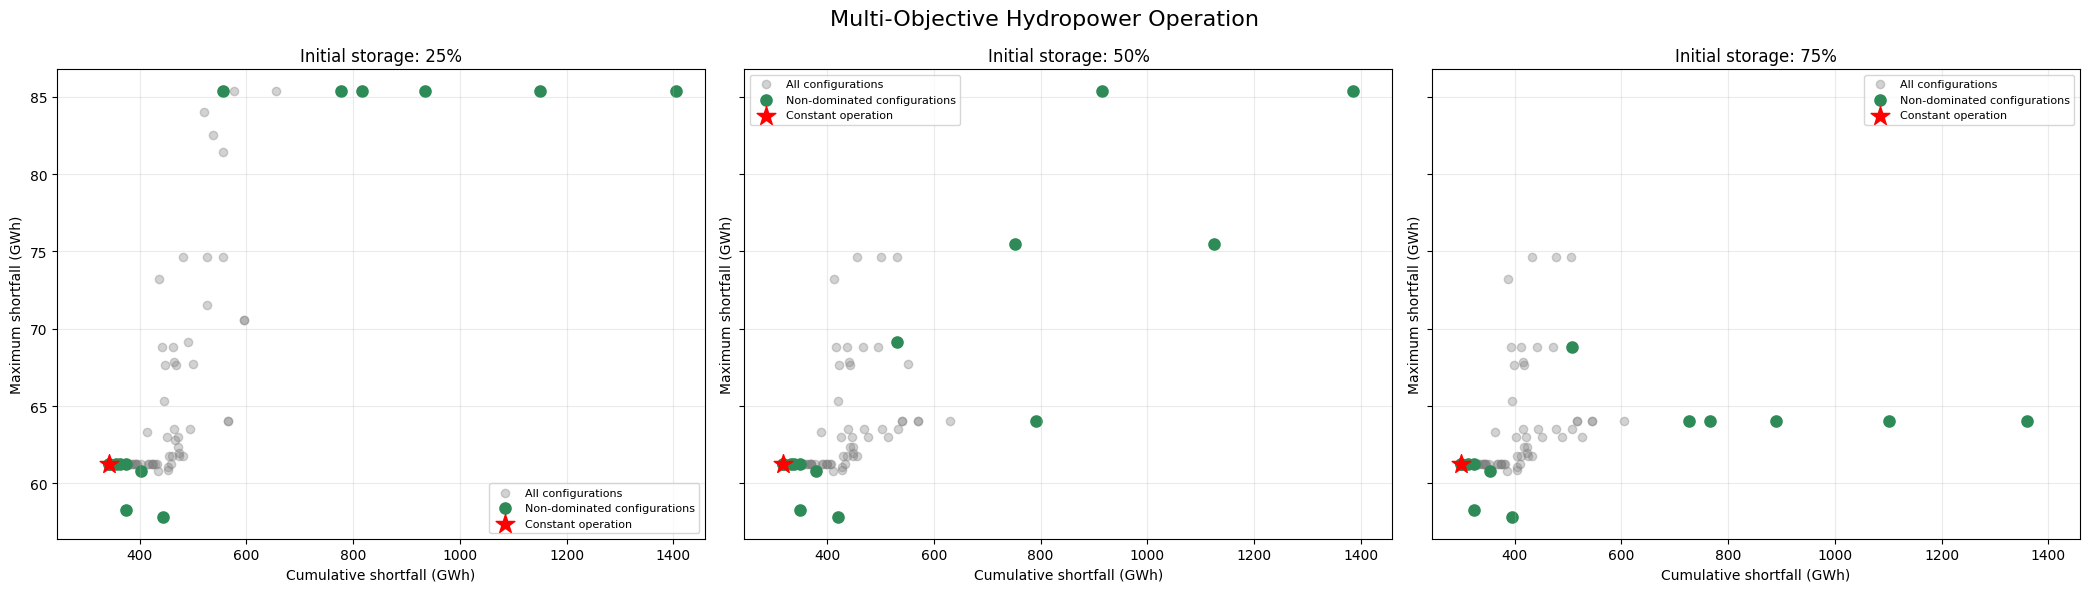

Multi-objective analysis: COMPLETED


In [85]:
# Visualize multi-objective operating performance

fig, axes = plt.subplots(
    1, 3,
    figsize=(21, 6),
    sharex=True,
    sharey=True
)

for ax, fraction in zip(
    axes,
    INITIAL_FRACTIONS
):

    subset = multiobjective_results.loc[
        multiobjective_results[
            "Initial_storage_fraction"
        ] == fraction
    ]

    pareto_subset = pareto_results.loc[
        pareto_results[
            "Initial_storage_fraction"
        ] == fraction
    ]

    baseline = subset.loc[
        subset["Strategy"] == "Constant operation"
    ].iloc[0]

    # Plot all experimental configurations
    ax.scatter(
        subset["Total_shortfall_GWh"],
        subset["Maximum_shortfall_GWh"],
        color="gray",
        alpha=0.35,
        label="All configurations"
    )

    # Highlight non-dominated solutions
    ax.scatter(
        pareto_subset["Total_shortfall_GWh"],
        pareto_subset["Maximum_shortfall_GWh"],
        color="seagreen",
        s=65,
        label="Non-dominated configurations"
    )

    # Highlight constant operation
    ax.scatter(
        baseline["Total_shortfall_GWh"],
        baseline["Maximum_shortfall_GWh"],
        color="red",
        marker="*",
        s=200,
        label="Constant operation"
    )

    ax.set_title(
        f"Initial storage: {fraction:.0%}"
    )

    ax.set_xlabel("Cumulative shortfall (GWh)")
    ax.set_ylabel("Maximum shortfall (GWh)")

    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle(
    "Multi-Objective Hydropower Operation",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "pareto_operation_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Multi-objective analysis: COMPLETED")